# AICSET 2026 · Paper 240 · Reproducible reviewer revision
## Physics-Protected Spectral Normalization for Reference-State Bridge Monitoring

**Abdellah Riyahi · Final version 5 · MARWAN HPC**

This notebook links the AICSET analysis, reviewer requests and publication outputs. It contains the signal-processing and fitting code, evaluates frozen models on separate physical groups, and exports figures, tables and fitted parameters. Explanatory text, captions and presentation labels use British English; the submitted paper title is retained unchanged.

**This is one complete notebook. Restarting the kernel and running all cells reads the raw OpenLab and Z24 datasets, extracts spectra, fits all applicable models, calibrates thresholds and generates the final exports. No earlier run directory, source archive, checkpoint or previously executed notebook is required.** Every execution creates a fresh output directory.

Raw datasets are read from `/data/a.riyahi/data/z24` and `/data/a.riyahi/data/openlab`. Results are written to `/home/a.riyahi/AICSET_240_revision`. Raw signals are not altered.

Three evidence sources remain distinct: the paper's archived reporting records; the completed MARWAN execution supplied for this revision; and results generated by a subsequent V4 execution. Presentation changes do not create new experiments. This explicit implementation does not recover the unavailable historical fitter.


### 1. Response to Reviewer 3

| Request | Implemented revision | Evidence needed for the manuscript |
|---|---|---|
| R1: real structural change | Z24 decisions before/after correction, lost-alert flags, and a separate analysis of scenarios 09–17 against reference 08. | Completed PDT analysis; synthetic translations are insufficient. |
| R2: evaluation and coverage comparison | Chronological physical-group partitions, Wilson intervals, exact paired McNemar tests and Holm adjustment. | Actual group counts and assumptions; additional windows are not independent groups. |
| R3: standard comparators | Conventional PCA, spectral peak-frequency ratios and measured-temperature regression under the same partitions. | Measured temperature for environmental cohorts; thermal cross-validation is not estimable from one PDT fitting scenario. |
| R4: reproducibility | Full extraction/fitting source, validated metadata, source hashes, fitted matrices, reload methods and a reproduction script. | Fitted parameters and outcomes only exist for cohorts actually processed. |
| R5: clarity and presentation | Revised explanations, concise British-English captions, readable figures and numbered presentation tables. | Separate final review of the Word manuscript and its page layout. |
| R6: relation to learning | Explicit distinction between estimated dictionaries/PCA/regression and fixed physical constraints. | No neural-network or prospective-detection claim is added. |

Reference-state AVT–FVT mismatch is exported alongside altered-state sensitivity, retaining the paper's central normalisation question. Missing methods, incomplete metadata and unsupported thresholds remain visible in the reviewer checklist.


### 2. What the supplied MARWAN run establishes

The supplied V4 execution processed **526 OpenLab acquisitions** and **306 Z24 PDT acquisitions across all 17 scenarios**. OpenLab reference coverage was 10/10 before and after correction, with 5.073% median paired score contraction. On progressive-damage scenarios 09–17, the descriptive scenario-02 calibration-maximum rule alerted 6/9 states before correction and 8/9 after protected NNLS; both rules also alerted the sole held-out reference 08. The corresponding AUCs were 0.222 and 0.444. These observations do not establish superior or reliable damage discrimination. This section records the supplied execution; the cells below recompute the complete experiment from raw inputs.

The selected fitting spectral peaks were 4.638671875 Hz for OpenLab and 3.90625 Hz for PDT; their physical modal identities remain unverified. EMS raw data were not found. The measured-temperature comparator was missing and is now joined automatically from the documented OpenLab environmental CSVs. Reference-state AVT–FVT mismatch reductions were 34.968% and 37.217% on PDT scenarios 02 and 08. Earlier archived paper values remain separate.

The complete pipeline retains verified PDT input recognition by reading `labelshulp`, checking the common reference-channel identities across all nine source-scenario setups, and resolving each MATLAB file's own column positions. No fixed indices are assumed. Individual `.aaa` files are not merged or counted again when the MATLAB acquisition is used. Environmental headers are included in the diagnostics to support an explicit temperature mapping.


### 3. Running the notebook

1. Select the scientific Python kernel in MARWAN Jupyter. Review the configuration, then use **Restart Kernel and Run All Cells**.
2. If `acquisitions.csv` exists, its confirmed metadata are used. Otherwise, only acquisitions satisfying the strict OpenLab or PDT recognisers enter the automatic manifest.
3. Inspect `z24_pdt_schema_audit.json`, missing-method records and the reference-frequency audit. Rejected or ambiguous layouts remain diagnostics.
4. The documented OpenLab air-temperature CSVs are joined automatically. An explicit `cov_temperature` supplied in the manifest or `measured_covariates.csv` takes precedence. Climate observations are never invented; unmatched values and fitting-only imputation are reported.
5. Return `results_to_share.zip`, including the publication figures, tables, captions and scientific provenance. If metadata remain incomplete, return `diagnostics.zip` first.

All analyses are retrospective. Completing calculations does not validate a physical mode or establish future monitoring performance. Freeze choices before inspecting new evaluation outcomes.


In [1]:
# CONFIGURATION — read datasets under /data; write results under /home.
from pathlib import Path

WORK_ROOT = Path('/home/a.riyahi/AICSET_240_revision')
CONFIG = {
    'implementation': 'NEW_AICSET240_REVISION_V5_FULL',
    'data_roots': {
        'z24': Path('/data/a.riyahi/data/z24'),
        'openlab': Path('/data/a.riyahi/data/openlab'),
    },
    'work_root': WORK_ROOT,
    'manifest_file': WORK_ROOT / 'acquisitions.csv',
    # Optional measured metadata: dataset + acquisition_id (or timestamp_utc) + cov_*.
    'covariates_file': WORK_ROOT / 'measured_covariates.csv',
    'covariate_join_tolerance_seconds': 300,
    'run_new_analysis': True,
    'alpha': 0.05,
    'rank': 3,
    'bins_per_curve': 128,
    'nperseg': 4096,
    'overlap': 0.5,
    'frequency_upper': {'openlab_2024': 2.5, 'z24_pdt': 2.5, 'z24_ems': 3.5},
    # None selects a training-only spectral heuristic. Review its audit figure.
    # Replace only with a physically verified frequency from fitting data.
    'f1_overrides_hz': {'openlab_2024': None, 'z24_pdt': None, 'z24_ems': None},
    # Confirm only after inspecting fitting data and recording physical provenance.
    'f1_review_confirmed': {'openlab_2024': False, 'z24_pdt': False, 'z24_ems': False},
    'f1_review_notes': {'openlab_2024': '', 'z24_pdt': '', 'z24_ems': ''},
    'f1_peak_band_hz': [0.5, 20.0],
    'design_shifts': [-0.02, -0.01, -0.005, 0.005, 0.01, 0.02],
    'additional_test_shifts': [-0.025, -0.015, -0.0075, 0.0075, 0.015, 0.025],
    'ridge_alphas': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'splits': {
        'openlab_2024': {'fit': 10, 'calibration': 24, 'minimum_test': 3},
        'z24_ems': {'fit': 7, 'calibration': 19, 'minimum_test': 3},
    },
    'bootstrap_replicates': 10000,
    'seed': 20261113,
    'auto_openlab_temperature': True,
    'temperature_join_tolerance_seconds': 300,
    'require_complete_temperature_matches': False,
    'show_publication_preview': True,
    'publication_style': {'figure_width_mm': 122, 'raster_dpi': 300, 'font_size_pt': 9, 'font_family': 'Times New Roman'},
}

# Freeze these choices before inspecting the new test outcomes.
# Reduce threads only if your Jupyter allocation requires it; no Slurm submission here.
import os, importlib.util
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
required = ['numpy', 'scipy', 'pandas', 'sklearn', 'matplotlib']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError('Missing packages in the selected kernel: ' + ', '.join(missing)
                      + '. Select the scientific MARWAN environment before rerunning.')
print('Configuration loaded. h5py available:', importlib.util.find_spec('h5py') is not None)


Configuration loaded. h5py available: True


### 4. Frozen study design

| Cohort | Fitting | Calibration | Evaluation |
|---|---|---|---|
| OpenLab-2024 | First 10 reference dates | Next 24 reference dates | All remaining dates; at least 3 |
| Z24 EMS, if confirmed data exist | First 7 reference ISO weeks | Next 19 reference ISO weeks | All remaining weeks; at least 3 |
| Z24 PDT | Scenario 01, paired AVT/FVT within setup | Scenario 02 | Reference 08 and available altered scenarios 03–07, 09–17 |

An acquisition and its physical date, week or scenario cannot cross partitions. EMS uses chronological weeks rather than the earlier interleaved design. PDT scenarios 03–07 are pier interventions; scenarios 09–17 form the progressive-damage phase. Their mechanisms and cumulative histories are heterogeneous, rather than independent replications of one damage type.

PDT uses the same five physical reference channels across setups, including different directions; these are not five vertical channels. Matrix positions alone do not establish sensor identity. Setup/excitation counts and imbalance flags are exported without outcome-dependent balancing. Unequal acquisition counts can affect group maxima.

The nuisance rank is fixed at three. Means, frequency choices, protected directions, dictionaries, PCA components, ratio bands and regression preprocessing use fitting data only. Calibration chooses thresholds; evaluation data do not select models.


### 5. Representation and protected correction

For each synchronous acquisition, Welch cross-power spectral densities form a Hermitian matrix. Its two largest singular-value curves are interpolated on a fixed frequency grid using a fitting-selected reference frequency. Each log curve is median-centred and normalised to unit Euclidean norm. Concatenating 128 samples per curve gives $x\in\mathbb{R}^{256}$.

Let $\mu$ denote the fitting reference, $U$ an orthonormal basis of prescribed frequency-shift responses, and $B$ a rank-three nuisance dictionary satisfying $U^\top B=0$. Then

$$\widehat\gamma(x)=\underset{\gamma\geq0}{\operatorname{argmin}}\,\|(x-\mu)-B\gamma\|_2^2,
\qquad \widetilde x=x-B\widehat\gamma(x),\qquad s(x)=\|\widetilde x-\mu\|_2.$$

The code checks protected-coordinate preservation, nonnegative coefficients and $s(x)\leq\|x-\mu\|_2$. Thus score contraction is built into the correction and is not, by itself, evidence of improved monitoring. The dictionary orientation defining the nonnegative cone is saved.

Fitting-reference finite secants define the protected basis. Coordinate preservation does not guarantee perfect retention of every finite translation on unseen shapes. Design and additional shift magnitudes are therefore reported separately. Synthetic endpoint extension is explicit and does not simulate damage in raw signals.

The automatic frequency routine detects a spectral peak. Calling it the first vertical mode requires physical inspection and a recorded fitting-only provenance note. Neither that inspection nor confirmation changes evaluation data.


### 6. Comparators and statistical interpretation

Conventional PCA uses all fitting acquisitions, with equal total weight per physical group. It differs from the signed nuisance-projection ablation. The ratio comparator tracks two distinct peaks of the first singular-value curve in fitting-selected bands, using local quadratic interpolation where admissible. Band-edge maxima remain flagged. These spectral peaks are not independently identified modal frequencies; ratio distances are not compared continuously with spectral distances.

Temperature regressions use measured covariates, fitting-only preprocessing and grouped cross-validation. The PDT fitting design has one group and cannot support this cross-validation. Evaluation scenarios are not moved into fitting to make the regression possible.

OpenLab ambient temperature is read from `G_HTST_ENVR_EN0000_0` in the nine February–October 2024 environmental files. The data article, DOI 10.1016/j.dib.2025.111624, identifies its unit as °C; the provider, DOI 10.25532/OPARA-660, documents UTC despite unzoned CSV strings. A retrospective nearest-observation join is limited to 300 s; ties use the earlier measurement. Missing matches remain explicit, no acquisition is dropped, and imputation is fitted within training folds. June/July clock uncertainty limits exact temporal alignment. Fixed-covariate synthetic response retention for regression is algebraic, rather than damage-validation evidence.

The data article documents a non-destructive temporary prop from 22 July to 2 August 2024. The supplied OpenLab calibration includes 27 acquisitions on five dates in this period. These rows retain their original labels and chronological partitions; an undamaged reference phase does not imply unchanged boundary conditions. None of the supplied run's method thresholds is attained on these dates, so no claim that the intervention increased those thresholds is made.

A group's score is the maximum of its acquisition scores. Conformal calibration uses `ceil((m+1)*(1-alpha))` with decimal-stable arithmetic. If this rank exceeds the calibration-group count, the nominal threshold is infinite and decisions abstain. A finite order statistic still requires suitable exchangeability assumptions; chronology alone does not establish them.

PDT's single calibration scenario cannot support a finite nominal 95% threshold. A separate maximum-calibration rule supplies descriptive detection counts without a nominal guarantee. Reference false alerts, altered-state alerts, lost alerts and AUC availability remain explicit. The progressive-damage subset retains the same frozen models and thresholds.

Coverage comparisons use paired decisions, exact McNemar tests and Holm adjustment within each cohort. Wilson and paired-bootstrap intervals remain descriptive under small samples and unresolved temporal dependence. Bootstrap intervals condition on fitted models and thresholds; fitting uncertainty is excluded. Repeated synthetic shifts are not independent bridge observations.


### Input validation and metadata recognition

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [2]:
"""Read-only, manifest-driven I/O for the new AICSET 240 analysis.

One row is ONE simultaneous multichannel acquisition. A source file can occur in
several rows only with distinct record_id and explicit selectors. No file name is
treated as proof of health, damage, sampling rate, or a training/evaluation role.
The verified OpenLab convention plus exact CSV header, and the official Z24 PDT
scenario convention plus inspected MATLAB physical labels, are narrow exceptions.
CSV columns and MAT/NPZ/HDF5 variables must be selected explicitly when ambiguous.
Optional channel_names declares physical sensor labels in selection order; it is
mandatory for Z24 PDT matrix/position selectors because array indexes alone do not
identify a sensor location. Vector channel_keys and exact CSV names are explicit.
"""
from __future__ import annotations

import csv
import hashlib
import importlib.util
import json
import math
import re
import warnings
import zipfile
from pathlib import Path
from typing import Any, Mapping

import numpy as np
import pandas as pd


MANIFEST_COLUMNS = [
    "dataset", "record_id", "acquisition_id", "group_id", "timestamp_utc",
    "state_label", "scenario", "excitation", "setup_id", "path", "format",
    "fs_hz", "data_key", "channel_keys", "channel_columns", "channel_names", "sample_axis",
    "delimiter", "decimal", "skiprows", "header", "time_column",
]
SUPPORTED_INPUT_SUFFIXES = {".csv", ".txt", ".asc", ".dat", ".mat", ".npz", ".h5", ".hdf5"}
ALLOWED_DATASETS = {"openlab_2024", "z24_ems", "z24_pdt"}
OPENLAB_2024_VERTICAL_CHANNELS = [
    "G_ACCZ_PE11_CB0750_0", "G_ACCZ_PE12_CB0750_0", "G_ACCZ_PE13_CB0750_0",
    "G_ACCZ_PE22_CB0750_0", "G_ACCZ_PE23_CB0750_0",
]
Z24_PDT_REFERENCE_CHANNELS = ["R1V", "R2L", "R2T", "R2V", "R3V"]
Z24_PDT_PROTOCOL_SOURCE = "https://bwk.kuleuven.be/bwm/z24"
Z24_PDT_LABEL_SCHEMA_SOURCE = "https://github.com/AbdellahRiyahi/MultiBridge_FaultAware_Selective_SHM/blob/main/MultiBridge_FaultAware_Selective_SHM_V1_2.ipynb"


class ManifestValidationError(ValueError):
    """An invalid manifest; ``errors`` is an exportable pandas DataFrame."""

    def __init__(self, errors: pd.DataFrame):
        self.errors = errors
        examples = "; ".join(str(v) for v in errors["message"].head(6))
        super().__init__(f"Manifest validation failed ({len(errors)} issues): {examples}")


def _rio_empty(value: Any) -> bool:
    if value is None:
        return True
    if isinstance(value, str):
        return value.strip() == ""
    try:
        result = pd.isna(value)
        return bool(result) if np.ndim(result) == 0 else False
    except (TypeError, ValueError):
        return False


def _rio_text(value: Any) -> str:
    return "" if _rio_empty(value) else str(value).strip()


def _rio_list(value: Any, field: str) -> list:
    if _rio_empty(value):
        return []
    if isinstance(value, (list, tuple, np.ndarray)):
        parsed = list(value)
    else:
        try:
            parsed = json.loads(str(value))
        except (ValueError, TypeError) as exc:
            raise ValueError(f"{field} must be a JSON list, e.g. [0, 1] or [\"R1V\", \"R2V\"]") from exc
    if not isinstance(parsed, list):
        raise ValueError(f"{field} must be a JSON list")
    if field in {"channel_keys", "channel_names"}:
        if not all(isinstance(v, str) and v.strip() for v in parsed):
            raise ValueError(f"{field} must contain nonempty strings")
        if any(v != v.strip() for v in parsed):
            raise ValueError(f"{field} entries must not contain surrounding whitespace")
    elif field == "channel_columns" and parsed:
        if all(isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)) for v in parsed):
            parsed = [int(v) for v in parsed]
            if min(parsed) < 0:
                raise ValueError("channel_columns indexes cannot be negative")
        elif not all(isinstance(v, str) and v.strip() for v in parsed):
            raise ValueError("channel_columns must contain all nonnegative integer indexes or all exact nonempty string names")
    if len({str(v) for v in parsed}) != len(parsed):
        raise ValueError(f"{field} contains duplicate selectors")
    return parsed


def _rio_int(value: Any, field: str, default=None):
    if _rio_empty(value):
        if default is not None:
            return default
        raise ValueError(f"{field} must be stated explicitly")
    if isinstance(value, (bool, np.bool_)):
        raise ValueError(f"{field} must be an integer, not a Boolean")
    number = float(value)
    if not math.isfinite(number) or number != int(number):
        raise ValueError(f"{field} must be an integer")
    return int(number)


def _rio_sampling_rate(value: Any) -> float:
    if isinstance(value, (bool, np.bool_)):
        raise ValueError("fs_hz must be a sampling rate, not a Boolean")
    number = float(value)
    if not math.isfinite(number) or number <= 0:
        raise ValueError("fs_hz must be a finite positive measured/documented sampling rate")
    return number


def _rio_timestamp(value: Any) -> pd.Timestamp:
    """Require an explicitly zoned ISO timestamp; never assume a local time is UTC."""
    if isinstance(value, (pd.Timestamp,)) or hasattr(value, "tzinfo"):
        stamp = pd.Timestamp(value)
    else:
        text = _rio_text(value)
        if not isinstance(value, str) or not re.fullmatch(
                r"\d{4}-\d{2}-\d{2}[T ]\d{2}:\d{2}(?::\d{2}(?:\.\d+)?)?(?:Z|[+-]\d{2}:?\d{2})", text):
            raise ValueError("timestamp_utc requires an ISO date/time with explicit Z or UTC offset; numeric epochs and timezone-naive dates are ambiguous")
        stamp = pd.Timestamp(text)
    if pd.isna(stamp) or stamp.tzinfo is None:
        raise ValueError("timestamp_utc must include an explicit timezone; confirm the source time convention before adding Z")
    return stamp.tz_convert("UTC")


def _rio_header(value: Any):
    text = _rio_text(value).lower()
    if text in {"none", "null", "-1"}:
        return None
    if text == "":
        raise ValueError("header must be an explicit nonnegative row number or 'none'")
    number = _rio_int(value, "header")
    if number < 0:
        raise ValueError("header cannot be negative (use 'none' for no header)")
    return number


def _rio_root_for(dataset: str, roots: Mapping[str, Path]) -> Path:
    key = dataset if dataset in roots else ("z24" if dataset.startswith("z24_") else "openlab")
    if key not in roots:
        raise ValueError(f"No explicit input root configured for {dataset!r}")
    root = Path(roots[key]).expanduser()
    if not root.is_absolute():
        raise ValueError(f"Input root must be absolute: {root}")
    root = root.resolve(strict=True)
    if root == Path("/home") or Path("/home") in root.parents:
        raise ValueError(f"/home input roots are disabled; configure the actual /data location: {root}")
    if not root.is_dir():
        raise ValueError(f"Input root is not a directory: {root}")
    return root


def _rio_within(path: Path, root: Path) -> bool:
    try:
        path.relative_to(root)
        return True
    except ValueError:
        return False


def _rio_safe_output(out_dir: Path, roots: Mapping[str, Path]) -> Path:
    output = Path(out_dir).expanduser().resolve()
    for value in roots.values():
        root = Path(value).expanduser().resolve()
        if _rio_within(output, root):
            raise ValueError(f"Write output outside the read-only input tree: {output}")
    output.mkdir(parents=True, exist_ok=True)
    return output


def _rio_csv_sample(path: Path, skiprows: int = 0):
    with Path(path).open("r", encoding="utf-8-sig", errors="replace", newline="") as stream:
        for _ in range(skiprows):
            next(stream, None)
        return stream.read(16384)


def _rio_delimiter(value: Any, path: Path, skiprows: int = 0) -> str:
    text = _rio_text(value)
    if text.lower() in {"tab", "\\t"}:
        return "\t"
    if text.lower() in {"whitespace", "space", r"\s+"}:
        return r"\s+"
    if text and text.lower() != "auto":
        if len(text) != 1:
            raise ValueError("delimiter must be one character, tab, whitespace, or auto")
        return text
    sample = _rio_csv_sample(path, skiprows)
    try:
        return csv.Sniffer().sniff(sample, delimiters=",;\t|").delimiter
    except csv.Error:
        rows = [line.strip() for line in sample.splitlines() if line.strip()][:12]
        widths = [len(re.split(r"\s+", line)) for line in rows]
        if widths and min(widths) >= 2 and len(set(widths)) == 1:
            return r"\s+"
        raise ValueError(f"Cannot infer a reliable delimiter for {path.name}; state it in the manifest")


def _rio_decimal(value: Any) -> str:
    """Honor an explicit CSV decimal mark; never infer a numeric locale."""
    mark = _rio_text(value) or "."
    if mark not in {".", ","}:
        raise ValueError("decimal must be an explicit '.' or ',' (default '.')")
    return mark


def _rio_csv_header(path: Path, delimiter: str, skiprows: int, header) -> list | None:
    """Read the physical header before pandas can rename duplicate column names."""
    if header is None:
        return None
    with path.open("r", encoding="utf-8-sig", errors="strict", newline="") as stream:
        for _ in range(skiprows):
            next(stream, None)
        records = (re.split(r"\s+", line.strip()) for line in stream if line.strip()) if delimiter == r"\s+" else csv.reader(stream, delimiter=delimiter)
        nonblank_index = -1
        for cells in records:
            if not cells or (len(cells) == 1 and not cells[0].strip()):
                continue
            nonblank_index += 1
            if nonblank_index == header:
                return cells
    raise ValueError("CSV header row is beyond the available nonblank records")


def _rio_file_identity(path: Path) -> tuple:
    stat = path.stat()
    return (stat.st_dev, stat.st_ino, stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns)


def probe_input(path: Path) -> dict:
    """Inspect headers/container metadata, never infer scientific labels or fs.

    CSV probing reads at most 16 KiB. MAT uses whosmat; v7.3 needs optional h5py.
    NPZ never permits pickle. Probes are diagnostic suggestions, not selectors.
    """
    path = Path(path).resolve(strict=True)
    info: dict[str, Any] = {"path": str(path), "suffix": path.suffix.lower(), "size_bytes": path.stat().st_size}
    suffix = path.suffix.lower()
    try:
        if suffix in {".csv", ".txt", ".asc", ".dat"}:
            sample = _rio_csv_sample(path)
            nonempty = [line for line in sample.splitlines() if line.strip()]
            info["first_nonempty_lines"] = nonempty[:6]
            try:
                delimiter = _rio_delimiter("auto", path)
                info["candidate_delimiter"] = "whitespace" if delimiter == r"\s+" else delimiter
                if delimiter != r"\s+" and nonempty:
                    cells = next(csv.reader([nonempty[0]], delimiter=delimiter))
                else:
                    cells = re.split(r"\s+", nonempty[0].strip()) if nonempty else []
                info["first_row_cells"] = cells
                info["first_row_has_nonnumeric_tokens"] = any(not _rio_is_float(v) for v in cells)
            except ValueError as exc:
                info["delimiter_error"] = str(exc)
            # Headers can contain engineering units; report, but do not interpret them as fs.
            info["sampling_rate_inferred"] = False
            info["decimal_mark_inferred"] = False
        elif suffix == ".mat":
            from scipy.io import whosmat
            try:
                info["variables"] = [{"key": k, "shape": list(shape), "matlab_class": typ} for k, shape, typ in whosmat(path)]
                if {v["key"] for v in info["variables"]}.issuperset({"data", "labelshulp"}):
                    # Selective label loading enriches the schema without
                    # materialising the vibration matrix or estimating features.
                    info["z24_pdt_label_schema"] = _rio_pdt_mat_schema(path)
            except (NotImplementedError, ValueError, OSError) as exc:
                if not importlib.util.find_spec("h5py"):
                    raise ValueError("MAT metadata unavailable (possibly MATLAB v7.3); install h5py or use an explicit compatible export") from exc
                info["hdf5_datasets"] = _rio_h5_metadata(path)
        elif suffix == ".npz":
            with np.load(path, allow_pickle=False) as archive:
                info["variables"] = []
                for key in archive.files:
                    try:
                        array = archive[key]
                        info["variables"].append({"key": key, "shape": list(array.shape), "dtype": str(array.dtype)})
                    except ValueError as exc:
                        info["variables"].append({"key": key, "error": str(exc), "usable": False})
        elif suffix in {".h5", ".hdf5"}:
            if not importlib.util.find_spec("h5py"):
                raise ValueError("HDF5 input requires optional h5py")
            info["hdf5_datasets"] = _rio_h5_metadata(path)
        elif suffix == ".zip":
            with zipfile.ZipFile(path, "r") as archive:
                members = [{"path": item.filename, "size_bytes": item.file_size,
                            "compressed_bytes": item.compress_size, "directory": item.is_dir()}
                           for item in archive.infolist()]
            info["archive_members"] = members
            info["archive_extracted"] = False
            info["scientific_role_inferred"] = False
        elif suffix == ".aaa":
            info["first_nonempty_lines"] = [line for line in _rio_csv_sample(path).splitlines() if line.strip()][:12]
            info["supported_signal_container"] = False
            info["note"] = "Individual-channel source: diagnostic text only; not automatically merged or substituted for multichannel MAT acquisitions."
        else:
            info["supported_signal_container"] = False
    except Exception as exc:
        info["probe_error"] = f"{type(exc).__name__}: {exc}"
    return info


def _rio_is_float(value: str) -> bool:
    try:
        float(value)
        return True
    except (ValueError, TypeError):
        return False


def _rio_h5_metadata(path: Path) -> list[dict]:
    import h5py
    result = []
    with h5py.File(path, "r") as handle:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset):
                result.append({"key": name, "shape": list(obj.shape), "dtype": str(obj.dtype)})
        handle.visititems(visit)
    return result


def _rio_mat_labels(value: Any) -> list[str]:
    """Decode explicit MATLAB string labels; never convert numeric indices to names."""
    array = np.asarray(value)
    if array.dtype.kind == "O":
        if array.ndim > 2 or (array.ndim == 2 and min(array.shape) > 1):
            raise ValueError(f"Ambiguous labelshulp cell layout {array.shape}; an ordered label vector is required")
        result = []
        for part in array.ravel():
            result.extend(_rio_mat_labels(part))
        return result
    if array.dtype.kind not in "US":
        raise ValueError("labelshulp must contain strings/characters, not numeric channel indices")
    char_width = array.dtype.itemsize // (4 if array.dtype.kind == "U" else 1)
    if array.ndim == 2 and char_width == 1:
        strings = ["".join(v.decode("utf-8") if isinstance(v, bytes) else str(v) for v in row) for row in array]
    elif array.ndim <= 1 or (array.ndim == 2 and 1 in array.shape):
        strings = [v.decode("utf-8") if isinstance(v, bytes) else str(v) for v in array.ravel()]
    else:
        raise ValueError(f"Ambiguous labelshulp character layout {array.shape}; inspect the exported labels")
    return [value.strip(" \t\r\n\x00") for value in strings]


def _rio_pdt_mat_schema(path: Path) -> dict:
    """Inspect data dimensions and load ONLY channel/rate metadata from a classic MAT file."""
    from scipy.io import loadmat, whosmat
    path = Path(path)
    identity = _rio_file_identity(path)
    variables = {key: (shape, kind) for key, shape, kind in whosmat(path)}
    if not {"data", "labelshulp"}.issubset(variables):
        raise ValueError("Verified PDT schema requires both data and labelshulp")
    shape, kind = variables["data"]
    if len(shape) != 2 or shape[0] < 8 or shape[1] < 5 or kind not in {"double", "single", "int16", "int32", "int64", "uint16", "uint32", "uint64", "int8", "uint8"}:
        raise ValueError(f"PDT data must be a real samples-by-channels numeric matrix; metadata says {shape}, {kind}")
    values = loadmat(path, variable_names=["labelshulp", "fs", "Fs", "sample_rate", "sampling_rate"], simplify_cells=True)
    labels = _rio_mat_labels(values["labelshulp"])
    if len(labels) != shape[1]:
        raise ValueError(f"labelshulp has {len(labels)} labels but data has {shape[1]} columns; no orientation or positions are guessed")
    rates = {}
    for key in ["fs", "Fs", "sample_rate", "sampling_rate"]:
        if key not in values:
            continue
        value = np.asarray(values[key]).squeeze()
        if value.ndim != 0:
            raise ValueError(f"PDT sampling-rate metadata {key!r} is not a scalar")
        rate = _rio_sampling_rate(value.item())
        if not math.isclose(rate, 100.0, rel_tol=0, abs_tol=1e-9):
            raise ValueError(f"PDT file rate {key}={rate} contradicts the documented 100 Hz protocol")
        rates[key] = rate
    if _rio_file_identity(path) != identity:
        raise ValueError("PDT file changed during label/rate metadata inspection")
    return {"data_key": "data", "data_shape": list(shape), "data_class": kind,
            "label_key": "labelshulp", "channel_labels": labels, "sample_axis": 0,
            "embedded_rates_hz": rates, "signal_matrix_loaded": False}


def _rio_pdt_path_metadata(relative: str) -> dict:
    """Recognise the actual SS/AVT-or-FVT/SSsetupNN.mat PDT source convention."""
    match = re.fullmatch(r"(0[1-9]|1[0-7])/(avt|fvt)/\1setup(0[1-9])\.mat", relative.replace("\\", "/"), flags=re.I)
    if not match:
        return {}
    scenario, excitation, setup = match.groups()
    return {"scenario": scenario, "excitation": excitation.upper(), "setup_id": setup}


def _rio_pdt_manifest_metadata(inventory: pd.DataFrame) -> tuple[dict, dict]:
    """Verify a common physical reference layout before creating any PDT auto row.

    The nine source-01 AVT setups determine the common R-channel intersection.
    It must agree with the five explicitly documented reference component names.
    Every other acquisition then independently proves its selected column mapping
    from labelshulp. No signal matrix, synthetic label or fixed index is used.
    """
    audit = {"status": "NO_MATCHING_PDT_MAT_PATHS", "protocol_source": Z24_PDT_PROTOCOL_SOURCE,
             "label_schema_source": Z24_PDT_LABEL_SCHEMA_SOURCE,
             "documented_fs_hz": 100.0, "reference_components": Z24_PDT_REFERENCE_CHANNELS,
             "reference_components_are_not_all_vertical": True,
             "signal_matrices_loaded": False, "records": [], "errors": []}
    candidates = []
    for item in inventory.to_dict("records"):
        if str(item.get("root_label", "")).lower() not in {"z24", "z24_pdt"}:
            continue
        known = _rio_pdt_path_metadata(str(item.get("relative_path", "")))
        if not known:
            continue
        path = str(item["path"])
        record = {"path": path, **known, "status": "UNVERIFIED"}
        try:
            root = _rio_root_for("z24_pdt", {"z24": Path(str(item.get("input_root", "")))})
            if not _rio_within(Path(path).resolve(strict=True), root):
                raise ValueError("PDT metadata path resolves outside its explicit inventory input root")
            record.update(_rio_pdt_mat_schema(Path(path)))
            record["status"] = "LABEL_SCHEMA_INSPECTED"
        except Exception as exc:
            record["error"] = f"{type(exc).__name__}: {exc}"
            audit["errors"].append({"path": path, "message": record["error"]})
        candidates.append(record)
    audit["records"] = candidates
    if not candidates:
        return {}, audit
    source = [r for r in candidates if r["scenario"] == "01" and r["excitation"] == "AVT"]
    setups = [r["setup_id"] for r in source]
    required_setups = {f"{n:02d}" for n in range(1, 10)}
    if set(setups) != required_setups or len(setups) != 9 or any(r["status"] != "LABEL_SCHEMA_INSPECTED" for r in source):
        audit["status"] = "BLOCKED_SOURCE01_NINE_AVT_LABEL_SCHEMAS_REQUIRED"
        audit["errors"].append({"path": "source01/AVT", "message": "All nine distinct source-01 AVT setup label schemas are required before verifying a common reference-channel intersection"})
        return {}, audit
    common = set.intersection(*(set(r["channel_labels"]) for r in source))
    reference_common = sorted(label for label in common if re.fullmatch(r"R\d+[VLT]", label))
    audit["source01_avt_common_labels"] = sorted(common)
    audit["source01_avt_common_reference_labels"] = reference_common
    if set(reference_common) != set(Z24_PDT_REFERENCE_CHANNELS):
        audit["status"] = "BLOCKED_REFERENCE_CHANNEL_INTERSECTION_AMBIGUOUS"
        audit["errors"].append({"path": "source01/AVT", "message": "The source-01 AVT physical R-channel intersection does not equal the five documented reference components; inspect labelshulp diagnostics rather than choosing five positions"})
        return {}, audit
    verified = {}
    for record in candidates:
        if record["status"] != "LABEL_SCHEMA_INSPECTED":
            continue
        labels = record["channel_labels"]
        if any(labels.count(name) != 1 for name in Z24_PDT_REFERENCE_CHANNELS):
            record["status"] = "BLOCKED_REFERENCE_LABEL_MISSING_OR_DUPLICATED"
            audit["errors"].append({"path": record["path"], "message": "Every common physical reference component must occur exactly once in labelshulp"})
            continue
        columns = [labels.index(name) for name in Z24_PDT_REFERENCE_CHANNELS]
        record["selected_column_indices"] = columns
        record["status"] = "VERIFIED_PDT_PATH_LABEL_SCHEMA_AND_COMMON_REFERENCE_COMPONENTS"
        scenario = record["scenario"]
        verified[record["path"]] = {
            "dataset": "z24_pdt", "group_id": "scenario_" + scenario,
            "scenario": scenario, "setup_id": record["setup_id"], "excitation": record["excitation"],
            "state_label": "reference" if scenario in {"01", "02", "08"} else "altered",
            "fs_hz": 100.0, "data_key": "data", "sample_axis": 0,
            "channel_columns": json.dumps(columns), "channel_names": json.dumps(Z24_PDT_REFERENCE_CHANNELS),
            "metadata_status": record["status"]}
    audit["verified_acquisitions"] = len(verified)
    audit["candidate_acquisitions"] = len(candidates)
    if len(verified) != len(candidates):
        audit["status"] = "BLOCKED_PDT_COHORT_HAS_UNVERIFIED_SCHEMAS"
        audit["automatic_manifest_rows"] = 0
        return {}, audit
    audit["status"] = "VERIFIED_ALL_PDT_CANDIDATES"
    audit["automatic_manifest_rows"] = len(verified)
    return verified, audit


def inventory_inputs(roots: dict[str, Path], out_dir: Path) -> pd.DataFrame:
    """Inventory every file without changing inputs; probe a bounded representative set.

    No acquisition count is capped: representative metadata probes are bounded
    (three per directory/format, 60 total), distributed across roots and formats.
    All recognised OpenLab environmental CSVs additionally receive header probes.
    """
    output = _rio_safe_output(out_dir, roots)
    rows, excluded_links = [], []
    seen = set()
    for label, candidate in roots.items():
        supplied_root = Path(candidate).expanduser()
        if not supplied_root.is_absolute():
            raise ValueError(f"Input root must be absolute: {supplied_root}")
        root = supplied_root.resolve(strict=True)
        if not root.is_dir():
            raise ValueError(f"Input root is not a directory: {root}")
        if root == Path("/home") or Path("/home") in root.parents:
            raise ValueError(f"Use /data inputs, not /home: {root}")
        for path in sorted(root.rglob("*")):
            if not path.is_file():
                continue
            actual = path.resolve(strict=True)
            if not _rio_within(actual, root):
                excluded_links.append({"root_label": label, "link": str(path), "resolved_target": str(actual),
                                       "reason": "TARGET_OUTSIDE_DECLARED_INPUT_ROOT"})
                continue  # never read/probe a link outside the declared raw root
            if actual in seen:
                continue
            seen.add(actual)
            stat = actual.stat()
            rows.append({"root_label": label, "input_root": str(root), "path": str(actual),
                         "relative_path": str(actual.relative_to(root)), "suffix": actual.suffix.lower(),
                         "size_bytes": stat.st_size, "mtime_ns": stat.st_mtime_ns,
                         "supported_signal_container": actual.suffix.lower() in SUPPORTED_INPUT_SUFFIXES})
    frame = pd.DataFrame(rows, columns=["root_label", "input_root", "path", "relative_path", "suffix", "size_bytes", "mtime_ns", "supported_signal_container"])
    frame.to_csv(output / "dataset_inventory.csv", index=False)
    probes, counts, buckets = [], {}, {}
    for row in frame.to_dict("records"):
        if not row["supported_signal_container"] and row["suffix"] not in {".aaa", ".zip"}:
            continue
        buckets.setdefault((row["root_label"], row["suffix"]), []).append(row)
    # Round-robin roots/formats prevents an early MAT tree from consuming all
    # diagnostics. Environmental CSVs precede acceleration records in their bucket.
    for values in buckets.values():
        values.sort(key=lambda row: (0 if "/02_environment/" in "/" + row["relative_path"].replace("\\", "/") else 1, row["relative_path"]))
    while any(buckets.values()) and len(probes) < 60:
        for bucket in sorted(buckets):
            values = buckets[bucket]
            while values:
                row = values.pop(0)
                key = (row["root_label"], str(Path(row["relative_path"]).parent), row["suffix"])
                if counts.get(key, 0) >= 3:
                    continue
                counts[key] = counts.get(key, 0) + 1
                probes.append(probe_input(Path(row["path"])))
                break
            if len(probes) >= 60:
                break
    environment_probes = [probe_input(Path(row["path"])) for row in frame.to_dict("records")
                          if row["suffix"] == ".csv" and "/02_environment/" in "/" + row["relative_path"].replace("\\", "/")]
    (output / "file_format_probes.json").write_text(json.dumps(probes, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    (output / "excluded_input_links.json").write_text(json.dumps(excluded_links, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    (output / "environmental_csv_probes.json").write_text(json.dumps(environment_probes, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    frame.attrs["probe_file"] = str(output / "file_format_probes.json")
    frame.attrs["probe_count"] = len(probes)
    frame.attrs["excluded_link_count"] = len(excluded_links)
    frame.attrs["environmental_csv_probe_count"] = len(environment_probes)
    return frame


def make_manifest_template(inventory: pd.DataFrame) -> pd.DataFrame:
    """Create candidate rows, leaving unverified scientific fields empty.

    ``candidate_*`` columns assist manual/schema-specific completion and are never
    consumed as confirmed labels, groups, fs, channels, or timestamps by validation.
    Environmental CSVs, tiltmeters, velocity and 2025 damage recordings are not
    silently added to the 2024 acceleration cohort. PDT auto rows require the
    exact source convention and independently inspected physical label mappings.
    ``frame.attrs['z24_pdt_schema_audit']`` must be exported before saving to CSV.
    """
    rows = []
    pdt_metadata, pdt_audit = _rio_pdt_manifest_metadata(inventory)
    for item in inventory.to_dict("records"):
        if not bool(item.get("supported_signal_container", False)):
            continue
        path = Path(item["path"])
        relative = str(item["relative_path"])
        low = relative.lower()
        root_label = str(item.get("root_label", "")).lower()
        candidate_dataset = ""
        if root_label in ALLOWED_DATASETS:
            candidate_dataset = root_label
        elif root_label == "z24":
            candidate_dataset = "z24_pdt" if (path.suffix.lower() == ".mat" or re.search(r"pdt|progressive", low)) else ""
        elif root_label == "openlab" and re.search(r"reference|2024", low) and not re.search(r"damage|2025|tilt|environment|climate", low):
            candidate_dataset = "openlab_2024"
        match = re.search(r"(?<!\d)(20\d{2})[-_](\d{2})[-_](\d{2})(?!\d)", relative)
        candidate_date = "-".join(match.groups()) if match else ""
        scenarios = re.findall(r"(?:scenario|state|damage)[ _-]*(0[1-9]|1[0-7])(?=\D|$)", low)
        scenario = scenarios[0] if len(set(scenarios)) == 1 else ""
        excitation = "AVT" if re.search(r"(?:^|[^a-z])avt(?:[^a-z]|$)", low) else ("FVT" if re.search(r"(?:^|[^a-z])fvt(?:[^a-z]|$)", low) else "")
        uid = hashlib.sha256((str(item["root_label"]) + ":" + relative).encode()).hexdigest()[:16]
        row = {c: "" for c in MANIFEST_COLUMNS}
        row.update({"record_id": uid, "acquisition_id": uid, "state_label": "unknown", "path": str(path),
                    "format": ("csv" if path.suffix.lower() in {".csv", ".txt", ".asc", ".dat"} else path.suffix.lstrip(".")),
                    "skiprows": 0, "decimal": ".", "candidate_dataset": candidate_dataset, "candidate_utc_date": candidate_date,
                    "candidate_scenario": scenario, "candidate_excitation": excitation,
                    "metadata_status": "UNVERIFIED_COMPLETE_REQUIRED_FIELDS_BEFORE_ANALYSIS"})
        # This single cohort has verified protocol metadata: exact channel names,
        # fs=500 Hz, UTC timestamp naming, and reference-state classification. It is
        # auto-populated only if BOTH the path convention and actual CSV header
        # agree. Other cohorts require explicit metadata rather than assumptions.
        known = _rio_known_openlab_2024(path, relative)
        if known:
            row.update(known)
        if str(path) in pdt_metadata:
            row.update(pdt_metadata[str(path)])
        rows.append(row)
    frame = pd.DataFrame(rows, columns=MANIFEST_COLUMNS + ["candidate_dataset", "candidate_utc_date", "candidate_scenario", "candidate_excitation", "metadata_status"])
    frame.attrs["z24_pdt_schema_audit"] = pdt_audit
    return frame


def _rio_known_openlab_2024(path: Path, relative: str) -> dict:
    normalised = relative.replace("\\", "/")
    verified_folder = "openlab_reference/2024-02-01_2024-10-31_ida_ki_export/01_acceleration_trigger/"
    if verified_folder not in normalised:
        return {}
    match = re.fullmatch(r"acc_(2024)_(\d{2})_(\d{2})_T(\d{2})_(\d{2})_(\d{2})\.csv", path.name)
    if not match:
        return {}
    try:
        yy, mm, dd, hh, mi, ss = match.groups()
        stamp = pd.Timestamp(f"{yy}-{mm}-{dd}T{hh}:{mi}:{ss}Z")
        if not pd.Timestamp("2024-02-01T00:00:00Z") <= stamp < pd.Timestamp("2024-11-01T00:00:00Z"):
            return {}
        sample = _rio_csv_sample(path)
        for line_index, line in enumerate(sample.splitlines()):
            if not all(name in line for name in OPENLAB_2024_VERTICAL_CHANNELS):
                continue
            candidates = []
            for delimiter in [",", ";", "\t", "|"]:
                cells = next(csv.reader([line], delimiter=delimiter))
                if all(cells.count(name) == 1 for name in OPENLAB_2024_VERTICAL_CHANNELS):
                    candidates.append(delimiter)
            if len(candidates) != 1:
                return {}
            return {"dataset": "openlab_2024", "timestamp_utc": stamp.isoformat(),
                    "group_id": stamp.strftime("%Y-%m-%d"), "state_label": "reference",
                    "fs_hz": 500.0, "sample_axis": 0, "header": 0, "skiprows": line_index,
                    "delimiter": candidates[0], "channel_columns": json.dumps(OPENLAB_2024_VERTICAL_CHANNELS),
                    "metadata_status": "VERIFIED_OPENLAB_2024_PROTOCOL_AND_EXACT_HEADER"}
    except (ValueError, OSError, StopIteration, csv.Error):
        return {}
    return {}


def validate_manifest(df: pd.DataFrame, roots: dict[str, Path]) -> pd.DataFrame:
    """Return a normalised manifest or raise ManifestValidationError with diagnostics.

    Roots are explicit, paths are resolved and contained, and /home roots are refused.
    The production notebook additionally enforces /data roots; explicit temporary
    roots remain possible for isolated unit tests. No signal arrays are loaded here.
    """
    if not df.columns.is_unique:
        raise ManifestValidationError(pd.DataFrame([{"row": None, "record_id": "", "field": "manifest", "message": "Manifest column names must be unique"}]))
    frame = df.copy().reset_index(drop=True)
    errors = []
    source_identities = {}
    if frame.empty:
        raise ManifestValidationError(pd.DataFrame([{"row": None, "record_id": "", "field": "manifest", "message": "No acquisition rows were supplied; complete the manifest before running scientific analysis"}]))
    required = ["dataset", "record_id", "acquisition_id", "group_id", "state_label", "path", "fs_hz"]
    for field in required:
        if field not in frame:
            errors.append({"row": None, "record_id": "", "field": field, "message": f"Missing required manifest column {field!r}"})
    if errors:
        raise ManifestValidationError(pd.DataFrame(errors))
    for field in MANIFEST_COLUMNS:
        if field not in frame:
            frame[field] = ""
        frame[field] = frame[field].astype(object)
    for field in ["dataset", "record_id", "acquisition_id", "group_id", "state_label", "scenario", "excitation", "setup_id", "data_key", "time_column"]:
        frame[field] = frame[field].map(_rio_text)
    frame["excitation"] = frame["excitation"].str.upper()
    for index, row in frame.iterrows():
        record = _rio_text(row.get("record_id"))
        def error(field, message):
            errors.append({"row": str(index), "record_id": record, "field": field, "message": str(message)})
        dataset = _rio_text(row["dataset"])
        if dataset not in ALLOWED_DATASETS:
            error("dataset", f"dataset must be one of {sorted(ALLOWED_DATASETS)}, not {dataset!r}")
        for field in ["record_id", "acquisition_id", "group_id"]:
            if not _rio_text(row[field]):
                error(field, f"{field} is required; one physical group must not span split roles")
        state = _rio_text(row["state_label"]).lower()
        if state not in {"reference", "altered", "unknown"}:
            error("state_label", "state_label must be reference, altered, or unknown")
        frame.at[index, "state_label"] = state
        if dataset in {"openlab_2024", "z24_ems"} or not _rio_empty(row["timestamp_utc"]):
            try:
                stamp = _rio_timestamp(row["timestamp_utc"])
                frame.at[index, "timestamp_utc"] = stamp.isoformat()
            except (ValueError, TypeError, OverflowError) as exc:
                error("timestamp_utc", exc)
        if dataset == "z24_pdt":
            for field in ["scenario", "setup_id", "excitation"]:
                if not _rio_text(row[field]):
                    error(field, f"z24_pdt requires explicit {field}; do not merge roving setups or excitation runs")
            if row["excitation"] and row["excitation"] not in {"AVT", "FVT"}:
                error("excitation", "z24_pdt excitation must be verified AVT or FVT; other/unknown protocols require a separately specified analysis")
            raw_scenario = _rio_text(row["scenario"])
            if raw_scenario:
                try:
                    number = _rio_int(raw_scenario, "scenario")
                    if not 1 <= number <= 17:
                        raise ValueError("Z24 PDT scenario must be 01–17")
                    frame.at[index, "scenario"] = f"{number:02d}"
                except ValueError as exc:
                    error("scenario", exc)
        try:
            fs = _rio_sampling_rate(row["fs_hz"])
            frame.at[index, "fs_hz"] = fs
        except (ValueError, TypeError) as exc:
            error("fs_hz", exc)
        try:
            root = _rio_root_for(dataset, roots)
            supplied = Path(_rio_text(row["path"])).expanduser()
            actual = (supplied if supplied.is_absolute() else root / supplied).resolve(strict=True)
            if not _rio_within(actual, root) or not actual.is_file():
                raise ValueError(f"Input file must resolve inside declared dataset root {root}: {actual}")
            frame.at[index, "path"] = str(actual)
            source_identities[index] = _rio_file_identity(actual)[:2]
        except (ValueError, OSError, RuntimeError) as exc:
            error("path", exc)
        try:
            keys = _rio_list(row["channel_keys"], "channel_keys")
            columns = _rio_list(row["channel_columns"], "channel_columns")
            physical_names = _rio_list(row["channel_names"], "channel_names")
            if keys and (columns or _rio_text(row["data_key"])):
                raise ValueError("Use channel_keys OR data_key/channel_columns, not both")
            fmt = _rio_text(row["format"]).lower() or Path(_rio_text(row["path"])).suffix.lstrip(".").lower()
            fmt = "csv" if fmt in {"txt", "asc", "dat"} else fmt
            if fmt not in {"csv", "mat", "npz", "h5", "hdf5"}:
                raise ValueError(f"Unsupported signal format {fmt!r}")
            frame.at[index, "format"] = fmt
            frame.at[index, "channel_keys"] = json.dumps(keys)
            frame.at[index, "channel_columns"] = json.dumps(columns)
            frame.at[index, "channel_names"] = json.dumps(physical_names)
            if physical_names and len(physical_names) < 2:
                raise ValueError("channel_names must declare at least two synchronised physical channels")
            if physical_names and (keys or columns) and len(physical_names) != len(keys or columns):
                raise ValueError("channel_names must have one physical label per selected channel, in selection order")
            if keys and len(keys) < 2:
                raise ValueError("Select at least two simultaneous channel_keys")
            if fmt == "csv":
                if keys or not columns or _rio_text(row["data_key"]):
                    raise ValueError("CSV requires explicit channel_columns (JSON list of column names or zero-based indexes)")
                _rio_header(row["header"])
                if _rio_header(row["header"]) is None and any(isinstance(v, str) for v in columns):
                    raise ValueError("CSV string channel_columns require an actual header row")
                frame.at[index, "decimal"] = _rio_decimal(row["decimal"])
                if _rio_text(row["delimiter"]) == "":
                    raise ValueError("CSV delimiter must be explicit or 'auto'")
                if len(columns) < 2:
                    raise ValueError("Select at least two simultaneous CSV channel_columns")
            elif not keys and not _rio_text(row["data_key"]):
                # Loading may infer a unique numeric matrix, but the manifest does not
                # silently certify the shape/meaning of that matrix.
                raise ValueError(f"{fmt} requires explicit data_key or channel_keys; inspect file_format_probes.json")
            elif columns and not all(isinstance(v, int) and not isinstance(v, bool) for v in columns):
                raise ValueError("MAT/NPZ/HDF5 matrix channel_columns must be nonnegative integer indexes")
            if dataset == "z24_pdt" and not keys and (fmt != "csv" or all(isinstance(v, int) for v in columns)) and not physical_names:
                raise ValueError("Z24 PDT matrix/index selectors require channel_names: explicit physical reference-channel labels; array positions do not identify sensor locations")
            if not keys:
                axis = _rio_int(row["sample_axis"], "sample_axis")
                if axis not in {0, 1}:
                    raise ValueError("sample_axis must be 0 (rows=samples) or 1 (columns=samples)")
                if fmt == "csv" and axis != 0:
                    raise ValueError("CSV is tabular: sample_axis must be 0")
                frame.at[index, "sample_axis"] = axis
            skip = _rio_int(row["skiprows"], "skiprows", default=0)
            if skip < 0:
                raise ValueError("skiprows cannot be negative")
            frame.at[index, "skiprows"] = skip
        except (ValueError, TypeError) as exc:
            error("selectors", exc)
    duplicate_ids = frame["record_id"].astype(str).duplicated(keep=False)
    for index in frame.index[duplicate_ids]:
        errors.append({"row": str(index), "record_id": str(frame.at[index, "record_id"]), "field": "record_id", "message": "record_id must uniquely identify a logical raw record"})
    duplicate_acquisitions = frame[["dataset", "acquisition_id"]].fillna("").astype(str).duplicated(keep=False)
    for index in frame.index[duplicate_acquisitions]:
        errors.append({"row": str(index), "record_id": str(frame.at[index, "record_id"]), "field": "acquisition_id", "message": "One manifest row must represent one simultaneous acquisition; duplicate dataset/acquisition_id rows require a corrected logical-record definition"})
    selectors = frame[["path", "data_key", "channel_keys", "channel_columns"]].fillna("").astype(str).copy()
    # Renaming logical IDs, reordering a selected channel set, or using a hard
    # link must not count the same digital acquisition twice.
    for index in selectors.index:
        selectors.at[index, "path"] = str(source_identities.get(index, selectors.at[index, "path"]))
        for field in ["channel_keys", "channel_columns"]:
            try:
                selectors.at[index, field] = json.dumps(sorted(_rio_list(frame.at[index, field], field), key=str))
            except (ValueError, TypeError):
                pass  # field-specific diagnostics are already recorded above
    duplicates = selectors.duplicated(keep=False)
    for index in frame.index[duplicates]:
        errors.append({"row": str(index), "record_id": str(frame.at[index, "record_id"]), "field": "selectors", "message": "Identical source path and selectors appear more than once; duplicate acquisitions would overweight evidence"})
    if errors:
        raise ManifestValidationError(pd.DataFrame(errors))
    return frame.reset_index(drop=True)


def _rio_lookup(container: Any, key: str):
    """Resolve exact top-level keys first, then explicit dotted/slash struct paths."""
    if isinstance(container, Mapping) and key in container:
        return container[key]
    value = container
    for part in re.split(r"[./]", key):
        if part == "":
            continue
        if isinstance(value, Mapping) and part in value:
            value = value[part]
        elif isinstance(value, np.ndarray) and value.dtype.names and part in value.dtype.names:
            value = value[part]
        elif hasattr(value, part):
            value = getattr(value, part)
        else:
            raise ValueError(f"Selector {key!r} cannot resolve component {part!r}; inspect container metadata")
    return value


def _rio_numeric_array(value: Any, selector: str) -> np.ndarray:
    array = np.asarray(value)
    if array.dtype.kind not in "biuf":
        raise ValueError(f"Selector {selector!r} is not a real numeric array ({array.dtype})")
    return np.asarray(array, dtype=np.float64)


def _rio_select_arrays(getter, row: Mapping[str, Any]):
    keys = _rio_list(row.get("channel_keys"), "channel_keys")
    columns = _rio_list(row.get("channel_columns"), "channel_columns")
    if keys:
        vectors = []
        for key in keys:
            array = _rio_numeric_array(getter(str(key)), str(key)).squeeze()
            if array.ndim != 1:
                raise ValueError(f"channel_keys must select one vector each; {key!r} has shape {array.shape}")
            vectors.append(array)
        if len({len(v) for v in vectors}) != 1:
            raise ValueError("Selected channel vectors have unequal lengths; synchronisation must be resolved upstream")
        return np.column_stack(vectors), [str(k) for k in keys]
    key = _rio_text(row.get("data_key"))
    if not key:
        raise ValueError("An explicit data_key or channel_keys list is required")
    array = _rio_numeric_array(getter(key), key)
    if array.ndim != 2:
        raise ValueError(f"data_key {key!r} must select one 2D numeric array, got {array.shape}")
    axis = _rio_int(row.get("sample_axis"), "sample_axis")
    if axis not in {0, 1}:
        raise ValueError("sample_axis must be 0 or 1")
    if axis == 1:
        array = array.T
    if columns:
        if not all(isinstance(v, int) and not isinstance(v, bool) for v in columns):
            raise ValueError("Container matrix channel_columns must contain zero-based integer indexes")
        if min(columns) < 0 or max(columns) >= array.shape[1]:
            raise ValueError("channel_columns index is outside the selected numeric matrix")
        array = array[:, columns]
        names = [f"{key}[{i}]" for i in columns]
    else:
        names = [f"{key}[{i}]" for i in range(array.shape[1])]
    return array, names


def _rio_h5_get(values, key: str):
    """Read one local numeric dataset, excluding untracked dependent files."""
    import h5py
    parts = [part for part in key.split("/") if part]
    if not parts or any(part in {".", ".."} for part in parts):
        raise ValueError("HDF5 selectors must be explicit dataset paths without '.' or '..'")
    current = values
    for part in parts:
        if not isinstance(current, (h5py.File, h5py.Group)):
            raise ValueError(f"HDF5 selector {key!r} traverses a non-group object")
        link = current.get(part, getlink=True)
        if isinstance(link, h5py.ExternalLink):
            raise ValueError(f"HDF5 selector {key!r} uses an external-file link; export a self-contained numeric dataset")
        current = current[part]
        if Path(current.file.filename).resolve() != Path(values.filename).resolve():
            raise ValueError(f"HDF5 selector {key!r} resolves into an untracked external file")
    if not isinstance(current, h5py.Dataset):
        raise ValueError(f"HDF5 selector {key!r} names a group, not a numeric dataset")
    if current.is_virtual or current.external:
        raise ValueError(f"HDF5 selector {key!r} uses virtual/external storage; export a self-contained numeric dataset")
    return current[()]


def _rio_declared_channel_names(row: Mapping[str, Any], inferred: list[str], count: int) -> list[str]:
    declared = _rio_list(row.get("channel_names"), "channel_names")
    if declared and len(declared) != count:
        raise ValueError("channel_names count does not match the loaded selected channels")
    return declared or inferred


def _rio_check_auto_pdt_labels(values: Mapping[str, Any], row: Mapping[str, Any]):
    """Recheck auto-discovered physical mappings against the file actually loaded."""
    if not _rio_text(row.get("metadata_status")).startswith("VERIFIED_PDT_"):
        return
    if "labelshulp" not in values or _rio_text(row.get("data_key")) != "data":
        raise ValueError("Auto-discovered PDT source no longer has its verified data/labelshulp schema")
    labels = _rio_mat_labels(values["labelshulp"])
    columns = _rio_list(row.get("channel_columns"), "channel_columns")
    names = _rio_list(row.get("channel_names"), "channel_names")
    if not columns or len(columns) != len(names) or any(not isinstance(i, int) or i >= len(labels) for i in columns):
        raise ValueError("Auto-discovered PDT physical channel mapping is incomplete")
    if [labels[i] for i in columns] != names or any(labels.count(name) != 1 for name in names):
        raise ValueError("PDT labelshulp changed or contradicts the auto-discovered physical channel mapping; rerun metadata discovery")
    for key in ["fs", "Fs", "sample_rate", "sampling_rate"]:
        if key in values:
            value = np.asarray(values[key]).squeeze()
            if value.ndim != 0 or not math.isclose(_rio_sampling_rate(value.item()), float(row["fs_hz"]), rel_tol=0, abs_tol=1e-9):
                raise ValueError("PDT embedded sampling-rate metadata contradicts the auto-discovered protocol")


def load_acquisition(row) -> tuple[np.ndarray, float, list[str]]:
    """Load exactly one declared simultaneous record as samples × channels.

    No resampling, smoothing, imputation, concatenation of acquisitions or hidden
    channel selection is performed. NaN/Inf, ambiguous/object arrays and mismatched
    channels are rejected. MATLAB v7.3/HDF5 numeric datasets need optional h5py.
    """
    row = row.to_dict() if hasattr(row, "to_dict") else dict(row)
    path = Path(_rio_text(row.get("path"))).resolve(strict=True)
    identity_before = _rio_file_identity(path)
    fs = _rio_sampling_rate(row.get("fs_hz", float("nan")))
    fmt = _rio_text(row.get("format")).lower() or path.suffix.lstrip(".").lower()
    fmt = "csv" if fmt in {"txt", "asc", "dat"} else fmt
    keys = _rio_list(row.get("channel_keys"), "channel_keys")
    columns = _rio_list(row.get("channel_columns"), "channel_columns")
    declared_names = _rio_list(row.get("channel_names"), "channel_names")
    if keys and (columns or _rio_text(row.get("data_key"))):
        raise ValueError("Use channel_keys OR data_key/channel_columns, not both")
    if _rio_text(row.get("dataset")) == "z24_pdt" and not keys and (fmt != "csv" or all(isinstance(v, int) for v in columns)) and not declared_names:
        raise ValueError("Z24 PDT matrix/index selectors require explicit physical channel_names")
    if fmt == "csv":
        if keys or _rio_text(row.get("data_key")):
            raise ValueError("CSV uses channel_columns, not data_key/channel_keys")
        skip = _rio_int(row.get("skiprows"), "skiprows", default=0)
        if skip < 0:
            raise ValueError("skiprows cannot be negative")
        delimiter = _rio_delimiter(row.get("delimiter"), path, skip)
        decimal = _rio_decimal(row.get("decimal"))
        header = _rio_header(row.get("header"))
        raw_header = _rio_csv_header(path, delimiter, skip, header)
        with warnings.catch_warnings():
            warnings.simplefilter("error", pd.errors.ParserWarning)
            # index_col=False prevents pandas from silently interpreting an
            # extra data field as a row index and shifting sensor columns.
            frame = pd.read_csv(path, sep=delimiter, decimal=decimal, header=header, skiprows=skip,
                                index_col=False, engine="python", encoding="utf-8-sig")
        selectors = _rio_list(row.get("channel_columns"), "channel_columns")
        if not selectors:
            raise ValueError("CSV channel_columns must be explicit")
        if all(isinstance(v, int) and not isinstance(v, bool) for v in selectors):
            if min(selectors) < 0 or max(selectors) >= frame.shape[1]:
                raise ValueError("CSV channel column index is out of bounds")
            selected = frame.iloc[:, selectors]
            selected_header = [raw_header[v] for v in selectors] if raw_header is not None else []
        elif all(isinstance(v, str) for v in selectors):
            if raw_header is None:
                raise ValueError("CSV string channel selectors require an actual header row")
            missing = [v for v in selectors if v not in frame.columns]
            if missing:
                raise ValueError(f"CSV channel names not found: {missing}; available columns={list(frame.columns)}")
            selected = frame.loc[:, selectors]
            selected_header = selectors
        else:
            raise ValueError("CSV channel_columns must be all integer indexes or all exact string names")
        if raw_header is not None and any(raw_header.count(name) != 1 for name in selected_header):
            raise ValueError("Selected CSV physical headers are duplicated; pandas header renaming must not conceal ambiguous channel identity")
        # Time is metadata and must not accidentally be included as a vibration channel.
        time_column = _rio_text(row.get("time_column"))
        if time_column and any(str(v) == time_column for v in selected.columns):
            raise ValueError("time_column was also selected as a vibration channel")
        try:
            array = selected.apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.float64)
        except (ValueError, TypeError) as exc:
            raise ValueError("Selected CSV signal columns contain nonnumeric cells; correct header/skiprows/selectors") from exc
        names = [str(v) for v in selected.columns]
    elif fmt == "mat":
        from scipy.io import loadmat
        is_h5 = False
        if importlib.util.find_spec("h5py"):
            import h5py
            is_h5 = h5py.is_hdf5(path)
        try:
            if is_h5:
                raise NotImplementedError("MATLAB v7.3/HDF5 container")
            values = loadmat(path, simplify_cells=True)
            _rio_check_auto_pdt_labels(values, row)
            array, names = _rio_select_arrays(lambda key: _rio_lookup(values, key), row)
        except NotImplementedError:
            if not importlib.util.find_spec("h5py"):
                raise ValueError("MATLAB v7.3 file requires h5py and explicit numeric HDF5 dataset selectors")
            import h5py
            with h5py.File(path, "r") as values:
                array, names = _rio_select_arrays(lambda key: _rio_h5_get(values, key), row)
    elif fmt == "npz":
        with np.load(path, allow_pickle=False) as values:
            array, names = _rio_select_arrays(lambda key: values[key], row)
    elif fmt in {"h5", "hdf5"}:
        if not importlib.util.find_spec("h5py"):
            raise ValueError("HDF5 file requires optional h5py")
        import h5py
        with h5py.File(path, "r") as values:
            array, names = _rio_select_arrays(lambda key: _rio_h5_get(values, key), row)
    else:
        raise ValueError(f"Unsupported acquisition format {fmt!r}")
    array = np.asarray(array, dtype=np.float64)
    names = _rio_declared_channel_names(row, names, array.shape[1] if array.ndim == 2 else 0)
    if _rio_file_identity(path) != identity_before:
        raise ValueError("Input file changed during acquisition loading; freeze inputs and rerun provenance hashing")
    if array.ndim != 2 or array.shape[0] < 8 or array.shape[1] < 2:
        raise ValueError(f"Expected ≥8 synchronised samples and ≥2 selected channels; got {array.shape}")
    if not np.isfinite(array).all():
        raise ValueError("Selected raw channels contain NaN/Inf; no silent interpolation or raw-signal imputation is allowed")
    if len(names) != array.shape[1]:
        raise ValueError("Channel-name count does not match the loaded array")
    return np.ascontiguousarray(array), fs, names


### Measured air temperature and documented UTC alignment

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [3]:
"""Measured openLAB 2024 air-temperature metadata, with an auditable UTC join.

This recogniser is confined to the published February--October 2024 export.
The provider documents UTC despite unzoned CSV strings; Table 3 identifies one
air-temperature channel in degrees Celsius. No alternative sensor, interpolation,
temperature proxy, outcome-dependent selection or environmental model is used.
Nearest-neighbour matching is retrospective and can use a measurement up to five
minutes after acquisition start; it does not establish prospective availability.
"""
from __future__ import annotations

import csv
import hashlib
import json
import math
from pathlib import Path
import re
import warnings
from typing import Any

import numpy as np
import pandas as pd


OPENLAB_ENVIRONMENT_COLUMNS = [
    "Timestamp", "G_HTST_ENVR_EN0000_0", "G_HTSH_ENVR_EN0000_0", "G_PYRS_ENVR_EN0000_0",
]
OPENLAB_ENVIRONMENT_RELATIVE = Path("openlab_reference/2024-02-01_2024-10-31_ida_ki_export/02_environment")
OPENLAB_ENVIRONMENT_EVIDENCE = {
    "dataset_doi": "10.25532/OPARA-660",
    "dataset_url": "https://opara.zih.tu-dresden.de/handle/123456789/1048",
    "data_article_doi": "10.1016/j.dib.2025.111624",
    "data_article_url": "https://doi.org/10.1016/j.dib.2025.111624",
    "schema_table": "Table 3, directory 02_environment",
    "temperature_channel": "G_HTST_ENVR_EN0000_0",
    "temperature_quantity": "MEASURED_AMBIENT_AIR_TEMPERATURE",
    "temperature_unit": "degree_Celsius",
    "naive_timestamp_timezone": "UTC",
    "timezone_evidence": "Provider documentation explicitly states that CSV timestamps omit timezone information but represent UTC.",
    "documented_interval_seconds": 600,
}


class EnvironmentMetadataError(ValueError):
    """Invalid or incomplete measured metadata; ``audit`` explains the blockage."""
    def __init__(self, message: str, audit: dict | None = None):
        self.audit = audit or {}
        super().__init__(message)


def _env_within(path: Path, root: Path) -> bool:
    try:
        path.relative_to(root)
        return True
    except ValueError:
        return False


def _env_identity(path: Path) -> tuple:
    stat = path.stat()
    return stat.st_dev, stat.st_ino, stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns


def _env_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _env_json_value(value: Any):
    if isinstance(value, dict):
        return {str(k): _env_json_value(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_env_json_value(v) for v in value]
    if isinstance(value, np.generic):
        return _env_json_value(value.item())
    if isinstance(value, (pd.Timestamp, Path)):
        return str(value)
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if value is pd.NA or value is pd.NaT:
        return None
    return value


def _env_save_audit(out_dir: Path | None, audit: dict, matches: pd.DataFrame | None = None):
    if out_dir is None:
        return
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "openlab_temperature_join_audit.json").write_text(
        json.dumps(_env_json_value(audit), indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
    if matches is not None:
        matches.to_csv(out_dir / "openlab_temperature_acquisition_matches.csv", index=False)
        for field, name in [("acquisition_utc_date", "openlab_temperature_coverage_by_date.csv"),
                            ("partition", "openlab_temperature_coverage_by_partition.csv")]:
            if field in matches:
                summary = matches.groupby(field, dropna=False, sort=True).agg(
                    acquisitions=("acquisition_id", "size"),
                    matched=("temperature_match_accepted", "sum"),
                    maximum_absolute_time_offset_seconds=("temperature_abs_offset_seconds", "max"))
                summary["matched_fraction"] = summary["matched"] / summary["acquisitions"]
                summary.reset_index().to_csv(out_dir / name, index=False)


def _env_utc_acquisition(value: Any) -> pd.Timestamp:
    """Acquisition manifests retain the general explicit-timezone requirement."""
    if isinstance(value, (int, float, bool, np.number)) or value is None:
        raise EnvironmentMetadataError("Acquisition timestamps must be explicitly zoned ISO datetimes, not epochs or missing values")
    if isinstance(value, str) and not re.fullmatch(r"\d{4}-\d{2}-\d{2}[T ]\d{2}:\d{2}(?::\d{2}(?:\.\d+)?)?(?:Z|[+-]\d{2}:?\d{2})", value):
        raise EnvironmentMetadataError("Acquisition timestamps must use an ISO date/time with an explicit UTC offset")
    stamp = pd.Timestamp(value)
    if pd.isna(stamp) or stamp.tzinfo is None:
        raise EnvironmentMetadataError("Acquisition timestamp lacks an explicit timezone; validate the manifest before joining temperature")
    return stamp.tz_convert("UTC")


def load_openlab_2024_temperature(input_root: Path) -> tuple[pd.DataFrame, dict]:
    """Load the nine verified monthly environmental CSVs, read-only.

    Returned rows preserve measured values and source row numbers. Missing
    temperatures remain missing; duplicates and ambiguous schemas are rejected.
    Temporary absolute roots are allowed for isolated tests; the notebook enforces
    the production /data root. /home input roots are always refused.
    """
    supplied = Path(input_root).expanduser()
    if not supplied.is_absolute():
        raise EnvironmentMetadataError("Environmental input_root must be absolute")
    root = supplied.resolve(strict=True)
    if root == Path("/home") or Path("/home") in root.parents or not root.is_dir():
        raise EnvironmentMetadataError("Environmental inputs must use the declared read-only /data dataset root")
    folder = (root / OPENLAB_ENVIRONMENT_RELATIVE).resolve(strict=True)
    if not _env_within(folder, root) or not folder.is_dir():
        raise EnvironmentMetadataError("The verified 2024 environmental directory is absent or outside input_root")
    audit = {"status": "LOADING_VERIFIED_MEASURED_TEMPERATURE", "evidence": OPENLAB_ENVIRONMENT_EVIDENCE,
             "input_root": str(root), "source_files": [], "raw_inputs_written": False,
             "temperature_interpolated": False, "temperature_imputed": False}
    expected = {f"environment_2024_{month:02d}.csv" for month in range(2, 11)}
    available = {p.name for p in folder.glob("environment_*.csv")}
    if available != expected:
        audit["missing_monthly_files"] = sorted(expected - available)
        audit["unexpected_monthly_files"] = sorted(available - expected)
        raise EnvironmentMetadataError("The recognised export requires exactly the nine February--October 2024 environmental files", audit)
    pieces, source_identities = [], {}
    for name in sorted(expected):
        path = (folder / name).resolve(strict=True)
        if not _env_within(path, root):
            raise EnvironmentMetadataError(f"Environmental file resolves outside input_root: {name}", audit)
        before = _env_identity(path)
        source_identities[path] = before
        digest = _env_sha256(path)
        with path.open("r", encoding="utf-8-sig", newline="") as stream:
            header = next(csv.reader(stream), None)
        if header != OPENLAB_ENVIRONMENT_COLUMNS:
            audit["unrecognised_header"] = {"path": str(path), "header": header}
            raise EnvironmentMetadataError("Environmental header differs from the verified four-column schema; choose and document any alternative sensor explicitly", audit)
        with warnings.catch_warnings():
            warnings.simplefilter("error", pd.errors.ParserWarning)
            frame = pd.read_csv(path, sep=",", decimal=".", header=0, index_col=False,
                                encoding="utf-8-sig", engine="python", dtype={"Timestamp": str})
        if frame.empty:
            raise EnvironmentMetadataError(f"Environmental source has no measured rows: {name}", audit)
        text = frame["Timestamp"]
        if text.isna().any() or not text.str.fullmatch(r"2024-\d{2}-\d{2}[T ]\d{2}:\d{2}:\d{2}(?:\.\d+)?").all():
            raise EnvironmentMetadataError("Recognised source timestamps must be unzoned 2024 ISO datetimes; the documented UTC exception is confined to this exact schema", audit)
        # This UTC localisation is justified by the provider, not inferred from
        # geography, numerical offsets, file modification dates or model outcomes.
        stamp = pd.to_datetime(text, format="ISO8601", errors="raise", utc=True)
        month = int(re.fullmatch(r"environment_2024_(\d{2})\.csv", name).group(1))
        if not stamp.dt.month.eq(month).all():
            raise EnvironmentMetadataError(f"Environmental timestamps contradict their source month: {name}", audit)
        temperature = pd.to_numeric(frame["G_HTST_ENVR_EN0000_0"], errors="raise").astype(float)
        if np.isinf(temperature.to_numpy()).any():
            raise EnvironmentMetadataError("Measured environmental temperature contains infinity", audit)
        piece = pd.DataFrame({"temperature_timestamp_utc": stamp,
                              "measured_air_temperature_C": temperature,
                              "temperature_source_path": str(path),
                              "temperature_source_csv_row": np.arange(len(frame)) + 2})
        pieces.append(piece)
        if _env_identity(path) != before:
            raise EnvironmentMetadataError("An environmental input changed during hashing or loading", audit)
        audit["source_files"].append({"path": str(path), "sha256": digest, "rows": len(frame),
                                      "missing_temperature_rows": int(temperature.isna().sum()),
                                      "first_timestamp_utc": stamp.min().isoformat(),
                                      "last_timestamp_utc": stamp.max().isoformat(),
                                      "source_order_monotonic": bool(stamp.is_monotonic_increasing)})
    table = pd.concat(pieces, ignore_index=True).sort_values("temperature_timestamp_utc", kind="stable").reset_index(drop=True)
    duplicate = table.temperature_timestamp_utc.duplicated(keep=False)
    if duplicate.any():
        audit["duplicate_timestamp_examples"] = table.loc[duplicate, "temperature_timestamp_utc"].head(20).astype(str).tolist()
        raise EnvironmentMetadataError("Duplicate environmental UTC timestamps cannot be resolved by silently averaging or removing rows", audit)
    gaps = table.temperature_timestamp_utc.diff().dt.total_seconds().dropna()
    finite = table.measured_air_temperature_C.dropna()
    audit.update(status="VERIFIED_MEASURED_TEMPERATURE_LOADED", measured_rows=len(table),
                 missing_temperature_rows=int(table.measured_air_temperature_C.isna().sum()),
                 first_timestamp_utc=table.temperature_timestamp_utc.min().isoformat(),
                 last_timestamp_utc=table.temperature_timestamp_utc.max().isoformat(),
                 observed_minimum_interval_seconds=float(gaps.min()) if len(gaps) else None,
                 observed_maximum_interval_seconds=float(gaps.max()) if len(gaps) else None,
                 intervals_differing_from_documented_600_seconds=int(gaps.ne(600).sum()),
                 measured_temperature_minimum_C=float(finite.min()) if len(finite) else None,
                 measured_temperature_maximum_C=float(finite.max()) if len(finite) else None)
    if any(_env_identity(path) != identity for path, identity in source_identities.items()):
        raise EnvironmentMetadataError("An environmental source changed before the metadata snapshot completed", audit)
    return table, audit


def attach_openlab_2024_temperature(manifest: pd.DataFrame, input_root: Path, out_dir: Path | None,
                                    tolerance_seconds: float = 300, require_complete: bool = True) -> tuple[pd.DataFrame, dict]:
    """Attach one measured temperature per OpenLab acquisition, retaining all rows.

    The sole model predictor added is cov_temperature, in degrees Celsius. Exact
    nearest-time ties prefer the earlier measurement. All matching is independent
    of outcomes and partitions; predictors are not fitted here. With the default
    require_complete=True, a missing/nonfinite match blocks attachment so that a
    downstream regressor cannot silently replace an unmeasured temperature.
    """
    if isinstance(tolerance_seconds, bool) or not math.isfinite(float(tolerance_seconds)) or not 0 <= float(tolerance_seconds) <= 300:
        raise EnvironmentMetadataError("Temperature tolerance must be explicit and between 0 and 300 seconds for this protocol")
    root = Path(input_root).expanduser().resolve(strict=True)
    output = Path(out_dir).expanduser().resolve() if out_dir is not None else None
    if output is not None and _env_within(output, root):
        raise EnvironmentMetadataError("Environmental diagnostics must be written outside the raw input tree")
    required = {"dataset", "acquisition_id", "timestamp_utc"}
    if not required.issubset(manifest.columns):
        raise EnvironmentMetadataError("Temperature attachment requires a validated manifest with dataset, acquisition_id and timestamp_utc")
    result = manifest.copy().reset_index(drop=True)
    mask = result.dataset.eq("openlab_2024")
    if not mask.any():
        audit = {"status": "NO_OPENLAB_2024_ACQUISITIONS", "evidence": OPENLAB_ENVIRONMENT_EVIDENCE}
        _env_save_audit(output, audit)
        return result, audit
    existing = pd.to_numeric(result.loc[mask, "cov_temperature"], errors="raise") if "cov_temperature" in result else pd.Series(dtype=float)
    if existing.notna().any():
        raise EnvironmentMetadataError("OpenLab cov_temperature is already supplied; do not silently replace or mix measured metadata sources")
    try:
        environment, audit = load_openlab_2024_temperature(root)
        part = result.loc[mask].copy()
        if part.acquisition_id.isna().any() or part.acquisition_id.astype(str).str.strip().eq("").any() or part.acquisition_id.astype(str).str.strip().duplicated().any():
            raise EnvironmentMetadataError("OpenLab acquisition identifiers must be explicit and unique", audit)
        part["_environment_manifest_row"] = part.index
        part["acquisition_timestamp_utc"] = part.timestamp_utc.map(_env_utc_acquisition)
        order = part.sort_values("acquisition_timestamp_utc", kind="stable")
        matches = pd.merge_asof(order, environment, left_on="acquisition_timestamp_utc",
                                right_on="temperature_timestamp_utc", direction="nearest",
                                tolerance=pd.Timedelta(seconds=float(tolerance_seconds)))
        matches["temperature_signed_offset_seconds"] = (matches.temperature_timestamp_utc - matches.acquisition_timestamp_utc).dt.total_seconds()
        matches["temperature_abs_offset_seconds"] = matches.temperature_signed_offset_seconds.abs()
        matches["temperature_match_accepted"] = matches.temperature_timestamp_utc.notna() & np.isfinite(matches.measured_air_temperature_C)
        matches["temperature_match_status"] = np.where(matches.temperature_timestamp_utc.isna(), "NO_TIMESTAMP_WITHIN_TOLERANCE",
                                                       np.where(matches.temperature_match_accepted, "MEASURED_TEMPERATURE_MATCHED", "NEAREST_MEASUREMENT_TEMPERATURE_MISSING"))
        matches["acquisition_utc_date"] = matches.acquisition_timestamp_utc.dt.strftime("%Y-%m-%d")
        audit.update(status="COMPLETE_MEASURED_TEMPERATURE_ATTACHMENT" if matches.temperature_match_accepted.all() else "INCOMPLETE_MEASURED_TEMPERATURE_ATTACHMENT",
                     matching_rule="NEAREST_MEASURED_TIMESTAMP_TIE_TO_EARLIER", tolerance_seconds=float(tolerance_seconds),
                     matching_is_retrospective=True, nominal_prospective_availability_established=False,
                     acquisitions=len(matches), matched_acquisitions=int(matches.temperature_match_accepted.sum()),
                     unmatched_acquisitions=int((~matches.temperature_match_accepted).sum()),
                     matched_fraction=float(matches.temperature_match_accepted.mean()),
                     future_measurements_used=int((matches.temperature_signed_offset_seconds > 0).sum()),
                     maximum_absolute_time_offset_seconds=float(matches.temperature_abs_offset_seconds.max()) if matches.temperature_abs_offset_seconds.notna().any() else None,
                     all_acquisition_rows_retained=True, predictor_added="cov_temperature", predictor_unit="degree_Celsius")
        _env_save_audit(output, audit, matches.drop(columns=["_environment_manifest_row"]))
        if require_complete and not matches.temperature_match_accepted.all():
            raise EnvironmentMetadataError("Incomplete measured temperature coverage: attachment blocked rather than filling missing acquisition temperatures", audit)
        if "cov_temperature" not in result:
            result["cov_temperature"] = np.nan
        for _, row in matches.iterrows():
            result.at[int(row["_environment_manifest_row"]), "cov_temperature"] = float(row.measured_air_temperature_C) if row.temperature_match_accepted else np.nan
        return result, audit
    except Exception as exc:
        audit = getattr(exc, "audit", {}) or {"status": "TEMPERATURE_ATTACHMENT_BLOCKED", "evidence": OPENLAB_ENVIRONMENT_EVIDENCE}
        audit["error"] = f"{type(exc).__name__}: {exc}"
        _env_save_audit(output, audit)
        if isinstance(exc, EnvironmentMetadataError):
            raise
        raise EnvironmentMetadataError(str(exc), audit) from exc


### Signal processing and fitted models

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [4]:
"""New, explicit AICSET-240 revision implementation; not the historical fitter.

Inputs to every fit method must already be restricted to fitting groups. The
orchestrator owns partitions and must never pass calibration/test observations
to fitting, peak selection, imputation, rank selection, or hyperparameter tuning.
"""
from pathlib import Path
import json
import hashlib
import io
import os
import tempfile
import numpy as np
from scipy.signal import csd, find_peaks
from scipy.optimize import nnls
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold

LOG_RELATIVE_FLOOR = 1e-12
METHODS = ("raw", "signed_pca", "protected_signed", "protected_nnls")
IMPLEMENTATION_VERSION = "NEW_AICSET240_REVISION_V5_FULL_NOT_HISTORICAL_FITTER"


def _positive_integer(value, name, minimum=1):
    if isinstance(value, (bool, np.bool_)):
        raise ValueError(f"{name} must be an integer >= {minimum}")
    try:
        number = float(value)
    except (ValueError, TypeError):
        raise ValueError(f"{name} must be an integer >= {minimum}") from None
    if not np.isfinite(number) or number != int(number) or number < minimum:
        raise ValueError(f"{name} must be an integer >= {minimum}")
    return int(number)


def _grid(grid, bins, name="frequency grid"):
    values = np.asarray(grid, float)
    if (values.shape != (bins,) or bins < 3 or not np.isfinite(values).all()
            or np.any(values <= 0) or np.any(np.diff(values) <= 0)):
        raise ValueError(f"Invalid strictly increasing positive {name}")
    return values


def _spectrum(freq, sigma):
    f = np.asarray(freq, float); S = np.asarray(sigma, float)
    if f.ndim != 1 or len(f) < 3 or S.shape != (len(f), 2):
        raise ValueError("Expected frequency and sigma arrays with shape (n_frequency, 2)")
    if (not np.isfinite(f).all() or not np.isfinite(S).all()
            or np.any(f < 0) or np.any(np.diff(f) <= 0) or np.any(S < 0)):
        raise ValueError("Invalid finite nonnegative spectrum on increasing frequencies")
    return f, S


def _is_orthonormal(basis, atol=1e-9):
    return (basis.ndim == 2 and np.isfinite(basis).all()
            and np.allclose(basis.T @ basis, np.eye(basis.shape[1]), atol=atol, rtol=0))


def _metadata_extra(metadata, extra):
    extra = {} if extra is None else dict(extra)
    for key in metadata.keys() & extra.keys():
        if _json_clean(extra[key]) != _json_clean(metadata[key]):
            raise ValueError(f"Extra metadata cannot override fitted model field {key!r}")
    return {**metadata, **extra}


def _matrix(X, name="X"):
    if np.iscomplexobj(X):
        raise ValueError(f"{name} must be real-valued")
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not len(X) or not X.shape[1] or not np.isfinite(X).all():
        raise ValueError(f"{name} must be a nonempty finite two-dimensional array")
    return X


def _groups(groups, n):
    raw = np.asarray(groups, dtype=object)
    if raw.ndim != 1 or len(raw) != n or n < 1:
        raise ValueError("A nonmissing physical group identifier is required per row")
    g = np.array([str(value).strip() for value in raw])
    if np.any(np.isin(np.char.lower(g), ["", "nan", "none", "nat", "<na>"])):
        raise ValueError("A nonmissing physical group identifier is required per row")
    return g


def group_centroids(X, groups):
    X = _matrix(X); g = _groups(groups, len(X)); names = np.unique(g)
    return np.vstack([X[g == v].mean(axis=0) for v in names]), names


def group_weights(groups):
    """Weights sum to n, with equal total weight assigned to every group."""
    g = _groups(groups, len(groups)); names, counts = np.unique(g, return_counts=True)
    lookup = dict(zip(names, counts))
    return np.array([len(g) / (len(names) * lookup[v]) for v in g])


def cpsd_singular_spectra(signal, fs, nperseg=4096, overlap=0.5):
    """Welch CPSD within ONE synchronous acquisition; return f>0 and top 2 values.

    Uses periodic Hann, constant segment detrending, mean periodograms and
    one-sided density scaling. Short records and missing channels are rejected;
    segment length is never silently shortened. No filtering is repeated here.
    """
    Y = _matrix(signal, "signal"); nperseg = _positive_integer(nperseg, "nperseg", 8)
    if not np.isfinite(fs) or fs <= 0 or not np.isfinite(overlap) or not 0 <= overlap < 1:
        raise ValueError("Invalid fs, nperseg or overlap")
    n_overlap = int(np.floor(overlap * nperseg))
    if Y.shape[1] < 2 or len(Y) < nperseg + nperseg - n_overlap:
        raise ValueError("Need >=2 channels and >=2 Welch segments to support two singular curves")
    spectra = None
    for i in range(Y.shape[1]):
        for j in range(i, Y.shape[1]):
            f, value = csd(Y[:, i], Y[:, j], fs=float(fs), window="hann",
                           nperseg=nperseg, noverlap=n_overlap, detrend="constant",
                           return_onesided=True, scaling="density", average="mean")
            if spectra is None:
                spectra = np.zeros((len(f), Y.shape[1], Y.shape[1]), complex)
            spectra[:, i, j] = value
            spectra[:, j, i] = value.conj()
    # Each Welch matrix is Hermitian positive semidefinite. Its singular values
    # equal its nonnegative eigenvalues; tolerate only floating-point negativity.
    eigenvalues = np.linalg.eigvalsh(spectra)
    scale = max(float(np.max(np.abs(eigenvalues))), np.finfo(float).tiny)
    if float(np.min(eigenvalues)) < -1e-9 * scale:
        raise ValueError("CPSD matrix is not positive semidefinite within tolerance")
    singular = np.maximum(eigenvalues[:, ::-1], 0.0)[:, :2]
    positive = f > 0
    if np.max(singular[positive, 1]) <= 64 * np.finfo(float).eps * np.max(singular[positive, 0]):
        raise ValueError("Selected channels provide no numerically supported second singular curve")
    return f[positive], singular[positive]


def grid_log_curves(freq, sigma, f1, upper=2.5, bins=128, lower=0.25,
                    relative_floor=LOG_RELATIVE_FLOOR):
    """Log spectra at f=f1*rho; floor each curve at max(curve)*relative_floor.

    Flooring is a NEW numerical convention, exported with the configuration.
    No extrapolation beyond the observed frequency support is permitted.
    """
    f, S = _spectrum(freq, sigma); bins = _positive_integer(bins, "bins", 8)
    if not np.isfinite(f1) or f1 <= 0 or not 0 < lower < upper or not np.isfinite(upper):
        raise ValueError("Invalid f1, spectrum, or normalized-frequency limits")
    if not np.isfinite(relative_floor) or not 0 < relative_floor < 1:
        raise ValueError("Invalid floor or grid size")
    target = float(f1) * np.linspace(lower, upper, bins)
    if target[0] < f[0] or target[-1] > f[-1]:
        raise ValueError("Requested normalized-frequency grid is outside observed support")
    curves = []
    for r in range(2):
        peak = float(S[:, r].max())
        if peak <= 0:
            raise ValueError(f"Retained singular curve {r + 1} is identically zero")
        floor = max(peak * relative_floor, np.finfo(float).tiny)
        curves.append(np.interp(target, f, np.log(np.maximum(S[:, r], floor))))
    return np.asarray(curves)


def normalize_curves(logcurves):
    """Per-curve frequency median centering and unit L2 norm, concatenated."""
    L = np.asarray(logcurves, float)
    single = L.ndim == 2
    if single: L = L[None, ...]
    if L.ndim != 3 or L.shape[1] != 2 or not len(L) or L.shape[-1] < 3 or not np.isfinite(L).all():
        raise ValueError("Expected (2,bins) or (n,2,bins) finite log curves")
    Z = L - np.median(L, axis=-1, keepdims=True)
    norms = np.linalg.norm(Z, axis=-1, keepdims=True)
    if np.any(norms <= 1e-12):
        raise ValueError("At least one centered spectral curve has zero numerical norm")
    result = (Z / norms).reshape(len(L), -1)
    return result[0] if single else result


def estimate_reference_f1(training_spectra, band=(0.5, 20.0), prominence=0.1):
    """Explicit heuristic: first prominent peak of training median unit-height sigma1.

    Each list element is (frequency, singular_values). An audited physical f1
    override is preferable when this heuristic does not identify the first
    vertical mode. Returned audit data permit plotting and checking the choice.
    """
    records = [_spectrum(f, s) for f, s in training_spectra]
    if (not records or len(band) != 2 or not np.isfinite(band).all()
            or not 0 < band[0] < band[1] or not np.isfinite(prominence) or not 0 < prominence <= 1):
        raise ValueError("Need fitting spectra and valid f1 peak-selection settings")
    lo = max(float(band[0]), max(float(np.asarray(f)[0]) for f, _ in records))
    hi = min(float(band[1]), min(float(np.asarray(f)[-1]) for f, _ in records))
    f0 = np.asarray(records[0][0], float)
    grid = f0[(f0 >= lo) & (f0 <= hi)]
    if len(grid) < 8:
        raise ValueError("Insufficient common training spectral support for f1 selection")
    normalized = []
    for f, s in records:
        s = np.asarray(s, float)
        if s.ndim != 2 or s.shape[1] < 1: raise ValueError("Invalid fitting spectrum")
        curve = np.interp(grid, np.asarray(f, float), s[:, 0])
        if not np.isfinite(curve).all() or curve.max() <= 0:
            raise ValueError("Invalid first singular-value training spectrum")
        normalized.append(curve / curve.max())
    median = np.median(normalized, axis=0)
    peaks, _ = find_peaks(median, prominence=prominence * np.ptp(median))
    if not len(peaks):
        raise ValueError("No prominent fitting peak: supply an audited f1 override")
    f1 = float(grid[peaks[0]])
    return f1, {"selection": "FIRST_PROMINENT_TRAINING_MEDIAN_SIGMA1_PEAK",
                "band_hz": list(map(float, band)), "prominence_fraction": float(prominence),
                "frequency_hz": grid.tolist(), "median_unit_height_sigma1": median.tolist(),
                "candidate_peaks_hz": grid[peaks].tolist(), "selected_f1_hz": f1}


def shift_log_curves(logcurves, relative_shift, grid=None):
    """Translate in log frequency: L_shift(rho)=L(rho/(1+shift)).

    Constant endpoint extension is explicit and synthetic: it is not a raw-signal
    damage simulation. Root must report design shifts separately from new shifts.
    """
    L = np.asarray(logcurves, float)
    if L.ndim not in (2, 3) or L.shape[-2] != 2 or not np.isfinite(L).all():
        raise ValueError("Expected finite rank-two log curves")
    rho = _grid(np.linspace(0.25, 2.5, L.shape[-1]) if grid is None else grid, L.shape[-1])
    if not np.isfinite(relative_shift) or relative_shift <= -1:
        raise ValueError("relative_shift must exceed -1")
    log_rho = np.log(rho); query = log_rho - np.log1p(relative_shift)
    rows = L.reshape(-1, L.shape[-1])
    return np.stack([np.interp(query, log_rho, row, left=row[0], right=row[-1])
                     for row in rows]).reshape(L.shape)


def build_protected_basis(reference_log_curves, shifts=(-.02, -.01, -.005, .005, .01, .02),
                          grid=None, tolerance=1e-10):
    """Orthonormal span of per-rank finite-secants of the FITTING reference."""
    L = np.asarray(reference_log_curves, float)
    if L.ndim != 2 or L.shape[0] != 2: raise ValueError("Need reference shape (2,bins)")
    if not np.isfinite(tolerance) or not 0 < tolerance < 1:
        raise ValueError("Protection rank tolerance must be in (0,1)")
    base = normalize_curves(L); directions = []
    for rank in range(2):
        for shift in shifts:
            if shift == 0: continue
            shifted = L.copy()
            shifted[rank] = shift_log_curves(L, float(shift), grid=grid)[rank]
            directions.append(normalize_curves(shifted) - base)
    if not directions: raise ValueError("Need nonzero prescribed shifts")
    _, singular, Vt = np.linalg.svd(np.asarray(directions), full_matrices=False)
    count = int(np.sum(singular > tolerance * max(float(singular[0]), 1e-15)))
    if not count: raise ValueError("Prescribed shifts produce no protected direction")
    return Vt[:count].T


def _basis(vectors, rank, orientation=None, tolerance=1e-10):
    D = _matrix(vectors, "nuisance vectors")
    _, singular, Vt = np.linalg.svd(D, full_matrices=False)
    numerical_rank = int(np.sum(singular > tolerance * max(float(singular[0]), 1e-15)))
    if numerical_rank < rank:
        raise ValueError(f"Fixed nuisance rank {rank} unsupported; available rank={numerical_rank}")
    B = Vt[:rank].T.copy()
    reference = D.mean(axis=0) if orientation is None else np.asarray(orientation, float)
    for j in range(rank):
        product = float(B[:, j] @ reference)
        if abs(product) > tolerance * max(np.linalg.norm(reference), 1.0):
            sign = np.sign(product)
        else:
            sign = np.sign(B[np.argmax(np.abs(B[:, j])), j])
        B[:, j] *= sign if sign else 1.0
    return B, singular, numerical_rank


class SpectralNormalizer:
    """Frozen dictionary models; rank is fixed, never picked using evaluation data."""
    def __init__(self, rank=3):
        self.rank = _positive_integer(rank, "rank")

    def fit(self, X, groups, protected_basis=None, nuisance_vectors=None, rank=None):
        X = _matrix(X); self.rank = _positive_integer(self.rank if rank is None else rank, "rank")
        centroids, names = group_centroids(X, groups)
        self.mean_ = centroids.mean(axis=0); self.training_groups_ = names.tolist()
        D = centroids - self.mean_ if nuisance_vectors is None else _matrix(nuisance_vectors)
        if D.shape[1] != X.shape[1]: raise ValueError("Nuisance-vector dimensions mismatch")
        self.pca_basis_, self.pca_singular_values_, self.unprotected_rank_ = _basis(D, self.rank)
        self.U_ = np.empty((X.shape[1], 0))
        self.B_ = np.empty((X.shape[1], 0)); self.protected_singular_values_ = np.array([])
        self.available_methods_ = ["raw", "signed_pca"]
        if protected_basis is not None:
            U = _matrix(protected_basis, "protected basis")
            if U.shape[0] != X.shape[1] or not _is_orthonormal(U):
                raise ValueError("Protected basis must have orthonormal columns and matching rows")
            self.U_ = U.copy(); projected = D - (D @ U) @ U.T
            B, self.protected_singular_values_, self.protected_rank_ = _basis(projected, self.rank)
            # Remove tiny SVD roundoff in U, then reorthonormalize, keeping signs.
            projected_B = B - U @ (U.T @ B)
            Q, R = np.linalg.qr(projected_B)
            Q *= np.where(np.diag(R) < 0, -1.0, 1.0)
            self.B_ = Q[:, :self.rank]
            if np.max(np.abs(U.T @ self.B_)) > 1e-9:
                raise ArithmeticError("Protected-dictionary orthogonality failed")
            self.available_methods_ += ["protected_signed", "protected_nnls"]
        self.metadata_ = {"implementation": IMPLEMENTATION_VERSION,
                          "model_type": "SpectralNormalizer", "serialization_version": 1,
                          "rank": self.rank, "training_group_count": len(names),
                          "training_groups": self.training_groups_,
                          "mean": "EQUALLY_WEIGHTED_PHYSICAL_GROUP_CENTROIDS",
                          "nuisance_vectors": "EXPLICIT_TRAINING_VECTORS" if nuisance_vectors is not None
                          else "TRAINING_GROUP_CENTROID_MINUS_REFERENCE",
                          "orientation": "POSITIVE_MEAN_DISPLACEMENT_DOT_ELSE_LARGEST_LOADING_POSITIVE",
                          "protected_dimension": self.U_.shape[1]}
        return self

    def coefficients(self, X, method="protected_nnls"):
        X = _matrix(X)
        if method not in self.available_methods_: raise ValueError(f"Unavailable method {method}")
        if X.shape[1] != len(self.mean_): raise ValueError("Feature dimension mismatch")
        if method == "raw": return np.empty((len(X), 0))
        B = self.pca_basis_ if method == "signed_pca" else self.B_
        centered = X - self.mean_
        if method == "protected_nnls":
            return np.vstack([nnls(B, row, maxiter=max(30, 10 * self.rank))[0] for row in centered])
        return centered @ B

    def transform(self, X, method="protected_nnls"):
        X = _matrix(X); coefficients = self.coefficients(X, method)
        if method == "raw": return X.copy()
        B = self.pca_basis_ if method == "signed_pca" else self.B_
        result = X - coefficients @ B.T
        if method == "protected_nnls":
            if np.any(np.linalg.norm(result - self.mean_, axis=1) >
                      np.linalg.norm(X - self.mean_, axis=1) + 1e-9):
                raise ArithmeticError("NNLS residual norm increased")
        return result

    def score(self, X, method="protected_nnls"):
        return np.linalg.norm(self.transform(X, method) - self.mean_, axis=1)

    def save(self, prefix, extra=None):
        arrays = {"mean": self.mean_, "U": self.U_, "B": self.B_,
                  "pca_basis": self.pca_basis_, "pca_singular_values": self.pca_singular_values_,
                  "protected_singular_values": self.protected_singular_values_}
        return _save(prefix, arrays, _metadata_extra(self.metadata_, extra))

    @classmethod
    def load(cls, prefix):
        """Restore coefficients and bases without refitting or reading signals."""
        arrays, metadata = _load(prefix, "SpectralNormalizer")
        model = cls(metadata["rank"])
        model.mean_ = arrays["mean"]; model.U_ = arrays["U"]; model.B_ = arrays["B"]
        model.pca_basis_ = arrays["pca_basis"]
        model.pca_singular_values_ = arrays["pca_singular_values"]
        model.protected_singular_values_ = arrays["protected_singular_values"]
        if (model.mean_.ndim != 1 or model.pca_basis_.shape != (len(model.mean_), model.rank)
                or not _is_orthonormal(model.pca_basis_)):
            raise ValueError("Invalid spectral-normalizer reference or PCA basis")
        if model.U_.ndim != 2 or model.U_.shape[0] != len(model.mean_) or not _is_orthonormal(model.U_):
            raise ValueError("Invalid protected basis")
        model.available_methods_ = ["raw", "signed_pca"]
        if model.U_.shape[1]:
            if (model.B_.shape != (len(model.mean_), model.rank) or not _is_orthonormal(model.B_)
                    or np.max(np.abs(model.U_.T @ model.B_)) > 1e-9):
                raise ValueError("Invalid or non-protected nuisance dictionary")
            model.available_methods_ += ["protected_signed", "protected_nnls"]
        elif model.B_.shape != (len(model.mean_), 0):
            raise ValueError("Unprotected model cannot contain a protected dictionary")
        model.training_groups_ = list(metadata["training_groups"])
        model.metadata_ = metadata
        return model


class ConventionalPCA:
    """Conventional PCA residualization of ALL fitting acquisition features.

    The weighted covariance assigns equal total mass to each physical group.
    This differs from the centroid-displacement ``signed_pca`` ablation above:
    within-group acquisition variability participates in this PCA fit.
    """
    def __init__(self, rank=3):
        self.rank = _positive_integer(rank, "PCA rank")

    def fit(self, X, groups):
        X = _matrix(X); g = _groups(groups, len(X))
        weights = group_weights(g); weights = weights / weights.sum()
        self.mean_ = np.average(X, axis=0, weights=weights)
        weighted_centered = (X - self.mean_) * np.sqrt(weights[:, None])
        _, singular, Vt = np.linalg.svd(weighted_centered, full_matrices=False)
        numerical_rank = int(np.sum(singular > 1e-10 * max(float(singular[0]), 1e-15)))
        if numerical_rank < self.rank:
            raise ValueError(f"Fixed PCA rank {self.rank} unsupported; available rank={numerical_rank}")
        self.basis_ = Vt[:self.rank].T.copy()
        for j in range(self.rank):
            pivot = self.basis_[np.argmax(np.abs(self.basis_[:, j])), j]
            self.basis_[:, j] *= -1.0 if pivot < 0 else 1.0
        self.singular_values_ = singular
        self.explained_variance_ = singular[:self.rank] ** 2
        total = float(np.sum(singular ** 2))
        self.explained_variance_ratio_ = self.explained_variance_ / total
        self.training_groups_ = np.unique(g).tolist()
        self.n_training_acquisitions_ = len(X)
        return self

    def transform(self, X):
        X = _matrix(X)
        if X.shape[1] != len(self.mean_): raise ValueError("PCA feature dimension mismatch")
        return X - ((X - self.mean_) @ self.basis_) @ self.basis_.T

    def score(self, X):
        return np.linalg.norm(self.transform(X) - self.mean_, axis=1)

    def save(self, prefix, extra=None):
        arrays = {"mean": self.mean_, "basis": self.basis_,
                  "singular_values": self.singular_values_,
                  "explained_variance": self.explained_variance_,
                  "explained_variance_ratio": self.explained_variance_ratio_}
        metadata = {"implementation": IMPLEMENTATION_VERSION, "method": "CONVENTIONAL_WEIGHTED_PCA",
                    "model_type": "ConventionalPCA", "serialization_version": 1,
                    "rank": self.rank, "fitting_unit": "ALL_FITTING_ACQUISITIONS",
                    "weights": "EQUAL_TOTAL_WEIGHT_PER_PHYSICAL_GROUP",
                    "centering": "WEIGHTED_FITTING_ACQUISITION_MEAN", "whiten": False,
                    "training_groups": self.training_groups_,
                    "n_training_acquisitions": self.n_training_acquisitions_}
        return _save(prefix, arrays, _metadata_extra(metadata, extra))

    @classmethod
    def load(cls, prefix):
        """Restore this exact fitted PCA from its numeric NPZ and JSON export."""
        arrays, metadata = _load(prefix, "ConventionalPCA")
        model = cls(rank=metadata["rank"])
        model.mean_ = arrays["mean"]; model.basis_ = arrays["basis"]
        model.singular_values_ = arrays["singular_values"]
        model.explained_variance_ = arrays["explained_variance"]
        model.explained_variance_ratio_ = arrays["explained_variance_ratio"]
        if (model.mean_.ndim != 1 or model.basis_.shape != (len(model.mean_), model.rank)
                or not np.isfinite(model.mean_).all() or not np.isfinite(model.basis_).all()
                or not _is_orthonormal(model.basis_)):
            raise ValueError("Invalid or corrupted PCA fitted arrays")
        model.training_groups_ = metadata["training_groups"]
        model.n_training_acquisitions_ = int(metadata["n_training_acquisitions"])
        return model


class TemperatureRidge:
    """Conditional Ridge or one-temperature piecewise-linear Ridge baseline.

    CV preprocessors are fitted independently within each training fold. The
    piecewise model uses column zero only, with knots at fitting-group mean
    temperature quartiles. Missing covariates use fitting-only medians.
    """
    def __init__(self, piecewise=False, alpha_grid=(1e-4, 1e-3, 1e-2, .1, 1, 10, 100),
                 cv_splits=5, fixed_alpha=None):
        self.piecewise = bool(piecewise); self.alpha_grid = tuple(map(float, alpha_grid))
        self.cv_splits = _positive_integer(cv_splits, "cv_splits", 2); self.fixed_alpha = fixed_alpha
        if not self.alpha_grid or any(not np.isfinite(v) or v < 0 for v in self.alpha_grid):
            raise ValueError("Need >=2 CV splits and a nonempty predeclared alpha grid")

    def _fit_design(self, C, groups):
        C = C[:, :1] if self.piecewise else C
        median = np.nanmedian(C, axis=0)
        if not np.isfinite(median).all(): raise ValueError("A covariate is entirely missing in fitting data")
        filled = np.where(np.isnan(C), median, C)
        if not np.isfinite(filled).all(): raise ValueError("Infinite covariate values are forbidden")
        weights = group_weights(groups)
        mean = np.average(filled, axis=0, weights=weights)
        scale = np.sqrt(np.average((filled - mean) ** 2, axis=0, weights=weights))
        scale[scale < 1e-12] = 1.0
        gc, _ = group_centroids(filled, groups)
        knots = np.unique(np.quantile(gc[:, 0], [.25, .5, .75])) if self.piecewise else np.array([])
        return {"median": median, "mean": mean, "scale": scale, "knots": knots}

    def _design(self, covs, params):
        C = np.asarray(covs, float)
        if C.ndim == 1: C = C[:, None]
        if C.ndim != 2 or C.shape[1] != self.n_covariates_: raise ValueError("Covariate dimension mismatch")
        C = C[:, :1] if self.piecewise else C
        C = np.where(np.isnan(C), params["median"], C)
        if not np.isfinite(C).all(): raise ValueError("Invalid covariates")
        base = (C - params["mean"]) / params["scale"]
        if self.piecewise:
            hinges = np.maximum(C[:, :1] - params["knots"][None, :], 0) / params["scale"][0]
            return np.column_stack([base, hinges])
        return base

    def fit(self, X, covs, groups):
        X = _matrix(X); C = np.asarray(covs, float)
        if C.ndim == 1: C = C[:, None]
        if C.ndim != 2 or len(C) != len(X) or not C.shape[1]: raise ValueError("Invalid covariate array")
        if np.isinf(C).any(): raise ValueError("Infinite covariate values are forbidden")
        self.n_covariates_ = C.shape[1]; g = _groups(groups, len(X))
        self.mean_ = group_centroids(X, g)[0].mean(axis=0)
        self.cv_scores_ = []
        if self.fixed_alpha is None:
            if len(np.unique(g)) < 3: raise ValueError("Need >=3 training groups for grouped Ridge CV")
            splitter = GroupKFold(n_splits=min(self.cv_splits, len(np.unique(g))))
            for alpha in self.alpha_grid:
                if alpha < 0 or not np.isfinite(alpha): raise ValueError("Invalid Ridge penalty")
                errors = []
                for tr, va in splitter.split(X, groups=g):
                    params = self._fit_design(C[tr], g[tr])
                    model = Ridge(alpha=alpha).fit(self._design(C[tr], params), X[tr],
                                                   sample_weight=group_weights(g[tr]))
                    mse = np.mean((X[va] - model.predict(self._design(C[va], params))) ** 2, axis=1)
                    errors.extend(float(mse[g[va] == v].mean()) for v in np.unique(g[va]))
                self.cv_scores_.append({"alpha": alpha, "group_mean_mse": float(np.mean(errors))})
            self.alpha_ = min(self.cv_scores_, key=lambda v: (v["group_mean_mse"], v["alpha"]))["alpha"]
        else:
            self.alpha_ = float(self.fixed_alpha)
            if self.alpha_ < 0 or not np.isfinite(self.alpha_): raise ValueError("Invalid fixed penalty")
        self.params_ = self._fit_design(C, g)
        self.model_ = Ridge(alpha=self.alpha_).fit(self._design(C, self.params_), X,
                                                   sample_weight=group_weights(g))
        self.training_groups_ = np.unique(g).tolist()
        return self

    def predict(self, covs):
        return self.model_.predict(self._design(covs, self.params_))

    def transform(self, X, covs):
        X = _matrix(X)
        prediction = self.predict(covs)
        if X.shape != prediction.shape:
            raise ValueError("Covariates and spectral features must refer to the same rows and dimensions")
        return X - prediction + self.mean_

    def score(self, X, covs):
        return np.linalg.norm(self.transform(X, covs) - self.mean_, axis=1)

    def save(self, prefix, extra=None):
        arrays = {"mean": self.mean_, "coef": self.model_.coef_, "intercept": self.model_.intercept_,
                  **{f"cov_{k}": v for k, v in self.params_.items()}}
        metadata = {"implementation": IMPLEMENTATION_VERSION, "piecewise": self.piecewise,
                    "model_type": "TemperatureRidge", "serialization_version": 1,
                    "alpha": self.alpha_, "n_covariates": self.n_covariates_,
                    "alpha_grid": list(self.alpha_grid), "cv_splits": self.cv_splits,
                    "cv_scheme": "GROUP_K_FOLD_WITHIN_FITTING_PARTITION_ONLY",
                    "cv_scores": self.cv_scores_, "training_groups": self.training_groups_,
                    "knots": "FITTING_GROUP_MEAN_TEMPERATURE_QUARTILES" if self.piecewise else None,
                    "imputation_and_scaling": "FITTING_ONLY_PER_CV_FOLD_AND_FINAL_FIT"}
        return _save(prefix, arrays, _metadata_extra(metadata, extra))

    @classmethod
    def load(cls, prefix):
        arrays, metadata = _load(prefix, "TemperatureRidge")
        model = cls(piecewise=metadata["piecewise"], alpha_grid=metadata["alpha_grid"],
                    cv_splits=metadata["cv_splits"], fixed_alpha=metadata["alpha"])
        model.alpha_ = float(metadata["alpha"])
        model.n_covariates_ = _positive_integer(metadata["n_covariates"], "n_covariates")
        model.mean_ = arrays["mean"]
        model.params_ = {name: arrays["cov_" + name] for name in ("median", "mean", "scale", "knots")}
        used = 1 if model.piecewise else model.n_covariates_
        for name in ("median", "mean", "scale"):
            if model.params_[name].shape != (used,): raise ValueError("Invalid Ridge preprocessing arrays")
        if (np.any(model.params_["scale"] <= 0) or model.params_["knots"].ndim != 1
                or np.any(np.diff(model.params_["knots"]) <= 0)
                or (not model.piecewise and len(model.params_["knots"]))):
            raise ValueError("Invalid Ridge scales or knots")
        n_features = used + (len(model.params_["knots"]) if model.piecewise else 0)
        if (model.mean_.ndim != 1 or arrays["coef"].shape != (len(model.mean_), n_features)
                or arrays["intercept"].shape != model.mean_.shape):
            raise ValueError("Invalid Ridge regression coefficient dimensions")
        model.model_ = Ridge(alpha=model.alpha_)
        model.model_.coef_ = arrays["coef"]; model.model_.intercept_ = arrays["intercept"]
        model.model_.n_features_in_ = n_features
        model.training_groups_ = list(metadata["training_groups"])
        model.cv_scores_ = list(metadata["cv_scores"])
        return model


class FrequencyRatioBaseline:
    """Training-selected peak-band frequency ratios; a DIFFERENT feature family.

    Bands are frozen from the group-balanced training reference. By default two
    distinct peaks of sigma1 are tracked, avoiding duplicate resonances across
    sigma1 and sigma2. Ratios are spectral peak ratios, not identified physical
    modal parameters; their score units and feature dimension differ from spectra.
    Tracking uses a local concave quadratic when supported, otherwise a grid
    maximum. Band-edge maxima are reported, never silently discarded.
    """
    def __init__(self, grid=None, peaks_per_curve=2, prominence=0.05, curve_ranks=(0,)):
        self.grid = None if grid is None else np.asarray(grid, float)
        self.peaks_per_curve = _positive_integer(peaks_per_curve, "peaks_per_curve")
        self.prominence = float(prominence)
        ranks = tuple(curve_ranks)
        if (not ranks or len(set(ranks)) != len(ranks)
                or any(isinstance(r, (bool, np.bool_)) or r not in (0, 1) for r in ranks)
                or not np.isfinite(self.prominence) or not 0 < self.prominence <= 1):
            raise ValueError("Need unique curve ranks from {0,1} and prominence fraction in (0,1]")
        self.curve_ranks = tuple(sorted(int(r) for r in ranks))

    def fit(self, logcurves, groups=None):
        L = np.asarray(logcurves, float)
        if L.ndim != 3 or L.shape[1] != 2 or not len(L) or not np.isfinite(L).all():
            raise ValueError("Expected fitting log curves (n,2,bins)")
        g = np.arange(len(L)).astype(str) if groups is None else _groups(groups, len(L))
        self.grid_ = _grid(np.linspace(.25, 2.5, L.shape[-1]) if self.grid is None else self.grid,
                           L.shape[-1], "ratio frequency grid").copy()
        reference = group_centroids(L.reshape(len(L), -1), g)[0].mean(axis=0).reshape(L.shape[1:])
        self.bands_ = []; self.reference_curves_ = reference
        for rank in self.curve_ranks:
            peaks, properties = find_peaks(reference[rank], prominence=self.prominence * np.ptp(reference[rank]))
            if len(peaks) < self.peaks_per_curve:
                raise ValueError(f"Sigma{rank + 1} supports {len(peaks)} prominent fitting peaks; "
                                 f"predeclared baseline requires {self.peaks_per_curve}")
            strongest = np.argsort(-properties["prominences"], kind="stable")[:self.peaks_per_curve]
            selected = np.sort(peaks[strongest])
            boundaries = [0] + [int((a + b) // 2) for a, b in zip(selected[:-1], selected[1:])] + [L.shape[-1] - 1]
            for i, peak in enumerate(selected):
                self.bands_.append((rank, boundaries[i] + int(i > 0), boundaries[i + 1], int(peak)))
        if len(self.bands_) < 2:
            raise ValueError("Frequency-ratio baseline needs at least two identifiable fitting peak bands")
        self.n_bins_ = L.shape[-1]
        features = self.features(L)
        self.mean_ = group_centroids(features, g)[0].mean(axis=0)
        weights = group_weights(g)
        self.scale_ = np.sqrt(np.average((features - self.mean_) ** 2, axis=0, weights=weights))
        self.constant_features_ = np.flatnonzero(self.scale_ <= 1e-12).tolist()
        self.scale_[self.scale_ <= 1e-12] = 1.0
        self.training_groups_ = np.unique(g).tolist()
        return self

    def tracked_frequencies(self, logcurves):
        """Return rho estimates and per-band boundary/fit diagnostics per row."""
        L = np.asarray(logcurves, float)
        if L.ndim == 2: L = L[None, ...]
        if L.ndim != 3 or not len(L) or L.shape[1:] != (2, len(self.grid_)) or not np.isfinite(L).all():
            raise ValueError("Invalid ratio-input log curves")
        values = np.empty((len(L), len(self.bands_)))
        edges = np.zeros(values.shape, bool); interpolated = np.zeros(values.shape, bool)
        for j, (rank, lo, hi, _) in enumerate(self.bands_):
            indices = lo + np.argmax(L[:, rank, lo:hi + 1], axis=1)
            values[:, j] = self.grid_[indices]
            edges[:, j] = (indices == lo) | (indices == hi)
            for row, k in enumerate(indices):
                if k <= lo or k >= hi: continue
                x = self.grid_[k - 1:k + 2] - self.grid_[k]
                y = L[row, rank, k - 1:k + 2]
                a, b, _ = np.polyfit(x, y - y[1], 2)
                if a >= 0: continue
                offset = -b / (2 * a)
                if not x[0] <= offset <= x[2]: continue
                values[row, j] += offset; interpolated[row, j] = True
        return values, {"band_edge_maximum": edges, "quadratic_interpolation_used": interpolated}

    def features(self, logcurves):
        values, _ = self.tracked_frequencies(logcurves)
        # First selected band supplies an acquisition-specific denominator.
        return values[:, 1:] / values[:, :1]

    def transform(self, logcurves):
        return (self.features(logcurves) - self.mean_) / self.scale_

    def score(self, logcurves):
        return np.linalg.norm(self.transform(logcurves), axis=1)

    def save(self, prefix, extra=None):
        arrays = {"grid": self.grid_, "bands": np.asarray(self.bands_, int),
                  "reference_curves": self.reference_curves_, "mean": self.mean_, "scale": self.scale_}
        metadata = {"implementation": IMPLEMENTATION_VERSION, "family": "SPECTRAL_PEAK_FREQUENCY_RATIOS_DIFFERENT_DIMENSION",
                    "model_type": "FrequencyRatioBaseline", "serialization_version": 1,
                    "peaks_per_curve": self.peaks_per_curve, "prominence_fraction": self.prominence,
                    "curve_ranks_zero_based": list(self.curve_ranks),
                    "peak_tracking": "LOCAL_CONCAVE_QUADRATIC_ELSE_GRID_MAXIMUM; BAND_EDGES_FLAGGED",
                    "physical_modal_identification": False,
                    "training_groups": self.training_groups_, "constant_features_scale_set_to_one": self.constant_features_}
        return _save(prefix, arrays, _metadata_extra(metadata, extra))

    @classmethod
    def load(cls, prefix):
        arrays, metadata = _load(prefix, "FrequencyRatioBaseline")
        grid = arrays["grid"]
        if grid.ndim != 1: raise ValueError("Invalid peak-ratio grid")
        grid = _grid(grid, len(grid))
        model = cls(grid=grid, peaks_per_curve=metadata["peaks_per_curve"],
                    prominence=metadata["prominence_fraction"], curve_ranks=metadata["curve_ranks_zero_based"])
        bands = arrays["bands"]
        if bands.ndim != 2 or bands.shape[1] != 4 or len(bands) < 2 or not np.equal(bands, np.floor(bands)).all():
            raise ValueError("Invalid peak-ratio bands")
        bands = bands.astype(int)
        for rank, lo, hi, peak in bands:
            if rank not in model.curve_ranks or not 0 <= lo <= peak <= hi < len(grid) or lo >= hi:
                raise ValueError("Invalid peak-ratio band limits")
        if (arrays["reference_curves"].shape != (2, len(grid))
                or arrays["mean"].shape != (len(bands) - 1,)
                or arrays["scale"].shape != arrays["mean"].shape or np.any(arrays["scale"] <= 0)):
            raise ValueError("Invalid peak-ratio reference or scaling arrays")
        model.grid_ = grid; model.n_bins_ = len(grid); model.bands_ = [tuple(v) for v in bands.tolist()]
        model.reference_curves_ = arrays["reference_curves"]; model.mean_ = arrays["mean"]
        model.scale_ = arrays["scale"]; model.training_groups_ = list(metadata["training_groups"])
        model.constant_features_ = list(metadata["constant_features_scale_set_to_one"])
        return model


def _json_clean(value):
    if isinstance(value, dict): return {str(k): _json_clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [_json_clean(v) for v in value]
    if isinstance(value, np.ndarray): return _json_clean(value.tolist())
    if isinstance(value, np.generic): return _json_clean(value.item())
    if isinstance(value, Path): return str(value)
    if value is None or isinstance(value, (str, int, float, bool)): return value
    raise TypeError(f"Unsupported metadata value type {type(value).__name__}")


def _model_paths(prefix):
    prefix = Path(prefix)
    if prefix.suffix in (".npz", ".json"): prefix = prefix.with_suffix("")
    return Path(str(prefix) + ".npz"), Path(str(prefix) + ".json")


def _numeric_arrays(arrays):
    result = {name: np.asarray(value) for name, value in arrays.items()}
    if any(value.dtype.kind not in "biuf" or not np.isfinite(value).all() for value in result.values()):
        raise ValueError("Only finite real numeric arrays are allowed in fitted model exports")
    return result


def _save(prefix, arrays, metadata):
    npz, meta = _model_paths(prefix)
    arrays = _numeric_arrays(arrays)
    stream = io.BytesIO(); np.savez_compressed(stream, **arrays); data = stream.getvalue()
    metadata = {**_json_clean(metadata), "arrays_sha256": hashlib.sha256(data).hexdigest()}
    text = json.dumps(metadata, indent=2, sort_keys=True, allow_nan=False) + "\n"
    # Prepare both files before replacing either. A half-completed replacement
    # cannot be mistaken for a matching pair because reload verifies the hash.
    npz.parent.mkdir(parents=True, exist_ok=True); temporary = []
    try:
        for target, content in ((npz, data), (meta, text.encode("utf-8"))):
            with tempfile.NamedTemporaryFile(dir=target.parent, prefix=target.name + ".", delete=False) as file:
                file.write(content); temporary.append((Path(file.name), target))
        for source, target in temporary: os.replace(source, target)
    finally:
        for source, _ in temporary:
            if source.exists(): source.unlink()
    return {"arrays": str(npz), "metadata": str(meta)}


def _load(prefix, expected_type):
    npz, meta = _model_paths(prefix)
    metadata = json.loads(meta.read_text(encoding="utf-8"))
    if (metadata.get("model_type") != expected_type or metadata.get("serialization_version") != 1
            or metadata.get("implementation") != IMPLEMENTATION_VERSION):
        raise ValueError(f"Expected a V3 {expected_type} fitted model export")
    data = npz.read_bytes()
    if hashlib.sha256(data).hexdigest() != metadata.get("arrays_sha256"):
        raise ValueError("Fitted array archive does not match its JSON metadata SHA-256")
    with np.load(io.BytesIO(data), allow_pickle=False) as archive:
        arrays = _numeric_arrays({name: archive[name].copy() for name in archive.files})
    return arrays, metadata


def export_model(model, prefix, extra=None):
    return model.save(prefix, extra=extra)


### Group-level statistical reporting

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [5]:
"""Physical-group statistical summaries for the AICSET 240 revision.

These helpers operate on one score per physical group. They do not turn windows,
setups, dates, or scenarios into independent replications. Confidence intervals
and paired tests are reported with explicit assumptions, not as proof that those
assumptions hold for the recorded bridge data.
"""
from __future__ import annotations

import math
from collections.abc import Mapping
from decimal import Decimal, ROUND_CEILING

import numpy as np
import pandas as pd
from scipy.stats import binomtest, norm, rankdata


INFERENCE_NOTE = (
    "Descriptive or exploratory group-level inference. Group independence, "
    "exchangeability, and prospective temporal validity have not been established."
)
BOOTSTRAP_NOTE = (
    "Percentile resampling of paired physical groups assumes that resampling "
    "groups is appropriate. It conditions on the frozen fitted and calibrated "
    "rules and does not include fitting or calibration uncertainty. Serial "
    "dependence can invalidate nominal coverage."
)
MCNEMAR_NOTE = (
    "Exact two-sided McNemar test conditions on discordant paired binary "
    "decisions and assumes independent paired groups conditional on the frozen "
    "fitted and calibrated rules. Rules must not be selected using these "
    "evaluation groups. Reducing reference-state alerts does not establish "
    "retained sensitivity to structural damage."
)


def _integer(value, name: str, minimum: int = 0) -> int:
    if isinstance(value, (bool, np.bool_)):
        raise ValueError(f"{name} must be an integer")
    try:
        number = float(value)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError(f"{name} must be a finite integer") from exc
    if not math.isfinite(number) or number != int(number):
        raise ValueError(f"{name} must be a finite integer")
    value = int(number)
    if value < minimum:
        raise ValueError(f"{name} must be at least {minimum}")
    return value


def _missing_group_id(value) -> bool:
    """Recognize missing IDs, including empty strings and tuple components."""
    if value is None or value is pd.NA:
        return True
    if isinstance(value, str):
        return not value.strip()
    if isinstance(value, tuple):
        return any(_missing_group_id(part) for part in value)
    marker = pd.isna(value)
    if np.ndim(marker) != 0:
        raise ValueError("Physical-group identifiers must be hashable scalars or tuples")
    if bool(marker):
        return True
    try:
        hash(value)
    except TypeError as exc:
        raise ValueError("Physical-group identifiers must be hashable scalars or tuples") from exc
    return False


def _validate_group_index(index: pd.Index, name: str):
    if not index.is_unique:
        raise ValueError(f"{name} must contain exactly one value per unique group")
    # MultiIndex.hasnans is not implemented by pandas; inspect its tuple IDs.
    if any(_missing_group_id(value) for value in index.to_list()):
        raise ValueError(f"{name} has a missing physical-group identifier")


def _group_series(values, name: str, allow_empty: bool = True) -> pd.Series:
    result = values.copy() if isinstance(values, pd.Series) else pd.Series(values)
    _validate_group_index(result.index, name)
    result = pd.to_numeric(result, errors="raise").astype(float)
    if not allow_empty and result.empty:
        raise ValueError(f"{name} is empty")
    if not np.all(np.isfinite(result.to_numpy())):
        raise ValueError(f"{name} contains a missing or nonfinite score")
    if np.any(result.to_numpy() < 0):
        raise ValueError(f"{name} contains a negative distance score")
    result.name = name
    return result


def _threshold_details(threshold) -> tuple[float, bool, str]:
    """Read a finite scalar threshold or the conformal-threshold result dict."""
    if isinstance(threshold, Mapping):
        reason = str(threshold.get("reason", "UNSPECIFIED"))
        value = threshold.get("threshold")
        if value is None:
            return math.inf, False, reason
        q = float(value)
        supported = bool(threshold.get("finite_supported", math.isfinite(q)))
    elif threshold is None:
        return math.inf, False, "NO_THRESHOLD_PROVIDED"
    else:
        q = float(threshold)
        supported = math.isfinite(q)
        reason = "FINITE_THRESHOLD" if supported else "NO_FINITE_THRESHOLD"
    if math.isnan(q) or q == -math.inf or q < 0:
        raise ValueError("A distance threshold must be nonnegative or +infinity")
    supported = supported and math.isfinite(q)
    return q, supported, reason


def grouped_max(scores, groups) -> pd.Series:
    """Aggregate acquisition scores to maxima of explicitly supplied groups.

    Positional matching is deliberate: ``scores[i]`` belongs to ``groups[i]``.
    Do not supply time windows as if they were independent physical groups.
    """
    values = np.asarray(scores, dtype=float)
    if isinstance(groups, (str, bytes)):
        raise ValueError("groups must be a sequence of explicit physical-group IDs")
    identifiers = list(groups)
    if values.ndim != 1 or len(values) != len(identifiers):
        raise ValueError("scores and groups must be equally sized 1D sequences")
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError("Acquisition distance scores must be finite and nonnegative")
    if any(_missing_group_id(v) for v in identifiers):
        raise ValueError("Every acquisition needs an explicit physical-group ID")
    if not identifiers:
        return pd.Series(dtype=float, name="group_max_score").rename_axis("group_id")
    frame = pd.DataFrame({"group_id": identifiers, "score": values})
    result = frame.groupby("group_id", sort=False, dropna=False)["score"].max()
    return result.rename("group_max_score")


def conformal_threshold(calibration_scores, alpha: float = 0.05) -> dict:
    """Split-conformal order statistic for physical-group scores.

    If the requested rank exceeds the observed calibration sample size, return
    +infinity with ``finite_supported=False``. Downstream decision summaries then
    abstain instead of misreporting an infinite threshold as perfect coverage.
    An empty calibration set is returned as an explicitly unsupported result.
    """
    alpha = float(alpha)
    if not 0 < alpha < 1:
        raise ValueError("alpha must be strictly between zero and one")
    values = _group_series(calibration_scores, "calibration_score").to_numpy()
    m = int(values.size)
    # Decimal conversion uses the requested decimal alpha, avoiding e.g.
    # ceil(10 * (1 - .7)) == 4 from binary roundoff instead of the correct 3.
    requested_rank = Decimal(m + 1) * (Decimal(1) - Decimal(str(alpha)))
    k = int(requested_rank.to_integral_value(rounding=ROUND_CEILING))
    if m == 0:
        reason = "NO_CALIBRATION_GROUPS"
    elif k > m:
        reason = "REQUESTED_ORDER_STATISTIC_EXCEEDS_CALIBRATION_COUNT"
    else:
        reason = "FINITE_ORDER_STATISTIC_SUPPORTED"
    supported = m > 0 and 1 <= k <= m
    q = float(np.sort(values)[k - 1]) if supported else math.inf
    return {
        "m": m,
        "k": k,
        "alpha": alpha,
        "nominal_reference_coverage": 1.0 - alpha,
        "threshold": q,
        "finite_supported": supported,
        "reason": reason,
        "decision_rule": "alert iff score > threshold",
        "guarantee_condition": "Exchangeable calibration and future group scores",
        "rank_computation": "EXACT_DECIMAL_ALPHA_ORDER_STATISTIC",
        "assumption_established": False,
    }


def wilson_interval(k: int, n: int, confidence: float = 0.95) -> tuple[float, float]:
    """Wilson binomial interval; applicability needs independent Bernoulli units."""
    k = _integer(k, "k")
    n = _integer(n, "n", minimum=1)
    confidence = float(confidence)
    if k > n:
        raise ValueError("k cannot exceed n")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be strictly between zero and one")
    z = float(norm.ppf(0.5 + confidence / 2.0))
    proportion = k / n
    denominator = 1.0 + z * z / n
    center = (proportion + z * z / (2.0 * n)) / denominator
    half_width = z * math.sqrt(proportion * (1.0 - proportion) / n + z * z / (4 * n * n)) / denominator
    lower = 0.0 if k == 0 else max(0.0, center - half_width)
    upper = 1.0 if k == n else min(1.0, center + half_width)
    return lower, upper


def coverage_summary(eval_group_scores, threshold) -> dict:
    """Reference-state coverage, or explicit abstention without a finite rule."""
    scores = _group_series(eval_group_scores, "evaluation_score")
    q, supported, reason = _threshold_details(threshold)
    result = {
        "n_groups": int(len(scores)),
        "threshold": q,
        "finite_supported": supported,
        "status": "NOT_ESTIMABLE" if scores.empty else ("OK" if supported else "ABSTAIN"),
        "reason": "NO_EVALUATION_GROUPS" if scores.empty else reason,
        "covered_groups": None,
        "alert_groups": None,
        "coverage": None,
        "wilson_95_low": None,
        "wilson_95_high": None,
        "inference_note": INFERENCE_NOTE,
    }
    if scores.empty or not supported:
        return result
    covered = int((scores <= q).sum())
    lo, hi = wilson_interval(covered, len(scores))
    result.update({
        "covered_groups": covered,
        "alert_groups": int(len(scores) - covered),
        "coverage": covered / len(scores),
        "wilson_95_low": lo,
        "wilson_95_high": hi,
    })
    return result


def _aligned_scores(raw, corrected) -> tuple[pd.Series, pd.Series]:
    raw = _group_series(raw, "raw_score", allow_empty=False)
    corrected = _group_series(corrected, "corrected_score", allow_empty=False)
    if len(raw) != len(corrected) or not raw.index.isin(corrected.index).all():
        raise ValueError("Paired methods must be evaluated on exactly the same group IDs")
    return raw, corrected.reindex(raw.index)


def paired_decision_comparison(
    raw: pd.Series, corrected: pd.Series, raw_threshold=None, corrected_threshold=None
) -> dict:
    """Compare paired binary rules without comparing continuous score units.

    This helper is suitable for different feature families. Each method applies
    its own finite threshold directly, so a threshold of zero remains valid.
    It deliberately returns no score-compression or score-ratio quantities.
    """
    raw, corrected = _aligned_scores(raw, corrected)
    a, b = raw.to_numpy(), corrected.to_numpy()
    result = {
        "n_groups": int(len(a)),
        "mcnemar_status": "ABSTAIN",
        "mcnemar_reason": "FINITE_THRESHOLDS_REQUIRED_FOR_BOTH_METHODS",
        "raw_alert_only_groups": None,
        "corrected_alert_only_groups": None,
        "discordant_groups": None,
        "raw_reference_coverage": None,
        "corrected_reference_coverage": None,
        "paired_coverage_difference": None,
        "mcnemar_exact_two_sided_p": None,
        "mcnemar_note": MCNEMAR_NOTE,
        "inference_note": INFERENCE_NOTE,
    }
    qr, raw_supported, _ = _threshold_details(raw_threshold)
    qc, corrected_supported, _ = _threshold_details(corrected_threshold)
    if not (raw_supported and corrected_supported):
        return result
    raw_alert, corrected_alert = a > qr, b > qc
    improved = int(np.sum(raw_alert & ~corrected_alert))
    worsened = int(np.sum(~raw_alert & corrected_alert))
    discordant = improved + worsened
    pvalue = float(binomtest(improved, discordant, 0.5, alternative="two-sided").pvalue) if discordant else 1.0
    raw_coverage = float(np.mean(~raw_alert))
    corrected_coverage = float(np.mean(~corrected_alert))
    result.update({
        "mcnemar_status": "EXPLORATORY_EXACT_TEST",
        "mcnemar_reason": "PAIRED_FINITE_THRESHOLD_DECISIONS" if discordant else "NO_DISCORDANT_PAIRS",
        "raw_alert_only_groups": improved,
        "corrected_alert_only_groups": worsened,
        "discordant_groups": discordant,
        "raw_reference_coverage": raw_coverage,
        "corrected_reference_coverage": corrected_coverage,
        "paired_coverage_difference": corrected_coverage - raw_coverage,
        "mcnemar_exact_two_sided_p": pvalue,
    })
    return result


def paired_group_comparison(
    raw: pd.Series,
    corrected: pd.Series,
    raw_threshold=None,
    corrected_threshold=None,
    bootstrap_reps: int = 10_000,
    seed: int = 20261113,
) -> dict:
    """Paired descriptive reductions and an exploratory exact McNemar test.

    Both Series must have the same unique physical-group IDs. Relative changes
    use positive raw scores only, with exclusions counted explicitly. Bootstrap
    samples resample *paired groups*, never individual windows or acquisitions.
    """
    raw, corrected = _aligned_scores(raw, corrected)
    a = raw.to_numpy()
    b = corrected.to_numpy()
    positive = a > 0
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        reductions = 1.0 - b[positive] / a[positive]
    if not np.isfinite(reductions).all():
        raise ValueError("Relative score reductions overflow; inspect score scaling before reporting")
    bootstrap_reps = _integer(bootstrap_reps, "bootstrap_reps")
    result = {
        "n_groups": int(len(a)),
        "n_positive_raw_groups": int(positive.sum()),
        "n_nonpositive_raw_groups_excluded_from_relative_reductions": int((~positive).sum()),
        "median_raw_score": float(np.median(a)),
        "median_corrected_score": float(np.median(b)),
        "median_absolute_reduction": float(np.median(a - b)),
        "median_paired_relative_reduction": float(np.median(reductions)) if len(reductions) else None,
        "ratio_of_medians_reduction": float(1.0 - np.median(b) / np.median(a)) if np.median(a) > 0 else None,
        "relative_reduction_unit": "fraction",
        "bootstrap_replicates": bootstrap_reps,
        "bootstrap_replicates_performed": 0,
        "bootstrap_status": "NOT_REQUESTED" if not bootstrap_reps else "NO_POSITIVE_RAW_PAIRS",
        "bootstrap_seed": int(seed),
        "median_paired_relative_reduction_ci95_low": None,
        "median_paired_relative_reduction_ci95_high": None,
        "bootstrap_note": BOOTSTRAP_NOTE,
        "mcnemar_status": "ABSTAIN",
        "mcnemar_reason": "FINITE_THRESHOLDS_REQUIRED_FOR_BOTH_METHODS",
        "raw_alert_only_groups": None,
        "corrected_alert_only_groups": None,
        "discordant_groups": None,
        "raw_reference_coverage": None,
        "corrected_reference_coverage": None,
        "paired_coverage_difference": None,
        "mcnemar_exact_two_sided_p": None,
        "mcnemar_note": MCNEMAR_NOTE,
        "inference_note": INFERENCE_NOTE,
    }
    if len(reductions) and bootstrap_reps:
        rng = np.random.default_rng(seed)
        medians = np.empty(bootstrap_reps, dtype=float)
        batch_size = max(1, min(1024, 1_000_000 // len(reductions)))
        for start in range(0, bootstrap_reps, batch_size):
            stop = min(start + batch_size, bootstrap_reps)
            indices = rng.integers(0, len(reductions), size=(stop - start, len(reductions)))
            medians[start:stop] = np.median(reductions[indices], axis=1)
        lo, hi = np.quantile(medians, [0.025, 0.975])
        result.update({
            "median_paired_relative_reduction_ci95_low": float(lo),
            "median_paired_relative_reduction_ci95_high": float(hi),
            "bootstrap_replicates_performed": bootstrap_reps,
            "bootstrap_status": "DEGENERATE_SINGLE_PAIR" if len(reductions) == 1 else "EXPLORATORY_PAIRED_PERCENTILE",
        })
    result.update(paired_decision_comparison(raw, corrected, raw_threshold, corrected_threshold))
    return result


def damage_discrimination(
    scores: pd.Series, labels: pd.Series, thresholdinfo=None
) -> tuple[dict, pd.DataFrame]:
    """Descriptive reference-versus-altered discrimination on evaluation groups.

    The caller must exclude all fitting/calibration groups and validate that
    labels describe actual structural states. ``altered`` is not automatically a
    proven damage class. Accepted aliases are ref/healthy and damage/damaged;
    other labels are counted and excluded explicitly. AUC requires both classes;
    a finite rule can still yield sensitivity for altered-only groups, or false
    alerts for reference-only groups. No AUC confidence interval or independence
    claim is generated from sequential damage scenarios.
    """
    scores = _group_series(scores, "evaluation_score")
    if not isinstance(labels, pd.Series):
        raise ValueError("labels must be a Series with unique, nonmissing group IDs")
    _validate_group_index(labels.index, "labels")
    if not scores.index.isin(labels.index).all():
        raise ValueError("Some score groups have no structural-state label")
    labels = labels.reindex(scores.index)
    aliases = {"reference": 0, "ref": 0, "healthy": 0, "altered": 1, "damage": 1, "damaged": 1}
    encoded = labels.astype("string").str.strip().str.lower().map(aliases)
    known = encoded.notna()
    values = scores.loc[known].to_numpy()
    y = encoded.loc[known].to_numpy(dtype=int)
    n_ref = int(np.sum(y == 0))
    n_alt = int(np.sum(y == 1))
    q, supported, reason = _threshold_details(thresholdinfo)
    result = {
        "status": "DESCRIPTIVE_DISCRIMINATION" if n_ref and n_alt else "NOT_ESTIMABLE",
        "n_groups_supplied": int(len(scores)),
        "n_groups_assessed": int(len(values)),
        "n_unknown_label_groups_excluded": int((~known).sum()),
        "n_reference_groups": n_ref,
        "n_altered_groups": n_alt,
        "auc": None,
        "auc_status": "DESCRIPTIVE_AUC" if n_ref and n_alt else "NOT_ESTIMABLE",
        "auc_reason": "BOTH_CLASSES_AVAILABLE" if n_ref and n_alt else "BOTH_STRUCTURAL_STATE_CLASSES_REQUIRED",
        "small_class_note": "At least one class has fewer than two physical groups; no population discrimination precision is established." if min(n_ref, n_alt) < 2 else "",
        "higher_score_is_altered": True,
        "roc_decision_rule": "score >= roc_threshold (standard ROC convention)",
        "threshold": q,
        "finite_supported": supported,
        "decision_status": "OK" if supported and n_ref and n_alt else (
            "PARTIAL_CLASS_DECISIONS" if supported and len(values) else "ABSTAIN"),
        "decision_reason": reason if supported and n_ref and n_alt else (
            "FINITE_THRESHOLD_ONE_CLASS_ONLY" if supported and len(values) else (
                reason if not supported else "NO_KNOWN_STATE_GROUPS")),
        "true_positive_groups": None,
        "false_negative_groups": None,
        "false_positive_groups": None,
        "true_negative_groups": None,
        "sensitivity": None,
        "specificity": None,
        "false_alert_rate": None,
        "inference_note": INFERENCE_NOTE,
        "label_note": "Altered-state discrimination does not by itself establish damage localization or severity.",
    }
    columns = ["roc_threshold", "true_positive_rate", "false_positive_rate", "true_positive_groups", "false_positive_groups"]
    rows = []
    if n_ref and n_alt:
        ranks = rankdata(values, method="average")
        result["auc"] = float((ranks[y == 1].sum() - n_alt * (n_alt + 1) / 2.0) / (n_ref * n_alt))
        for threshold in np.r_[np.inf, np.sort(np.unique(values))[::-1]]:
            alert = values >= threshold
            tp = int(np.sum(alert & (y == 1)))
            fp = int(np.sum(alert & (y == 0)))
            rows.append({"roc_threshold": float(threshold), "true_positive_rate": tp / n_alt,
                         "false_positive_rate": fp / n_ref, "true_positive_groups": tp, "false_positive_groups": fp})
    if supported and len(values):
        alert = values > q
        tp = int(np.sum(alert & (y == 1)))
        fp = int(np.sum(alert & (y == 0)))
        if n_alt:
            result.update({"true_positive_groups": tp, "false_negative_groups": n_alt - tp,
                           "sensitivity": tp / n_alt})
        if n_ref:
            result.update({"false_positive_groups": fp, "true_negative_groups": n_ref - fp,
                           "specificity": (n_ref - fp) / n_ref, "false_alert_rate": fp / n_ref})
    return result, pd.DataFrame(rows, columns=columns)


def holm_adjust(pvalues):
    """Holm-adjust available p-values; preserve missing entries and Series IDs."""
    is_series = isinstance(pvalues, pd.Series)
    values = np.asarray(pvalues, dtype=float)
    if values.ndim != 1:
        raise ValueError("pvalues must be one-dimensional")
    valid = np.isfinite(values)
    if np.any(np.isinf(values)) or np.any((values[valid] < 0) | (values[valid] > 1)):
        raise ValueError("p-values must lie in [0, 1], or be missing")
    adjusted = np.full(len(values), np.nan, dtype=float)
    indices = np.flatnonzero(valid)
    order = indices[np.argsort(values[valid], kind="stable")]
    if len(order):
        candidate = values[order] * np.arange(len(order), 0, -1)
        adjusted[order] = np.minimum(1.0, np.maximum.accumulate(candidate))
    if is_series:
        return pd.Series(adjusted, index=pvalues.index, name="p_adjusted_holm")
    return adjusted


### Provenance, partitions and archived evidence

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [6]:
"""Run provenance, archived evidence and diagnostics for AICSET paper 240."""
import os, sys, json, math, hashlib, platform, socket, zipfile, traceback
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata as import_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plain_json(value):
    if isinstance(value, dict): return {str(k): plain_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [plain_json(v) for v in value]
    if isinstance(value, np.ndarray): return plain_json(value.tolist())
    if isinstance(value, np.generic): return plain_json(value.item())
    if isinstance(value, Path): return str(value)
    if isinstance(value, (pd.Timestamp, datetime)): return value.isoformat()
    if isinstance(value, float) and not math.isfinite(value): return None
    if value is pd.NA: return None
    return value


def json_write(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(plain_json(value), indent=2, ensure_ascii=False, allow_nan=False) + '\n', encoding='utf-8')


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''): h.update(chunk)
    return h.hexdigest()


def configuration_sha256(config):
    return hashlib.sha256(json.dumps(plain_json(config), sort_keys=True).encode()).hexdigest()


def initialize_run(config):
    """Read datasets under /data; allow explicitly configured /home results."""
    requested_base = Path(config['work_root']).expanduser()
    if not requested_base.is_absolute():
        raise ValueError('work_root must be an explicit absolute results path')
    base = requested_base.resolve()
    for name, root in config['data_roots'].items():
        p = Path(root).expanduser().resolve()
        if not str(p).startswith('/data/'):
            raise ValueError(f'{name}: dataset root must resolve under /data: {p}')
        if p == base or p in base.parents:
            raise ValueError('Outputs must be outside the read-only dataset tree')
    base.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run = base / 'runs' / stamp; run.mkdir(parents=True, exist_ok=False)
    versions = {}
    for name in ['numpy','scipy','pandas','scikit-learn','matplotlib','h5py']:
        try: versions[name] = import_metadata.version(name)
        except import_metadata.PackageNotFoundError: versions[name] = 'NOT_INSTALLED'
    runtime = {'run_id': stamp, 'created_utc': datetime.now(timezone.utc).isoformat(),
               'implementation': 'NEW_AICSET240_REVISION_V5_FULL', 'python': sys.version,
               'platform': platform.platform(), 'host': socket.gethostname(), 'packages': versions,
               'configuration_sha256': configuration_sha256(config), 'configuration': config,
               'historical_pipeline_reproduced': False,
               'analysis_scope': 'RETROSPECTIVE_REANALYSIS_NOT_PROSPECTIVE_CONFIRMATION',
               'raw_inputs_written': False, 'new_scientific_results_available': False}
    json_write(run / 'run_manifest.json', runtime)
    json_write(run / 'configuration_frozen_before_computation.json', config)
    return run, runtime


def package_outputs(run, name='results_to_share.zip', diagnostics_only=False):
    """Only this run's derived outputs; never include dataset trees or raw arrays."""
    run = Path(run); target = run.parent / f'{run.name}_{name}'
    allowed = {'.csv','.json','.md','.txt','.png','.pdf','.svg','.html','.npz','.py'}
    with zipfile.ZipFile(target, 'w', zipfile.ZIP_DEFLATED) as archive:
        for p in sorted(run.rglob('*')):
            if not p.is_file() or p.suffix.lower() not in allowed: continue
            relative = p.relative_to(run)
            if 'cache' in relative.parts: continue
            if diagnostics_only and relative.parts[0] not in {'diagnostics','run_manifest.json','configuration_frozen_before_computation.json','reviewer_request_status.csv'}: continue
            archive.write(p, relative)
    return target


def legacy_reporting(snapshot, run, bootstrap_reps=10000, seed=20261113):
    """Recalculate reporting summaries from embedded public reports, not signals."""
    out = Path(run) / 'archived_reporting'; out.mkdir(parents=True, exist_ok=True)
    records = snapshot['records']
    o = records['openlab_2024_grouped_calibration.json']
    e = records['z24_ems_environmental_twin.json']
    a = records['openlab_2024_nuisance_ablation.json']
    rows = []
    raw = pd.Series(o['raw_variant']['heldout']['group_max_scores'], dtype=float)
    proposed = pd.Series(o['physics_protected_nuisance_variant']['heldout']['group_max_scores'], dtype=float)
    comparison = paired_group_comparison(raw, proposed, o['raw_variant']['conformal_threshold'],
        o['physics_protected_nuisance_variant']['conformal_threshold'], bootstrap_reps, seed)
    rows.append({'cohort':'OpenLab-2024','comparison':'raw_vs_protected_nnls', **comparison})
    scores = []
    for method, variant in [('raw',o['raw_variant']),('protected_nnls',o['physics_protected_nuisance_variant'])]:
        for group, score in variant['heldout']['group_max_scores'].items():
            scores.append({'dataset':'openlab_2024','group_id':group,'method':method,'score':score,'threshold':variant['conformal_threshold']})
    raw_e = e['variants']['raw_reference']
    x = pd.Series(raw_e['heldout']['group_max_scores'], dtype=float) / raw_e['conformal_threshold']
    for method in ['piecewise_temperature','conditional_environmental_twin']:
        variant = e['variants'][method]
        y = pd.Series(variant['heldout']['group_max_scores'], dtype=float) / variant['conformal_threshold']
        rows.append({'cohort':'Z24 EMS','comparison':'normalized_raw_vs_' + method,
                     **paired_group_comparison(x, y, 1., 1., bootstrap_reps, seed)})
    pd.DataFrame(rows).assign(evidence_origin='ARCHIVED_REPORTING_ONLY').to_csv(out/'paired_comparisons.csv', index=False)
    pd.DataFrame(scores).assign(evidence_origin='ARCHIVED_REPORTING_ONLY').to_csv(out/'group_scores.csv', index=False)
    json_write(out/'source_provenance.json', {'repository':snapshot['repository'], 'revision':snapshot['revision'],
        'source': 'Public JSON reports embedded in this notebook', 'evidence_origin':'ARCHIVED_REPORTING_ONLY',
        'raw_signal_extraction_reproduced':False,'historical_models_refitted':False,
        'snapshot_sha256':configuration_sha256(snapshot)})
    labels = ['Raw','Signed PCA','Protected signed','Protected NNLS']
    order = ['raw_distance','unprotected_rank3_signed_pca','physics_protected_rank3_signed_projection','physics_protected_rank3_nonnegative_cone']
    fig, axes = plt.subplots(1,2,figsize=(7.2,3.1),sharey=True)
    for ax,key,title,gate in zip(axes,['heldout_group_coverage','minimum_controlled_shift_retention'],['Reference-state coverage','Controlled-shift retention'],[.90,.95]):
        values = [a['variants'][v][key] for v in order]
        ax.scatter(values,np.arange(4),color=['#64748b','#b45309','#2563eb','#0f766e'],s=45)
        ax.axvline(gate,color='#b91c1c',linestyle='--',linewidth=1)
        ax.set(title=title,xlabel='Fraction',yticks=np.arange(4),yticklabels=labels,xlim=(.885,1.015))
        ax.grid(axis='x',alpha=.25)
    axes[0].invert_yaxis(); fig.suptitle('Archived evidence: no upstream recomputation', fontsize=10)
    fig.tight_layout(); fig.savefig(out/'archived_ablation.pdf',bbox_inches='tight');fig.savefig(out/'archived_ablation.png',dpi=300,bbox_inches='tight');plt.close(fig)
    return pd.DataFrame(rows)


def attach_covariates(manifest, covariate_path, tolerance_seconds=300):
    """Join external cov_* metadata by acquisition_id or nearest UTC timestamp.

    Timestamp joins are within dataset, reject duplicate covariate timestamps,
    and export the offset. Imputation is deferred to fitting-only model code.
    """
    frame = manifest.copy(); path = Path(covariate_path)
    if not path.exists(): return frame
    table = pd.read_csv(path, dtype={'dataset':str,'acquisition_id':str})
    cols = [c for c in table if c.startswith('cov_')]
    if not cols or 'dataset' not in table: raise ValueError('Covariate table needs dataset and cov_* columns')
    table['dataset']=table.dataset.fillna('').str.strip()
    if not table.dataset.isin(ALLOWED_DATASETS).all():raise ValueError('Covariate datasets must match explicit manifest cohort names')
    if set(cols).intersection(frame.columns): raise ValueError('Specify covariates in manifest OR covariate table, not both')
    if 'acquisition_id' in table:
        table['acquisition_id']=table.acquisition_id.fillna('').str.strip()
        if table.acquisition_id.fillna('').str.strip().eq('').any():
            raise ValueError('Covariate acquisition_id values must be explicit and nonmissing')
        if table.duplicated(['dataset','acquisition_id']).any(): raise ValueError('Duplicate covariate acquisition keys')
        return frame.merge(table[['dataset','acquisition_id']+cols],on=['dataset','acquisition_id'],how='left',validate='many_to_one')
    if 'timestamp_utc' not in table: raise ValueError('Covariate table requires acquisition_id or timestamp_utc')
    pieces = []
    for ds, part in frame.groupby('dataset',sort=False):
        left = part.copy();left['_join_time']=pd.to_datetime([_rio_timestamp(v) for v in left.timestamp_utc],utc=True)
        right = table[table.dataset==ds].copy()
        if right.empty:
            for col in cols:left[col]=np.nan
            pieces.append(left.drop(columns='_join_time'));continue
        right['_cov_time']=pd.to_datetime([_rio_timestamp(v) for v in right.timestamp_utc],utc=True)
        if right['_cov_time'].duplicated().any(): raise ValueError(f'Duplicate covariate timestamps for {ds}')
        merged=pd.merge_asof(left.sort_values('_join_time'),right[['_cov_time']+cols].sort_values('_cov_time'),
            left_on='_join_time',right_on='_cov_time',direction='nearest',tolerance=pd.Timedelta(seconds=tolerance_seconds))
        merged['covariate_time_delta_seconds']=(merged['_join_time']-merged['_cov_time']).dt.total_seconds().abs()
        pieces.append(merged.drop(columns=['_join_time','_cov_time']))
    return pd.concat(pieces,ignore_index=True)


def canonical_metadata(frame):
    """Use physical dates/weeks/scenarios, and official Z24 PDT state identities."""
    d=frame.copy();d['source_group_id']=d.group_id.astype(str)
    for dataset,part in d.groupby('dataset'):
        if dataset in ['openlab_2024','z24_ems']:
            stamp=pd.to_datetime(part.timestamp_utc,utc=True,errors='raise')
            d.loc[part.index,'group_id']=stamp.dt.strftime('%Y-%m-%d' if dataset=='openlab_2024' else '%G-W%V')
        elif dataset=='z24_pdt':
            for i,row in part.iterrows():
                scenario=f'{int(row.scenario):02d}'
                expected='reference' if scenario in {'01','02','08'} else 'altered'
                if row.state_label not in {expected,'unknown'}: raise ValueError(f'PDT state label contradicts official scenario {scenario}')
                d.at[i,'scenario']=scenario;d.at[i,'state_label']=expected;d.at[i,'group_id']='scenario_'+scenario
    for (ds,group),part in d.groupby(['dataset','group_id']):
        if part.state_label.nunique()>1:raise ValueError(f'Mixed state labels in one physical group: {ds}/{group}')
    return d


def assign_partitions(meta, config):
    d=meta.copy();d['partition']='excluded_unknown_state'
    for ds,part in d.groupby('dataset'):
        if ds=='z24_pdt':
            d.loc[part.index[part.scenario=='01'],'partition']='fit'
            d.loc[part.index[part.scenario=='02'],'partition']='calibration'
            d.loc[part.index[(part.scenario=='08')|(part.state_label=='altered')],'partition']='test'
        else:
            ref=part[part.state_label=='reference'].copy()
            ref['_time']=pd.to_datetime(ref.timestamp_utc,utc=True)
            order=ref.groupby('group_id')['_time'].min().sort_values().index.tolist()
            spec=config['splits'][ds];nfit=spec['fit'];ncal=spec['calibration']
            if min(nfit,ncal,spec['minimum_test'])<1:
                raise ValueError('Every partition must contain at least one physical group')
            if len(order)<nfit+ncal+spec['minimum_test']:
                raise ValueError(f'{ds}: need {nfit+ncal+spec["minimum_test"]} reference groups, found {len(order)}')
            for name,groups in [('fit',order[:nfit]),('calibration',order[nfit:nfit+ncal]),('test',order[nfit+ncal:])]:
                d.loc[part.index[part.group_id.isin(groups)],'partition']=name
            altered=part[part.state_label=='altered']
            if len(altered):
                cutoff=ref[ref.group_id.isin(order[:nfit+ncal])]['_time'].max()
                if (pd.to_datetime(altered.timestamp_utc,utc=True)<=cutoff).any():
                    raise ValueError(f'{ds}: altered test groups precede the frozen calibration cutoff')
                d.loc[altered.index,'partition']='test'
    assigned=d[d.partition.isin(['fit','calibration','test'])]
    if assigned.groupby(['dataset','group_id']).partition.nunique().gt(1).any():raise AssertionError('Group leakage across partitions')
    if assigned.groupby(['dataset','acquisition_id']).partition.nunique().gt(1).any():raise AssertionError('Acquisition leakage')
    for ds,part in assigned.groupby('dataset'):
        counts=part.groupby('partition').size()
        if any(int(counts.get(role,0))==0 for role in ['fit','calibration','test']):
            raise ValueError(f'{ds}: fitting, calibration and evaluation acquisitions are all required')
    return d


def export_documented_openlab_context(manifest, out):
    """Disclose a documented non-destructive intervention without relabelling."""
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    part=manifest[manifest.dataset.eq('openlab_2024')].copy()
    if part.empty:return {}
    stamps=pd.to_datetime(part.timestamp_utc,utc=True)
    selected=part[(stamps>=pd.Timestamp('2024-07-22',tz='UTC')) &
                  (stamps<pd.Timestamp('2024-08-03',tz='UTC'))].copy()
    columns=[c for c in ['dataset','record_id','acquisition_id','group_id','timestamp_utc','partition'] if c in selected]
    selected[columns].to_csv(out/'documented_non_destructive_prop_period.csv',index=False)
    calibration=selected[selected.partition.eq('calibration')]
    audit={'source':'https://pmc.ncbi.nlm.nih.gov/articles/PMC12145563/','section':'4.6 Test Concept',
        'period':'2024-07-22 to 2024-08-02','intervention':'Temporary midspan prop; changed boundary conditions without damage',
        'calibration_acquisitions':len(calibration),'calibration_dates':sorted(calibration.group_id.unique().tolist()),
        'labels_or_partitions_changed':False,'predictor_added':False,
        'interpretation':'The undamaged reference phase includes a known non-destructive boundary-condition intervention. These observations remain in the fixed chronological protocol.'}
    json_write(out/'documented_openlab_intervention.json',audit)
    return audit


### Cohort analysis and scientific outputs

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [7]:
"""New raw-signal reanalysis orchestrator; archived findings are never overwritten."""
import numpy as np
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt


def source_file_identity(path):
    stat=Path(path).stat()
    return {'device':stat.st_dev,'inode':stat.st_ino,'size_bytes':stat.st_size,
            'mtime_ns':stat.st_mtime_ns,'ctime_ns':stat.st_ctime_ns}


def spectral_cache_record(row, config, cache_dir, hashes, source_identities):
    path=Path(row['path'])
    identity=source_file_identity(path)
    if str(path) in source_identities and source_identities[str(path)]!=identity:
        raise RuntimeError('Raw source changed after its first hash in this run: '+str(path))
    if str(path) not in hashes:
        digest=file_sha256(path)
        if source_file_identity(path)!=identity:raise RuntimeError('Raw source changed during hashing: '+str(path))
        hashes[str(path)]=digest;source_identities[str(path)]=identity
    selector={k:row.get(k,'') for k in ['record_id','fs_hz','data_key','channel_keys','channel_columns','channel_names','sample_axis','delimiter','decimal','skiprows','header','time_column']}
    key=configuration_sha256({'file_sha256':hashes[str(path)],'selector':selector,
        'nperseg':config['nperseg'],'overlap':config['overlap'],'implementation':'V4_CPSD'})
    dest=Path(cache_dir)/(key+'.npz');dest.parent.mkdir(parents=True,exist_ok=True)
    if dest.exists():
        with np.load(dest,allow_pickle=False) as z:
            cached=(z['frequency'].copy(),z['singular'].copy(),json.loads(str(z['qc_json'])))
        if source_file_identity(path)!=identity:raise RuntimeError('Raw source changed during cache lookup: '+str(path))
        return cached
    signal,fs,channels=load_acquisition(row)
    f,s=cpsd_singular_spectra(signal,fs,nperseg=config['nperseg'],overlap=config['overlap'])
    if source_file_identity(path)!=identity:raise RuntimeError('Raw source changed between hash and spectral extraction: '+str(path))
    qc={'record_id':row['record_id'],'acquisition_id':row['acquisition_id'],'status':'PASS',
        'samples':len(signal),'channels':channels,'fs_hz':fs,'source_sha256':hashes[str(path)],
        'duration_seconds':len(signal)/fs,'selector_sha256':configuration_sha256(selector)}
    step=int(config['nperseg'])-int(np.floor(config['overlap']*config['nperseg']))
    qc['welch_segments']=1+(len(signal)-int(config['nperseg']))//step
    np.savez_compressed(dest,frequency=f,singular=s,qc_json=np.array(json.dumps(qc)))
    return f,s,qc


def source_pdt_displacements(Xfit,fitmeta):
    vectors=[];audit=[]
    for setup,part in fitmeta.groupby('setup_id',sort=True):
        avt=part.index[part.excitation.str.upper()=='AVT'].to_numpy()
        fvt=part.index[part.excitation.str.upper()=='FVT'].to_numpy()
        audit.append({'setup_id':setup,'avt_records':len(avt),'fvt_records':len(fvt)})
        if not len(avt) or not len(fvt):raise ValueError(f'PDT source01 setup {setup} lacks paired AVT/FVT records')
        vectors.append(Xfit[fvt].mean(axis=0)-Xfit[avt].mean(axis=0))
    return np.asarray(vectors),pd.DataFrame(audit)


# Short paraphrases of the official KU Leuven scenario descriptions.
# https://bwk.kuleuven.be/bwm/z24 — chronology, not inferred signal labels.
PDT_SCENARIOS={
    '01':'Undamaged baseline','02':'Settlement apparatus installed',
    '03':'Pier settlement 20 mm','04':'Pier settlement 40 mm',
    '05':'Pier settlement 80 mm','06':'Pier settlement 95 mm',
    '07':'Pier lifted; foundation tilted','08':'New reference',
    '09':'Soffit spalling 12 m2','10':'Soffit spalling 24 m2',
    '11':'Abutment slide 1 m','12':'Concrete hinge damaged',
    '13':'Two anchor heads failed','14':'Four anchor heads failed',
    '15':'Two of 16 tendons ruptured','16':'Four of 16 tendons ruptured',
    '17':'Six of 16 tendons ruptured'}


def pdt_phase(scenario):
    n=int(scenario)
    return 'REFERENCE' if n in {1,2,8} else ('PIER_INTERVENTION' if n<=7 else 'PROGRESSIVE_DAMAGE')


def pdt_sampling_audit(d,out):
    """Describe layout/excitation imbalance without selecting on outcome scores."""
    source=d[d.scenario.eq('01')].groupby(['setup_id','excitation']).size().to_dict()
    rows=[]
    for scenario,part in d.groupby('scenario',sort=True):
        pattern=part.groupby(['setup_id','excitation']).size().to_dict()
        rows.append({'scenario':scenario,'phase':pdt_phase(scenario),'acquisitions':len(part),
            'setups':part.setup_id.nunique(),'same_setup_excitation_pairs_as_source01':set(pattern)==set(source),
            'same_setup_excitation_counts_as_source01':pattern==source,
            'missing_source01_pairs':json.dumps(sorted(set(source)-set(pattern))),
            'additional_pairs':json.dumps(sorted(set(pattern)-set(source))),
            'note':'Unequal counts can change group maxima; no outcome-based balancing or deletion performed.'})
    frame=pd.DataFrame(rows);frame.to_csv(Path(out)/'pdt_sampling_balance.csv',index=False)
    return frame


def export_pdt_mismatch(d,L,C,responders,family,out):
    """Within-scenario AVT/FVT centroids: same setup, equal setup aggregation.

    A mismatch is a feature-space distance, not a damage detection statistic.
    Missing excitation pairs remain explicit; no raw acquisition is dropped.
    """
    vectors={m:r(L,C) for m,r in responders.items() if family[m]=='NORMALIZED_LOG_SINGULAR_SPECTRA'}
    rows=[]
    for (scenario,setup),part in d.groupby(['scenario','setup_id'],sort=True):
        avt=part.index[part.excitation.str.upper().eq('AVT')].to_numpy()
        fvt=part.index[part.excitation.str.upper().eq('FVT')].to_numpy()
        paired=bool(len(avt) and len(fvt))
        raw_distance=float(np.linalg.norm(vectors['raw'][fvt].mean(axis=0)-vectors['raw'][avt].mean(axis=0))) if paired else np.nan
        for method,Z in vectors.items():
            distance=float(np.linalg.norm(Z[fvt].mean(axis=0)-Z[avt].mean(axis=0))) if paired else np.nan
            rows.append({'scenario':scenario,'scenario_description':PDT_SCENARIOS[scenario],
                'phase':pdt_phase(scenario),'partition':part.partition.iloc[0],
                'setup_id':setup,'method':method,'avt_acquisitions':len(avt),'fvt_acquisitions':len(fvt),
                'pairing_status':'MATCHED' if paired else 'MISSING_AVT_OR_FVT',
                'raw_mismatch':raw_distance,'corrected_mismatch':distance,
                'relative_mismatch_reduction':1-distance/raw_distance if raw_distance>1e-12 else np.nan,
                'evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS','interpretation':'DESCRIPTIVE_EXCITATION_MISMATCH'})
    frame=pd.DataFrame(rows);frame.to_csv(Path(out)/'pdt_excitation_mismatch_by_setup.csv',index=False)
    summaries=[]
    for (scenario,method),part in frame.groupby(['scenario','method'],sort=True):
        pairs=part[part.pairing_status.eq('MATCHED')]
        raw=float(pairs.raw_mismatch.mean()) if len(pairs) else np.nan
        corrected=float(pairs.corrected_mismatch.mean()) if len(pairs) else np.nan
        summaries.append({'scenario':scenario,'scenario_description':PDT_SCENARIOS[scenario],
            'phase':pdt_phase(scenario),'partition':part.partition.iloc[0],'method':method,
            'matched_setups':len(pairs),'incomplete_setups':len(part)-len(pairs),
            'raw_mean_mismatch_equal_setup_weight':raw,'corrected_mean_mismatch_equal_setup_weight':corrected,
            'ratio_of_means_reduction':1-corrected/raw if raw>1e-12 else np.nan,
            'median_paired_setup_relative_reduction':float(pairs.relative_mismatch_reduction.median()) if len(pairs) else np.nan,
            'interpretation':'DESCRIPTIVE_NOT_AN_INDEPENDENT_SCENARIO_TEST'})
    pd.DataFrame(summaries).to_csv(Path(out)/'pdt_excitation_mismatch_summary.csv',index=False)


def export_group_decisions(groups,thresholds,d,out,dataset):
    """Expose every physical-group decision, including abstentions and losses."""
    records=[]
    for group,part in d.groupby('group_id',sort=True):
        scenario=part.scenario.iloc[0]
        for method,series in groups.items():
            q=thresholds[method];score=float(series.loc[group]);finite=bool(q['finite_supported'])
            records.append({'dataset':dataset,'group_id':group,'scenario':scenario,
                'scenario_description':PDT_SCENARIOS.get(scenario,'') if dataset=='z24_pdt' else '',
                'phase':pdt_phase(scenario) if dataset=='z24_pdt' else '',
                'state_label':part.state_label.iloc[0],'partition':part.partition.iloc[0],
                'method':method,'acquisitions_in_group':len(part),'score':score,
                'threshold':q['threshold'],'decision':'ALERT' if finite and score>q['threshold'] else ('NO_ALERT' if finite else 'ABSTAIN'),
                'decision_scope':'NOMINAL_ORDER_STATISTIC_RULE_CONDITIONAL_ON_UNVERIFIED_ASSUMPTIONS',
                'evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS'})
    decisions=pd.DataFrame(records)
    decisions.to_csv(Path(out)/'physical_group_decisions.csv',index=False)
    if dataset!='z24_pdt':return
    calids=d.loc[d.partition.eq('calibration'),'group_id'].unique()
    long=[]
    for item in records:
        if item['partition']!='test':continue
        q=float(groups[item['method']].reindex(calids).max())
        long.append({**item,'threshold':q,'decision':'ALERT' if item['score']>q else 'NO_ALERT',
            'decision_scope':'DESCRIPTIVE_CALIBRATION_MAXIMUM_NO_NOMINAL_GUARANTEE'})
    desc=pd.DataFrame(long);desc.to_csv(Path(out)/'pdt_scenario_descriptive_decisions.csv',index=False)
    if 'protected_nnls' in groups:
        columns=['group_id','scenario','scenario_description','phase','state_label']
        raw=desc[desc.method.eq('raw')][columns+['score','threshold','decision']]
        proposed=desc[desc.method.eq('protected_nnls')][['group_id','score','threshold','decision']]
        side=raw.merge(proposed,on='group_id',suffixes=('_raw','_protected'),validate='one_to_one')
        side['raw_alert_lost_after_correction']=side.decision_raw.eq('ALERT')&side.decision_protected.eq('NO_ALERT')
        side['new_alert_after_correction']=side.decision_raw.eq('NO_ALERT')&side.decision_protected.eq('ALERT')
        side['interpretation']='DESCRIPTIVE; an alert on altered state may indicate sensitivity; an alert on reference may be false'
        side.to_csv(Path(out)/'pdt_raw_vs_protected_by_scenario.csv',index=False)


def compute_cohort(dataset, metadata, config, run):
    out=Path(run)/'new_analysis'/dataset;out.mkdir(parents=True,exist_ok=True)
    d=assign_partitions(metadata,config).reset_index(drop=True)
    d.to_csv(out/'physical_group_partitions.csv',index=False)
    d=d[d.partition.isin(['fit','calibration','test'])].reset_index(drop=True)
    if dataset=='z24_pdt':
        inventory=d.groupby(['scenario','partition','setup_id','excitation']).size().rename('acquisitions').reset_index()
        inventory['phase']=inventory.scenario.map(pdt_phase)
        inventory.to_csv(out/'pdt_scenario_inventory.csv',index=False)
        sampling_audit=pdt_sampling_audit(d,out)
    if not len(d):raise ValueError('No confirmed records in fitting/calibration/test partitions')
    if d[d.partition=='fit'].state_label.ne('reference').any():raise AssertionError('Altered states entered fitting')
    if d[d.partition=='calibration'].state_label.ne('reference').any():raise AssertionError('Altered states entered calibration')
    specs=[];qc=[];failures=[];hashes={};source_identities={};signatures=[]
    for i,row in d.iterrows():
        try:
            f,s,q=spectral_cache_record(row.to_dict(),config,Path(run)/'cache',hashes,source_identities)
            specs.append((f,s));qc.append(q);signatures.append(tuple(q['channels']))
        except Exception as exc:
            failures.append({'record_id':row.record_id,'path':row.path,'error':repr(exc)})
            specs.append(None)
        if (i+1)%10==0 or i+1==len(d):print(f'{dataset}: spectral QC {i+1}/{len(d)}',flush=True)
    pd.DataFrame(qc).to_csv(out/'acquisition_qc.csv',index=False)
    json_write(out/'raw_source_hashes.json',hashes)
    json_write(out/'raw_source_identity.json',source_identities)
    if failures:
        pd.DataFrame(failures).to_csv(out/'acquisition_failures.csv',index=False)
        raise RuntimeError('QC failed: inspect acquisition_failures.csv. No outcome-dependent row deletion is performed.')
    if len(set(signatures))!=1:
        raise ValueError('Channel names/order differ within cohort. Provide explicit consistent channel selectors; do not merge roving layouts.')
    if d.fs_hz.astype(float).nunique()!=1:raise ValueError('Mixed sampling rates require a separately specified harmonization protocol')
    fit=d.partition.eq('fit').to_numpy();cal=d.partition.eq('calibration').to_numpy();test=d.partition.eq('test').to_numpy()
    # Reference selection gives every fitting physical group one spectral summary.
    training=[]
    for group,part in d[fit].groupby('group_id'):
        arrays=[specs[i] for i in part.index];f0=arrays[0][0]
        if any(not np.array_equal(f0,f) for f,_ in arrays):raise ValueError('Incompatible fitting frequency grids')
        training.append((f0,np.mean([s for _,s in arrays],axis=0)))
    override=config['f1_overrides_hz'].get(dataset)
    if override is None:
        f1,audit=estimate_reference_f1(training,band=tuple(config['f1_peak_band_hz']))
        audit['physical_mode_identification']='SPECTRAL_HEURISTIC_REQUIRES_PHYSICAL_INTERPRETATION_CHECK'
    else:
        f1=float(override);audit={'selection':'USER_SUPPLIED_FITTING_ONLY_OVERRIDE','selected_f1_hz':f1}
    f1_confirmed=bool(config.get('f1_review_confirmed',{}).get(dataset,False))
    f1_note=str(config.get('f1_review_notes',{}).get(dataset,'')).strip()
    if f1_confirmed and not f1_note:raise ValueError('Physical f1 confirmation requires a fitting-only provenance note')
    audit.update({'physical_mode_review_confirmed_by_user':f1_confirmed,'physical_mode_review_note':f1_note,
                  'physical_mode_identity_established_by_code':False})
    json_write(out/'reference_frequency_audit.json',audit)
    if 'frequency_hz' in audit:
        fig,ax=plt.subplots(figsize=(7,2.6));ax.plot(audit['frequency_hz'],audit['median_unit_height_sigma1'])
        ax.axvline(f1,color='#b91c1c',ls='--');ax.set(xlabel='Frequency (Hz)',ylabel='Fitting spectral summary',title=f'{dataset}: frozen reference frequency {f1:.4g} Hz')
        fig.tight_layout();fig.savefig(out/'reference_frequency_check.png',dpi=200);plt.close(fig)
    upper=config['frequency_upper'][dataset];rho=np.linspace(.25,upper,config['bins_per_curve'])
    L=np.stack([grid_log_curves(f,s,f1,upper=upper,bins=config['bins_per_curve']) for f,s in specs])
    X=normalize_curves(L);fitgroups=d.loc[fit,'group_id'].to_numpy()
    fitL=L[fit];fitX=X[fit];fitmeta=d.loc[fit].reset_index(drop=True)
    groupL=np.stack([fitL[fitgroups==g].mean(axis=0) for g in np.unique(fitgroups)])
    reference=groupL.mean(axis=0);U=build_protected_basis(reference,shifts=config['design_shifts'],grid=rho)
    modeldir=out/'fitted_models';modeldir.mkdir(exist_ok=True)
    extra={'dataset':dataset,'f1_hz':f1,'grid':rho.tolist(),'fit_groups':sorted(set(fitgroups)),
           'configuration_sha256':configuration_sha256(config),'new_implementation_not_historical':True}
    mean=group_centroids(fitX,fitgroups)[0].mean(axis=0)
    np.savez_compressed(modeldir/'raw_reference.npz',mean=mean,grid=rho,protected_basis=U,reference_log_curves=reference)
    scorers={'raw':lambda Z,C:np.linalg.norm(normalize_curves(Z)-mean,axis=1)}
    responders={'raw':lambda Z,C:normalize_curves(Z)-mean}
    family={'raw':'NORMALIZED_LOG_SINGULAR_SPECTRA'};errors=[]
    normalizer=None
    try:
        vectors=None
        if dataset=='z24_pdt':
            vectors,pairs=source_pdt_displacements(fitX,fitmeta);pairs.to_csv(out/'source01_excitation_pairs.csv',index=False)
        normalizer=SpectralNormalizer(rank=config['rank']).fit(fitX,fitgroups,protected_basis=U,nuisance_vectors=vectors)
        corrected=normalizer.transform(X,'protected_nnls')
        coefficients=normalizer.coefficients(X,'protected_nnls')
        constraint_audit={
            'protected_orthonormality_max_abs_error':float(np.max(np.abs(U.T@U-np.eye(U.shape[1])))),
            'dictionary_protection_max_abs_inner_product':float(np.max(np.abs(U.T@normalizer.B_))),
            'protected_coordinate_max_abs_change':float(np.max(np.abs((corrected-X)@U))),
            'minimum_nnls_coefficient':float(coefficients.min()),
            'largest_residual_norm_increase':float(np.max(np.linalg.norm(corrected-mean,axis=1)-np.linalg.norm(X-mean,axis=1))),
            'synthetic_response_retention_is_not_real_damage_validation':True}
        json_write(out/'constraint_audit.json',constraint_audit)
        for key in ['protected_orthonormality_max_abs_error','dictionary_protection_max_abs_inner_product',
                    'protected_coordinate_max_abs_change','largest_residual_norm_increase']:
            if constraint_audit[key]>1e-8:raise ArithmeticError('Protected model constraint failed: '+key)
        if constraint_audit['minimum_nnls_coefficient'] < -1e-12:raise ArithmeticError('Negative NNLS coefficient')
        normalizer.save(modeldir/'protected_dictionary',extra=extra)
        for method in ['signed_pca','protected_signed','protected_nnls']:
            scorers[method]=lambda Z,C,m=method,obj=normalizer:obj.score(normalize_curves(Z),m)
            responders[method]=lambda Z,C,m=method,obj=normalizer:obj.transform(normalize_curves(Z),m)-obj.mean_
            family[method]='NORMALIZED_LOG_SINGULAR_SPECTRA'
    except Exception as exc:errors.append({'method':'protected_dictionary_family','error':repr(exc)})
    try:
        conventional=ConventionalPCA(rank=config['rank']).fit(fitX,fitgroups)
        conventional.save(modeldir/'baseline_pca',extra=extra)
        scorers['baseline_pca']=lambda Z,C,obj=conventional:obj.score(normalize_curves(Z))
        responders['baseline_pca']=lambda Z,C,obj=conventional:obj.transform(normalize_curves(Z))-obj.mean_
        family['baseline_pca']='NORMALIZED_LOG_SINGULAR_SPECTRA'
    except Exception as exc:errors.append({'method':'baseline_pca','error':repr(exc)})
    try:
        ratios=FrequencyRatioBaseline(grid=rho).fit(fitL,fitgroups);ratios.save(modeldir/'frequency_ratio',extra=extra)
        tracked,tracking=ratios.tracked_frequencies(L)
        trackrows=[]
        for i,row in d.iterrows():
            for band in range(tracked.shape[1]):
                trackrows.append({'record_id':row.record_id,'group_id':row.group_id,'partition':row.partition,
                    'band_index':band,'frequency_over_f1':tracked[i,band],'frequency_hz':tracked[i,band]*f1,
                    'band_edge_maximum':bool(tracking['band_edge_maximum'][i,band]),
                    'quadratic_interpolation_used':bool(tracking['quadratic_interpolation_used'][i,band]),
                    'physical_modal_identification':False})
        pd.DataFrame(trackrows).to_csv(out/'frequency_ratio_peak_tracking.csv',index=False)
        scorers['frequency_ratio']=lambda Z,C,obj=ratios:obj.score(Z)
        responders['frequency_ratio']=lambda Z,C,obj=ratios:obj.transform(Z)
        family['frequency_ratio']='TRAINING_SELECTED_PEAK_FREQUENCY_RATIOS'
    except Exception as exc:errors.append({'method':'frequency_ratio','error':repr(exc)})
    covcols=[c for c in d if c.startswith('cov_')]
    if 'cov_temperature' in covcols:covcols=['cov_temperature']+[c for c in covcols if c!='cov_temperature']
    C=d[covcols].apply(pd.to_numeric,errors='raise').to_numpy(float) if covcols else np.empty((len(d),0))
    for method,piecewise in [('temperature_ridge',False),('piecewise_temperature',True)]:
        try:
            if len(np.unique(fitgroups))<3:raise ValueError('NOT_ESTIMABLE_BY_PROTOCOL: grouped temperature regression requires at least three fitting groups; PDT source01 provides only one')
            if 'cov_temperature' not in covcols:raise ValueError('Provide measured cov_temperature metadata; no temperature values are fabricated')
            # A simple temperature baseline uses one temperature predictor only.
            cov=C[:,:1]
            obj=TemperatureRidge(piecewise=piecewise,alpha_grid=config['ridge_alphas']).fit(fitX,cov[fit],fitgroups)
            obj.save(modeldir/method,extra={**extra,'covariate_columns':['cov_temperature']})
            scorers[method]=lambda Z,V,obj=obj:obj.score(normalize_curves(Z),V[:,:1])
            responders[method]=lambda Z,V,obj=obj:obj.transform(normalize_curves(Z),V[:,:1])-obj.mean_
            family[method]='NORMALIZED_LOG_SINGULAR_SPECTRA'
        except Exception as exc:errors.append({'method':method,'error':repr(exc)})
    if len(covcols)>1:
        try:
            obj=TemperatureRidge(alpha_grid=config['ridge_alphas']).fit(fitX,C[fit],fitgroups)
            obj.save(modeldir/'conditional_ridge',extra={**extra,'covariate_columns':covcols})
            scorers['conditional_ridge']=lambda Z,V,obj=obj:obj.score(normalize_curves(Z),V)
            responders['conditional_ridge']=lambda Z,V,obj=obj:obj.transform(normalize_curves(Z),V)-obj.mean_
            family['conditional_ridge']='NORMALIZED_LOG_SINGULAR_SPECTRA'
        except Exception as exc:errors.append({'method':'conditional_ridge','error':repr(exc)})
    json_write(out/'unavailable_methods.json',errors)
    rows=[];groups={};thresholds={};coverage=[];damage=[];descriptive=[];rocframes=[];paired=[]
    labels=d.groupby('group_id').state_label.first()
    testids=d.loc[test,'group_id'].unique();refids=labels.index[labels.eq('reference')].intersection(testids)
    for method,scorer in scorers.items():
        values=np.asarray(scorer(L,C),float)
        if not np.isfinite(values).all():raise ValueError(f'{method}: nonfinite scores')
        for i,value in enumerate(values):rows.append({**d.loc[i,['record_id','acquisition_id','group_id','state_label','partition','scenario','excitation','setup_id']].to_dict(),
            'dataset':dataset,'method':method,'feature_family':family[method],'score':float(value),'evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS'})
        groups[method]=grouped_max(values,d.group_id)
        q=conformal_threshold(grouped_max(values[cal],d.loc[cal,'group_id']),alpha=config['alpha']);thresholds[method]=q
        summary=coverage_summary(groups[method].reindex(refids),q)
        coverage.append({'dataset':dataset,'method':method,**q,**summary})
        if labels.reindex(testids).eq('altered').any():
            summary,roc=damage_discrimination(groups[method].reindex(testids),labels.reindex(testids),q)
            damage.append({'dataset':dataset,'method':method,'threshold_rule':'NOMINAL_CONFORMAL_ORDER_STATISTIC',**summary})
            rocframes.append(roc.assign(dataset=dataset,method=method))
            # A separately labelled descriptive rule supplies detection counts
            # when scarce PDT calibration cannot support a finite 95% rule.
            calvalues=grouped_max(values[cal],d.loc[cal,'group_id'])
            if len(calvalues):
                desc={'threshold':float(calvalues.max()),'finite_supported':True,
                      'reason':'DESCRIPTIVE_CALIBRATION_MAXIMUM_NOT_A_95_PERCENT_GUARANTEE'}
                item,_=damage_discrimination(groups[method].reindex(testids),labels.reindex(testids),desc)
                descriptive.append({'dataset':dataset,'method':method,'calibration_groups':len(calvalues),
                    'threshold_rule':'DESCRIPTIVE_CALIBRATION_MAXIMUM','nominal_coverage_supported':q['finite_supported'],'nominal_reference_coverage_target':1-config['alpha'],
                    'population_detection_claim_supported':False,**item})
    pd.DataFrame(rows).to_csv(out/'acquisition_scores.csv',index=False)
    grow=[]
    for method,series in groups.items():
        for group,value in series.items():grow.append({'dataset':dataset,'method':method,'feature_family':family[method],'group_id':group,'score':value,
            'state_label':labels[group],'partition':d.loc[d.group_id.eq(group),'partition'].iloc[0],'evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS'})
    pd.DataFrame(grow).to_csv(out/'group_scores.csv',index=False)
    pd.DataFrame(coverage).to_csv(out/'reference_coverage.csv',index=False);json_write(out/'thresholds.json',thresholds)
    export_group_decisions(groups,thresholds,d,out,dataset)
    if dataset=='z24_pdt':
        export_pdt_mismatch(d,L,C,responders,family,out)
        # Predefined phase subset: test08 reference vs test09--17 damage phase.
        phaseids=d.loc[test & (d.scenario.eq('08')|d.scenario.isin([f'{i:02d}' for i in range(9,18)])),'group_id'].unique()
        phase_rows=[]
        if len(phaseids):
            for method,series in groups.items():
                nominal,_=damage_discrimination(series.reindex(phaseids),labels.reindex(phaseids),thresholds[method])
                descriptive_q={'threshold':float(series.reindex(d.loc[cal,'group_id'].unique()).max()),'finite_supported':True,
                    'reason':'DESCRIPTIVE_CALIBRATION_MAXIMUM_NOT_A_NOMINAL_GUARANTEE'}
                descriptive_item,_=damage_discrimination(series.reindex(phaseids),labels.reindex(phaseids),descriptive_q)
                for rule,summary in [('NOMINAL_CONFORMAL_ORDER_STATISTIC',nominal),('DESCRIPTIVE_CALIBRATION_MAXIMUM',descriptive_item)]:
                    phase_rows.append({'dataset':dataset,'method':method,'subset':'REFERENCE08_VS_PROGRESSIVE_DAMAGE09_TO17',
                        'threshold_rule':rule,'population_detection_claim_supported':False,**summary})
        pd.DataFrame(phase_rows).to_csv(out/'pdt_progressive_damage_phase.csv',index=False)
    for method in scorers:
        if method=='raw' or len(refids)==0:continue
        if family[method]!=family['raw']:
            if not thresholds['raw']['finite_supported'] or not thresholds[method]['finite_supported']:continue
            # Binary decisions can be paired across feature families without
            # dividing by a possibly zero calibration threshold.
            v=paired_decision_comparison(groups['raw'].reindex(refids),groups[method].reindex(refids),thresholds['raw'],thresholds[method])
            paired.append({'dataset':dataset,'method':method,'comparison_scope':'BINARY_DECISIONS_ACROSS_DIFFERENT_FEATURE_FAMILIES',**v})
        else:
            v=paired_group_comparison(groups['raw'].reindex(refids),groups[method].reindex(refids),thresholds['raw'],thresholds[method],
                config['bootstrap_replicates'] if len(refids)>=3 else 0,config['seed'])
            paired.append({'dataset':dataset,'method':method,'comparison_scope':'SAME_SPECTRAL_FEATURE_FAMILY',**v})
    if paired:
        p=pd.DataFrame(paired)
        valid=p.mcnemar_exact_two_sided_p.notna() if 'mcnemar_exact_two_sided_p' in p else pd.Series(False,index=p.index)
        if valid.any():p.loc[valid,'mcnemar_p_holm']=holm_adjust(p.loc[valid,'mcnemar_exact_two_sided_p'].to_numpy())
        p.to_csv(out/'paired_group_comparisons.csv',index=False)
    if damage:pd.DataFrame(damage).to_csv(out/'damage_discrimination.csv',index=False)
    if descriptive:pd.DataFrame(descriptive).to_csv(out/'damage_descriptive_detection.csv',index=False)
    if rocframes:pd.concat(rocframes,ignore_index=True).to_csv(out/'damage_roc.csv',index=False)
    retention=[]
    for group,part in d[test].groupby('group_id'):
        base=L[part.index].mean(axis=0)[None,...];cov=C[part.index].mean(axis=0,keepdims=True) if C.shape[1] else np.empty((1,0))
        for shift in config['design_shifts']+config['additional_test_shifts']:
            shifted=shift_log_curves(base,shift,grid=rho)
            for method,response in responders.items():
                a0=response(base,cov);a1=response(shifted,cov)
                raw_delta=normalize_curves(shifted)-normalize_curves(base)
                same_family=family[method]=='NORMALIZED_LOG_SINGULAR_SPECTRA'
                denom=np.linalg.norm(raw_delta) if same_family else np.nan
                ratio=float(np.linalg.norm(a1-a0)/denom) if denom>1e-10 else np.nan
                retention.append({'dataset':dataset,'group_id':group,'method':method,'relative_frequency_shift':shift,
                    'shift_set':'DESIGN_MAGNITUDE_ON_TEST_GROUP_SHAPE' if shift in config['design_shifts'] else 'ADDITIONAL_MAGNITUDE_ON_TEST_GROUP_SHAPE',
                    'retention_ratio':ratio,'zero_raw_response':bool(denom<=1e-10) if same_family else None,
                    'retention_status':'OK' if same_family and denom>1e-10 else ('ZERO_SYNTHETIC_RESPONSE' if same_family else 'DIFFERENT_FEATURE_FAMILY_NOT_COMPARABLE'),
                    'feature_family':family[method],'real_damage_simulation':False})
    pd.DataFrame(retention).to_csv(out/'synthetic_shift_retention.csv',index=False)
    # These arrays enable reproduction of new transformations without refitting.
    np.savez_compressed(out/'derived_features.npz',X=X,log_curves=L,record_ids=d.record_id.to_numpy(dtype=str),grid=rho,f1_hz=f1)
    required={'raw','protected_nnls','baseline_pca','frequency_ratio'}
    if dataset!='z24_pdt':required.add('temperature_ridge')
    missing_required=sorted(required-set(scorers))
    status={'dataset':dataset,'status':'PARTIAL_NEW_ANALYSIS' if missing_required else 'COMPLETED_NEW_ANALYSIS','records':len(d),'methods':list(scorers),
        'required_methods_missing':missing_required,
        'fit_groups':int(d[fit].group_id.nunique()),'calibration_groups':int(d[cal].group_id.nunique()),
        'test_groups':int(d[test].group_id.nunique()),'reference_test_groups':len(refids),
        'altered_test_groups':int(labels.reindex(testids).eq('altered').sum()),'unavailable_methods':errors,
        'f1_hz':f1,'f1_physical_identity_review_required':not f1_confirmed,
        'independent_group_assumptions_established':False,'historical_pipeline_reproduced':False}
    if dataset=='z24_pdt':
        status['observed_scenarios']=sorted(d.scenario.unique().tolist())
        status['missing_official_scenarios']=sorted(set(PDT_SCENARIOS)-set(d.scenario))
        status['temperature_regression_estimable_under_frozen_protocol']=False
        status['progressive_damage_test_groups']=int(d.loc[test & d.scenario.isin([f'{i:02d}' for i in range(9,18)]),'group_id'].nunique())
        status['all_scenario_sampling_counts_match_source01']=bool(sampling_audit.same_setup_excitation_counts_as_source01.all())
    json_write(out/'cohort_status.json',status)
    plot_new_results(out,dataset)
    return status


def plot_new_results(out,dataset):
    out=Path(out);frame=pd.read_csv(out/'group_scores.csv');test=frame[frame.partition=='test']
    families=test.feature_family.unique();fig,axes=plt.subplots(len(families),1,figsize=(8,3.1*len(families)),squeeze=False)
    for ax,feature_family in zip(axes.ravel(),families):
        for method,part in test[test.feature_family.eq(feature_family)].groupby('method',sort=False):
            part=part.sort_values('group_id');ax.plot(np.arange(1,len(part)+1),part.score,marker='o',ms=3,label=method)
        ax.set(xlabel='Physical test group index (CSV identifiers)',ylabel='Distance within feature family',title=dataset+' / '+feature_family)
        ax.legend(fontsize=7,ncol=2);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(out/'new_group_scores.png',dpi=300);fig.savefig(out/'new_group_scores.pdf');plt.close(fig)
    path=out/'damage_roc.csv'
    if path.exists():
        roc=pd.read_csv(path);fig,ax=plt.subplots(figsize=(4.7,4))
        for method,part in roc.groupby('method',sort=False):ax.plot(part.false_positive_rate,part.true_positive_rate,marker='.',label=method)
        ax.plot([0,1],[0,1],'k--',lw=.7);ax.set(xlabel='Reference-group false-positive fraction',ylabel='Altered-group true-positive fraction',title='Descriptive damage discrimination')
        ax.legend(fontsize=6);fig.tight_layout();fig.savefig(out/'new_damage_roc.png',dpi=300);fig.savefig(out/'new_damage_roc.pdf');plt.close(fig)


### Publication figures, tables and captions

The following cell defines the implementation used by this notebook. Scientific calculations begin only in the execution section.


In [8]:
"""British-English publication outputs from frozen, derived AICSET results.

This module does not extract signals, fit models, select thresholds, or change
scientific results. It reads the exported CSV/JSON files and creates a separate
publication/ directory. Main-paper placement is suggested, not automatically
certified against the nine-page manuscript limit.
"""
from pathlib import Path
import html
import json
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from matplotlib import font_manager


PUBLICATION_METHODS = {
    'raw': 'Uncorrected reference',
    'signed_pca': 'Unprotected signed projection',
    'protected_signed': 'Protected signed projection',
    'protected_nnls': 'Protected NNLS',
    'baseline_pca': 'Conventional PCA',
    'frequency_ratio': 'Spectral peak ratios',
    'temperature_ridge': 'Temperature regression',
    'piecewise_temperature': 'Piecewise temperature regression',
    'conditional_ridge': 'Multivariable regression',
}
PUBLICATION_COHORTS = {
    'openlab_2024': 'OpenLab-2024', 'z24_ems': 'Z24 environmental monitoring',
    'z24_pdt': 'Z24 progressive-damage tests',
}
PUBLICATION_COLOURS = {
    'raw':'#555555', 'protected_nnls':'#007D73', 'signed_pca':'#D55E00',
    'protected_signed':'#0072B2', 'baseline_pca':'#8B61A1',
    'frequency_ratio':'#A16C00', 'temperature_ridge':'#009E73',
    'piecewise_temperature':'#56B4E9', 'conditional_ridge':'#CC79A7',
}


def _pub_read_csv(path):
    path=Path(path)
    if not path.exists() or not path.stat().st_size:
        return pd.DataFrame()
    try:
        return pd.read_csv(path, dtype={
            'group_id':str, 'scenario':str, 'setup_id':str, 'record_id':str,
        })
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


def _pub_read_json(path, default=None):
    path=Path(path)
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else default


def _pub_clean(value):
    if isinstance(value, dict): return {str(k):_pub_clean(v) for k,v in value.items()}
    if isinstance(value, (list,tuple)): return [_pub_clean(v) for v in value]
    if isinstance(value, Path): return str(value)
    if isinstance(value, np.generic): return _pub_clean(value.item())
    if isinstance(value, np.ndarray): return _pub_clean(value.tolist())
    if isinstance(value, float) and not math.isfinite(value): return None
    return value


def _pub_label(method):
    return PUBLICATION_METHODS.get(str(method), str(method).replace('_',' ').capitalize())


def _pub_order(frame, field='method'):
    if frame.empty or field not in frame:return frame
    order={m:i for i,m in enumerate(PUBLICATION_METHODS)}
    return frame.assign(_order=frame[field].map(order).fillna(99)).sort_values('_order',kind='stable').drop(columns='_order')


def _pub_display(value):
    if value is None or (isinstance(value,(float,np.floating)) and not np.isfinite(value)):
        return 'Not estimable'
    if isinstance(value,(bool,np.bool_)): return 'Yes' if value else 'No'
    if isinstance(value,(int,np.integer)): return str(value)
    if isinstance(value,(float,np.floating)):
        if float(value).is_integer() and abs(value)<1e6:return str(int(value))
        return f'{value:.3g}'
    return str(value)


def _pub_markdown_table(frame):
    def cell(value):return _pub_display(value).replace('|',r'\|').replace('\n',' ')
    header='| '+' | '.join(cell(c) for c in frame.columns)+' |'
    rule='| '+' | '.join('---' for _ in frame.columns)+' |'
    rows=['| '+' | '.join(cell(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None)]
    return '\n'.join([header,rule]+rows)


def _pub_table(frame,title,notes,stem,out,catalogue,role='Supplementary/reviewer response'):
    if frame.empty:return
    number=1+sum(item['kind']=='Table' for item in catalogue)
    caption=f'Table {number}. {title}'
    folder=Path(out)/'tables';folder.mkdir(parents=True,exist_ok=True)
    frame.to_csv(folder/(stem+'.csv'),index=False)
    md=caption+'\n\n'+_pub_markdown_table(frame)+'\n\n'+notes+'\n'
    (folder/(stem+'.md')).write_text(md,encoding='utf-8')
    display=frame.map(_pub_display) if hasattr(frame,'map') else frame.applymap(_pub_display)
    table=display.to_html(index=False,escape=True,border=0,classes='publication-table')
    body=f'<section id="{html.escape(stem)}"><p class="caption">{html.escape(caption)}</p>{table}<p class="note">{html.escape(notes)}</p></section>'
    (folder/(stem+'.html')).write_text(body,encoding='utf-8')
    catalogue.append({'kind':'Table','number':number,'stem':stem,'caption':caption,'notes':notes,
        'suggested_use':role,'files':[str((folder/(stem+ext)).relative_to(out)) for ext in ['.csv','.md','.html']],
        'evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS'})


def _pub_figure(fig,caption,notes,stem,out,catalogue,dpi,role='Main paper candidate'):
    number=1+sum(item['kind']=='Figure' for item in catalogue)
    folder=Path(out)/'figures';folder.mkdir(parents=True,exist_ok=True)
    paths=[]
    for ext in ['.pdf','.png']:
        p=folder/(stem+ext)
        fig.savefig(p,dpi=dpi,facecolor='white',bbox_inches='tight',pad_inches=.035)
        paths.append(str(p.relative_to(out)))
    plt.close(fig)
    catalogue.append({'kind':'Figure','number':number,'stem':stem,'caption':f'Fig. {number}. {caption}',
        'notes':notes,'suggested_use':role,'files':paths,'evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS'})


def _pub_threshold(value):
    if not isinstance(value,dict) or not bool(value.get('finite_supported',False)):
        return None
    threshold=value.get('threshold')
    return float(threshold) if threshold is not None and np.isfinite(float(threshold)) else None


def _pub_partitions(run,out,catalogue):
    rows=[]
    for folder in sorted((Path(run)/'new_analysis').glob('*')):
        frame=_pub_read_csv(folder/'physical_group_partitions.csv')
        if frame.empty:continue
        for role in ['fit','calibration','test','excluded_unknown_state']:
            part=frame[frame.partition.eq(role)]
            if part.empty:continue
            stamp=pd.to_datetime(part.get('timestamp_utc'),utc=True,errors='coerce')
            date_range='Not used for scenario grouping'
            if hasattr(stamp,'notna') and stamp.notna().any():
                valid=stamp.dropna();date_range=f'{valid.min():%d %b %Y} to {valid.max():%d %b %Y}'
            rows.append({'Cohort':PUBLICATION_COHORTS.get(folder.name,folder.name),
                'Partition':{'fit':'Fitting','calibration':'Calibration','test':'Evaluation',
                             'excluded_unknown_state':'Unconfirmed state, excluded'}[role],
                'Physical groups':int(part.group_id.nunique()),'Acquisitions':len(part),'Date range (UTC)':date_range})
    _pub_table(pd.DataFrame(rows),'Physical-group partitions used in the new analysis.',
        'Counts are physical groups and acquisitions, not independent windows. Dates, ISO weeks and structural scenarios define OpenLab, environmental Z24 and progressive-test groups, respectively.',
        'physical_group_partitions',out,catalogue,'Main paper candidate')


def _pub_availability(run,out,catalogue):
    results=_pub_read_json(Path(run)/'cohort_results.json',[]) or []
    lookup={r['dataset']:r for r in results}
    rows=[]
    for dataset,label in PUBLICATION_COHORTS.items():
        result=lookup.get(dataset)
        if not result:
            rows.append({'Cohort':label,'Method':'All new analyses','Availability':'Not calculated',
                         'Reason':'Confirmed inputs or metadata were not available in this run.'})
            continue
        methods=result.get('methods',[])
        errors={entry.get('method'):entry.get('error','') for entry in result.get('unavailable_methods',[])}
        for method in PUBLICATION_METHODS:
            if method in methods:
                rows.append({'Cohort':label,'Method':_pub_label(method),'Availability':'Calculated','Reason':''})
            elif method in errors:
                reason=str(errors[method]).replace("ValueError('",'').rstrip("')")
                reason=reason.replace('NOT_ESTIMABLE_BY_PROTOCOL: ','Not estimable under the frozen protocol: ')
                rows.append({'Cohort':label,'Method':_pub_label(method),'Availability':'Not calculated','Reason':reason})
    _pub_table(pd.DataFrame(rows),'Availability of the analyses and compensation methods.',
        'An unavailable comparator is not treated as a negative experimental result. A single PDT fitting scenario cannot support group-based cross-validation of a temperature regression.',
        'analysis_availability',out,catalogue)


def _pub_documented_prop_note(folder):
    if folder.name!='openlab_2024':return ''
    d=_pub_read_csv(folder/'physical_group_partitions.csv')
    if d.empty or 'timestamp_utc' not in d:return ''
    stamps=pd.to_datetime(d.timestamp_utc,utc=True,errors='coerce')
    selected=d[(stamps>=pd.Timestamp('2024-07-22',tz='UTC')) &
               (stamps<pd.Timestamp('2024-08-03',tz='UTC')) & d.partition.eq('calibration')]
    if selected.empty:return ''
    return (' The frozen calibration includes '+str(len(selected))+' acquisitions on '+str(selected.group_id.nunique())+
        ' dates during the documented non-destructive temporary-prop intervention (22 July–2 August 2024; data article section 4.6). '
        'Undamaged reference phase does not mean unchanged boundary conditions. These records and thresholds are retained.')


def _pub_coverage(folder,out,catalogue,width,dpi):
    frame=_pub_order(_pub_read_csv(folder/'reference_coverage.csv'))
    if frame.empty:return
    rows=[]
    for _,r in frame.iterrows():
        finite=pd.notna(r.coverage)
        covered=f'{int(r.covered_groups)}/{int(r.n_groups)}' if pd.notna(r.covered_groups) else 'Abstain'
        bounds=f'{100*r.wilson_95_low:.1f}–{100*r.wilson_95_high:.1f}' if finite else 'Not estimable'
        rows.append({'Method':_pub_label(r.method),'Covered/reference groups':covered,
            'Coverage (%)':100*r.coverage if finite else np.nan,'Wilson 95% bounds (%)':bounds,
            'Alert groups':r.alert_groups})
    table=pd.DataFrame(rows)
    label=PUBLICATION_COHORTS.get(folder.name,folder.name)
    _pub_table(table,f'Reference-state evaluation for {label}.',
        'Each method uses its own frozen calibration threshold. Calibration-group counts and exact thresholds remain in the source CSV. Wilson bounds are descriptive 95% intervals; independence and exchangeability are not established. Abstain denotes an unsupported finite nominal threshold, not perfect coverage.'+_pub_documented_prop_note(folder),
        folder.name+'_reference_coverage',out,catalogue,'Main paper candidate')
    finite=frame[frame['coverage'].notna()&frame.wilson_95_low.notna()&frame.wilson_95_high.notna()]
    if finite.empty:return
    height=max(2.25,.31*len(finite)+.8)
    fig,ax=plt.subplots(figsize=(width,height))
    for y,(_,row) in enumerate(finite.iterrows()):
        colour=PUBLICATION_COLOURS.get(row.method,'#555555')
        ax.plot([row.wilson_95_low,row.wilson_95_high],[y,y],color=colour,lw=1.4)
        ax.scatter([row.coverage],[y],color=colour,s=22,zorder=3)
        ax.text(1.025,y,f'{int(row.covered_groups)}/{int(row.n_groups)}',va='center',fontsize=7.5)
    ax.set(yticks=np.arange(len(finite)),yticklabels=[_pub_label(m) for m in finite.method],
        xlabel='Observed reference-group coverage',xlim=(0,1.15),ylim=(-.6,len(finite)-.4))
    ax.set_xticks([0,.25,.5,.75,1]);ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    ax.invert_yaxis();ax.grid(axis='x',color='#dddddd',lw=.5);ax.set_axisbelow(True)
    fig.tight_layout()
    _pub_figure(fig,f'Reference-group coverage for {label}; points show observed proportions and bars show Wilson 95% intervals.',
        'Counts are shown to the right. The intervals are descriptive and do not establish prospective validity.',
        folder.name+'_reference_coverage',out,catalogue,dpi)


def _pub_score_figures(folder,out,catalogue,width,dpi):
    frame=_pub_read_csv(folder/'group_scores.csv')
    if frame.empty:return
    methods=['raw','protected_nnls']
    if not set(methods)<=set(frame.method):return
    thresholds=_pub_read_json(folder/'thresholds.json',{}) or {}
    part=frame[frame.method.isin(methods)&frame.partition.eq('test')].copy()
    pivot=part.pivot(index='group_id',columns='method',values='score').dropna().sort_index()
    if pivot.empty:return
    fig,ax=plt.subplots(figsize=(width,2.8))
    xx=np.arange(len(pivot))
    is_pdt=folder.name=='z24_pdt'
    descriptive=_pub_read_csv(folder/'pdt_scenario_descriptive_decisions.csv') if is_pdt else pd.DataFrame()
    if is_pdt and 'scenario_08' in pivot.index:
        ref_index=pivot.index.tolist().index('scenario_08')
        ax.axvspan(ref_index-.4,ref_index+.4,color='#dbeafe',alpha=.65,zorder=0,label='Reference 08')
    for method,marker in [('raw','o'),('protected_nnls','s')]:
        colour=PUBLICATION_COLOURS[method]
        ax.plot(xx,pivot[method],marker=marker,markersize=3,lw=1.05,color=colour,label=_pub_label(method))
        q=_pub_threshold(thresholds.get(method))
        if q is None and is_pdt and not descriptive.empty:
            qs=descriptive.loc[descriptive.method.eq(method),'threshold'].dropna().unique()
            if len(qs)==1:q=float(qs[0])
        if q is not None:ax.axhline(q,color=colour,lw=.8,ls='--',label=('Uncorrected cutoff (desc.)' if method=='raw' else 'Protected cutoff (desc.)') if is_pdt else ('Uncorrected threshold' if method=='raw' else 'Protected threshold'))
    labels=pivot.index.tolist()
    if folder.name in {'openlab_2024','z24_ems'}:
        labels=[str(label).replace('2024-','') for label in labels]
    else:labels=[str(label).replace('scenario_','') for label in labels]
    every=1 if is_pdt else max(1,int(np.ceil(len(labels)/10)))
    ticks=xx[::every];ax.set_xticks(ticks,labels[::every],rotation=30,ha='right')
    ax.set(xlabel={'openlab_2024':'Evaluation date (month–day)','z24_ems':'Evaluation ISO week',
                  'z24_pdt':'Evaluation structural scenario'}.get(folder.name,'Evaluation physical group'),
           ylabel='Group-maximum\nspectral distance',xlim=(-.35,len(pivot)-.65))
    ax.legend(fontsize=7,ncol=2,frameon=False,loc='lower center',bbox_to_anchor=(.5,1.015),borderaxespad=0)
    ax.grid(axis='y',color='#dddddd',lw=.5)
    fig.tight_layout()
    label=PUBLICATION_COHORTS.get(folder.name,folder.name)
    if is_pdt:
        notes='Dashed lines are descriptive maximum-score thresholds from reference scenario 02, without a nominal 95% guarantee. The nominal rule abstains. Blue shading identifies the held-out reference 08; an alert on this state is a reference false alert. Scores are scenario maxima, not independent damage replications.'
    else:notes='Only evaluation groups are shown. Dashed lines, when present, are method-specific frozen calibration thresholds. Score contraction is a model property and does not by itself establish better monitoring or retained damage sensitivity.'
    _pub_figure(fig,f'Paired uncorrected and protected-NNLS group scores for {label}.',
        notes,
        folder.name+'_paired_evaluation_scores',out,catalogue,dpi)

    if folder.name=='z24_pdt':return
    timeline=frame[frame.method.isin(methods)].pivot(index='group_id',columns='method',values='score').sort_index()
    metadata=frame.drop_duplicates('group_id').set_index('group_id').reindex(timeline.index)
    fig,ax=plt.subplots(figsize=(width,2.6))
    styles={'fit':('#edf2f7','Fitting'),'calibration':('#fff2cf','Calibration'),'test':('#e1f0ec','Evaluation')}
    for role,(colour,label_role) in styles.items():
        indices=np.flatnonzero(metadata.partition.eq(role).to_numpy())
        if len(indices):ax.axvspan(indices.min()-.5,indices.max()+.5,color=colour,label=label_role,zorder=0)
    xx=np.arange(len(timeline))
    for method in methods:ax.plot(xx,timeline[method],color=PUBLICATION_COLOURS[method],lw=.9,label=_pub_label(method))
    every=max(1,int(np.ceil(len(xx)/6)));ax.set_xticks(xx[::every],[str(v) for v in timeline.index[::every]],rotation=25,ha='right')
    ax.set(xlabel='Chronological physical group',ylabel='Group-maximum\nspectral distance',xlim=(-.5,len(timeline)-.5))
    ax.legend(fontsize=6.5,ncol=3,frameon=False);fig.tight_layout()
    _pub_figure(fig,f'Chronological fitting, calibration and evaluation groups for {label}.',
        'Background shading identifies the frozen partitions. Group sizes and identifiers are exported separately. This is a protocol diagnostic, not a prospective deployment result.'+_pub_documented_prop_note(folder),
        folder.name+'_partition_timeline',out,catalogue,dpi,'Supplementary/reviewer response')


def _pub_paired_table(folder,out,catalogue):
    frame=_pub_order(_pub_read_csv(folder/'paired_group_comparisons.csv'))
    if frame.empty:return
    rows=[];decisions=[]
    for _,r in frame.iterrows():
        same=r.get('comparison_scope')=='SAME_SPECTRAL_FEATURE_FAMILY'
        if same:
            lo=r.get('median_paired_relative_reduction_ci95_low',np.nan)
            hi=r.get('median_paired_relative_reduction_ci95_high',np.nan)
            bounds=f'{100*lo:.2f}–{100*hi:.2f}' if pd.notna(lo) and pd.notna(hi) else 'Not estimated'
            rows.append({'Method':_pub_label(r.method),'Paired groups':r.get('n_groups'),
                'Median score reduction (%)':100*r.get('median_paired_relative_reduction',np.nan),
                'Exploratory 95% bounds (%)':bounds})
        decisions.append({'Method':_pub_label(r.method),'Uncorrected-only alerts':r.get('raw_alert_only_groups'),
            'Corrected-only alerts':r.get('corrected_alert_only_groups'),
            'Exact McNemar p':r.get('mcnemar_exact_two_sided_p'),'Holm-adjusted p':r.get('mcnemar_p_holm')})
    title=f'Paired evaluation relative to the uncorrected reference for {PUBLICATION_COHORTS.get(folder.name,folder.name)}.'
    note='The score-reduction bounds are exploratory paired percentile-bootstrap bounds conditional on the frozen models and thresholds; they exclude fitting and calibration uncertainty. Only the common spectral feature space is included. Score contraction alone does not establish improved monitoring.'
    role='Main paper candidate'
    if folder.name=='z24_pdt':
        title='Score contraction on the sole held-out Z24 reference scenario 08.'
        note='This comparison uses one paired reference group (scenario 08), not all 15 evaluation states. No bootstrap interval is estimated for this single group. Score contraction alone does not establish damage sensitivity or improved monitoring.'
        role='Supplementary/reviewer response'
    _pub_table(pd.DataFrame(rows),title,note,folder.name+'_paired_score_reductions',out,catalogue,role)
    _pub_table(pd.DataFrame(decisions),f'Paired reference-state alert decisions for {PUBLICATION_COHORTS.get(folder.name,folder.name)}.',
        'Each method is compared with the uncorrected reference using its own frozen threshold. Binary decisions may be paired across feature spaces. McNemar inference requires independent paired groups, which are not established here; adjusted values use Holm correction within the cohort.',
        folder.name+'_paired_alert_decisions',out,catalogue,'Supplementary/reviewer response')


def _pub_retention(folder,out,catalogue,width,dpi):
    frame=_pub_read_csv(folder/'synthetic_shift_retention.csv')
    if frame.empty:return
    valid=frame[frame.retention_status.eq('OK')].copy()
    if valid.empty:return
    valid['Magnitude set']=np.where(valid.shift_set.eq('DESIGN_MAGNITUDE_ON_TEST_GROUP_SHAPE'),'Design magnitudes','Additional magnitudes')
    summary=valid.groupby(['method','Magnitude set'],sort=False).retention_ratio.agg(['count','min','median','max']).reset_index()
    summary=_pub_order(summary)
    table=summary.copy();table.method=table.method.map(_pub_label)
    for col in ['min','median','max']:table[col]*=100
    table.columns=['Method','Magnitude set','Perturbation cases','Minimum retention (%)','Median retention (%)','Maximum retention (%)']
    _pub_table(table,f'Controlled spectral-shift retention for {PUBLICATION_COHORTS.get(folder.name,folder.name)}.',
        'A case is a group–shift combination, not an independent damage experiment. Design and additional magnitudes are separated; ratios are relative to the uncorrected spectral response. The peak-ratio comparator has a different feature space and is excluded from these norm ratios.',
        folder.name+'_controlled_shift_retention',out,catalogue,'Main paper candidate')
    methods=[m for m in PUBLICATION_METHODS if m in set(summary.method)]
    fig,ax=plt.subplots(figsize=(width,max(2.3,.42*len(methods)+.6)))
    for i,method in enumerate(methods):
        for name,offset,marker in [('Design magnitudes',-.11,'o'),('Additional magnitudes',.11,'s')]:
            row=summary[summary.method.eq(method)&summary['Magnitude set'].eq(name)]
            if row.empty:continue
            r=row.iloc[0];colour=PUBLICATION_COLOURS.get(method,'#555555')
            ax.plot([r['min'],r['max']],[i+offset,i+offset],color=colour,lw=1.2,alpha=.75)
            ax.scatter([r['median']],[i+offset],color=colour,marker=marker,s=22,
                       facecolors=colour if marker=='o' else 'white',zorder=3,
                       label=name if i==0 else None)
    values=summary[['min','max']].to_numpy(float)
    lo=min(0.9,float(np.nanmin(values))-.025);hi=max(1.025,float(np.nanmax(values))+.025)
    ax.axvline(1,color='#777777',ls=':',lw=.8);ax.set(xlim=(max(0,lo),hi),yticks=np.arange(len(methods)),
        yticklabels=[_pub_label(m) for m in methods],xlabel='Synthetic response-norm retention')
    ax.invert_yaxis();ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0));ax.grid(axis='x',color='#dddddd',lw=.5)
    ax.legend(fontsize=7,frameon=False,loc='best');fig.tight_layout()
    _pub_figure(fig,f'Controlled spectral-shift retention for {PUBLICATION_COHORTS.get(folder.name,folder.name)}; markers show medians and bars show full ranges.',
        'Ranges span held-out group shapes and shift magnitudes; they are not confidence intervals. Synthetic translations do not establish sensitivity to real structural damage.',
        folder.name+'_controlled_shift_retention',out,catalogue,dpi)


def _pub_pdt(folder,out,catalogue,width,dpi):
    side=_pub_read_csv(folder/'pdt_raw_vs_protected_by_scenario.csv')
    if not side.empty:
        fields=['scenario','phase','decision_raw','decision_protected','raw_alert_lost_after_correction','new_alert_after_correction']
        table=side[[c for c in fields if c in side]].copy()
        table['phase']=table.phase.map({'REFERENCE':'Reference','PIER_INTERVENTION':'Pier intervention','PROGRESSIVE_DAMAGE':'Damage phase'})
        table=table.rename(columns={'scenario':'Scenario','phase':'Phase',
            'decision_raw':'Uncorrected','decision_protected':'Protected NNLS',
            'raw_alert_lost_after_correction':'Lost alert','new_alert_after_correction':'New alert'})
        _pub_table(table,'Scenario-level decisions before and after protected normalisation.',
            'Thresholds are the maximum of the reference calibration scenario. These are descriptive decisions without a nominal 95% guarantee. Lost alert means an uncorrected alert becomes a protected non-alert; new alert means the converse. An alert lost on an altered state may indicate lost sensitivity; an alert on a reference state may be false.',
            'z24_pdt_scenario_decisions',out,catalogue,'Main paper candidate')
    phase=_pub_read_csv(folder/'pdt_progressive_damage_phase.csv')
    if not phase.empty:
        phase=phase[phase.threshold_rule.eq('DESCRIPTIVE_CALIBRATION_MAXIMUM')]
        def assessed_count(numerator,denominator):
            if pd.isna(numerator) or pd.isna(denominator) or denominator<=0:
                return 'Not estimable'
            return f'{int(numerator)}/{int(denominator)}'
        rows=[]
        for _,row in _pub_order(phase).iterrows():
            sensitivity=row.get('sensitivity',np.nan)
            rows.append({'Method':_pub_label(row.method),
                'Altered, detected/total':assessed_count(row.get('true_positive_groups',np.nan),row.get('n_altered_groups',np.nan)),
                'Reference, alerts/total':assessed_count(row.get('false_positive_groups',np.nan),row.get('n_reference_groups',np.nan)),
                'Observed sensitivity (%)':100*sensitivity if pd.notna(sensitivity) else np.nan,
                'Descriptive AUC':row.get('auc',np.nan)})
        table=pd.DataFrame(rows)
        _pub_table(table,'Reference scenario 08 versus progressive-damage scenarios 09–17.',
            'Decisions use the descriptive maximum score of calibration reference scenario 02, without a nominal 95% guarantee; the nominal 95% rule abstains. Models are frozen. Altered counts are detected/assessed damage-phase scenarios; reference counts are alerts/assessed reference scenarios. Mechanisms and severities differ and may be cumulative; scenarios are not independent replications. Rates and AUC are descriptive. A missing class leaves its count-based rate and AUC not estimable. The full source CSV retains all confusion counts, specificity and decision statuses.',
            'z24_pdt_progressive_damage_phase',out,catalogue,'Main paper candidate')
    mismatch=_pub_read_csv(folder/'pdt_excitation_mismatch_summary.csv')
    if not mismatch.empty:
        reference=mismatch[mismatch.scenario.isin(['02','08'])].copy()
        if not reference.empty:
            fields=['scenario','method','matched_setups','incomplete_setups','raw_mean_mismatch_equal_setup_weight',
                    'corrected_mean_mismatch_equal_setup_weight','ratio_of_means_reduction']
            table=_pub_order(reference)[fields].copy();table['method']=table.method.map(_pub_label)
            table['ratio_of_means_reduction']*=100
            table.columns=['Reference scenario','Method','Matched setups','Incomplete setups','Uncorrected mean mismatch',
                           'Corrected mean mismatch','Ratio-of-means reduction (%)']
            _pub_table(table,'Setup-balanced ambient–forced excitation mismatch in the Z24 reference states.',
                'Distances compare AVT and FVT centroids within the same setup. Aggregation gives each matched setup equal weight. This is a descriptive normalisation metric, not a damage-detection rate.',
                'z24_pdt_reference_excitation_mismatch',out,catalogue,'Main paper candidate')
            proposed=reference[reference.method.eq('protected_nnls')].sort_values('scenario')
            if not proposed.empty:
                x=np.arange(len(proposed));fig,ax=plt.subplots(figsize=(width,2.4))
                ax.bar(x-.16,proposed.raw_mean_mismatch_equal_setup_weight,width=.3,color=PUBLICATION_COLOURS['raw'],label='Uncorrected')
                ax.bar(x+.16,proposed.corrected_mean_mismatch_equal_setup_weight,width=.3,color=PUBLICATION_COLOURS['protected_nnls'],label='Protected NNLS')
                ax.set(xticks=x,xticklabels=['Reference '+str(v) for v in proposed.scenario],ylabel='Mean within-setup AVT–FVT distance')
                ax.legend(frameon=False,fontsize=7.5);ax.grid(axis='y',color='#dddddd',lw=.5);ax.set_axisbelow(True);fig.tight_layout()
                _pub_figure(fig,'Ambient–forced excitation mismatch before and after protected normalisation in the Z24 reference states.',
                    'Each bar is an equal-weight mean over matched setups. Missing pairs are reported in the accompanying table. Bars are descriptive and have no independence-based uncertainty estimate.',
                    'z24_pdt_reference_excitation_mismatch',out,catalogue,dpi)
    sampling=_pub_read_csv(folder/'pdt_sampling_balance.csv')
    if not sampling.empty:
        table=sampling.drop(columns=['note'],errors='ignore').rename(columns={
            'scenario':'Scenario','phase':'Phase','acquisitions':'Acquisitions','setups':'Setups',
            'same_setup_excitation_pairs_as_source01':'Same setup–excitation pairs as scenario 01',
            'same_setup_excitation_counts_as_source01':'Same counts as scenario 01',
            'missing_source01_pairs':'Missing source pairs','additional_pairs':'Additional pairs'})
        _pub_table(table,'Acquisition and setup balance across Z24 structural scenarios.',
            'Unequal group sizes can affect group maxima. No balancing or deletion is performed using evaluation scores.',
            'z24_pdt_sampling_balance',out,catalogue)


def export_publication_outputs(run,config=None):
    """Create British-English tables, captions and vector/raster figures.

    Returns a JSON-safe catalogue. Only actual newly computed cohorts are used;
    archived-reporting results remain in archived_reporting/. Configurable style
    choices are implementation settings, not asserted conference obligations.
    """
    run=Path(run).resolve();config={} if config is None else config
    style=config.get('publication_style',{})
    width_mm=float(style.get('figure_width_mm',122.0));dpi=int(style.get('raster_dpi',300))
    font=float(style.get('font_size_pt',9.0))
    if not 60<=width_mm<=200 or not 150<=dpi<=1200 or not 6<=font<=12:
        raise ValueError('Invalid publication figure width, raster resolution or font size')
    width=width_mm/25.4;out=run/'publication';out.mkdir(parents=True,exist_ok=True)
    catalogue=[];errors=[]
    requested_font=str(style.get('font_family','Times New Roman'))
    selected_font=None
    for candidate_font in [requested_font,'Liberation Serif','DejaVu Serif']:
        try:
            font_manager.findfont(font_manager.FontProperties(family=candidate_font),fallback_to_default=False)
            selected_font=candidate_font;break
        except ValueError:
            continue
    if selected_font is None:raise RuntimeError('No suitable serif font is available for publication outputs')
    settings={'font.family':'serif','font.serif':[selected_font],'font.size':font,
        'axes.labelsize':font,'xtick.labelsize':font-1,'ytick.labelsize':font-1,
        'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.65,
        'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none','savefig.dpi':dpi}
    with plt.rc_context(settings):
        _pub_partitions(run,out,catalogue);_pub_availability(run,out,catalogue)
        for folder in sorted((run/'new_analysis').glob('*')):
            if not folder.is_dir() or not (folder/'group_scores.csv').exists():continue
            try:
                _pub_coverage(folder,out,catalogue,width,dpi)
                _pub_score_figures(folder,out,catalogue,width,dpi)
                _pub_paired_table(folder,out,catalogue)
                _pub_retention(folder,out,catalogue,width,dpi)
                if folder.name=='z24_pdt':_pub_pdt(folder,out,catalogue,width,dpi)
            except Exception as exc:
                errors.append({'cohort':folder.name,'error':repr(exc)})
    caption_rows=[{k:item[k] for k in ['kind','number','stem','caption','notes','suggested_use']} for item in catalogue]
    pd.DataFrame(caption_rows,columns=['kind','number','stem','caption','notes','suggested_use']).to_csv(out/'captions.csv',index=False)
    captions='\n\n'.join('### '+item['kind']+' '+str(item['number'])+'\n\n'+item['caption']+
        '\n\n**Scientific note (for the manuscript text or table footnote):** '+item['notes'] for item in catalogue)
    (out/'captions.md').write_text('# Figure and table captions\n\nUse the short captions below. Scientific notes are supplied separately and need not be appended verbatim to every caption.\n\n'+captions+'\n',encoding='utf-8')
    sections=[]
    for item in catalogue:
        if item['kind']=='Table':
            sections.append((out/'tables'/(item['stem']+'.html')).read_text(encoding='utf-8'))
        else:
            png=next(p for p in item['files'] if p.endswith('.png'))
            sections.append('<figure><img src="'+html.escape(png)+'" alt="'+html.escape(item['caption'])+'">'
                '<figcaption>'+html.escape(item['caption'])+'</figcaption><p class="note">'+html.escape(item['notes'])+'</p></figure>')
    caution=('Only newly computed evidence is shown here. Archived evidence remains separate. '
        'Unavailable analyses are reported explicitly. Score contraction and synthetic retention are not proof of damage detection. '
        'Table titles are placed above tables and figure captions below figures. Figure numbering is a working catalogue; '
        'renumber all items and citations consistently when selecting material for the final paper. '
        'The final manuscript must be checked in the official AICSET template and within its page limit.')
    css='''body{font:15px/1.5 "Times New Roman","Liberation Serif",serif;max-width:1150px;margin:35px auto;padding:0 24px;color:#17202a;background:#fff}
        h1{font-size:26px}section,figure{margin:35px 0;break-inside:avoid}figure{max-width:850px}img{width:100%;height:auto}
        .caption,figcaption{font-size:14px;color:#111;margin:8px 0}.note{font-size:12px;color:#475569}
        table{border-collapse:collapse;font-size:12px;width:100%;margin:8px 0;display:block;overflow-x:auto}
        th{text-align:left;border-top:1.3px solid #111;border-bottom:1px solid #111}td,th{padding:6px 9px;vertical-align:top}
        tbody tr:last-child td{border-bottom:1.3px solid #111}td{border:0}a{color:#006b65}
        @media print{body{max-width:122mm;margin:0;padding:0}.caption,figcaption,table{font-size:9pt}img{max-width:122mm}section,figure{max-width:122mm}}'''
    page='<!doctype html><html lang="en-GB"><meta charset="utf-8"><title>AICSET 240 — publication outputs</title><style>'+css+'</style>'
    page+='<h1>AICSET 240: publication outputs</h1><p>'+html.escape(caution)+'</p>'+''.join(sections)+'</html>'
    (out/'index.html').write_text(page,encoding='utf-8')
    manifest={'language':'British English','evidence_origin':'NEW_RAW_SIGNAL_REANALYSIS_ONLY',
        'raw_signals_reprocessed':False,'models_refitted':False,'thresholds_changed':False,
        'figure_width_mm':width_mm,'raster_dpi':dpi,'font_size_pt':font,
        'font_family':selected_font,'requested_font_family':requested_font,
        'style_status':'AUTHOR_PRESENTATION_SETTINGS; verify final placement against the official conference template',
        'table_title_position':'above','figure_caption_position':'below','items':catalogue,
        'figures':sum(x['kind']=='Figure' for x in catalogue),'tables':sum(x['kind']=='Table' for x in catalogue),
        'errors':errors,'preview':'publication/index.html'}
    (out/'manifest.json').write_text(json.dumps(_pub_clean(manifest),ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
    return manifest


In [9]:
ARCHIVED_SNAPSHOT = json.loads('{\n  "repository": "AbdellahRiyahi/physics-protected-spectral-normalization",\n  "revision": "e85bf1374ade5ee47280b85ac4391def02d1afc6",\n  "records": {\n    "openlab_2024_grouped_calibration.json": {\n      "all_nuisance_coefficients_nonnegative": true,\n      "artifact": "/home/a.riyahi/EvoBridge_SHM/data/derived/openlab_2024_grouped_calibration.npz",\n      "calibrated_false_alert_reduction_at_fixed_raw_threshold": 1,\n      "calibration_date_groups": 24,\n      "calibration_or_heldout_used_for_nuisance_fit": false,\n      "claim_scope": "DATE_LEVEL_REFERENCE_LIKE_FALSE_ALERT_CONTROL_ONLY_NOT_REAL_THETA_POSTERIOR_COVERAGE",\n      "completed_utc": "2026-08-27T02:33:54.005846+00:00",\n      "controlled_modal_shift_retention": {\n        "minimum_retention_fraction": 1,\n        "passes": true,\n        "predeclared_minimum": 0.95,\n        "relative_frequency_shifts": [\n          -0.02,\n          -0.01,\n          -0.005,\n          0.005,\n          0.01,\n          0.02\n        ],\n        "retention_fractions": [\n          1,\n          1,\n          1,\n          1.0000000000000002,\n          1,\n          1\n        ]\n      },\n      "coverage_acceptance_absolute_tolerance": 0.1,\n      "external_labels_used_for_selection": false,\n      "external_signal_arrays_opened": false,\n      "group_nonconformity_score": "MAXIMUM_ACQUISITION_L2_REFERENCE_DISTANCE_WITHIN_UTC_DATE",\n      "group_overlap": 0,\n      "heldout_date_groups": 10,\n      "max_abs_nuisance_physics_inner_product": 1.0061396160665481e-16,\n      "nominal_group_coverage": 0.95,\n      "nuisance_coefficient_constraint": "NONNEGATIVE_NNLS",\n      "nuisance_fit": "TRAINING_DATE_CENTROID_SHIFTS_ONLY",\n      "nuisance_rank": 3,\n      "physics_protected_nuisance_variant": {\n        "calibration": {\n          "group_count": 24,\n          "group_max_scores": {\n            "2024-06-03|HEALTHY_REFERENCE": 1.2638856345146752,\n            "2024-06-05|HEALTHY_REFERENCE": 1.7363344807369336,\n            "2024-06-06|HEALTHY_REFERENCE": 1.237367198921546,\n            "2024-06-10|HEALTHY_REFERENCE": 1.3554488752158027,\n            "2024-06-27|HEALTHY_REFERENCE": 0.9093301789118464,\n            "2024-07-06|HEALTHY_REFERENCE": 1.1178959210752453,\n            "2024-07-10|HEALTHY_REFERENCE": 1.0288488689361732,\n            "2024-07-14|HEALTHY_REFERENCE": 0.9872696824680276,\n            "2024-07-16|HEALTHY_REFERENCE": 0.7174352484887475,\n            "2024-07-17|HEALTHY_REFERENCE": 1.2807396184315836,\n            "2024-07-18|HEALTHY_REFERENCE": 0.9859535355956474,\n            "2024-07-24|HEALTHY_REFERENCE": 1.5280787636947408,\n            "2024-07-25|HEALTHY_REFERENCE": 1.4293544915843654,\n            "2024-07-26|HEALTHY_REFERENCE": 1.5551558200748337,\n            "2024-07-29|HEALTHY_REFERENCE": 1.3635254801125682,\n            "2024-08-01|HEALTHY_REFERENCE": 1.389894411268791,\n            "2024-08-13|HEALTHY_REFERENCE": 1.6856750230715662,\n            "2024-08-14|HEALTHY_REFERENCE": 1.833725420128186,\n            "2024-08-18|HEALTHY_REFERENCE": 1.13169260498258,\n            "2024-08-21|HEALTHY_REFERENCE": 1.0623851907028325,\n            "2024-08-23|HEALTHY_REFERENCE": 1.0460613465725643,\n            "2024-08-28|HEALTHY_REFERENCE": 1.4919984086901839,\n            "2024-09-02|HEALTHY_REFERENCE": 1.172271903935015,\n            "2024-09-05|HEALTHY_REFERENCE": 1.2973890597016955\n          },\n          "maximum_group_max": 1.833725420128186,\n          "median_group_max": 1.2723126264731293,\n          "q90_group_max": 1.6465192621725464\n        },\n        "calibration_passes": true,\n        "conformal_rank": 24,\n        "conformal_threshold": 1.833725420128186,\n        "heldout": {\n          "group_count": 10,\n          "group_max_scores": {\n            "2024-09-13|HEALTHY_REFERENCE": 1.446846791943968,\n            "2024-09-18|HEALTHY_REFERENCE": 1.1123747228534693,\n            "2024-09-27|HEALTHY_REFERENCE": 1.3207610653330828,\n            "2024-10-09|HEALTHY_REFERENCE": 1.331918050014216,\n            "2024-10-10|HEALTHY_REFERENCE": 1.3890652148921478,\n            "2024-10-13|HEALTHY_REFERENCE": 1.4936277286829607,\n            "2024-10-16|HEALTHY_REFERENCE": 1.5187704683213772,\n            "2024-10-17|HEALTHY_REFERENCE": 1.3833763862582382,\n            "2024-10-22|HEALTHY_REFERENCE": 1.4819866972252898,\n            "2024-10-23|HEALTHY_REFERENCE": 1.2314878010285486\n          },\n          "maximum_group_max": 1.5187704683213772,\n          "median_group_max": 1.386220800575193,\n          "q90_group_max": 1.4961420026468024\n        },\n        "heldout_coverage_at_fixed_raw_threshold": 1,\n        "heldout_false_alert_dates": 0,\n        "heldout_false_alert_dates_at_fixed_raw_threshold": 0,\n        "heldout_group_coverage": 1\n      },\n      "protected_physics_dimension": 12,\n      "protected_physics_subspace": "PER_RANK_FINITE_LOG_FREQUENCY_SHIFT_SECANTS_AT_PLUS_MINUS_0.5_1_2_PERCENT",\n      "raw_variant": {\n        "calibration": {\n          "group_count": 24,\n          "group_max_scores": {\n            "2024-06-03|HEALTHY_REFERENCE": 1.3955596286957044,\n            "2024-06-05|HEALTHY_REFERENCE": 2.159726464470706,\n            "2024-06-06|HEALTHY_REFERENCE": 1.4340343066838668,\n            "2024-06-10|HEALTHY_REFERENCE": 2.1468144749114213,\n            "2024-06-27|HEALTHY_REFERENCE": 1.1155619272602555,\n            "2024-07-06|HEALTHY_REFERENCE": 1.683767450795169,\n            "2024-07-10|HEALTHY_REFERENCE": 1.326826144365963,\n            "2024-07-14|HEALTHY_REFERENCE": 1.4449700295983003,\n            "2024-07-16|HEALTHY_REFERENCE": 0.9056278302612454,\n            "2024-07-17|HEALTHY_REFERENCE": 1.4139548354145266,\n            "2024-07-18|HEALTHY_REFERENCE": 1.1775517926246213,\n            "2024-07-24|HEALTHY_REFERENCE": 1.8492746481255078,\n            "2024-07-25|HEALTHY_REFERENCE": 1.7263153533448181,\n            "2024-07-26|HEALTHY_REFERENCE": 1.8908035845830458,\n            "2024-07-29|HEALTHY_REFERENCE": 1.5163817254220118,\n            "2024-08-01|HEALTHY_REFERENCE": 1.9991963389627372,\n            "2024-08-13|HEALTHY_REFERENCE": 1.8488831899068636,\n            "2024-08-14|HEALTHY_REFERENCE": 2.068847727479316,\n            "2024-08-18|HEALTHY_REFERENCE": 1.8414699482725356,\n            "2024-08-21|HEALTHY_REFERENCE": 1.568931084889096,\n            "2024-08-23|HEALTHY_REFERENCE": 1.162443061655896,\n            "2024-08-28|HEALTHY_REFERENCE": 1.743040973397496,\n            "2024-09-02|HEALTHY_REFERENCE": 1.8192011829900412,\n            "2024-09-05|HEALTHY_REFERENCE": 1.4140913096235959\n          },\n          "maximum_group_max": 2.159726464470706,\n          "median_group_max": 1.6263492678421325,\n          "q90_group_max": 2.0479523109243423\n        },\n        "calibration_passes": true,\n        "conformal_rank": 24,\n        "conformal_threshold": 2.159726464470706,\n        "heldout": {\n          "group_count": 10,\n          "group_max_scores": {\n            "2024-09-13|HEALTHY_REFERENCE": 1.813029491310093,\n            "2024-09-18|HEALTHY_REFERENCE": 1.3017825225605104,\n            "2024-09-27|HEALTHY_REFERENCE": 1.9602192763592687,\n            "2024-10-09|HEALTHY_REFERENCE": 1.9335626383122329,\n            "2024-10-10|HEALTHY_REFERENCE": 1.9252251728616914,\n            "2024-10-13|HEALTHY_REFERENCE": 2.164542851763078,\n            "2024-10-16|HEALTHY_REFERENCE": 1.7760359434753776,\n            "2024-10-17|HEALTHY_REFERENCE": 1.965294074958022,\n            "2024-10-22|HEALTHY_REFERENCE": 1.5984319487512637,\n            "2024-10-23|HEALTHY_REFERENCE": 1.3986851313731905\n          },\n          "maximum_group_max": 2.164542851763078,\n          "median_group_max": 1.8691273320858923,\n          "q90_group_max": 1.9852189526385275\n        },\n        "heldout_false_alert_dates": 1,\n        "heldout_group_coverage": 0.9\n      },\n      "real_posterior_parameter_interval_calibration_established": false,\n      "real_reference_decision_calibration_established": true,\n      "reference_fit": "EQUAL_DATE_CENTROIDS_TRAINING_ONLY",\n      "runtime": {\n        "argv": [\n          "scripts/run_openlab_2024_grouped_calibration.py"\n        ],\n        "hostname": "data36",\n        "pid": 4025546,\n        "platform": "Linux-4.18.0-477.27.1.el8_8.x86_64-x86_64-with-glibc2.28",\n        "python": "3.11.7 (main, Dec 15 2023, 18:12:31) [GCC 11.2.0]",\n        "timestamp_utc": "2026-08-27T02:33:54.005875+00:00"\n      },\n      "scope": "OPENLAB_2024_UNDAMAGED_DATE_GROUPED_CONFORMAL_REFERENCE_DECISION",\n      "status": "PASS",\n      "supports_global_pipeline_freeze": false,\n      "training_date_groups": 10\n    },\n    "openlab_2024_nuisance_ablation.json": {\n      "completed_utc": "2026-08-27T03:12:27.147905+00:00",\n      "controlled_relative_frequency_shifts": [\n        -0.02,\n        -0.01,\n        -0.005,\n        0.005,\n        0.01,\n        0.02\n      ],\n      "date_group_counts": {\n        "calibration": 24,\n        "healthy_validation": 10,\n        "train": 10\n      },\n      "external_labels_used_for_selection": false,\n      "external_signal_arrays_opened": false,\n      "figures": [\n        "/home/a.riyahi/EvoBridge_SHM/figures/figure_15_openlab_nuisance_ablation.png",\n        "/home/a.riyahi/EvoBridge_SHM/figures/figure_15_openlab_nuisance_ablation.pdf"\n      ],\n      "nominal_group_coverage": 0.95,\n      "nuisance_rank": 3,\n      "predeclared_minimum_physics_retention": 0.95,\n      "runtime": {\n        "argv": [\n          "scripts/run_openlab_2024_nuisance_ablation.py"\n        ],\n        "hostname": "data36",\n        "pid": 4078849,\n        "platform": "Linux-4.18.0-477.27.1.el8_8.x86_64-x86_64-with-glibc2.28",\n        "python": "3.11.7 (main, Dec 15 2023, 18:12:31) [GCC 11.2.0]",\n        "timestamp_utc": "2026-08-27T03:12:27.147921+00:00"\n      },\n      "scope": "OPENLAB_2024_GROUP_FAIR_NUISANCE_ABLATION_UNDAMAGED_ONLY",\n      "statistical_claim": "DESCRIPTIVE_FIXED_PROTOCOL_ABLATION_NOT_DAMAGE_DISCRIMINATION",\n      "status": "PASS",\n      "supports_global_pipeline_freeze": false,\n      "unique_variant_passing_coverage_physics_and_nonnegativity": "physics_protected_rank3_nonnegative_cone",\n      "variants": {\n        "physics_protected_rank3_nonnegative_cone": {\n          "all_required_properties_pass": true,\n          "coefficient_contract": "NONNEGATIVE_NNLS",\n          "conformal_threshold": 1.833725420128186,\n          "contains_nuisance_model": true,\n          "controlled_shift_retention": [\n            1,\n            1,\n            1,\n            1.0000000000000002,\n            1,\n            1\n          ],\n          "heldout_false_alert_groups": 0,\n          "heldout_group_coverage": 1,\n          "heldout_group_max_scores": {\n            "2024-09-13|HEALTHY_REFERENCE": 1.446846791943968,\n            "2024-09-18|HEALTHY_REFERENCE": 1.1123747228534693,\n            "2024-09-27|HEALTHY_REFERENCE": 1.3207610653330828,\n            "2024-10-09|HEALTHY_REFERENCE": 1.331918050014216,\n            "2024-10-10|HEALTHY_REFERENCE": 1.3890652148921478,\n            "2024-10-13|HEALTHY_REFERENCE": 1.4936277286829607,\n            "2024-10-16|HEALTHY_REFERENCE": 1.5187704683213772,\n            "2024-10-17|HEALTHY_REFERENCE": 1.3833763862582382,\n            "2024-10-22|HEALTHY_REFERENCE": 1.4819866972252898,\n            "2024-10-23|HEALTHY_REFERENCE": 1.2314878010285486\n          },\n          "minimum_controlled_shift_retention": 1,\n          "negative_coefficient_acquisition_fraction": 0,\n          "nonnegative_contract_passes": true,\n          "physics_retention_passes": true\n        },\n        "physics_protected_rank3_signed_projection": {\n          "all_required_properties_pass": false,\n          "coefficient_contract": "SIGNED_UNCONSTRAINED",\n          "conformal_threshold": 1.833725420128186,\n          "contains_nuisance_model": true,\n          "controlled_shift_retention": [\n            1,\n            0.9999999999999999,\n            1,\n            1,\n            1,\n            1.0000000000000002\n          ],\n          "heldout_false_alert_groups": 0,\n          "heldout_group_coverage": 1,\n          "heldout_group_max_scores": {\n            "2024-09-13|HEALTHY_REFERENCE": 1.446846791943968,\n            "2024-09-18|HEALTHY_REFERENCE": 1.1123747228534693,\n            "2024-09-27|HEALTHY_REFERENCE": 1.2969085011456172,\n            "2024-10-09|HEALTHY_REFERENCE": 1.318272199337532,\n            "2024-10-10|HEALTHY_REFERENCE": 1.3850114484951443,\n            "2024-10-13|HEALTHY_REFERENCE": 1.4926130232772732,\n            "2024-10-16|HEALTHY_REFERENCE": 1.5187704683213772,\n            "2024-10-17|HEALTHY_REFERENCE": 1.3690146169174588,\n            "2024-10-22|HEALTHY_REFERENCE": 1.481983284347327,\n            "2024-10-23|HEALTHY_REFERENCE": 1.2314878010285486\n          },\n          "minimum_controlled_shift_retention": 0.9999999999999999,\n          "negative_coefficient_acquisition_fraction": 0.6768060836501901,\n          "nonnegative_contract_passes": false,\n          "physics_retention_passes": true\n        },\n        "raw_distance": {\n          "all_required_properties_pass": false,\n          "coefficient_contract": "NOT_APPLICABLE",\n          "conformal_threshold": 2.159726464470706,\n          "contains_nuisance_model": false,\n          "controlled_shift_retention": [\n            1,\n            1,\n            1,\n            1,\n            1,\n            1\n          ],\n          "heldout_false_alert_groups": 1,\n          "heldout_group_coverage": 0.9,\n          "heldout_group_max_scores": {\n            "2024-09-13|HEALTHY_REFERENCE": 1.813029491310093,\n            "2024-09-18|HEALTHY_REFERENCE": 1.3017825225605104,\n            "2024-09-27|HEALTHY_REFERENCE": 1.9602192763592687,\n            "2024-10-09|HEALTHY_REFERENCE": 1.9335626383122329,\n            "2024-10-10|HEALTHY_REFERENCE": 1.9252251728616914,\n            "2024-10-13|HEALTHY_REFERENCE": 2.164542851763078,\n            "2024-10-16|HEALTHY_REFERENCE": 1.7760359434753776,\n            "2024-10-17|HEALTHY_REFERENCE": 1.965294074958022,\n            "2024-10-22|HEALTHY_REFERENCE": 1.5984319487512637,\n            "2024-10-23|HEALTHY_REFERENCE": 1.3986851313731905\n          },\n          "minimum_controlled_shift_retention": 1,\n          "negative_coefficient_acquisition_fraction": null,\n          "nonnegative_contract_passes": true,\n          "physics_retention_passes": true\n        },\n        "unprotected_rank3_signed_pca": {\n          "all_required_properties_pass": false,\n          "coefficient_contract": "SIGNED_UNCONSTRAINED_AND_PHYSICS_UNPROTECTED",\n          "conformal_threshold": 1.5555383918180552,\n          "contains_nuisance_model": true,\n          "controlled_shift_retention": [\n            0.981974142276047,\n            0.9947216196215092,\n            0.9972242152414685,\n            0.9588603706233555,\n            0.9453666053411173,\n            0.9028058272595836\n          ],\n          "heldout_false_alert_groups": 0,\n          "heldout_group_coverage": 1,\n          "heldout_group_max_scores": {\n            "2024-09-13|HEALTHY_REFERENCE": 1.1793121326167804,\n            "2024-09-18|HEALTHY_REFERENCE": 1.0143864505846723,\n            "2024-09-27|HEALTHY_REFERENCE": 0.9588803536097138,\n            "2024-10-09|HEALTHY_REFERENCE": 0.9366586350988092,\n            "2024-10-10|HEALTHY_REFERENCE": 1.1419789995325165,\n            "2024-10-13|HEALTHY_REFERENCE": 1.1720255930154138,\n            "2024-10-16|HEALTHY_REFERENCE": 1.2726663050923608,\n            "2024-10-17|HEALTHY_REFERENCE": 1.0349986786194865,\n            "2024-10-22|HEALTHY_REFERENCE": 1.408501004771564,\n            "2024-10-23|HEALTHY_REFERENCE": 1.0487860134236173\n          },\n          "minimum_controlled_shift_retention": 0.9028058272595836,\n          "negative_coefficient_acquisition_fraction": 1,\n          "nonnegative_contract_passes": false,\n          "physics_retention_passes": false\n        }\n      }\n    },\n    "z24_ems_environmental_twin.json": {\n      "artifact": "/home/a.riyahi/EvoBridge_SHM/data/derived/z24_ems_environmental_twin.npz",\n      "calibration_data": "CALIBRATION_RUNTIME_WEEK_MAXIMA_ONLY",\n      "completed_utc": "2026-08-27T15:37:19.736198+00:00",\n      "conditional_modal_superiority_confirmed": false,\n      "conditional_selected_alpha": 10,\n      "conditional_spectral_score_improvement_confirmed": true,\n      "conditional_training_group_cv_mse": {\n        "0.0001": 0.005579657586879208,\n        "0.001": 0.005567564190052471,\n        "0.01": 0.005453117159900325,\n        "0.1": 0.004731971141090446,\n        "1.0": 0.003743564835309355,\n        "10.0": 0.003382065953223317,\n        "100.0": 0.0038215171636710463\n      },\n      "conditional_vs_raw": {\n        "heldout_false_alert_week_reduction": 0,\n        "heldout_median_threshold_normalized_score_reduction_fraction": 0.16794775648372462\n      },\n      "controlled_modal_shift_retention": {\n        "minimum_retention_fraction": 1,\n        "passes": true,\n        "predeclared_minimum": 0.95,\n        "relative_frequency_shifts": [\n          -0.02,\n          -0.01,\n          -0.005,\n          0.005,\n          0.01,\n          0.02\n        ],\n        "retention_fractions": [\n          1,\n          1,\n          1,\n          1,\n          1,\n          1\n        ]\n      },\n      "cross_campaign_modal_support": {\n        "ems_sensor_dropout_supported_bands": [\n          1,\n          2\n        ],\n        "interpretation": "SELECTIVE_SUPPORT_ONLY_NOT_GLOBAL_ROBUSTNESS_CONFIRMATION",\n        "intersection_supported_bands": [\n          1\n        ],\n        "source_avt_exploratory_supported_bands": [\n          1,\n          5\n        ]\n      },\n      "device": "CPU",\n      "environmental_twin_adopted": true,\n      "environmental_twin_adoption_scope": "HEALTHY_SPECTRAL_SCORE_CORRECTION_ONLY",\n      "external_damage_labels_used": false,\n      "figures": [\n        "/home/a.riyahi/EvoBridge_SHM/figures/figure_32_z24_ems_environmental_twin.png",\n        "/home/a.riyahi/EvoBridge_SHM/figures/figure_32_z24_ems_environmental_twin.pdf"\n      ],\n      "global_pipeline_frozen": false,\n      "global_target_exchangeability_established": false,\n      "group_overlap": 0,\n      "group_unit": "RUNTIME_WEEK",\n      "groups_per_fold": {\n        "calibration": 19,\n        "healthy_validation": 7,\n        "train": 7\n      },\n      "heldout_modal_environmental_residuals": {\n        "conditional_environmental_twin": {\n          "absolute_log_frequency_rmse_by_mode": [\n            0.035385590272418166,\n            0.022398277594891772,\n            0.020122049192019924,\n            0.021556692778701026,\n            0.01759883474298975\n          ],\n          "group_count": 7,\n          "median_absolute_spearman": 0.7142857142857144,\n          "median_log_frequency_rmse": 0.021556692778701026,\n          "spearman_pvalue_by_mode": [\n            0.023448808345691505,\n            0.07134356146753759,\n            0.2939341076002517,\n            0.5887244480896833,\n            0\n          ],\n          "spearman_temperature_vs_signed_residual_by_mode": [\n            -0.8214285714285715,\n            -0.7142857142857144,\n            -0.4642857142857144,\n            0.25,\n            -1\n          ]\n        },\n        "piecewise_temperature": {\n          "absolute_log_frequency_rmse_by_mode": [\n            0.044241789783042246,\n            0.02316446611842187,\n            0.020157437343857495,\n            0.019295130052713372,\n            0.01797291304034204\n          ],\n          "group_count": 7,\n          "median_absolute_spearman": 0.07142857142857144,\n          "median_log_frequency_rmse": 0.020157437343857495,\n          "spearman_pvalue_by_mode": [\n            0.8790481931481541,\n            0.9394082054712856,\n            0.9394082054712856,\n            0.7599453002180929,\n            0\n          ],\n          "spearman_temperature_vs_signed_residual_by_mode": [\n            -0.07142857142857144,\n            -0.03571428571428572,\n            -0.03571428571428572,\n            -0.14285714285714288,\n            -1\n          ]\n        },\n        "raw_reference": {\n          "absolute_log_frequency_rmse_by_mode": [\n            0.039773422054246936,\n            0.033962411017690916,\n            0.020013361107350733,\n            0.01898829966552662,\n            0.0187229988197615\n          ],\n          "group_count": 7,\n          "median_absolute_spearman": 0.702731220902536,\n          "median_log_frequency_rmse": 0.020013361107350733,\n          "spearman_pvalue_by_mode": [\n            0.016197127467871632,\n            0.07823745383207154,\n            0.2939341076002517,\n            0.8191508555699912,\n            0.005620586715345014\n          ],\n          "spearman_temperature_vs_signed_residual_by_mode": [\n            -0.8468812149338255,\n            -0.702731220902536,\n            -0.4642857142857144,\n            -0.10714285714285716,\n            -0.900937462695559\n          ]\n        }\n      },\n      "heldout_used_for_model_selection": false,\n      "modal_complete_acquisition_support": {\n        "heldout": 22,\n        "heldout_total": 22,\n        "training": 20\n      },\n      "modal_conditional_selected_alpha": 10,\n      "modal_conditional_training_group_cv_mse": {\n        "0.0001": 0.00047865640441105867,\n        "0.001": 0.00047811707568155463,\n        "0.01": 0.0004729229394731883,\n        "0.1": 0.00043503189865255043,\n        "1.0": 0.0003411693986184913,\n        "10.0": 0.0002914807067571651,\n        "100.0": 0.0003716133532680628\n      },\n      "modal_environmental_dependence_reduction_confirmed": false,\n      "modal_piecewise_selected_alpha": 1,\n      "modal_piecewise_training_group_cv_mse": {\n        "0.0001": 0.0002723758339758627,\n        "0.001": 0.0002723711496467344,\n        "0.01": 0.0002723244613145819,\n        "0.1": 0.00027187277601056775,\n        "1.0": 0.00026862589398283035,\n        "10.0": 0.0002778395112718641,\n        "100.0": 0.00039385181051677107\n      },\n      "modal_prediction_error_reduction_confirmed": false,\n      "model_selection_data": "TRAINING_RUNTIME_WEEKS_ONLY",\n      "nominal_group_coverage": 0.95,\n      "piecewise_selected_alpha": 100,\n      "piecewise_training_group_cv_mse": {\n        "0.0001": 0.0048128442865007556,\n        "0.001": 0.004812723652610697,\n        "0.01": 0.004811519626539598,\n        "0.1": 0.00479970630210229,\n        "1.0": 0.004700612311993583,\n        "10.0": 0.004362873335037377,\n        "100.0": 0.004318028010345984\n      },\n      "post_cutoff_signal_arrays_opened": false,\n      "runtime": {\n        "argv": [\n          "scripts/run_z24_ems_environmental_twin.py"\n        ],\n        "hostname": "data36",\n        "pid": 920340,\n        "platform": "Linux-4.18.0-477.27.1.el8_8.x86_64-x86_64-with-glibc2.28",\n        "python": "3.11.7 (main, Dec 15 2023, 18:12:31) [GCC 11.2.0]",\n        "timestamp_utc": "2026-08-27T15:37:19.736221+00:00"\n      },\n      "scope": "Z24_EMS_HEALTHY_ONLY_GROUPED_ENVIRONMENTAL_CONFIRMATION",\n      "sensor_dropout_confirmation": {\n        "conditional_group_coverage": 1,\n        "failed_modal_bands": [\n          3,\n          4,\n          5\n        ],\n        "finite_modal_tracking_support_fraction_by_band": [\n          1,\n          1,\n          1,\n          1,\n          1\n        ],\n        "fraction": 0.25,\n        "heldout_acquisition_count": 22,\n        "heldout_week_count": 7,\n        "maximum_q95_modal_shift_fft_bins": 22.5,\n        "passes": false,\n        "predeclared_maximum_q95_fft_bins": 3,\n        "predeclared_minimum_modal_tracking_support_fraction": 0.9,\n        "q95_modal_shift_fft_bins_by_band": [\n          0,\n          1,\n          18.75,\n          22.5,\n          16.25\n        ],\n        "seeds": [\n          20260830,\n          20260831,\n          20260832\n        ],\n        "selectively_supported_modal_bands": [\n          1,\n          2\n        ]\n      },\n      "status": "PASS",\n      "variants": {\n        "conditional_environmental_twin": {\n          "calibration": {\n            "coverage": 1,\n            "covered_groups": 19,\n            "false_alert_groups": 0,\n            "group_count": 19,\n            "group_max_scores": {\n              "EMS_WEEK_02": 1.137537522795403,\n              "EMS_WEEK_04": 1.5662014217125686,\n              "EMS_WEEK_06": 1.2471077477672732,\n              "EMS_WEEK_07": 1.402967980200865,\n              "EMS_WEEK_08": 0.916198933729347,\n              "EMS_WEEK_09": 1.264796632335683,\n              "EMS_WEEK_11": 1.0984830219605908,\n              "EMS_WEEK_15": 1.01479654522522,\n              "EMS_WEEK_18": 0.8899541460136849,\n              "EMS_WEEK_20": 1.20797024744298,\n              "EMS_WEEK_21": 1.3757750519911716,\n              "EMS_WEEK_23": 1.0753633639942268,\n              "EMS_WEEK_24": 0.915961310987972,\n              "EMS_WEEK_30": 1.4297272209741454,\n              "EMS_WEEK_32": 0.8706839112319269,\n              "EMS_WEEK_33": 1.2837416591534234,\n              "EMS_WEEK_34": 1.1302061593434898,\n              "EMS_WEEK_35": 0.9518750685785357,\n              "EMS_WEEK_38": 1.359103935557465\n            },\n            "maximum_group_max": 1.5662014217125686,\n            "median_group_max": 1.137537522795403,\n            "median_threshold_normalized_score": 0.7263034671182704,\n            "q90_group_max": 1.4083198283555212,\n            "wilson_95_interval": [\n              0.8318207759473837,\n              1\n            ]\n          },\n          "conformal_rank": 19,\n          "conformal_threshold": 1.5662014217125686,\n          "heldout": {\n            "coverage": 1,\n            "covered_groups": 7,\n            "false_alert_groups": 0,\n            "group_count": 7,\n            "group_max_scores": {\n              "EMS_WEEK_01": 0.8414956611631434,\n              "EMS_WEEK_10": 1.1310655444670021,\n              "EMS_WEEK_13": 1.266394384109525,\n              "EMS_WEEK_14": 0.9833377421847322,\n              "EMS_WEEK_16": 1.2066557506283808,\n              "EMS_WEEK_17": 0.9895619260864956,\n              "EMS_WEEK_22": 0.7510832305788038\n            },\n            "maximum_group_max": 1.266394384109525,\n            "median_group_max": 0.9895619260864956,\n            "median_threshold_normalized_score": 0.6318229011722232,\n            "q90_group_max": 1.2305512040208386,\n            "wilson_95_interval": [\n              0.6456695649333126,\n              1\n            ]\n          },\n          "heldout_temperature_score_correlation": {\n            "group_count": 7,\n            "pvalue": 0.023448808345691505,\n            "spearman_rho": -0.8214285714285715\n          },\n          "training": {\n            "coverage": 1,\n            "covered_groups": 7,\n            "false_alert_groups": 0,\n            "group_count": 7,\n            "group_max_scores": {\n              "EMS_WEEK_03": 1.237215983368565,\n              "EMS_WEEK_05": 0.8700619554762731,\n              "EMS_WEEK_12": 0.7784466281680025,\n              "EMS_WEEK_19": 0.8351735722422629,\n              "EMS_WEEK_29": 0.33027020258441325,\n              "EMS_WEEK_36": 0.7884707788123504,\n              "EMS_WEEK_37": 0.7637683928288916\n            },\n            "maximum_group_max": 1.237215983368565,\n            "median_group_max": 0.7884707788123504,\n            "median_threshold_normalized_score": 0.5034287211603947,\n            "q90_group_max": 1.01692356663319,\n            "wilson_95_interval": [\n              0.6456695649333126,\n              1\n            ]\n          }\n        },\n        "piecewise_temperature": {\n          "calibration": {\n            "coverage": 1,\n            "covered_groups": 19,\n            "false_alert_groups": 0,\n            "group_count": 19,\n            "group_max_scores": {\n              "EMS_WEEK_02": 1.2401423953968311,\n              "EMS_WEEK_04": 1.2804106737209295,\n              "EMS_WEEK_06": 1.1343280012607362,\n              "EMS_WEEK_07": 1.194101919254103,\n              "EMS_WEEK_08": 1.1202267551169895,\n              "EMS_WEEK_09": 0.8814816477121067,\n              "EMS_WEEK_11": 1.0106710476963512,\n              "EMS_WEEK_15": 1.2256922856620793,\n              "EMS_WEEK_18": 1.0391076495938834,\n              "EMS_WEEK_20": 1.2080724652611627,\n              "EMS_WEEK_21": 1.4343757785616729,\n              "EMS_WEEK_23": 0.9806308237622433,\n              "EMS_WEEK_24": 1.0043960019603322,\n              "EMS_WEEK_30": 1.024981147456582,\n              "EMS_WEEK_32": 1.2235946059991019,\n              "EMS_WEEK_33": 1.3215080178853431,\n              "EMS_WEEK_34": 1.0465096950430255,\n              "EMS_WEEK_35": 1.1799577635307004,\n              "EMS_WEEK_38": 1.4259777678072807\n            },\n            "maximum_group_max": 1.4343757785616729,\n            "median_group_max": 1.1799577635307004,\n            "median_threshold_normalized_score": 0.8226280596524773,\n            "q90_group_max": 1.3424019678697305,\n            "wilson_95_interval": [\n              0.8318207759473837,\n              1\n            ]\n          },\n          "conformal_rank": 19,\n          "conformal_threshold": 1.4343757785616729,\n          "heldout": {\n            "coverage": 1,\n            "covered_groups": 7,\n            "false_alert_groups": 0,\n            "group_count": 7,\n            "group_max_scores": {\n              "EMS_WEEK_01": 0.8349324675271955,\n              "EMS_WEEK_10": 1.2294941614688715,\n              "EMS_WEEK_13": 1.0267954496751206,\n              "EMS_WEEK_14": 1.0106782394030236,\n              "EMS_WEEK_16": 1.357238780235269,\n              "EMS_WEEK_17": 1.0498542746228285,\n              "EMS_WEEK_22": 0.8643189214201211\n            },\n            "maximum_group_max": 1.357238780235269,\n            "median_group_max": 1.0267954496751206,\n            "median_threshold_normalized_score": 0.715848290958137,\n            "q90_group_max": 1.2805920089754306,\n            "wilson_95_interval": [\n              0.6456695649333126,\n              1\n            ]\n          },\n          "heldout_temperature_score_correlation": {\n            "group_count": 7,\n            "pvalue": 0.25316999510032273,\n            "spearman_rho": -0.5\n          },\n          "training": {\n            "coverage": 1,\n            "covered_groups": 7,\n            "false_alert_groups": 0,\n            "group_count": 7,\n            "group_max_scores": {\n              "EMS_WEEK_03": 1.371484481494038,\n              "EMS_WEEK_05": 1.1597343136206963,\n              "EMS_WEEK_12": 0.8797349566487622,\n              "EMS_WEEK_19": 1.0441429259799317,\n              "EMS_WEEK_29": 0.70108659180745,\n              "EMS_WEEK_36": 1.2401837870514485,\n              "EMS_WEEK_37": 1.37765864067492\n            },\n            "maximum_group_max": 1.37765864067492,\n            "median_group_max": 1.1597343136206963,\n            "median_threshold_normalized_score": 0.8085289301131573,\n            "q90_group_max": 1.3739541451663908,\n            "wilson_95_interval": [\n              0.6456695649333126,\n              1\n            ]\n          }\n        },\n        "raw_reference": {\n          "calibration": {\n            "coverage": 1,\n            "covered_groups": 19,\n            "false_alert_groups": 0,\n            "group_count": 19,\n            "group_max_scores": {\n              "EMS_WEEK_02": 1.2415396546756314,\n              "EMS_WEEK_04": 1.2596500778655186,\n              "EMS_WEEK_06": 1.161081143539577,\n              "EMS_WEEK_07": 1.2053514235905398,\n              "EMS_WEEK_08": 1.1492923795706942,\n              "EMS_WEEK_09": 0.8893980138049266,\n              "EMS_WEEK_11": 1.0616659965076891,\n              "EMS_WEEK_15": 1.265205409233099,\n              "EMS_WEEK_18": 1.037314601402241,\n              "EMS_WEEK_20": 1.250573838145977,\n              "EMS_WEEK_21": 1.480411524431769,\n              "EMS_WEEK_23": 0.9847228372914745,\n              "EMS_WEEK_24": 1.009984995829225,\n              "EMS_WEEK_30": 1.0403305519766863,\n              "EMS_WEEK_32": 1.2369069136713566,\n              "EMS_WEEK_33": 1.3285644565414836,\n              "EMS_WEEK_34": 1.052924533047858,\n              "EMS_WEEK_35": 1.2166749131006245,\n              "EMS_WEEK_38": 1.4976671950457474\n            },\n            "maximum_group_max": 1.4976671950457474,\n            "median_group_max": 1.2053514235905398,\n            "median_threshold_normalized_score": 0.8048192733190777,\n            "q90_group_max": 1.3589338701195406,\n            "wilson_95_interval": [\n              0.8318207759473837,\n              1\n            ]\n          },\n          "conformal_rank": 19,\n          "conformal_threshold": 1.4976671950457474,\n          "heldout": {\n            "coverage": 1,\n            "covered_groups": 7,\n            "false_alert_groups": 0,\n            "group_count": 7,\n            "group_max_scores": {\n              "EMS_WEEK_01": 0.8620833294807995,\n              "EMS_WEEK_10": 1.255591057302224,\n              "EMS_WEEK_13": 1.2348933138248417,\n              "EMS_WEEK_14": 1.1372608385326235,\n              "EMS_WEEK_16": 1.3905607253226675,\n              "EMS_WEEK_17": 1.06021310869727,\n              "EMS_WEEK_22": 0.8536474934896561\n            },\n            "maximum_group_max": 1.3905607253226675,\n            "median_group_max": 1.1372608385326235,\n            "median_threshold_normalized_score": 0.7593548435157418,\n            "q90_group_max": 1.3095789245104015,\n            "wilson_95_interval": [\n              0.6456695649333126,\n              1\n            ]\n          },\n          "heldout_temperature_score_correlation": {\n            "group_count": 7,\n            "pvalue": 0.05218140045705776,\n            "spearman_rho": -0.7500000000000002\n          },\n          "training": {\n            "coverage": 1,\n            "covered_groups": 7,\n            "false_alert_groups": 0,\n            "group_count": 7,\n            "group_max_scores": {\n              "EMS_WEEK_03": 1.4154149378442034,\n              "EMS_WEEK_05": 1.2365306123094655,\n              "EMS_WEEK_12": 0.9739571355598616,\n              "EMS_WEEK_19": 1.0499684267343365,\n              "EMS_WEEK_29": 0.7485720835986592,\n              "EMS_WEEK_36": 1.2842891831350387,\n              "EMS_WEEK_37": 1.393500271385124\n            },\n            "maximum_group_max": 1.4154149378442034,\n            "median_group_max": 1.2365306123094655,\n            "median_threshold_normalized_score": 0.8256377761360358,\n            "q90_group_max": 1.4022661379687558,\n            "wilson_95_interval": [\n              0.6456695649333126,\n              1\n            ]\n          }\n        }\n      },\n      "z24_real_stress_robustness_confirmed": false,\n      "z24_target_has_multiple_independent_healthy_groups": true\n    },\n    "z24_physics_protected_nuisance.json": {\n      "all_nuisance_coefficients_nonnegative": true,\n      "artifact": "/home/a.riyahi/EvoBridge_SHM/data/derived/z24_physics_protected_nuisance.npz",\n      "basis_orientation_fitted_from": "SCENARIO_01_PAIRED_AVT_FVT_ONLY",\n      "calibration_claim": "NOT_PERMITTED_THREE_NONDAMAGE_SCENARIO_GROUPS_ONLY",\n      "coefficient_constraint": "NONNEGATIVE_NNLS",\n      "completed_utc": "2026-08-27T01:15:49.354913+00:00",\n      "external_damage_labels_used_for_selection": false,\n      "external_damage_signal_arrays_opened": false,\n      "max_abs_nuisance_physics_inner_product": 4.85722573273506e-17,\n      "nuisance_basis_fitted_from_validation": false,\n      "nuisance_generalizes_to_both_nondamage_validation_groups": true,\n      "nuisance_rank": 3,\n      "nuisance_representation": "PSD_DERIVED_NORMALIZED_LOG_SPECTRAL_SHIFT_TANGENTS",\n      "paired_avt_scenario_shift": {\n        "02": {\n          "all_finite": true,\n          "coefficient_minimum": 0,\n          "coefficients_nonnegative": true,\n          "count": 9,\n          "median_active_component_count": 2,\n          "median_raw_norm": 1.3903922660695895,\n          "median_reduction_fraction": 0.1180579331339151,\n          "median_residual_norm": 0.9935794591094503,\n          "raw_norms": [\n            1.549067370164147,\n            0.8076918083820311,\n            0.6150691085693116,\n            0.6318317591393016,\n            0.7806099508219949,\n            1.7125669573876998,\n            1.4796210730254726,\n            1.3903922660695895,\n            1.7983497973193838\n          ],\n          "reduction_fractions": [\n            0.10261927607682364,\n            0.07585940424937376,\n            0.03306023369961253,\n            0.15934463460355053,\n            0.10780334870008657,\n            0.2778712158737181,\n            0.32849059990892326,\n            0.1180579331339151,\n            0.23364107507888743\n          ],\n          "residual_norms": [\n            1.3901031980436733,\n            0.7464207889810709,\n            0.5947347800985978,\n            0.531152758348331,\n            0.696457584094774,\n            1.2366938946732258,\n            0.9935794591094503,\n            1.2262454288920333,\n            1.3781814173057836\n          ]\n        },\n        "08": {\n          "all_finite": true,\n          "coefficient_minimum": 0,\n          "coefficients_nonnegative": true,\n          "count": 9,\n          "median_active_component_count": 2,\n          "median_raw_norm": 1.1181584093213168,\n          "median_reduction_fraction": 0.10615490776040748,\n          "median_residual_norm": 0.9596892562295845,\n          "raw_norms": [\n            1.1181584093213168,\n            1.6300839378056355,\n            1.3966148369608131,\n            0.8179461931653158,\n            0.9328958160743994,\n            0.8342612790962133,\n            0.9580331528361643,\n            1.6141894986921173,\n            1.354359972996699\n          ],\n          "reduction_fractions": [\n            0.14172334775706563,\n            0.11712266028629459,\n            0.2872884581807206,\n            0.02128416679904943,\n            0.07422566747155024,\n            0.007756841052084296,\n            0.10615490776040748,\n            0.05507992712928578,\n            0.16909262794609892\n          ],\n          "residual_norms": [\n            0.9596892562295845,\n            1.4391641705198808,\n            0.9953835137780227,\n            0.8005368899573377,\n            0.8636510014448605,\n            0.8277900469583555,\n            0.8563332318654289,\n            1.5252800587312971,\n            1.1253476859776796\n          ]\n        }\n      },\n      "paired_excitation_shift": {\n        "01": {\n          "all_finite": true,\n          "coefficient_minimum": 0,\n          "coefficients_nonnegative": true,\n          "count": 9,\n          "median_active_component_count": 3,\n          "median_raw_norm": 1.9927197751730197,\n          "median_reduction_fraction": 0.5450310092092945,\n          "median_residual_norm": 0.709100886852762,\n          "raw_norms": [\n            2.042961016323576,\n            2.627964878271996,\n            2.3854591425028184,\n            1.542125898463884,\n            1.324870279061348,\n            2.2810416832123837,\n            1.9927197751730197,\n            1.4221025484000225,\n            1.502734716291347\n          ],\n          "reduction_fractions": [\n            0.4868742060466096,\n            0.6569952145709765,\n            0.7318872607309563,\n            0.6101556200231126,\n            0.4647771196474043,\n            0.5450310092092945,\n            0.6750628474887879,\n            0.44204838135678803,\n            0.5323734491904331\n          ],\n          "residual_norms": [\n            1.0482959935168603,\n            0.9014045291866958,\n            0.6395719851108146,\n            0.6011891147329532,\n            0.709100886852762,\n            1.0378032325626703,\n            0.6475086894975038,\n            0.7934644187564293,\n            0.7027186521611157\n          ]\n        },\n        "02": {\n          "all_finite": true,\n          "coefficient_minimum": 0,\n          "coefficients_nonnegative": true,\n          "count": 9,\n          "median_active_component_count": 2,\n          "median_raw_norm": 1.7469085867544731,\n          "median_reduction_fraction": 0.4994062399559196,\n          "median_residual_norm": 0.8720489968967331,\n          "raw_norms": [\n            2.2922406618204083,\n            2.396666789743124,\n            2.354199614714117,\n            1.2059437573011718,\n            1.3143435720447623,\n            1.1147781533097152,\n            1.1866395773272669,\n            1.7469085867544731,\n            2.0815190458534705\n          ],\n          "reduction_fractions": [\n            0.4994062399559196,\n            0.6011218356397838,\n            0.6463737009076305,\n            0.502917704929881,\n            0.42063226741326576,\n            0.39714679141971276,\n            0.20489382917386334,\n            0.5008044476346152,\n            0.4653604492887843\n          ],\n          "residual_norms": [\n            1.1474813718266095,\n            0.9559780496758293,\n            0.8325068970760355,\n            0.5994532906047491,\n            0.7614882551755229,\n            0.6720475865779691,\n            0.9435044504794284,\n            0.8720489968967331,\n            1.1128624074719378\n          ]\n        },\n        "08": {\n          "all_finite": true,\n          "coefficient_minimum": 0,\n          "coefficients_nonnegative": true,\n          "count": 9,\n          "median_active_component_count": 2,\n          "median_raw_norm": 1.6848627196122563,\n          "median_reduction_fraction": 0.3896039428557684,\n          "median_residual_norm": 0.7636231175629801,\n          "raw_norms": [\n            1.6848627196122563,\n            2.1139777914225104,\n            1.6483116741596904,\n            1.4278330667037566,\n            1.5865270599784167,\n            2.1833259079148273,\n            2.0106829373764303,\n            1.9618060237258967,\n            0.8730773445945372\n          ],\n          "reduction_fractions": [\n            0.12888237147744352,\n            0.23697339265677064,\n            0.3896039428557684,\n            0.5722789762439082,\n            0.5287376894376938,\n            0.6502477642963189,\n            0.6326776798461331,\n            0.15710672523597002,\n            0.17374649771231288\n          ],\n          "residual_norms": [\n            1.4677136166946938,\n            1.613021302188051,\n            1.0061229468518824,\n            0.610714221043331,\n            0.747670408055051,\n            0.7636231175629801,\n            0.7385687216509027,\n            1.6535931037901215,\n            0.7213832137392703\n          ]\n        }\n      },\n      "physics_shift_preserved": true,\n      "physics_tangent_count": 2,\n      "predeclared_minimum_validation_median_reduction_fraction": 0.1,\n      "protected_physics": "PER_SINGULAR_RANK_LOG_FREQUENCY_SHIFT_TANGENTS",\n      "real_nondamage_nuisance_benefit": true,\n      "runtime": {\n        "argv": [\n          "scripts/run_z24_physics_protected_nuisance.py",\n          "--rank",\n          "3"\n        ],\n        "hostname": "data36",\n        "pid": 3917495,\n        "platform": "Linux-4.18.0-477.27.1.el8_8.x86_64-x86_64-with-glibc2.28",\n        "python": "3.11.7 (main, Dec 15 2023, 18:12:31) [GCC 11.2.0]",\n        "timestamp_utc": "2026-08-27T01:15:49.354928+00:00"\n      },\n      "scope": "Z24_NONDAMAGE_SOURCE_ONLY_PHYSICS_PROTECTED_NUISANCE_DIAGNOSTIC",\n      "status": "PASS",\n      "supports_pipeline_freeze": false,\n      "synthetic_modal_shift_retention": {\n        "minimum_retention_fraction": 0.9687057271866044,\n        "passes": true,\n        "predeclared_minimum": 0.95,\n        "relative_frequency_shifts": [\n          -0.02,\n          -0.01,\n          -0.005,\n          0.005,\n          0.01,\n          0.02\n        ],\n        "retention_fractions": [\n          0.9761725748535596,\n          0.9687057271866044,\n          0.9773885383473128,\n          0.9739174057553974,\n          0.9817413472211124,\n          0.9851077482874869\n        ]\n      },\n      "training_group": "SCENARIO_01_PAIRED_AVT_FVT",\n      "training_setup_count": 9,\n      "validation_groups": [\n        "SCENARIO_02_EQUIPMENT_INSTALLATION",\n        "SCENARIO_08_REFERENCE_RESET"\n      ],\n      "validation_labels_used_for_rank_or_threshold_selection": false,\n      "validation_setup_count": 18\n    }\n  }\n}')


In [10]:
PREVIOUS_RUN_AUDIT = json.loads('{\n  "evidence_origin": "SUPPLIED_MARWAN_V4_EXECUTION",\n  "run_id": "20261113T194855_217229Z",\n  "OpenLab_acquisitions": 526,\n  "PDT_acquisitions": 306,\n  "PDT_scenarios": 17,\n  "OpenLab_reference_coverage": {\n    "raw": "10/10",\n    "protected_NNLS": "10/10"\n  },\n  "PDT_descriptive_damage_phase_alerts": {\n    "raw": "6/9",\n    "protected_NNLS": "8/9"\n  },\n  "PDT_descriptive_reference08_false_alerts": {\n    "raw": "1/1",\n    "protected_NNLS": "1/1"\n  },\n  "PDT_nominal_95_percent_decision_status": "ABSTAIN",\n  "temperature_comparator_available_in_supplied_execution": false,\n  "note": "This embedded snapshot is contextual reporting only. Full V5 re-extracts raw signals and fits all applicable models; it never loads results from this previous run."\n}\n')
print(json.dumps(PREVIOUS_RUN_AUDIT, indent=2))


{
  "evidence_origin": "SUPPLIED_MARWAN_V4_EXECUTION",
  "run_id": "20261113T194855_217229Z",
  "OpenLab_acquisitions": 526,
  "PDT_acquisitions": 306,
  "PDT_scenarios": 17,
  "OpenLab_reference_coverage": {
    "raw": "10/10",
    "protected_NNLS": "10/10"
  },
  "PDT_descriptive_damage_phase_alerts": {
    "raw": "6/9",
    "protected_NNLS": "8/9"
  },
  "PDT_descriptive_reference08_false_alerts": {
    "raw": "1/1",
    "protected_NNLS": "1/1"
  },
  "PDT_nominal_95_percent_decision_status": "ABSTAIN",
  "temperature_comparator_available_in_supplied_execution": false,
  "note": "This embedded snapshot is contextual reporting only. Full V5 re-extracts raw signals and fits all applicable models; it never loads results from this previous run."
}


In [11]:
LOCAL_IMPLEMENTATION_VERIFICATION = json.loads('{\n  "analytic_math_and_statistical_edge_cases": "PASS",\n  "new_pipeline_end_to_end_control_cohort": "PASS",\n  "test_signal_changes_do_not_change_fitted_models": "PASS",\n  "ambiguous_manifest_rejected": "PASS",\n  "PDT_scenario_protocol_end_to_end": "PASS",\n  "unsupported_nominal_damage_threshold_abstains": "PASS",\n  "test_features_changed_but_models_and_thresholds_unchanged": "PASS",\n  "PDT_scenario_decisions_mismatch_and_sampling_outputs": "PASS",\n  "methods_exercised": [\n    "raw",\n    "signed_pca",\n    "protected_signed",\n    "protected_nnls",\n    "baseline_pca",\n    "frequency_ratio",\n    "temperature_ridge",\n    "piecewise_temperature"\n  ],\n  "archived_report_reanalysis": "PASS",\n  "explicit_result_path_and_readonly_input_policy": "PASS",\n  "covariate_ID_leading_zeros_preserved": "PASS",\n  "covariate_timezone_alignment_checked": "PASS",\n  "source_change_invalidates_hash_and_cache": "PASS",\n  "synthetic_fixtures_are_scientific_evidence": false,\n  "HPC_datasets_executed": false\n}\n')
UNIT_IMPLEMENTATION_VERIFICATION = json.loads('{\n  "tests_run": 90,\n  "failures": 0,\n  "errors": 0,\n  "skipped": [\n    {\n      "test": "test_hdf5_external_links_and_virtual_datasets_are_rejected (test_io_v4.RawIOContract.test_hdf5_external_links_and_virtual_datasets_are_rejected)",\n      "reason": "optional h5py not installed"\n    },\n    {\n      "test": "test_hdf5_local_numeric_dataset_and_mat_v73 (test_io_v4.RawIOContract.test_hdf5_local_numeric_dataset_and_mat_v73)",\n      "reason": "optional h5py not installed"\n    }\n  ],\n  "successful": true,\n  "actual_HPC_raw_datasets_executed_during_preparation": false\n}\n')
print(json.dumps(UNIT_IMPLEMENTATION_VERIFICATION, indent=2))


{
  "tests_run": 90,
  "failures": 0,
  "errors": 0,
  "skipped": [
    {
      "test": "test_hdf5_external_links_and_virtual_datasets_are_rejected (test_io_v4.RawIOContract.test_hdf5_external_links_and_virtual_datasets_are_rejected)",
      "reason": "optional h5py not installed"
    },
    {
      "test": "test_hdf5_local_numeric_dataset_and_mat_v73 (test_io_v4.RawIOContract.test_hdf5_local_numeric_dataset_and_mat_v73)",
      "reason": "optional h5py not installed"
    }
  ],
  "successful": true,
  "actual_HPC_raw_datasets_executed_during_preparation": false
}


In [12]:
# Numerical controls are not bridge observations.
assert CONFIG['rank']==3 and CONFIG['bins_per_curve']==128
assert 0<CONFIG['alpha']<1
assert not conformal_threshold(pd.Series(range(18)),alpha=.05)['finite_supported']
assert conformal_threshold(pd.Series(range(19)),alpha=.05)['threshold']==18
one_pair=paired_decision_comparison(pd.Series([1.]*9+[3.]),pd.Series([1.]*10),2.,2.)
assert one_pair['mcnemar_exact_two_sided_p']==1.
rng_check=np.random.default_rng(CONFIG['seed'])
X_check=rng_check.normal(size=(30,32));U_check=np.linalg.qr(rng_check.normal(size=(32,4)))[0]
model_check=SpectralNormalizer(rank=3).fit(X_check,np.repeat(np.arange(10),3),protected_basis=U_check)
assert np.max(np.abs((model_check.transform(X_check)-X_check)@U_check))<1e-9
assert np.all(model_check.score(X_check)<=model_check.score(X_check,'raw')+1e-9)
print('Numerical controls passed; no monitoring outcome is inferred from these controls.')


Numerical controls passed; no monitoring outcome is inferred from these controls.


In [13]:
IMPLEMENTATION_SOURCE = {'raw_io.py': '"""Read-only, manifest-driven I/O for the new AICSET 240 analysis.\n\nOne row is ONE simultaneous multichannel acquisition. A source file can occur in\nseveral rows only with distinct record_id and explicit selectors. No file name is\ntreated as proof of health, damage, sampling rate, or a training/evaluation role.\nThe verified OpenLab convention plus exact CSV header, and the official Z24 PDT\nscenario convention plus inspected MATLAB physical labels, are narrow exceptions.\nCSV columns and MAT/NPZ/HDF5 variables must be selected explicitly when ambiguous.\nOptional channel_names declares physical sensor labels in selection order; it is\nmandatory for Z24 PDT matrix/position selectors because array indexes alone do not\nidentify a sensor location. Vector channel_keys and exact CSV names are explicit.\n"""\nfrom __future__ import annotations\n\nimport csv\nimport hashlib\nimport importlib.util\nimport json\nimport math\nimport re\nimport warnings\nimport zipfile\nfrom pathlib import Path\nfrom typing import Any, Mapping\n\nimport numpy as np\nimport pandas as pd\n\n\nMANIFEST_COLUMNS = [\n    "dataset", "record_id", "acquisition_id", "group_id", "timestamp_utc",\n    "state_label", "scenario", "excitation", "setup_id", "path", "format",\n    "fs_hz", "data_key", "channel_keys", "channel_columns", "channel_names", "sample_axis",\n    "delimiter", "decimal", "skiprows", "header", "time_column",\n]\nSUPPORTED_INPUT_SUFFIXES = {".csv", ".txt", ".asc", ".dat", ".mat", ".npz", ".h5", ".hdf5"}\nALLOWED_DATASETS = {"openlab_2024", "z24_ems", "z24_pdt"}\nOPENLAB_2024_VERTICAL_CHANNELS = [\n    "G_ACCZ_PE11_CB0750_0", "G_ACCZ_PE12_CB0750_0", "G_ACCZ_PE13_CB0750_0",\n    "G_ACCZ_PE22_CB0750_0", "G_ACCZ_PE23_CB0750_0",\n]\nZ24_PDT_REFERENCE_CHANNELS = ["R1V", "R2L", "R2T", "R2V", "R3V"]\nZ24_PDT_PROTOCOL_SOURCE = "https://bwk.kuleuven.be/bwm/z24"\nZ24_PDT_LABEL_SCHEMA_SOURCE = "https://github.com/AbdellahRiyahi/MultiBridge_FaultAware_Selective_SHM/blob/main/MultiBridge_FaultAware_Selective_SHM_V1_2.ipynb"\n\n\nclass ManifestValidationError(ValueError):\n    """An invalid manifest; ``errors`` is an exportable pandas DataFrame."""\n\n    def __init__(self, errors: pd.DataFrame):\n        self.errors = errors\n        examples = "; ".join(str(v) for v in errors["message"].head(6))\n        super().__init__(f"Manifest validation failed ({len(errors)} issues): {examples}")\n\n\ndef _rio_empty(value: Any) -> bool:\n    if value is None:\n        return True\n    if isinstance(value, str):\n        return value.strip() == ""\n    try:\n        result = pd.isna(value)\n        return bool(result) if np.ndim(result) == 0 else False\n    except (TypeError, ValueError):\n        return False\n\n\ndef _rio_text(value: Any) -> str:\n    return "" if _rio_empty(value) else str(value).strip()\n\n\ndef _rio_list(value: Any, field: str) -> list:\n    if _rio_empty(value):\n        return []\n    if isinstance(value, (list, tuple, np.ndarray)):\n        parsed = list(value)\n    else:\n        try:\n            parsed = json.loads(str(value))\n        except (ValueError, TypeError) as exc:\n            raise ValueError(f"{field} must be a JSON list, e.g. [0, 1] or [\\"R1V\\", \\"R2V\\"]") from exc\n    if not isinstance(parsed, list):\n        raise ValueError(f"{field} must be a JSON list")\n    if field in {"channel_keys", "channel_names"}:\n        if not all(isinstance(v, str) and v.strip() for v in parsed):\n            raise ValueError(f"{field} must contain nonempty strings")\n        if any(v != v.strip() for v in parsed):\n            raise ValueError(f"{field} entries must not contain surrounding whitespace")\n    elif field == "channel_columns" and parsed:\n        if all(isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)) for v in parsed):\n            parsed = [int(v) for v in parsed]\n            if min(parsed) < 0:\n                raise ValueError("channel_columns indexes cannot be negative")\n        elif not all(isinstance(v, str) and v.strip() for v in parsed):\n            raise ValueError("channel_columns must contain all nonnegative integer indexes or all exact nonempty string names")\n    if len({str(v) for v in parsed}) != len(parsed):\n        raise ValueError(f"{field} contains duplicate selectors")\n    return parsed\n\n\ndef _rio_int(value: Any, field: str, default=None):\n    if _rio_empty(value):\n        if default is not None:\n            return default\n        raise ValueError(f"{field} must be stated explicitly")\n    if isinstance(value, (bool, np.bool_)):\n        raise ValueError(f"{field} must be an integer, not a Boolean")\n    number = float(value)\n    if not math.isfinite(number) or number != int(number):\n        raise ValueError(f"{field} must be an integer")\n    return int(number)\n\n\ndef _rio_sampling_rate(value: Any) -> float:\n    if isinstance(value, (bool, np.bool_)):\n        raise ValueError("fs_hz must be a sampling rate, not a Boolean")\n    number = float(value)\n    if not math.isfinite(number) or number <= 0:\n        raise ValueError("fs_hz must be a finite positive measured/documented sampling rate")\n    return number\n\n\ndef _rio_timestamp(value: Any) -> pd.Timestamp:\n    """Require an explicitly zoned ISO timestamp; never assume a local time is UTC."""\n    if isinstance(value, (pd.Timestamp,)) or hasattr(value, "tzinfo"):\n        stamp = pd.Timestamp(value)\n    else:\n        text = _rio_text(value)\n        if not isinstance(value, str) or not re.fullmatch(\n                r"\\d{4}-\\d{2}-\\d{2}[T ]\\d{2}:\\d{2}(?::\\d{2}(?:\\.\\d+)?)?(?:Z|[+-]\\d{2}:?\\d{2})", text):\n            raise ValueError("timestamp_utc requires an ISO date/time with explicit Z or UTC offset; numeric epochs and timezone-naive dates are ambiguous")\n        stamp = pd.Timestamp(text)\n    if pd.isna(stamp) or stamp.tzinfo is None:\n        raise ValueError("timestamp_utc must include an explicit timezone; confirm the source time convention before adding Z")\n    return stamp.tz_convert("UTC")\n\n\ndef _rio_header(value: Any):\n    text = _rio_text(value).lower()\n    if text in {"none", "null", "-1"}:\n        return None\n    if text == "":\n        raise ValueError("header must be an explicit nonnegative row number or \'none\'")\n    number = _rio_int(value, "header")\n    if number < 0:\n        raise ValueError("header cannot be negative (use \'none\' for no header)")\n    return number\n\n\ndef _rio_root_for(dataset: str, roots: Mapping[str, Path]) -> Path:\n    key = dataset if dataset in roots else ("z24" if dataset.startswith("z24_") else "openlab")\n    if key not in roots:\n        raise ValueError(f"No explicit input root configured for {dataset!r}")\n    root = Path(roots[key]).expanduser()\n    if not root.is_absolute():\n        raise ValueError(f"Input root must be absolute: {root}")\n    root = root.resolve(strict=True)\n    if root == Path("/home") or Path("/home") in root.parents:\n        raise ValueError(f"/home input roots are disabled; configure the actual /data location: {root}")\n    if not root.is_dir():\n        raise ValueError(f"Input root is not a directory: {root}")\n    return root\n\n\ndef _rio_within(path: Path, root: Path) -> bool:\n    try:\n        path.relative_to(root)\n        return True\n    except ValueError:\n        return False\n\n\ndef _rio_safe_output(out_dir: Path, roots: Mapping[str, Path]) -> Path:\n    output = Path(out_dir).expanduser().resolve()\n    for value in roots.values():\n        root = Path(value).expanduser().resolve()\n        if _rio_within(output, root):\n            raise ValueError(f"Write output outside the read-only input tree: {output}")\n    output.mkdir(parents=True, exist_ok=True)\n    return output\n\n\ndef _rio_csv_sample(path: Path, skiprows: int = 0):\n    with Path(path).open("r", encoding="utf-8-sig", errors="replace", newline="") as stream:\n        for _ in range(skiprows):\n            next(stream, None)\n        return stream.read(16384)\n\n\ndef _rio_delimiter(value: Any, path: Path, skiprows: int = 0) -> str:\n    text = _rio_text(value)\n    if text.lower() in {"tab", "\\\\t"}:\n        return "\\t"\n    if text.lower() in {"whitespace", "space", r"\\s+"}:\n        return r"\\s+"\n    if text and text.lower() != "auto":\n        if len(text) != 1:\n            raise ValueError("delimiter must be one character, tab, whitespace, or auto")\n        return text\n    sample = _rio_csv_sample(path, skiprows)\n    try:\n        return csv.Sniffer().sniff(sample, delimiters=",;\\t|").delimiter\n    except csv.Error:\n        rows = [line.strip() for line in sample.splitlines() if line.strip()][:12]\n        widths = [len(re.split(r"\\s+", line)) for line in rows]\n        if widths and min(widths) >= 2 and len(set(widths)) == 1:\n            return r"\\s+"\n        raise ValueError(f"Cannot infer a reliable delimiter for {path.name}; state it in the manifest")\n\n\ndef _rio_decimal(value: Any) -> str:\n    """Honor an explicit CSV decimal mark; never infer a numeric locale."""\n    mark = _rio_text(value) or "."\n    if mark not in {".", ","}:\n        raise ValueError("decimal must be an explicit \'.\' or \',\' (default \'.\')")\n    return mark\n\n\ndef _rio_csv_header(path: Path, delimiter: str, skiprows: int, header) -> list | None:\n    """Read the physical header before pandas can rename duplicate column names."""\n    if header is None:\n        return None\n    with path.open("r", encoding="utf-8-sig", errors="strict", newline="") as stream:\n        for _ in range(skiprows):\n            next(stream, None)\n        records = (re.split(r"\\s+", line.strip()) for line in stream if line.strip()) if delimiter == r"\\s+" else csv.reader(stream, delimiter=delimiter)\n        nonblank_index = -1\n        for cells in records:\n            if not cells or (len(cells) == 1 and not cells[0].strip()):\n                continue\n            nonblank_index += 1\n            if nonblank_index == header:\n                return cells\n    raise ValueError("CSV header row is beyond the available nonblank records")\n\n\ndef _rio_file_identity(path: Path) -> tuple:\n    stat = path.stat()\n    return (stat.st_dev, stat.st_ino, stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns)\n\n\ndef probe_input(path: Path) -> dict:\n    """Inspect headers/container metadata, never infer scientific labels or fs.\n\n    CSV probing reads at most 16 KiB. MAT uses whosmat; v7.3 needs optional h5py.\n    NPZ never permits pickle. Probes are diagnostic suggestions, not selectors.\n    """\n    path = Path(path).resolve(strict=True)\n    info: dict[str, Any] = {"path": str(path), "suffix": path.suffix.lower(), "size_bytes": path.stat().st_size}\n    suffix = path.suffix.lower()\n    try:\n        if suffix in {".csv", ".txt", ".asc", ".dat"}:\n            sample = _rio_csv_sample(path)\n            nonempty = [line for line in sample.splitlines() if line.strip()]\n            info["first_nonempty_lines"] = nonempty[:6]\n            try:\n                delimiter = _rio_delimiter("auto", path)\n                info["candidate_delimiter"] = "whitespace" if delimiter == r"\\s+" else delimiter\n                if delimiter != r"\\s+" and nonempty:\n                    cells = next(csv.reader([nonempty[0]], delimiter=delimiter))\n                else:\n                    cells = re.split(r"\\s+", nonempty[0].strip()) if nonempty else []\n                info["first_row_cells"] = cells\n                info["first_row_has_nonnumeric_tokens"] = any(not _rio_is_float(v) for v in cells)\n            except ValueError as exc:\n                info["delimiter_error"] = str(exc)\n            # Headers can contain engineering units; report, but do not interpret them as fs.\n            info["sampling_rate_inferred"] = False\n            info["decimal_mark_inferred"] = False\n        elif suffix == ".mat":\n            from scipy.io import whosmat\n            try:\n                info["variables"] = [{"key": k, "shape": list(shape), "matlab_class": typ} for k, shape, typ in whosmat(path)]\n                if {v["key"] for v in info["variables"]}.issuperset({"data", "labelshulp"}):\n                    # Selective label loading enriches the schema without\n                    # materialising the vibration matrix or estimating features.\n                    info["z24_pdt_label_schema"] = _rio_pdt_mat_schema(path)\n            except (NotImplementedError, ValueError, OSError) as exc:\n                if not importlib.util.find_spec("h5py"):\n                    raise ValueError("MAT metadata unavailable (possibly MATLAB v7.3); install h5py or use an explicit compatible export") from exc\n                info["hdf5_datasets"] = _rio_h5_metadata(path)\n        elif suffix == ".npz":\n            with np.load(path, allow_pickle=False) as archive:\n                info["variables"] = []\n                for key in archive.files:\n                    try:\n                        array = archive[key]\n                        info["variables"].append({"key": key, "shape": list(array.shape), "dtype": str(array.dtype)})\n                    except ValueError as exc:\n                        info["variables"].append({"key": key, "error": str(exc), "usable": False})\n        elif suffix in {".h5", ".hdf5"}:\n            if not importlib.util.find_spec("h5py"):\n                raise ValueError("HDF5 input requires optional h5py")\n            info["hdf5_datasets"] = _rio_h5_metadata(path)\n        elif suffix == ".zip":\n            with zipfile.ZipFile(path, "r") as archive:\n                members = [{"path": item.filename, "size_bytes": item.file_size,\n                            "compressed_bytes": item.compress_size, "directory": item.is_dir()}\n                           for item in archive.infolist()]\n            info["archive_members"] = members\n            info["archive_extracted"] = False\n            info["scientific_role_inferred"] = False\n        elif suffix == ".aaa":\n            info["first_nonempty_lines"] = [line for line in _rio_csv_sample(path).splitlines() if line.strip()][:12]\n            info["supported_signal_container"] = False\n            info["note"] = "Individual-channel source: diagnostic text only; not automatically merged or substituted for multichannel MAT acquisitions."\n        else:\n            info["supported_signal_container"] = False\n    except Exception as exc:\n        info["probe_error"] = f"{type(exc).__name__}: {exc}"\n    return info\n\n\ndef _rio_is_float(value: str) -> bool:\n    try:\n        float(value)\n        return True\n    except (ValueError, TypeError):\n        return False\n\n\ndef _rio_h5_metadata(path: Path) -> list[dict]:\n    import h5py\n    result = []\n    with h5py.File(path, "r") as handle:\n        def visit(name, obj):\n            if isinstance(obj, h5py.Dataset):\n                result.append({"key": name, "shape": list(obj.shape), "dtype": str(obj.dtype)})\n        handle.visititems(visit)\n    return result\n\n\ndef _rio_mat_labels(value: Any) -> list[str]:\n    """Decode explicit MATLAB string labels; never convert numeric indices to names."""\n    array = np.asarray(value)\n    if array.dtype.kind == "O":\n        if array.ndim > 2 or (array.ndim == 2 and min(array.shape) > 1):\n            raise ValueError(f"Ambiguous labelshulp cell layout {array.shape}; an ordered label vector is required")\n        result = []\n        for part in array.ravel():\n            result.extend(_rio_mat_labels(part))\n        return result\n    if array.dtype.kind not in "US":\n        raise ValueError("labelshulp must contain strings/characters, not numeric channel indices")\n    char_width = array.dtype.itemsize // (4 if array.dtype.kind == "U" else 1)\n    if array.ndim == 2 and char_width == 1:\n        strings = ["".join(v.decode("utf-8") if isinstance(v, bytes) else str(v) for v in row) for row in array]\n    elif array.ndim <= 1 or (array.ndim == 2 and 1 in array.shape):\n        strings = [v.decode("utf-8") if isinstance(v, bytes) else str(v) for v in array.ravel()]\n    else:\n        raise ValueError(f"Ambiguous labelshulp character layout {array.shape}; inspect the exported labels")\n    return [value.strip(" \\t\\r\\n\\x00") for value in strings]\n\n\ndef _rio_pdt_mat_schema(path: Path) -> dict:\n    """Inspect data dimensions and load ONLY channel/rate metadata from a classic MAT file."""\n    from scipy.io import loadmat, whosmat\n    path = Path(path)\n    identity = _rio_file_identity(path)\n    variables = {key: (shape, kind) for key, shape, kind in whosmat(path)}\n    if not {"data", "labelshulp"}.issubset(variables):\n        raise ValueError("Verified PDT schema requires both data and labelshulp")\n    shape, kind = variables["data"]\n    if len(shape) != 2 or shape[0] < 8 or shape[1] < 5 or kind not in {"double", "single", "int16", "int32", "int64", "uint16", "uint32", "uint64", "int8", "uint8"}:\n        raise ValueError(f"PDT data must be a real samples-by-channels numeric matrix; metadata says {shape}, {kind}")\n    values = loadmat(path, variable_names=["labelshulp", "fs", "Fs", "sample_rate", "sampling_rate"], simplify_cells=True)\n    labels = _rio_mat_labels(values["labelshulp"])\n    if len(labels) != shape[1]:\n        raise ValueError(f"labelshulp has {len(labels)} labels but data has {shape[1]} columns; no orientation or positions are guessed")\n    rates = {}\n    for key in ["fs", "Fs", "sample_rate", "sampling_rate"]:\n        if key not in values:\n            continue\n        value = np.asarray(values[key]).squeeze()\n        if value.ndim != 0:\n            raise ValueError(f"PDT sampling-rate metadata {key!r} is not a scalar")\n        rate = _rio_sampling_rate(value.item())\n        if not math.isclose(rate, 100.0, rel_tol=0, abs_tol=1e-9):\n            raise ValueError(f"PDT file rate {key}={rate} contradicts the documented 100 Hz protocol")\n        rates[key] = rate\n    if _rio_file_identity(path) != identity:\n        raise ValueError("PDT file changed during label/rate metadata inspection")\n    return {"data_key": "data", "data_shape": list(shape), "data_class": kind,\n            "label_key": "labelshulp", "channel_labels": labels, "sample_axis": 0,\n            "embedded_rates_hz": rates, "signal_matrix_loaded": False}\n\n\ndef _rio_pdt_path_metadata(relative: str) -> dict:\n    """Recognise the actual SS/AVT-or-FVT/SSsetupNN.mat PDT source convention."""\n    match = re.fullmatch(r"(0[1-9]|1[0-7])/(avt|fvt)/\\1setup(0[1-9])\\.mat", relative.replace("\\\\", "/"), flags=re.I)\n    if not match:\n        return {}\n    scenario, excitation, setup = match.groups()\n    return {"scenario": scenario, "excitation": excitation.upper(), "setup_id": setup}\n\n\ndef _rio_pdt_manifest_metadata(inventory: pd.DataFrame) -> tuple[dict, dict]:\n    """Verify a common physical reference layout before creating any PDT auto row.\n\n    The nine source-01 AVT setups determine the common R-channel intersection.\n    It must agree with the five explicitly documented reference component names.\n    Every other acquisition then independently proves its selected column mapping\n    from labelshulp. No signal matrix, synthetic label or fixed index is used.\n    """\n    audit = {"status": "NO_MATCHING_PDT_MAT_PATHS", "protocol_source": Z24_PDT_PROTOCOL_SOURCE,\n             "label_schema_source": Z24_PDT_LABEL_SCHEMA_SOURCE,\n             "documented_fs_hz": 100.0, "reference_components": Z24_PDT_REFERENCE_CHANNELS,\n             "reference_components_are_not_all_vertical": True,\n             "signal_matrices_loaded": False, "records": [], "errors": []}\n    candidates = []\n    for item in inventory.to_dict("records"):\n        if str(item.get("root_label", "")).lower() not in {"z24", "z24_pdt"}:\n            continue\n        known = _rio_pdt_path_metadata(str(item.get("relative_path", "")))\n        if not known:\n            continue\n        path = str(item["path"])\n        record = {"path": path, **known, "status": "UNVERIFIED"}\n        try:\n            root = _rio_root_for("z24_pdt", {"z24": Path(str(item.get("input_root", "")))})\n            if not _rio_within(Path(path).resolve(strict=True), root):\n                raise ValueError("PDT metadata path resolves outside its explicit inventory input root")\n            record.update(_rio_pdt_mat_schema(Path(path)))\n            record["status"] = "LABEL_SCHEMA_INSPECTED"\n        except Exception as exc:\n            record["error"] = f"{type(exc).__name__}: {exc}"\n            audit["errors"].append({"path": path, "message": record["error"]})\n        candidates.append(record)\n    audit["records"] = candidates\n    if not candidates:\n        return {}, audit\n    source = [r for r in candidates if r["scenario"] == "01" and r["excitation"] == "AVT"]\n    setups = [r["setup_id"] for r in source]\n    required_setups = {f"{n:02d}" for n in range(1, 10)}\n    if set(setups) != required_setups or len(setups) != 9 or any(r["status"] != "LABEL_SCHEMA_INSPECTED" for r in source):\n        audit["status"] = "BLOCKED_SOURCE01_NINE_AVT_LABEL_SCHEMAS_REQUIRED"\n        audit["errors"].append({"path": "source01/AVT", "message": "All nine distinct source-01 AVT setup label schemas are required before verifying a common reference-channel intersection"})\n        return {}, audit\n    common = set.intersection(*(set(r["channel_labels"]) for r in source))\n    reference_common = sorted(label for label in common if re.fullmatch(r"R\\d+[VLT]", label))\n    audit["source01_avt_common_labels"] = sorted(common)\n    audit["source01_avt_common_reference_labels"] = reference_common\n    if set(reference_common) != set(Z24_PDT_REFERENCE_CHANNELS):\n        audit["status"] = "BLOCKED_REFERENCE_CHANNEL_INTERSECTION_AMBIGUOUS"\n        audit["errors"].append({"path": "source01/AVT", "message": "The source-01 AVT physical R-channel intersection does not equal the five documented reference components; inspect labelshulp diagnostics rather than choosing five positions"})\n        return {}, audit\n    verified = {}\n    for record in candidates:\n        if record["status"] != "LABEL_SCHEMA_INSPECTED":\n            continue\n        labels = record["channel_labels"]\n        if any(labels.count(name) != 1 for name in Z24_PDT_REFERENCE_CHANNELS):\n            record["status"] = "BLOCKED_REFERENCE_LABEL_MISSING_OR_DUPLICATED"\n            audit["errors"].append({"path": record["path"], "message": "Every common physical reference component must occur exactly once in labelshulp"})\n            continue\n        columns = [labels.index(name) for name in Z24_PDT_REFERENCE_CHANNELS]\n        record["selected_column_indices"] = columns\n        record["status"] = "VERIFIED_PDT_PATH_LABEL_SCHEMA_AND_COMMON_REFERENCE_COMPONENTS"\n        scenario = record["scenario"]\n        verified[record["path"]] = {\n            "dataset": "z24_pdt", "group_id": "scenario_" + scenario,\n            "scenario": scenario, "setup_id": record["setup_id"], "excitation": record["excitation"],\n            "state_label": "reference" if scenario in {"01", "02", "08"} else "altered",\n            "fs_hz": 100.0, "data_key": "data", "sample_axis": 0,\n            "channel_columns": json.dumps(columns), "channel_names": json.dumps(Z24_PDT_REFERENCE_CHANNELS),\n            "metadata_status": record["status"]}\n    audit["verified_acquisitions"] = len(verified)\n    audit["candidate_acquisitions"] = len(candidates)\n    if len(verified) != len(candidates):\n        audit["status"] = "BLOCKED_PDT_COHORT_HAS_UNVERIFIED_SCHEMAS"\n        audit["automatic_manifest_rows"] = 0\n        return {}, audit\n    audit["status"] = "VERIFIED_ALL_PDT_CANDIDATES"\n    audit["automatic_manifest_rows"] = len(verified)\n    return verified, audit\n\n\ndef inventory_inputs(roots: dict[str, Path], out_dir: Path) -> pd.DataFrame:\n    """Inventory every file without changing inputs; probe a bounded representative set.\n\n    No acquisition count is capped: representative metadata probes are bounded\n    (three per directory/format, 60 total), distributed across roots and formats.\n    All recognised OpenLab environmental CSVs additionally receive header probes.\n    """\n    output = _rio_safe_output(out_dir, roots)\n    rows, excluded_links = [], []\n    seen = set()\n    for label, candidate in roots.items():\n        supplied_root = Path(candidate).expanduser()\n        if not supplied_root.is_absolute():\n            raise ValueError(f"Input root must be absolute: {supplied_root}")\n        root = supplied_root.resolve(strict=True)\n        if not root.is_dir():\n            raise ValueError(f"Input root is not a directory: {root}")\n        if root == Path("/home") or Path("/home") in root.parents:\n            raise ValueError(f"Use /data inputs, not /home: {root}")\n        for path in sorted(root.rglob("*")):\n            if not path.is_file():\n                continue\n            actual = path.resolve(strict=True)\n            if not _rio_within(actual, root):\n                excluded_links.append({"root_label": label, "link": str(path), "resolved_target": str(actual),\n                                       "reason": "TARGET_OUTSIDE_DECLARED_INPUT_ROOT"})\n                continue  # never read/probe a link outside the declared raw root\n            if actual in seen:\n                continue\n            seen.add(actual)\n            stat = actual.stat()\n            rows.append({"root_label": label, "input_root": str(root), "path": str(actual),\n                         "relative_path": str(actual.relative_to(root)), "suffix": actual.suffix.lower(),\n                         "size_bytes": stat.st_size, "mtime_ns": stat.st_mtime_ns,\n                         "supported_signal_container": actual.suffix.lower() in SUPPORTED_INPUT_SUFFIXES})\n    frame = pd.DataFrame(rows, columns=["root_label", "input_root", "path", "relative_path", "suffix", "size_bytes", "mtime_ns", "supported_signal_container"])\n    frame.to_csv(output / "dataset_inventory.csv", index=False)\n    probes, counts, buckets = [], {}, {}\n    for row in frame.to_dict("records"):\n        if not row["supported_signal_container"] and row["suffix"] not in {".aaa", ".zip"}:\n            continue\n        buckets.setdefault((row["root_label"], row["suffix"]), []).append(row)\n    # Round-robin roots/formats prevents an early MAT tree from consuming all\n    # diagnostics. Environmental CSVs precede acceleration records in their bucket.\n    for values in buckets.values():\n        values.sort(key=lambda row: (0 if "/02_environment/" in "/" + row["relative_path"].replace("\\\\", "/") else 1, row["relative_path"]))\n    while any(buckets.values()) and len(probes) < 60:\n        for bucket in sorted(buckets):\n            values = buckets[bucket]\n            while values:\n                row = values.pop(0)\n                key = (row["root_label"], str(Path(row["relative_path"]).parent), row["suffix"])\n                if counts.get(key, 0) >= 3:\n                    continue\n                counts[key] = counts.get(key, 0) + 1\n                probes.append(probe_input(Path(row["path"])))\n                break\n            if len(probes) >= 60:\n                break\n    environment_probes = [probe_input(Path(row["path"])) for row in frame.to_dict("records")\n                          if row["suffix"] == ".csv" and "/02_environment/" in "/" + row["relative_path"].replace("\\\\", "/")]\n    (output / "file_format_probes.json").write_text(json.dumps(probes, indent=2, ensure_ascii=False) + "\\n", encoding="utf-8")\n    (output / "excluded_input_links.json").write_text(json.dumps(excluded_links, indent=2, ensure_ascii=False) + "\\n", encoding="utf-8")\n    (output / "environmental_csv_probes.json").write_text(json.dumps(environment_probes, indent=2, ensure_ascii=False) + "\\n", encoding="utf-8")\n    frame.attrs["probe_file"] = str(output / "file_format_probes.json")\n    frame.attrs["probe_count"] = len(probes)\n    frame.attrs["excluded_link_count"] = len(excluded_links)\n    frame.attrs["environmental_csv_probe_count"] = len(environment_probes)\n    return frame\n\n\ndef make_manifest_template(inventory: pd.DataFrame) -> pd.DataFrame:\n    """Create candidate rows, leaving unverified scientific fields empty.\n\n    ``candidate_*`` columns assist manual/schema-specific completion and are never\n    consumed as confirmed labels, groups, fs, channels, or timestamps by validation.\n    Environmental CSVs, tiltmeters, velocity and 2025 damage recordings are not\n    silently added to the 2024 acceleration cohort. PDT auto rows require the\n    exact source convention and independently inspected physical label mappings.\n    ``frame.attrs[\'z24_pdt_schema_audit\']`` must be exported before saving to CSV.\n    """\n    rows = []\n    pdt_metadata, pdt_audit = _rio_pdt_manifest_metadata(inventory)\n    for item in inventory.to_dict("records"):\n        if not bool(item.get("supported_signal_container", False)):\n            continue\n        path = Path(item["path"])\n        relative = str(item["relative_path"])\n        low = relative.lower()\n        root_label = str(item.get("root_label", "")).lower()\n        candidate_dataset = ""\n        if root_label in ALLOWED_DATASETS:\n            candidate_dataset = root_label\n        elif root_label == "z24":\n            candidate_dataset = "z24_pdt" if (path.suffix.lower() == ".mat" or re.search(r"pdt|progressive", low)) else ""\n        elif root_label == "openlab" and re.search(r"reference|2024", low) and not re.search(r"damage|2025|tilt|environment|climate", low):\n            candidate_dataset = "openlab_2024"\n        match = re.search(r"(?<!\\d)(20\\d{2})[-_](\\d{2})[-_](\\d{2})(?!\\d)", relative)\n        candidate_date = "-".join(match.groups()) if match else ""\n        scenarios = re.findall(r"(?:scenario|state|damage)[ _-]*(0[1-9]|1[0-7])(?=\\D|$)", low)\n        scenario = scenarios[0] if len(set(scenarios)) == 1 else ""\n        excitation = "AVT" if re.search(r"(?:^|[^a-z])avt(?:[^a-z]|$)", low) else ("FVT" if re.search(r"(?:^|[^a-z])fvt(?:[^a-z]|$)", low) else "")\n        uid = hashlib.sha256((str(item["root_label"]) + ":" + relative).encode()).hexdigest()[:16]\n        row = {c: "" for c in MANIFEST_COLUMNS}\n        row.update({"record_id": uid, "acquisition_id": uid, "state_label": "unknown", "path": str(path),\n                    "format": ("csv" if path.suffix.lower() in {".csv", ".txt", ".asc", ".dat"} else path.suffix.lstrip(".")),\n                    "skiprows": 0, "decimal": ".", "candidate_dataset": candidate_dataset, "candidate_utc_date": candidate_date,\n                    "candidate_scenario": scenario, "candidate_excitation": excitation,\n                    "metadata_status": "UNVERIFIED_COMPLETE_REQUIRED_FIELDS_BEFORE_ANALYSIS"})\n        # This single cohort has verified protocol metadata: exact channel names,\n        # fs=500 Hz, UTC timestamp naming, and reference-state classification. It is\n        # auto-populated only if BOTH the path convention and actual CSV header\n        # agree. Other cohorts require explicit metadata rather than assumptions.\n        known = _rio_known_openlab_2024(path, relative)\n        if known:\n            row.update(known)\n        if str(path) in pdt_metadata:\n            row.update(pdt_metadata[str(path)])\n        rows.append(row)\n    frame = pd.DataFrame(rows, columns=MANIFEST_COLUMNS + ["candidate_dataset", "candidate_utc_date", "candidate_scenario", "candidate_excitation", "metadata_status"])\n    frame.attrs["z24_pdt_schema_audit"] = pdt_audit\n    return frame\n\n\ndef _rio_known_openlab_2024(path: Path, relative: str) -> dict:\n    normalised = relative.replace("\\\\", "/")\n    verified_folder = "openlab_reference/2024-02-01_2024-10-31_ida_ki_export/01_acceleration_trigger/"\n    if verified_folder not in normalised:\n        return {}\n    match = re.fullmatch(r"acc_(2024)_(\\d{2})_(\\d{2})_T(\\d{2})_(\\d{2})_(\\d{2})\\.csv", path.name)\n    if not match:\n        return {}\n    try:\n        yy, mm, dd, hh, mi, ss = match.groups()\n        stamp = pd.Timestamp(f"{yy}-{mm}-{dd}T{hh}:{mi}:{ss}Z")\n        if not pd.Timestamp("2024-02-01T00:00:00Z") <= stamp < pd.Timestamp("2024-11-01T00:00:00Z"):\n            return {}\n        sample = _rio_csv_sample(path)\n        for line_index, line in enumerate(sample.splitlines()):\n            if not all(name in line for name in OPENLAB_2024_VERTICAL_CHANNELS):\n                continue\n            candidates = []\n            for delimiter in [",", ";", "\\t", "|"]:\n                cells = next(csv.reader([line], delimiter=delimiter))\n                if all(cells.count(name) == 1 for name in OPENLAB_2024_VERTICAL_CHANNELS):\n                    candidates.append(delimiter)\n            if len(candidates) != 1:\n                return {}\n            return {"dataset": "openlab_2024", "timestamp_utc": stamp.isoformat(),\n                    "group_id": stamp.strftime("%Y-%m-%d"), "state_label": "reference",\n                    "fs_hz": 500.0, "sample_axis": 0, "header": 0, "skiprows": line_index,\n                    "delimiter": candidates[0], "channel_columns": json.dumps(OPENLAB_2024_VERTICAL_CHANNELS),\n                    "metadata_status": "VERIFIED_OPENLAB_2024_PROTOCOL_AND_EXACT_HEADER"}\n    except (ValueError, OSError, StopIteration, csv.Error):\n        return {}\n    return {}\n\n\ndef validate_manifest(df: pd.DataFrame, roots: dict[str, Path]) -> pd.DataFrame:\n    """Return a normalised manifest or raise ManifestValidationError with diagnostics.\n\n    Roots are explicit, paths are resolved and contained, and /home roots are refused.\n    The production notebook additionally enforces /data roots; explicit temporary\n    roots remain possible for isolated unit tests. No signal arrays are loaded here.\n    """\n    if not df.columns.is_unique:\n        raise ManifestValidationError(pd.DataFrame([{"row": None, "record_id": "", "field": "manifest", "message": "Manifest column names must be unique"}]))\n    frame = df.copy().reset_index(drop=True)\n    errors = []\n    source_identities = {}\n    if frame.empty:\n        raise ManifestValidationError(pd.DataFrame([{"row": None, "record_id": "", "field": "manifest", "message": "No acquisition rows were supplied; complete the manifest before running scientific analysis"}]))\n    required = ["dataset", "record_id", "acquisition_id", "group_id", "state_label", "path", "fs_hz"]\n    for field in required:\n        if field not in frame:\n            errors.append({"row": None, "record_id": "", "field": field, "message": f"Missing required manifest column {field!r}"})\n    if errors:\n        raise ManifestValidationError(pd.DataFrame(errors))\n    for field in MANIFEST_COLUMNS:\n        if field not in frame:\n            frame[field] = ""\n        frame[field] = frame[field].astype(object)\n    for field in ["dataset", "record_id", "acquisition_id", "group_id", "state_label", "scenario", "excitation", "setup_id", "data_key", "time_column"]:\n        frame[field] = frame[field].map(_rio_text)\n    frame["excitation"] = frame["excitation"].str.upper()\n    for index, row in frame.iterrows():\n        record = _rio_text(row.get("record_id"))\n        def error(field, message):\n            errors.append({"row": str(index), "record_id": record, "field": field, "message": str(message)})\n        dataset = _rio_text(row["dataset"])\n        if dataset not in ALLOWED_DATASETS:\n            error("dataset", f"dataset must be one of {sorted(ALLOWED_DATASETS)}, not {dataset!r}")\n        for field in ["record_id", "acquisition_id", "group_id"]:\n            if not _rio_text(row[field]):\n                error(field, f"{field} is required; one physical group must not span split roles")\n        state = _rio_text(row["state_label"]).lower()\n        if state not in {"reference", "altered", "unknown"}:\n            error("state_label", "state_label must be reference, altered, or unknown")\n        frame.at[index, "state_label"] = state\n        if dataset in {"openlab_2024", "z24_ems"} or not _rio_empty(row["timestamp_utc"]):\n            try:\n                stamp = _rio_timestamp(row["timestamp_utc"])\n                frame.at[index, "timestamp_utc"] = stamp.isoformat()\n            except (ValueError, TypeError, OverflowError) as exc:\n                error("timestamp_utc", exc)\n        if dataset == "z24_pdt":\n            for field in ["scenario", "setup_id", "excitation"]:\n                if not _rio_text(row[field]):\n                    error(field, f"z24_pdt requires explicit {field}; do not merge roving setups or excitation runs")\n            if row["excitation"] and row["excitation"] not in {"AVT", "FVT"}:\n                error("excitation", "z24_pdt excitation must be verified AVT or FVT; other/unknown protocols require a separately specified analysis")\n            raw_scenario = _rio_text(row["scenario"])\n            if raw_scenario:\n                try:\n                    number = _rio_int(raw_scenario, "scenario")\n                    if not 1 <= number <= 17:\n                        raise ValueError("Z24 PDT scenario must be 01–17")\n                    frame.at[index, "scenario"] = f"{number:02d}"\n                except ValueError as exc:\n                    error("scenario", exc)\n        try:\n            fs = _rio_sampling_rate(row["fs_hz"])\n            frame.at[index, "fs_hz"] = fs\n        except (ValueError, TypeError) as exc:\n            error("fs_hz", exc)\n        try:\n            root = _rio_root_for(dataset, roots)\n            supplied = Path(_rio_text(row["path"])).expanduser()\n            actual = (supplied if supplied.is_absolute() else root / supplied).resolve(strict=True)\n            if not _rio_within(actual, root) or not actual.is_file():\n                raise ValueError(f"Input file must resolve inside declared dataset root {root}: {actual}")\n            frame.at[index, "path"] = str(actual)\n            source_identities[index] = _rio_file_identity(actual)[:2]\n        except (ValueError, OSError, RuntimeError) as exc:\n            error("path", exc)\n        try:\n            keys = _rio_list(row["channel_keys"], "channel_keys")\n            columns = _rio_list(row["channel_columns"], "channel_columns")\n            physical_names = _rio_list(row["channel_names"], "channel_names")\n            if keys and (columns or _rio_text(row["data_key"])):\n                raise ValueError("Use channel_keys OR data_key/channel_columns, not both")\n            fmt = _rio_text(row["format"]).lower() or Path(_rio_text(row["path"])).suffix.lstrip(".").lower()\n            fmt = "csv" if fmt in {"txt", "asc", "dat"} else fmt\n            if fmt not in {"csv", "mat", "npz", "h5", "hdf5"}:\n                raise ValueError(f"Unsupported signal format {fmt!r}")\n            frame.at[index, "format"] = fmt\n            frame.at[index, "channel_keys"] = json.dumps(keys)\n            frame.at[index, "channel_columns"] = json.dumps(columns)\n            frame.at[index, "channel_names"] = json.dumps(physical_names)\n            if physical_names and len(physical_names) < 2:\n                raise ValueError("channel_names must declare at least two synchronised physical channels")\n            if physical_names and (keys or columns) and len(physical_names) != len(keys or columns):\n                raise ValueError("channel_names must have one physical label per selected channel, in selection order")\n            if keys and len(keys) < 2:\n                raise ValueError("Select at least two simultaneous channel_keys")\n            if fmt == "csv":\n                if keys or not columns or _rio_text(row["data_key"]):\n                    raise ValueError("CSV requires explicit channel_columns (JSON list of column names or zero-based indexes)")\n                _rio_header(row["header"])\n                if _rio_header(row["header"]) is None and any(isinstance(v, str) for v in columns):\n                    raise ValueError("CSV string channel_columns require an actual header row")\n                frame.at[index, "decimal"] = _rio_decimal(row["decimal"])\n                if _rio_text(row["delimiter"]) == "":\n                    raise ValueError("CSV delimiter must be explicit or \'auto\'")\n                if len(columns) < 2:\n                    raise ValueError("Select at least two simultaneous CSV channel_columns")\n            elif not keys and not _rio_text(row["data_key"]):\n                # Loading may infer a unique numeric matrix, but the manifest does not\n                # silently certify the shape/meaning of that matrix.\n                raise ValueError(f"{fmt} requires explicit data_key or channel_keys; inspect file_format_probes.json")\n            elif columns and not all(isinstance(v, int) and not isinstance(v, bool) for v in columns):\n                raise ValueError("MAT/NPZ/HDF5 matrix channel_columns must be nonnegative integer indexes")\n            if dataset == "z24_pdt" and not keys and (fmt != "csv" or all(isinstance(v, int) for v in columns)) and not physical_names:\n                raise ValueError("Z24 PDT matrix/index selectors require channel_names: explicit physical reference-channel labels; array positions do not identify sensor locations")\n            if not keys:\n                axis = _rio_int(row["sample_axis"], "sample_axis")\n                if axis not in {0, 1}:\n                    raise ValueError("sample_axis must be 0 (rows=samples) or 1 (columns=samples)")\n                if fmt == "csv" and axis != 0:\n                    raise ValueError("CSV is tabular: sample_axis must be 0")\n                frame.at[index, "sample_axis"] = axis\n            skip = _rio_int(row["skiprows"], "skiprows", default=0)\n            if skip < 0:\n                raise ValueError("skiprows cannot be negative")\n            frame.at[index, "skiprows"] = skip\n        except (ValueError, TypeError) as exc:\n            error("selectors", exc)\n    duplicate_ids = frame["record_id"].astype(str).duplicated(keep=False)\n    for index in frame.index[duplicate_ids]:\n        errors.append({"row": str(index), "record_id": str(frame.at[index, "record_id"]), "field": "record_id", "message": "record_id must uniquely identify a logical raw record"})\n    duplicate_acquisitions = frame[["dataset", "acquisition_id"]].fillna("").astype(str).duplicated(keep=False)\n    for index in frame.index[duplicate_acquisitions]:\n        errors.append({"row": str(index), "record_id": str(frame.at[index, "record_id"]), "field": "acquisition_id", "message": "One manifest row must represent one simultaneous acquisition; duplicate dataset/acquisition_id rows require a corrected logical-record definition"})\n    selectors = frame[["path", "data_key", "channel_keys", "channel_columns"]].fillna("").astype(str).copy()\n    # Renaming logical IDs, reordering a selected channel set, or using a hard\n    # link must not count the same digital acquisition twice.\n    for index in selectors.index:\n        selectors.at[index, "path"] = str(source_identities.get(index, selectors.at[index, "path"]))\n        for field in ["channel_keys", "channel_columns"]:\n            try:\n                selectors.at[index, field] = json.dumps(sorted(_rio_list(frame.at[index, field], field), key=str))\n            except (ValueError, TypeError):\n                pass  # field-specific diagnostics are already recorded above\n    duplicates = selectors.duplicated(keep=False)\n    for index in frame.index[duplicates]:\n        errors.append({"row": str(index), "record_id": str(frame.at[index, "record_id"]), "field": "selectors", "message": "Identical source path and selectors appear more than once; duplicate acquisitions would overweight evidence"})\n    if errors:\n        raise ManifestValidationError(pd.DataFrame(errors))\n    return frame.reset_index(drop=True)\n\n\ndef _rio_lookup(container: Any, key: str):\n    """Resolve exact top-level keys first, then explicit dotted/slash struct paths."""\n    if isinstance(container, Mapping) and key in container:\n        return container[key]\n    value = container\n    for part in re.split(r"[./]", key):\n        if part == "":\n            continue\n        if isinstance(value, Mapping) and part in value:\n            value = value[part]\n        elif isinstance(value, np.ndarray) and value.dtype.names and part in value.dtype.names:\n            value = value[part]\n        elif hasattr(value, part):\n            value = getattr(value, part)\n        else:\n            raise ValueError(f"Selector {key!r} cannot resolve component {part!r}; inspect container metadata")\n    return value\n\n\ndef _rio_numeric_array(value: Any, selector: str) -> np.ndarray:\n    array = np.asarray(value)\n    if array.dtype.kind not in "biuf":\n        raise ValueError(f"Selector {selector!r} is not a real numeric array ({array.dtype})")\n    return np.asarray(array, dtype=np.float64)\n\n\ndef _rio_select_arrays(getter, row: Mapping[str, Any]):\n    keys = _rio_list(row.get("channel_keys"), "channel_keys")\n    columns = _rio_list(row.get("channel_columns"), "channel_columns")\n    if keys:\n        vectors = []\n        for key in keys:\n            array = _rio_numeric_array(getter(str(key)), str(key)).squeeze()\n            if array.ndim != 1:\n                raise ValueError(f"channel_keys must select one vector each; {key!r} has shape {array.shape}")\n            vectors.append(array)\n        if len({len(v) for v in vectors}) != 1:\n            raise ValueError("Selected channel vectors have unequal lengths; synchronisation must be resolved upstream")\n        return np.column_stack(vectors), [str(k) for k in keys]\n    key = _rio_text(row.get("data_key"))\n    if not key:\n        raise ValueError("An explicit data_key or channel_keys list is required")\n    array = _rio_numeric_array(getter(key), key)\n    if array.ndim != 2:\n        raise ValueError(f"data_key {key!r} must select one 2D numeric array, got {array.shape}")\n    axis = _rio_int(row.get("sample_axis"), "sample_axis")\n    if axis not in {0, 1}:\n        raise ValueError("sample_axis must be 0 or 1")\n    if axis == 1:\n        array = array.T\n    if columns:\n        if not all(isinstance(v, int) and not isinstance(v, bool) for v in columns):\n            raise ValueError("Container matrix channel_columns must contain zero-based integer indexes")\n        if min(columns) < 0 or max(columns) >= array.shape[1]:\n            raise ValueError("channel_columns index is outside the selected numeric matrix")\n        array = array[:, columns]\n        names = [f"{key}[{i}]" for i in columns]\n    else:\n        names = [f"{key}[{i}]" for i in range(array.shape[1])]\n    return array, names\n\n\ndef _rio_h5_get(values, key: str):\n    """Read one local numeric dataset, excluding untracked dependent files."""\n    import h5py\n    parts = [part for part in key.split("/") if part]\n    if not parts or any(part in {".", ".."} for part in parts):\n        raise ValueError("HDF5 selectors must be explicit dataset paths without \'.\' or \'..\'")\n    current = values\n    for part in parts:\n        if not isinstance(current, (h5py.File, h5py.Group)):\n            raise ValueError(f"HDF5 selector {key!r} traverses a non-group object")\n        link = current.get(part, getlink=True)\n        if isinstance(link, h5py.ExternalLink):\n            raise ValueError(f"HDF5 selector {key!r} uses an external-file link; export a self-contained numeric dataset")\n        current = current[part]\n        if Path(current.file.filename).resolve() != Path(values.filename).resolve():\n            raise ValueError(f"HDF5 selector {key!r} resolves into an untracked external file")\n    if not isinstance(current, h5py.Dataset):\n        raise ValueError(f"HDF5 selector {key!r} names a group, not a numeric dataset")\n    if current.is_virtual or current.external:\n        raise ValueError(f"HDF5 selector {key!r} uses virtual/external storage; export a self-contained numeric dataset")\n    return current[()]\n\n\ndef _rio_declared_channel_names(row: Mapping[str, Any], inferred: list[str], count: int) -> list[str]:\n    declared = _rio_list(row.get("channel_names"), "channel_names")\n    if declared and len(declared) != count:\n        raise ValueError("channel_names count does not match the loaded selected channels")\n    return declared or inferred\n\n\ndef _rio_check_auto_pdt_labels(values: Mapping[str, Any], row: Mapping[str, Any]):\n    """Recheck auto-discovered physical mappings against the file actually loaded."""\n    if not _rio_text(row.get("metadata_status")).startswith("VERIFIED_PDT_"):\n        return\n    if "labelshulp" not in values or _rio_text(row.get("data_key")) != "data":\n        raise ValueError("Auto-discovered PDT source no longer has its verified data/labelshulp schema")\n    labels = _rio_mat_labels(values["labelshulp"])\n    columns = _rio_list(row.get("channel_columns"), "channel_columns")\n    names = _rio_list(row.get("channel_names"), "channel_names")\n    if not columns or len(columns) != len(names) or any(not isinstance(i, int) or i >= len(labels) for i in columns):\n        raise ValueError("Auto-discovered PDT physical channel mapping is incomplete")\n    if [labels[i] for i in columns] != names or any(labels.count(name) != 1 for name in names):\n        raise ValueError("PDT labelshulp changed or contradicts the auto-discovered physical channel mapping; rerun metadata discovery")\n    for key in ["fs", "Fs", "sample_rate", "sampling_rate"]:\n        if key in values:\n            value = np.asarray(values[key]).squeeze()\n            if value.ndim != 0 or not math.isclose(_rio_sampling_rate(value.item()), float(row["fs_hz"]), rel_tol=0, abs_tol=1e-9):\n                raise ValueError("PDT embedded sampling-rate metadata contradicts the auto-discovered protocol")\n\n\ndef load_acquisition(row) -> tuple[np.ndarray, float, list[str]]:\n    """Load exactly one declared simultaneous record as samples × channels.\n\n    No resampling, smoothing, imputation, concatenation of acquisitions or hidden\n    channel selection is performed. NaN/Inf, ambiguous/object arrays and mismatched\n    channels are rejected. MATLAB v7.3/HDF5 numeric datasets need optional h5py.\n    """\n    row = row.to_dict() if hasattr(row, "to_dict") else dict(row)\n    path = Path(_rio_text(row.get("path"))).resolve(strict=True)\n    identity_before = _rio_file_identity(path)\n    fs = _rio_sampling_rate(row.get("fs_hz", float("nan")))\n    fmt = _rio_text(row.get("format")).lower() or path.suffix.lstrip(".").lower()\n    fmt = "csv" if fmt in {"txt", "asc", "dat"} else fmt\n    keys = _rio_list(row.get("channel_keys"), "channel_keys")\n    columns = _rio_list(row.get("channel_columns"), "channel_columns")\n    declared_names = _rio_list(row.get("channel_names"), "channel_names")\n    if keys and (columns or _rio_text(row.get("data_key"))):\n        raise ValueError("Use channel_keys OR data_key/channel_columns, not both")\n    if _rio_text(row.get("dataset")) == "z24_pdt" and not keys and (fmt != "csv" or all(isinstance(v, int) for v in columns)) and not declared_names:\n        raise ValueError("Z24 PDT matrix/index selectors require explicit physical channel_names")\n    if fmt == "csv":\n        if keys or _rio_text(row.get("data_key")):\n            raise ValueError("CSV uses channel_columns, not data_key/channel_keys")\n        skip = _rio_int(row.get("skiprows"), "skiprows", default=0)\n        if skip < 0:\n            raise ValueError("skiprows cannot be negative")\n        delimiter = _rio_delimiter(row.get("delimiter"), path, skip)\n        decimal = _rio_decimal(row.get("decimal"))\n        header = _rio_header(row.get("header"))\n        raw_header = _rio_csv_header(path, delimiter, skip, header)\n        with warnings.catch_warnings():\n            warnings.simplefilter("error", pd.errors.ParserWarning)\n            # index_col=False prevents pandas from silently interpreting an\n            # extra data field as a row index and shifting sensor columns.\n            frame = pd.read_csv(path, sep=delimiter, decimal=decimal, header=header, skiprows=skip,\n                                index_col=False, engine="python", encoding="utf-8-sig")\n        selectors = _rio_list(row.get("channel_columns"), "channel_columns")\n        if not selectors:\n            raise ValueError("CSV channel_columns must be explicit")\n        if all(isinstance(v, int) and not isinstance(v, bool) for v in selectors):\n            if min(selectors) < 0 or max(selectors) >= frame.shape[1]:\n                raise ValueError("CSV channel column index is out of bounds")\n            selected = frame.iloc[:, selectors]\n            selected_header = [raw_header[v] for v in selectors] if raw_header is not None else []\n        elif all(isinstance(v, str) for v in selectors):\n            if raw_header is None:\n                raise ValueError("CSV string channel selectors require an actual header row")\n            missing = [v for v in selectors if v not in frame.columns]\n            if missing:\n                raise ValueError(f"CSV channel names not found: {missing}; available columns={list(frame.columns)}")\n            selected = frame.loc[:, selectors]\n            selected_header = selectors\n        else:\n            raise ValueError("CSV channel_columns must be all integer indexes or all exact string names")\n        if raw_header is not None and any(raw_header.count(name) != 1 for name in selected_header):\n            raise ValueError("Selected CSV physical headers are duplicated; pandas header renaming must not conceal ambiguous channel identity")\n        # Time is metadata and must not accidentally be included as a vibration channel.\n        time_column = _rio_text(row.get("time_column"))\n        if time_column and any(str(v) == time_column for v in selected.columns):\n            raise ValueError("time_column was also selected as a vibration channel")\n        try:\n            array = selected.apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.float64)\n        except (ValueError, TypeError) as exc:\n            raise ValueError("Selected CSV signal columns contain nonnumeric cells; correct header/skiprows/selectors") from exc\n        names = [str(v) for v in selected.columns]\n    elif fmt == "mat":\n        from scipy.io import loadmat\n        is_h5 = False\n        if importlib.util.find_spec("h5py"):\n            import h5py\n            is_h5 = h5py.is_hdf5(path)\n        try:\n            if is_h5:\n                raise NotImplementedError("MATLAB v7.3/HDF5 container")\n            values = loadmat(path, simplify_cells=True)\n            _rio_check_auto_pdt_labels(values, row)\n            array, names = _rio_select_arrays(lambda key: _rio_lookup(values, key), row)\n        except NotImplementedError:\n            if not importlib.util.find_spec("h5py"):\n                raise ValueError("MATLAB v7.3 file requires h5py and explicit numeric HDF5 dataset selectors")\n            import h5py\n            with h5py.File(path, "r") as values:\n                array, names = _rio_select_arrays(lambda key: _rio_h5_get(values, key), row)\n    elif fmt == "npz":\n        with np.load(path, allow_pickle=False) as values:\n            array, names = _rio_select_arrays(lambda key: values[key], row)\n    elif fmt in {"h5", "hdf5"}:\n        if not importlib.util.find_spec("h5py"):\n            raise ValueError("HDF5 file requires optional h5py")\n        import h5py\n        with h5py.File(path, "r") as values:\n            array, names = _rio_select_arrays(lambda key: _rio_h5_get(values, key), row)\n    else:\n        raise ValueError(f"Unsupported acquisition format {fmt!r}")\n    array = np.asarray(array, dtype=np.float64)\n    names = _rio_declared_channel_names(row, names, array.shape[1] if array.ndim == 2 else 0)\n    if _rio_file_identity(path) != identity_before:\n        raise ValueError("Input file changed during acquisition loading; freeze inputs and rerun provenance hashing")\n    if array.ndim != 2 or array.shape[0] < 8 or array.shape[1] < 2:\n        raise ValueError(f"Expected ≥8 synchronised samples and ≥2 selected channels; got {array.shape}")\n    if not np.isfinite(array).all():\n        raise ValueError("Selected raw channels contain NaN/Inf; no silent interpolation or raw-signal imputation is allowed")\n    if len(names) != array.shape[1]:\n        raise ValueError("Channel-name count does not match the loaded array")\n    return np.ascontiguousarray(array), fs, names\n', 'environment.py': '"""Measured openLAB 2024 air-temperature metadata, with an auditable UTC join.\n\nThis recogniser is confined to the published February--October 2024 export.\nThe provider documents UTC despite unzoned CSV strings; Table 3 identifies one\nair-temperature channel in degrees Celsius. No alternative sensor, interpolation,\ntemperature proxy, outcome-dependent selection or environmental model is used.\nNearest-neighbour matching is retrospective and can use a measurement up to five\nminutes after acquisition start; it does not establish prospective availability.\n"""\nfrom __future__ import annotations\n\nimport csv\nimport hashlib\nimport json\nimport math\nfrom pathlib import Path\nimport re\nimport warnings\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\n\n\nOPENLAB_ENVIRONMENT_COLUMNS = [\n    "Timestamp", "G_HTST_ENVR_EN0000_0", "G_HTSH_ENVR_EN0000_0", "G_PYRS_ENVR_EN0000_0",\n]\nOPENLAB_ENVIRONMENT_RELATIVE = Path("openlab_reference/2024-02-01_2024-10-31_ida_ki_export/02_environment")\nOPENLAB_ENVIRONMENT_EVIDENCE = {\n    "dataset_doi": "10.25532/OPARA-660",\n    "dataset_url": "https://opara.zih.tu-dresden.de/handle/123456789/1048",\n    "data_article_doi": "10.1016/j.dib.2025.111624",\n    "data_article_url": "https://doi.org/10.1016/j.dib.2025.111624",\n    "schema_table": "Table 3, directory 02_environment",\n    "temperature_channel": "G_HTST_ENVR_EN0000_0",\n    "temperature_quantity": "MEASURED_AMBIENT_AIR_TEMPERATURE",\n    "temperature_unit": "degree_Celsius",\n    "naive_timestamp_timezone": "UTC",\n    "timezone_evidence": "Provider documentation explicitly states that CSV timestamps omit timezone information but represent UTC.",\n    "documented_interval_seconds": 600,\n}\n\n\nclass EnvironmentMetadataError(ValueError):\n    """Invalid or incomplete measured metadata; ``audit`` explains the blockage."""\n    def __init__(self, message: str, audit: dict | None = None):\n        self.audit = audit or {}\n        super().__init__(message)\n\n\ndef _env_within(path: Path, root: Path) -> bool:\n    try:\n        path.relative_to(root)\n        return True\n    except ValueError:\n        return False\n\n\ndef _env_identity(path: Path) -> tuple:\n    stat = path.stat()\n    return stat.st_dev, stat.st_ino, stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns\n\n\ndef _env_sha256(path: Path) -> str:\n    digest = hashlib.sha256()\n    with path.open("rb") as stream:\n        for chunk in iter(lambda: stream.read(1024 * 1024), b""):\n            digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef _env_json_value(value: Any):\n    if isinstance(value, dict):\n        return {str(k): _env_json_value(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)):\n        return [_env_json_value(v) for v in value]\n    if isinstance(value, np.generic):\n        return _env_json_value(value.item())\n    if isinstance(value, (pd.Timestamp, Path)):\n        return str(value)\n    if isinstance(value, float) and not math.isfinite(value):\n        return None\n    if value is pd.NA or value is pd.NaT:\n        return None\n    return value\n\n\ndef _env_save_audit(out_dir: Path | None, audit: dict, matches: pd.DataFrame | None = None):\n    if out_dir is None:\n        return\n    out_dir.mkdir(parents=True, exist_ok=True)\n    (out_dir / "openlab_temperature_join_audit.json").write_text(\n        json.dumps(_env_json_value(audit), indent=2, ensure_ascii=False, allow_nan=False) + "\\n", encoding="utf-8")\n    if matches is not None:\n        matches.to_csv(out_dir / "openlab_temperature_acquisition_matches.csv", index=False)\n        for field, name in [("acquisition_utc_date", "openlab_temperature_coverage_by_date.csv"),\n                            ("partition", "openlab_temperature_coverage_by_partition.csv")]:\n            if field in matches:\n                summary = matches.groupby(field, dropna=False, sort=True).agg(\n                    acquisitions=("acquisition_id", "size"),\n                    matched=("temperature_match_accepted", "sum"),\n                    maximum_absolute_time_offset_seconds=("temperature_abs_offset_seconds", "max"))\n                summary["matched_fraction"] = summary["matched"] / summary["acquisitions"]\n                summary.reset_index().to_csv(out_dir / name, index=False)\n\n\ndef _env_utc_acquisition(value: Any) -> pd.Timestamp:\n    """Acquisition manifests retain the general explicit-timezone requirement."""\n    if isinstance(value, (int, float, bool, np.number)) or value is None:\n        raise EnvironmentMetadataError("Acquisition timestamps must be explicitly zoned ISO datetimes, not epochs or missing values")\n    if isinstance(value, str) and not re.fullmatch(r"\\d{4}-\\d{2}-\\d{2}[T ]\\d{2}:\\d{2}(?::\\d{2}(?:\\.\\d+)?)?(?:Z|[+-]\\d{2}:?\\d{2})", value):\n        raise EnvironmentMetadataError("Acquisition timestamps must use an ISO date/time with an explicit UTC offset")\n    stamp = pd.Timestamp(value)\n    if pd.isna(stamp) or stamp.tzinfo is None:\n        raise EnvironmentMetadataError("Acquisition timestamp lacks an explicit timezone; validate the manifest before joining temperature")\n    return stamp.tz_convert("UTC")\n\n\ndef load_openlab_2024_temperature(input_root: Path) -> tuple[pd.DataFrame, dict]:\n    """Load the nine verified monthly environmental CSVs, read-only.\n\n    Returned rows preserve measured values and source row numbers. Missing\n    temperatures remain missing; duplicates and ambiguous schemas are rejected.\n    Temporary absolute roots are allowed for isolated tests; the notebook enforces\n    the production /data root. /home input roots are always refused.\n    """\n    supplied = Path(input_root).expanduser()\n    if not supplied.is_absolute():\n        raise EnvironmentMetadataError("Environmental input_root must be absolute")\n    root = supplied.resolve(strict=True)\n    if root == Path("/home") or Path("/home") in root.parents or not root.is_dir():\n        raise EnvironmentMetadataError("Environmental inputs must use the declared read-only /data dataset root")\n    folder = (root / OPENLAB_ENVIRONMENT_RELATIVE).resolve(strict=True)\n    if not _env_within(folder, root) or not folder.is_dir():\n        raise EnvironmentMetadataError("The verified 2024 environmental directory is absent or outside input_root")\n    audit = {"status": "LOADING_VERIFIED_MEASURED_TEMPERATURE", "evidence": OPENLAB_ENVIRONMENT_EVIDENCE,\n             "input_root": str(root), "source_files": [], "raw_inputs_written": False,\n             "temperature_interpolated": False, "temperature_imputed": False}\n    expected = {f"environment_2024_{month:02d}.csv" for month in range(2, 11)}\n    available = {p.name for p in folder.glob("environment_*.csv")}\n    if available != expected:\n        audit["missing_monthly_files"] = sorted(expected - available)\n        audit["unexpected_monthly_files"] = sorted(available - expected)\n        raise EnvironmentMetadataError("The recognised export requires exactly the nine February--October 2024 environmental files", audit)\n    pieces, source_identities = [], {}\n    for name in sorted(expected):\n        path = (folder / name).resolve(strict=True)\n        if not _env_within(path, root):\n            raise EnvironmentMetadataError(f"Environmental file resolves outside input_root: {name}", audit)\n        before = _env_identity(path)\n        source_identities[path] = before\n        digest = _env_sha256(path)\n        with path.open("r", encoding="utf-8-sig", newline="") as stream:\n            header = next(csv.reader(stream), None)\n        if header != OPENLAB_ENVIRONMENT_COLUMNS:\n            audit["unrecognised_header"] = {"path": str(path), "header": header}\n            raise EnvironmentMetadataError("Environmental header differs from the verified four-column schema; choose and document any alternative sensor explicitly", audit)\n        with warnings.catch_warnings():\n            warnings.simplefilter("error", pd.errors.ParserWarning)\n            frame = pd.read_csv(path, sep=",", decimal=".", header=0, index_col=False,\n                                encoding="utf-8-sig", engine="python", dtype={"Timestamp": str})\n        if frame.empty:\n            raise EnvironmentMetadataError(f"Environmental source has no measured rows: {name}", audit)\n        text = frame["Timestamp"]\n        if text.isna().any() or not text.str.fullmatch(r"2024-\\d{2}-\\d{2}[T ]\\d{2}:\\d{2}:\\d{2}(?:\\.\\d+)?").all():\n            raise EnvironmentMetadataError("Recognised source timestamps must be unzoned 2024 ISO datetimes; the documented UTC exception is confined to this exact schema", audit)\n        # This UTC localisation is justified by the provider, not inferred from\n        # geography, numerical offsets, file modification dates or model outcomes.\n        stamp = pd.to_datetime(text, format="ISO8601", errors="raise", utc=True)\n        month = int(re.fullmatch(r"environment_2024_(\\d{2})\\.csv", name).group(1))\n        if not stamp.dt.month.eq(month).all():\n            raise EnvironmentMetadataError(f"Environmental timestamps contradict their source month: {name}", audit)\n        temperature = pd.to_numeric(frame["G_HTST_ENVR_EN0000_0"], errors="raise").astype(float)\n        if np.isinf(temperature.to_numpy()).any():\n            raise EnvironmentMetadataError("Measured environmental temperature contains infinity", audit)\n        piece = pd.DataFrame({"temperature_timestamp_utc": stamp,\n                              "measured_air_temperature_C": temperature,\n                              "temperature_source_path": str(path),\n                              "temperature_source_csv_row": np.arange(len(frame)) + 2})\n        pieces.append(piece)\n        if _env_identity(path) != before:\n            raise EnvironmentMetadataError("An environmental input changed during hashing or loading", audit)\n        audit["source_files"].append({"path": str(path), "sha256": digest, "rows": len(frame),\n                                      "missing_temperature_rows": int(temperature.isna().sum()),\n                                      "first_timestamp_utc": stamp.min().isoformat(),\n                                      "last_timestamp_utc": stamp.max().isoformat(),\n                                      "source_order_monotonic": bool(stamp.is_monotonic_increasing)})\n    table = pd.concat(pieces, ignore_index=True).sort_values("temperature_timestamp_utc", kind="stable").reset_index(drop=True)\n    duplicate = table.temperature_timestamp_utc.duplicated(keep=False)\n    if duplicate.any():\n        audit["duplicate_timestamp_examples"] = table.loc[duplicate, "temperature_timestamp_utc"].head(20).astype(str).tolist()\n        raise EnvironmentMetadataError("Duplicate environmental UTC timestamps cannot be resolved by silently averaging or removing rows", audit)\n    gaps = table.temperature_timestamp_utc.diff().dt.total_seconds().dropna()\n    finite = table.measured_air_temperature_C.dropna()\n    audit.update(status="VERIFIED_MEASURED_TEMPERATURE_LOADED", measured_rows=len(table),\n                 missing_temperature_rows=int(table.measured_air_temperature_C.isna().sum()),\n                 first_timestamp_utc=table.temperature_timestamp_utc.min().isoformat(),\n                 last_timestamp_utc=table.temperature_timestamp_utc.max().isoformat(),\n                 observed_minimum_interval_seconds=float(gaps.min()) if len(gaps) else None,\n                 observed_maximum_interval_seconds=float(gaps.max()) if len(gaps) else None,\n                 intervals_differing_from_documented_600_seconds=int(gaps.ne(600).sum()),\n                 measured_temperature_minimum_C=float(finite.min()) if len(finite) else None,\n                 measured_temperature_maximum_C=float(finite.max()) if len(finite) else None)\n    if any(_env_identity(path) != identity for path, identity in source_identities.items()):\n        raise EnvironmentMetadataError("An environmental source changed before the metadata snapshot completed", audit)\n    return table, audit\n\n\ndef attach_openlab_2024_temperature(manifest: pd.DataFrame, input_root: Path, out_dir: Path | None,\n                                    tolerance_seconds: float = 300, require_complete: bool = True) -> tuple[pd.DataFrame, dict]:\n    """Attach one measured temperature per OpenLab acquisition, retaining all rows.\n\n    The sole model predictor added is cov_temperature, in degrees Celsius. Exact\n    nearest-time ties prefer the earlier measurement. All matching is independent\n    of outcomes and partitions; predictors are not fitted here. With the default\n    require_complete=True, a missing/nonfinite match blocks attachment so that a\n    downstream regressor cannot silently replace an unmeasured temperature.\n    """\n    if isinstance(tolerance_seconds, bool) or not math.isfinite(float(tolerance_seconds)) or not 0 <= float(tolerance_seconds) <= 300:\n        raise EnvironmentMetadataError("Temperature tolerance must be explicit and between 0 and 300 seconds for this protocol")\n    root = Path(input_root).expanduser().resolve(strict=True)\n    output = Path(out_dir).expanduser().resolve() if out_dir is not None else None\n    if output is not None and _env_within(output, root):\n        raise EnvironmentMetadataError("Environmental diagnostics must be written outside the raw input tree")\n    required = {"dataset", "acquisition_id", "timestamp_utc"}\n    if not required.issubset(manifest.columns):\n        raise EnvironmentMetadataError("Temperature attachment requires a validated manifest with dataset, acquisition_id and timestamp_utc")\n    result = manifest.copy().reset_index(drop=True)\n    mask = result.dataset.eq("openlab_2024")\n    if not mask.any():\n        audit = {"status": "NO_OPENLAB_2024_ACQUISITIONS", "evidence": OPENLAB_ENVIRONMENT_EVIDENCE}\n        _env_save_audit(output, audit)\n        return result, audit\n    existing = pd.to_numeric(result.loc[mask, "cov_temperature"], errors="raise") if "cov_temperature" in result else pd.Series(dtype=float)\n    if existing.notna().any():\n        raise EnvironmentMetadataError("OpenLab cov_temperature is already supplied; do not silently replace or mix measured metadata sources")\n    try:\n        environment, audit = load_openlab_2024_temperature(root)\n        part = result.loc[mask].copy()\n        if part.acquisition_id.isna().any() or part.acquisition_id.astype(str).str.strip().eq("").any() or part.acquisition_id.astype(str).str.strip().duplicated().any():\n            raise EnvironmentMetadataError("OpenLab acquisition identifiers must be explicit and unique", audit)\n        part["_environment_manifest_row"] = part.index\n        part["acquisition_timestamp_utc"] = part.timestamp_utc.map(_env_utc_acquisition)\n        order = part.sort_values("acquisition_timestamp_utc", kind="stable")\n        matches = pd.merge_asof(order, environment, left_on="acquisition_timestamp_utc",\n                                right_on="temperature_timestamp_utc", direction="nearest",\n                                tolerance=pd.Timedelta(seconds=float(tolerance_seconds)))\n        matches["temperature_signed_offset_seconds"] = (matches.temperature_timestamp_utc - matches.acquisition_timestamp_utc).dt.total_seconds()\n        matches["temperature_abs_offset_seconds"] = matches.temperature_signed_offset_seconds.abs()\n        matches["temperature_match_accepted"] = matches.temperature_timestamp_utc.notna() & np.isfinite(matches.measured_air_temperature_C)\n        matches["temperature_match_status"] = np.where(matches.temperature_timestamp_utc.isna(), "NO_TIMESTAMP_WITHIN_TOLERANCE",\n                                                       np.where(matches.temperature_match_accepted, "MEASURED_TEMPERATURE_MATCHED", "NEAREST_MEASUREMENT_TEMPERATURE_MISSING"))\n        matches["acquisition_utc_date"] = matches.acquisition_timestamp_utc.dt.strftime("%Y-%m-%d")\n        audit.update(status="COMPLETE_MEASURED_TEMPERATURE_ATTACHMENT" if matches.temperature_match_accepted.all() else "INCOMPLETE_MEASURED_TEMPERATURE_ATTACHMENT",\n                     matching_rule="NEAREST_MEASURED_TIMESTAMP_TIE_TO_EARLIER", tolerance_seconds=float(tolerance_seconds),\n                     matching_is_retrospective=True, nominal_prospective_availability_established=False,\n                     acquisitions=len(matches), matched_acquisitions=int(matches.temperature_match_accepted.sum()),\n                     unmatched_acquisitions=int((~matches.temperature_match_accepted).sum()),\n                     matched_fraction=float(matches.temperature_match_accepted.mean()),\n                     future_measurements_used=int((matches.temperature_signed_offset_seconds > 0).sum()),\n                     maximum_absolute_time_offset_seconds=float(matches.temperature_abs_offset_seconds.max()) if matches.temperature_abs_offset_seconds.notna().any() else None,\n                     all_acquisition_rows_retained=True, predictor_added="cov_temperature", predictor_unit="degree_Celsius")\n        _env_save_audit(output, audit, matches.drop(columns=["_environment_manifest_row"]))\n        if require_complete and not matches.temperature_match_accepted.all():\n            raise EnvironmentMetadataError("Incomplete measured temperature coverage: attachment blocked rather than filling missing acquisition temperatures", audit)\n        if "cov_temperature" not in result:\n            result["cov_temperature"] = np.nan\n        for _, row in matches.iterrows():\n            result.at[int(row["_environment_manifest_row"]), "cov_temperature"] = float(row.measured_air_temperature_C) if row.temperature_match_accepted else np.nan\n        return result, audit\n    except Exception as exc:\n        audit = getattr(exc, "audit", {}) or {"status": "TEMPERATURE_ATTACHMENT_BLOCKED", "evidence": OPENLAB_ENVIRONMENT_EVIDENCE}\n        audit["error"] = f"{type(exc).__name__}: {exc}"\n        _env_save_audit(output, audit)\n        if isinstance(exc, EnvironmentMetadataError):\n            raise\n        raise EnvironmentMetadataError(str(exc), audit) from exc\n', 'models.py': '"""New, explicit AICSET-240 revision implementation; not the historical fitter.\n\nInputs to every fit method must already be restricted to fitting groups. The\norchestrator owns partitions and must never pass calibration/test observations\nto fitting, peak selection, imputation, rank selection, or hyperparameter tuning.\n"""\nfrom pathlib import Path\nimport json\nimport hashlib\nimport io\nimport os\nimport tempfile\nimport numpy as np\nfrom scipy.signal import csd, find_peaks\nfrom scipy.optimize import nnls\nfrom sklearn.linear_model import Ridge\nfrom sklearn.model_selection import GroupKFold\n\nLOG_RELATIVE_FLOOR = 1e-12\nMETHODS = ("raw", "signed_pca", "protected_signed", "protected_nnls")\nIMPLEMENTATION_VERSION = "NEW_AICSET240_REVISION_V5_FULL_NOT_HISTORICAL_FITTER"\n\n\ndef _positive_integer(value, name, minimum=1):\n    if isinstance(value, (bool, np.bool_)):\n        raise ValueError(f"{name} must be an integer >= {minimum}")\n    try:\n        number = float(value)\n    except (ValueError, TypeError):\n        raise ValueError(f"{name} must be an integer >= {minimum}") from None\n    if not np.isfinite(number) or number != int(number) or number < minimum:\n        raise ValueError(f"{name} must be an integer >= {minimum}")\n    return int(number)\n\n\ndef _grid(grid, bins, name="frequency grid"):\n    values = np.asarray(grid, float)\n    if (values.shape != (bins,) or bins < 3 or not np.isfinite(values).all()\n            or np.any(values <= 0) or np.any(np.diff(values) <= 0)):\n        raise ValueError(f"Invalid strictly increasing positive {name}")\n    return values\n\n\ndef _spectrum(freq, sigma):\n    f = np.asarray(freq, float); S = np.asarray(sigma, float)\n    if f.ndim != 1 or len(f) < 3 or S.shape != (len(f), 2):\n        raise ValueError("Expected frequency and sigma arrays with shape (n_frequency, 2)")\n    if (not np.isfinite(f).all() or not np.isfinite(S).all()\n            or np.any(f < 0) or np.any(np.diff(f) <= 0) or np.any(S < 0)):\n        raise ValueError("Invalid finite nonnegative spectrum on increasing frequencies")\n    return f, S\n\n\ndef _is_orthonormal(basis, atol=1e-9):\n    return (basis.ndim == 2 and np.isfinite(basis).all()\n            and np.allclose(basis.T @ basis, np.eye(basis.shape[1]), atol=atol, rtol=0))\n\n\ndef _metadata_extra(metadata, extra):\n    extra = {} if extra is None else dict(extra)\n    for key in metadata.keys() & extra.keys():\n        if _json_clean(extra[key]) != _json_clean(metadata[key]):\n            raise ValueError(f"Extra metadata cannot override fitted model field {key!r}")\n    return {**metadata, **extra}\n\n\ndef _matrix(X, name="X"):\n    if np.iscomplexobj(X):\n        raise ValueError(f"{name} must be real-valued")\n    X = np.asarray(X, dtype=float)\n    if X.ndim != 2 or not len(X) or not X.shape[1] or not np.isfinite(X).all():\n        raise ValueError(f"{name} must be a nonempty finite two-dimensional array")\n    return X\n\n\ndef _groups(groups, n):\n    raw = np.asarray(groups, dtype=object)\n    if raw.ndim != 1 or len(raw) != n or n < 1:\n        raise ValueError("A nonmissing physical group identifier is required per row")\n    g = np.array([str(value).strip() for value in raw])\n    if np.any(np.isin(np.char.lower(g), ["", "nan", "none", "nat", "<na>"])):\n        raise ValueError("A nonmissing physical group identifier is required per row")\n    return g\n\n\ndef group_centroids(X, groups):\n    X = _matrix(X); g = _groups(groups, len(X)); names = np.unique(g)\n    return np.vstack([X[g == v].mean(axis=0) for v in names]), names\n\n\ndef group_weights(groups):\n    """Weights sum to n, with equal total weight assigned to every group."""\n    g = _groups(groups, len(groups)); names, counts = np.unique(g, return_counts=True)\n    lookup = dict(zip(names, counts))\n    return np.array([len(g) / (len(names) * lookup[v]) for v in g])\n\n\ndef cpsd_singular_spectra(signal, fs, nperseg=4096, overlap=0.5):\n    """Welch CPSD within ONE synchronous acquisition; return f>0 and top 2 values.\n\n    Uses periodic Hann, constant segment detrending, mean periodograms and\n    one-sided density scaling. Short records and missing channels are rejected;\n    segment length is never silently shortened. No filtering is repeated here.\n    """\n    Y = _matrix(signal, "signal"); nperseg = _positive_integer(nperseg, "nperseg", 8)\n    if not np.isfinite(fs) or fs <= 0 or not np.isfinite(overlap) or not 0 <= overlap < 1:\n        raise ValueError("Invalid fs, nperseg or overlap")\n    n_overlap = int(np.floor(overlap * nperseg))\n    if Y.shape[1] < 2 or len(Y) < nperseg + nperseg - n_overlap:\n        raise ValueError("Need >=2 channels and >=2 Welch segments to support two singular curves")\n    spectra = None\n    for i in range(Y.shape[1]):\n        for j in range(i, Y.shape[1]):\n            f, value = csd(Y[:, i], Y[:, j], fs=float(fs), window="hann",\n                           nperseg=nperseg, noverlap=n_overlap, detrend="constant",\n                           return_onesided=True, scaling="density", average="mean")\n            if spectra is None:\n                spectra = np.zeros((len(f), Y.shape[1], Y.shape[1]), complex)\n            spectra[:, i, j] = value\n            spectra[:, j, i] = value.conj()\n    # Each Welch matrix is Hermitian positive semidefinite. Its singular values\n    # equal its nonnegative eigenvalues; tolerate only floating-point negativity.\n    eigenvalues = np.linalg.eigvalsh(spectra)\n    scale = max(float(np.max(np.abs(eigenvalues))), np.finfo(float).tiny)\n    if float(np.min(eigenvalues)) < -1e-9 * scale:\n        raise ValueError("CPSD matrix is not positive semidefinite within tolerance")\n    singular = np.maximum(eigenvalues[:, ::-1], 0.0)[:, :2]\n    positive = f > 0\n    if np.max(singular[positive, 1]) <= 64 * np.finfo(float).eps * np.max(singular[positive, 0]):\n        raise ValueError("Selected channels provide no numerically supported second singular curve")\n    return f[positive], singular[positive]\n\n\ndef grid_log_curves(freq, sigma, f1, upper=2.5, bins=128, lower=0.25,\n                    relative_floor=LOG_RELATIVE_FLOOR):\n    """Log spectra at f=f1*rho; floor each curve at max(curve)*relative_floor.\n\n    Flooring is a NEW numerical convention, exported with the configuration.\n    No extrapolation beyond the observed frequency support is permitted.\n    """\n    f, S = _spectrum(freq, sigma); bins = _positive_integer(bins, "bins", 8)\n    if not np.isfinite(f1) or f1 <= 0 or not 0 < lower < upper or not np.isfinite(upper):\n        raise ValueError("Invalid f1, spectrum, or normalized-frequency limits")\n    if not np.isfinite(relative_floor) or not 0 < relative_floor < 1:\n        raise ValueError("Invalid floor or grid size")\n    target = float(f1) * np.linspace(lower, upper, bins)\n    if target[0] < f[0] or target[-1] > f[-1]:\n        raise ValueError("Requested normalized-frequency grid is outside observed support")\n    curves = []\n    for r in range(2):\n        peak = float(S[:, r].max())\n        if peak <= 0:\n            raise ValueError(f"Retained singular curve {r + 1} is identically zero")\n        floor = max(peak * relative_floor, np.finfo(float).tiny)\n        curves.append(np.interp(target, f, np.log(np.maximum(S[:, r], floor))))\n    return np.asarray(curves)\n\n\ndef normalize_curves(logcurves):\n    """Per-curve frequency median centering and unit L2 norm, concatenated."""\n    L = np.asarray(logcurves, float)\n    single = L.ndim == 2\n    if single: L = L[None, ...]\n    if L.ndim != 3 or L.shape[1] != 2 or not len(L) or L.shape[-1] < 3 or not np.isfinite(L).all():\n        raise ValueError("Expected (2,bins) or (n,2,bins) finite log curves")\n    Z = L - np.median(L, axis=-1, keepdims=True)\n    norms = np.linalg.norm(Z, axis=-1, keepdims=True)\n    if np.any(norms <= 1e-12):\n        raise ValueError("At least one centered spectral curve has zero numerical norm")\n    result = (Z / norms).reshape(len(L), -1)\n    return result[0] if single else result\n\n\ndef estimate_reference_f1(training_spectra, band=(0.5, 20.0), prominence=0.1):\n    """Explicit heuristic: first prominent peak of training median unit-height sigma1.\n\n    Each list element is (frequency, singular_values). An audited physical f1\n    override is preferable when this heuristic does not identify the first\n    vertical mode. Returned audit data permit plotting and checking the choice.\n    """\n    records = [_spectrum(f, s) for f, s in training_spectra]\n    if (not records or len(band) != 2 or not np.isfinite(band).all()\n            or not 0 < band[0] < band[1] or not np.isfinite(prominence) or not 0 < prominence <= 1):\n        raise ValueError("Need fitting spectra and valid f1 peak-selection settings")\n    lo = max(float(band[0]), max(float(np.asarray(f)[0]) for f, _ in records))\n    hi = min(float(band[1]), min(float(np.asarray(f)[-1]) for f, _ in records))\n    f0 = np.asarray(records[0][0], float)\n    grid = f0[(f0 >= lo) & (f0 <= hi)]\n    if len(grid) < 8:\n        raise ValueError("Insufficient common training spectral support for f1 selection")\n    normalized = []\n    for f, s in records:\n        s = np.asarray(s, float)\n        if s.ndim != 2 or s.shape[1] < 1: raise ValueError("Invalid fitting spectrum")\n        curve = np.interp(grid, np.asarray(f, float), s[:, 0])\n        if not np.isfinite(curve).all() or curve.max() <= 0:\n            raise ValueError("Invalid first singular-value training spectrum")\n        normalized.append(curve / curve.max())\n    median = np.median(normalized, axis=0)\n    peaks, _ = find_peaks(median, prominence=prominence * np.ptp(median))\n    if not len(peaks):\n        raise ValueError("No prominent fitting peak: supply an audited f1 override")\n    f1 = float(grid[peaks[0]])\n    return f1, {"selection": "FIRST_PROMINENT_TRAINING_MEDIAN_SIGMA1_PEAK",\n                "band_hz": list(map(float, band)), "prominence_fraction": float(prominence),\n                "frequency_hz": grid.tolist(), "median_unit_height_sigma1": median.tolist(),\n                "candidate_peaks_hz": grid[peaks].tolist(), "selected_f1_hz": f1}\n\n\ndef shift_log_curves(logcurves, relative_shift, grid=None):\n    """Translate in log frequency: L_shift(rho)=L(rho/(1+shift)).\n\n    Constant endpoint extension is explicit and synthetic: it is not a raw-signal\n    damage simulation. Root must report design shifts separately from new shifts.\n    """\n    L = np.asarray(logcurves, float)\n    if L.ndim not in (2, 3) or L.shape[-2] != 2 or not np.isfinite(L).all():\n        raise ValueError("Expected finite rank-two log curves")\n    rho = _grid(np.linspace(0.25, 2.5, L.shape[-1]) if grid is None else grid, L.shape[-1])\n    if not np.isfinite(relative_shift) or relative_shift <= -1:\n        raise ValueError("relative_shift must exceed -1")\n    log_rho = np.log(rho); query = log_rho - np.log1p(relative_shift)\n    rows = L.reshape(-1, L.shape[-1])\n    return np.stack([np.interp(query, log_rho, row, left=row[0], right=row[-1])\n                     for row in rows]).reshape(L.shape)\n\n\ndef build_protected_basis(reference_log_curves, shifts=(-.02, -.01, -.005, .005, .01, .02),\n                          grid=None, tolerance=1e-10):\n    """Orthonormal span of per-rank finite-secants of the FITTING reference."""\n    L = np.asarray(reference_log_curves, float)\n    if L.ndim != 2 or L.shape[0] != 2: raise ValueError("Need reference shape (2,bins)")\n    if not np.isfinite(tolerance) or not 0 < tolerance < 1:\n        raise ValueError("Protection rank tolerance must be in (0,1)")\n    base = normalize_curves(L); directions = []\n    for rank in range(2):\n        for shift in shifts:\n            if shift == 0: continue\n            shifted = L.copy()\n            shifted[rank] = shift_log_curves(L, float(shift), grid=grid)[rank]\n            directions.append(normalize_curves(shifted) - base)\n    if not directions: raise ValueError("Need nonzero prescribed shifts")\n    _, singular, Vt = np.linalg.svd(np.asarray(directions), full_matrices=False)\n    count = int(np.sum(singular > tolerance * max(float(singular[0]), 1e-15)))\n    if not count: raise ValueError("Prescribed shifts produce no protected direction")\n    return Vt[:count].T\n\n\ndef _basis(vectors, rank, orientation=None, tolerance=1e-10):\n    D = _matrix(vectors, "nuisance vectors")\n    _, singular, Vt = np.linalg.svd(D, full_matrices=False)\n    numerical_rank = int(np.sum(singular > tolerance * max(float(singular[0]), 1e-15)))\n    if numerical_rank < rank:\n        raise ValueError(f"Fixed nuisance rank {rank} unsupported; available rank={numerical_rank}")\n    B = Vt[:rank].T.copy()\n    reference = D.mean(axis=0) if orientation is None else np.asarray(orientation, float)\n    for j in range(rank):\n        product = float(B[:, j] @ reference)\n        if abs(product) > tolerance * max(np.linalg.norm(reference), 1.0):\n            sign = np.sign(product)\n        else:\n            sign = np.sign(B[np.argmax(np.abs(B[:, j])), j])\n        B[:, j] *= sign if sign else 1.0\n    return B, singular, numerical_rank\n\n\nclass SpectralNormalizer:\n    """Frozen dictionary models; rank is fixed, never picked using evaluation data."""\n    def __init__(self, rank=3):\n        self.rank = _positive_integer(rank, "rank")\n\n    def fit(self, X, groups, protected_basis=None, nuisance_vectors=None, rank=None):\n        X = _matrix(X); self.rank = _positive_integer(self.rank if rank is None else rank, "rank")\n        centroids, names = group_centroids(X, groups)\n        self.mean_ = centroids.mean(axis=0); self.training_groups_ = names.tolist()\n        D = centroids - self.mean_ if nuisance_vectors is None else _matrix(nuisance_vectors)\n        if D.shape[1] != X.shape[1]: raise ValueError("Nuisance-vector dimensions mismatch")\n        self.pca_basis_, self.pca_singular_values_, self.unprotected_rank_ = _basis(D, self.rank)\n        self.U_ = np.empty((X.shape[1], 0))\n        self.B_ = np.empty((X.shape[1], 0)); self.protected_singular_values_ = np.array([])\n        self.available_methods_ = ["raw", "signed_pca"]\n        if protected_basis is not None:\n            U = _matrix(protected_basis, "protected basis")\n            if U.shape[0] != X.shape[1] or not _is_orthonormal(U):\n                raise ValueError("Protected basis must have orthonormal columns and matching rows")\n            self.U_ = U.copy(); projected = D - (D @ U) @ U.T\n            B, self.protected_singular_values_, self.protected_rank_ = _basis(projected, self.rank)\n            # Remove tiny SVD roundoff in U, then reorthonormalize, keeping signs.\n            projected_B = B - U @ (U.T @ B)\n            Q, R = np.linalg.qr(projected_B)\n            Q *= np.where(np.diag(R) < 0, -1.0, 1.0)\n            self.B_ = Q[:, :self.rank]\n            if np.max(np.abs(U.T @ self.B_)) > 1e-9:\n                raise ArithmeticError("Protected-dictionary orthogonality failed")\n            self.available_methods_ += ["protected_signed", "protected_nnls"]\n        self.metadata_ = {"implementation": IMPLEMENTATION_VERSION,\n                          "model_type": "SpectralNormalizer", "serialization_version": 1,\n                          "rank": self.rank, "training_group_count": len(names),\n                          "training_groups": self.training_groups_,\n                          "mean": "EQUALLY_WEIGHTED_PHYSICAL_GROUP_CENTROIDS",\n                          "nuisance_vectors": "EXPLICIT_TRAINING_VECTORS" if nuisance_vectors is not None\n                          else "TRAINING_GROUP_CENTROID_MINUS_REFERENCE",\n                          "orientation": "POSITIVE_MEAN_DISPLACEMENT_DOT_ELSE_LARGEST_LOADING_POSITIVE",\n                          "protected_dimension": self.U_.shape[1]}\n        return self\n\n    def coefficients(self, X, method="protected_nnls"):\n        X = _matrix(X)\n        if method not in self.available_methods_: raise ValueError(f"Unavailable method {method}")\n        if X.shape[1] != len(self.mean_): raise ValueError("Feature dimension mismatch")\n        if method == "raw": return np.empty((len(X), 0))\n        B = self.pca_basis_ if method == "signed_pca" else self.B_\n        centered = X - self.mean_\n        if method == "protected_nnls":\n            return np.vstack([nnls(B, row, maxiter=max(30, 10 * self.rank))[0] for row in centered])\n        return centered @ B\n\n    def transform(self, X, method="protected_nnls"):\n        X = _matrix(X); coefficients = self.coefficients(X, method)\n        if method == "raw": return X.copy()\n        B = self.pca_basis_ if method == "signed_pca" else self.B_\n        result = X - coefficients @ B.T\n        if method == "protected_nnls":\n            if np.any(np.linalg.norm(result - self.mean_, axis=1) >\n                      np.linalg.norm(X - self.mean_, axis=1) + 1e-9):\n                raise ArithmeticError("NNLS residual norm increased")\n        return result\n\n    def score(self, X, method="protected_nnls"):\n        return np.linalg.norm(self.transform(X, method) - self.mean_, axis=1)\n\n    def save(self, prefix, extra=None):\n        arrays = {"mean": self.mean_, "U": self.U_, "B": self.B_,\n                  "pca_basis": self.pca_basis_, "pca_singular_values": self.pca_singular_values_,\n                  "protected_singular_values": self.protected_singular_values_}\n        return _save(prefix, arrays, _metadata_extra(self.metadata_, extra))\n\n    @classmethod\n    def load(cls, prefix):\n        """Restore coefficients and bases without refitting or reading signals."""\n        arrays, metadata = _load(prefix, "SpectralNormalizer")\n        model = cls(metadata["rank"])\n        model.mean_ = arrays["mean"]; model.U_ = arrays["U"]; model.B_ = arrays["B"]\n        model.pca_basis_ = arrays["pca_basis"]\n        model.pca_singular_values_ = arrays["pca_singular_values"]\n        model.protected_singular_values_ = arrays["protected_singular_values"]\n        if (model.mean_.ndim != 1 or model.pca_basis_.shape != (len(model.mean_), model.rank)\n                or not _is_orthonormal(model.pca_basis_)):\n            raise ValueError("Invalid spectral-normalizer reference or PCA basis")\n        if model.U_.ndim != 2 or model.U_.shape[0] != len(model.mean_) or not _is_orthonormal(model.U_):\n            raise ValueError("Invalid protected basis")\n        model.available_methods_ = ["raw", "signed_pca"]\n        if model.U_.shape[1]:\n            if (model.B_.shape != (len(model.mean_), model.rank) or not _is_orthonormal(model.B_)\n                    or np.max(np.abs(model.U_.T @ model.B_)) > 1e-9):\n                raise ValueError("Invalid or non-protected nuisance dictionary")\n            model.available_methods_ += ["protected_signed", "protected_nnls"]\n        elif model.B_.shape != (len(model.mean_), 0):\n            raise ValueError("Unprotected model cannot contain a protected dictionary")\n        model.training_groups_ = list(metadata["training_groups"])\n        model.metadata_ = metadata\n        return model\n\n\nclass ConventionalPCA:\n    """Conventional PCA residualization of ALL fitting acquisition features.\n\n    The weighted covariance assigns equal total mass to each physical group.\n    This differs from the centroid-displacement ``signed_pca`` ablation above:\n    within-group acquisition variability participates in this PCA fit.\n    """\n    def __init__(self, rank=3):\n        self.rank = _positive_integer(rank, "PCA rank")\n\n    def fit(self, X, groups):\n        X = _matrix(X); g = _groups(groups, len(X))\n        weights = group_weights(g); weights = weights / weights.sum()\n        self.mean_ = np.average(X, axis=0, weights=weights)\n        weighted_centered = (X - self.mean_) * np.sqrt(weights[:, None])\n        _, singular, Vt = np.linalg.svd(weighted_centered, full_matrices=False)\n        numerical_rank = int(np.sum(singular > 1e-10 * max(float(singular[0]), 1e-15)))\n        if numerical_rank < self.rank:\n            raise ValueError(f"Fixed PCA rank {self.rank} unsupported; available rank={numerical_rank}")\n        self.basis_ = Vt[:self.rank].T.copy()\n        for j in range(self.rank):\n            pivot = self.basis_[np.argmax(np.abs(self.basis_[:, j])), j]\n            self.basis_[:, j] *= -1.0 if pivot < 0 else 1.0\n        self.singular_values_ = singular\n        self.explained_variance_ = singular[:self.rank] ** 2\n        total = float(np.sum(singular ** 2))\n        self.explained_variance_ratio_ = self.explained_variance_ / total\n        self.training_groups_ = np.unique(g).tolist()\n        self.n_training_acquisitions_ = len(X)\n        return self\n\n    def transform(self, X):\n        X = _matrix(X)\n        if X.shape[1] != len(self.mean_): raise ValueError("PCA feature dimension mismatch")\n        return X - ((X - self.mean_) @ self.basis_) @ self.basis_.T\n\n    def score(self, X):\n        return np.linalg.norm(self.transform(X) - self.mean_, axis=1)\n\n    def save(self, prefix, extra=None):\n        arrays = {"mean": self.mean_, "basis": self.basis_,\n                  "singular_values": self.singular_values_,\n                  "explained_variance": self.explained_variance_,\n                  "explained_variance_ratio": self.explained_variance_ratio_}\n        metadata = {"implementation": IMPLEMENTATION_VERSION, "method": "CONVENTIONAL_WEIGHTED_PCA",\n                    "model_type": "ConventionalPCA", "serialization_version": 1,\n                    "rank": self.rank, "fitting_unit": "ALL_FITTING_ACQUISITIONS",\n                    "weights": "EQUAL_TOTAL_WEIGHT_PER_PHYSICAL_GROUP",\n                    "centering": "WEIGHTED_FITTING_ACQUISITION_MEAN", "whiten": False,\n                    "training_groups": self.training_groups_,\n                    "n_training_acquisitions": self.n_training_acquisitions_}\n        return _save(prefix, arrays, _metadata_extra(metadata, extra))\n\n    @classmethod\n    def load(cls, prefix):\n        """Restore this exact fitted PCA from its numeric NPZ and JSON export."""\n        arrays, metadata = _load(prefix, "ConventionalPCA")\n        model = cls(rank=metadata["rank"])\n        model.mean_ = arrays["mean"]; model.basis_ = arrays["basis"]\n        model.singular_values_ = arrays["singular_values"]\n        model.explained_variance_ = arrays["explained_variance"]\n        model.explained_variance_ratio_ = arrays["explained_variance_ratio"]\n        if (model.mean_.ndim != 1 or model.basis_.shape != (len(model.mean_), model.rank)\n                or not np.isfinite(model.mean_).all() or not np.isfinite(model.basis_).all()\n                or not _is_orthonormal(model.basis_)):\n            raise ValueError("Invalid or corrupted PCA fitted arrays")\n        model.training_groups_ = metadata["training_groups"]\n        model.n_training_acquisitions_ = int(metadata["n_training_acquisitions"])\n        return model\n\n\nclass TemperatureRidge:\n    """Conditional Ridge or one-temperature piecewise-linear Ridge baseline.\n\n    CV preprocessors are fitted independently within each training fold. The\n    piecewise model uses column zero only, with knots at fitting-group mean\n    temperature quartiles. Missing covariates use fitting-only medians.\n    """\n    def __init__(self, piecewise=False, alpha_grid=(1e-4, 1e-3, 1e-2, .1, 1, 10, 100),\n                 cv_splits=5, fixed_alpha=None):\n        self.piecewise = bool(piecewise); self.alpha_grid = tuple(map(float, alpha_grid))\n        self.cv_splits = _positive_integer(cv_splits, "cv_splits", 2); self.fixed_alpha = fixed_alpha\n        if not self.alpha_grid or any(not np.isfinite(v) or v < 0 for v in self.alpha_grid):\n            raise ValueError("Need >=2 CV splits and a nonempty predeclared alpha grid")\n\n    def _fit_design(self, C, groups):\n        C = C[:, :1] if self.piecewise else C\n        median = np.nanmedian(C, axis=0)\n        if not np.isfinite(median).all(): raise ValueError("A covariate is entirely missing in fitting data")\n        filled = np.where(np.isnan(C), median, C)\n        if not np.isfinite(filled).all(): raise ValueError("Infinite covariate values are forbidden")\n        weights = group_weights(groups)\n        mean = np.average(filled, axis=0, weights=weights)\n        scale = np.sqrt(np.average((filled - mean) ** 2, axis=0, weights=weights))\n        scale[scale < 1e-12] = 1.0\n        gc, _ = group_centroids(filled, groups)\n        knots = np.unique(np.quantile(gc[:, 0], [.25, .5, .75])) if self.piecewise else np.array([])\n        return {"median": median, "mean": mean, "scale": scale, "knots": knots}\n\n    def _design(self, covs, params):\n        C = np.asarray(covs, float)\n        if C.ndim == 1: C = C[:, None]\n        if C.ndim != 2 or C.shape[1] != self.n_covariates_: raise ValueError("Covariate dimension mismatch")\n        C = C[:, :1] if self.piecewise else C\n        C = np.where(np.isnan(C), params["median"], C)\n        if not np.isfinite(C).all(): raise ValueError("Invalid covariates")\n        base = (C - params["mean"]) / params["scale"]\n        if self.piecewise:\n            hinges = np.maximum(C[:, :1] - params["knots"][None, :], 0) / params["scale"][0]\n            return np.column_stack([base, hinges])\n        return base\n\n    def fit(self, X, covs, groups):\n        X = _matrix(X); C = np.asarray(covs, float)\n        if C.ndim == 1: C = C[:, None]\n        if C.ndim != 2 or len(C) != len(X) or not C.shape[1]: raise ValueError("Invalid covariate array")\n        if np.isinf(C).any(): raise ValueError("Infinite covariate values are forbidden")\n        self.n_covariates_ = C.shape[1]; g = _groups(groups, len(X))\n        self.mean_ = group_centroids(X, g)[0].mean(axis=0)\n        self.cv_scores_ = []\n        if self.fixed_alpha is None:\n            if len(np.unique(g)) < 3: raise ValueError("Need >=3 training groups for grouped Ridge CV")\n            splitter = GroupKFold(n_splits=min(self.cv_splits, len(np.unique(g))))\n            for alpha in self.alpha_grid:\n                if alpha < 0 or not np.isfinite(alpha): raise ValueError("Invalid Ridge penalty")\n                errors = []\n                for tr, va in splitter.split(X, groups=g):\n                    params = self._fit_design(C[tr], g[tr])\n                    model = Ridge(alpha=alpha).fit(self._design(C[tr], params), X[tr],\n                                                   sample_weight=group_weights(g[tr]))\n                    mse = np.mean((X[va] - model.predict(self._design(C[va], params))) ** 2, axis=1)\n                    errors.extend(float(mse[g[va] == v].mean()) for v in np.unique(g[va]))\n                self.cv_scores_.append({"alpha": alpha, "group_mean_mse": float(np.mean(errors))})\n            self.alpha_ = min(self.cv_scores_, key=lambda v: (v["group_mean_mse"], v["alpha"]))["alpha"]\n        else:\n            self.alpha_ = float(self.fixed_alpha)\n            if self.alpha_ < 0 or not np.isfinite(self.alpha_): raise ValueError("Invalid fixed penalty")\n        self.params_ = self._fit_design(C, g)\n        self.model_ = Ridge(alpha=self.alpha_).fit(self._design(C, self.params_), X,\n                                                   sample_weight=group_weights(g))\n        self.training_groups_ = np.unique(g).tolist()\n        return self\n\n    def predict(self, covs):\n        return self.model_.predict(self._design(covs, self.params_))\n\n    def transform(self, X, covs):\n        X = _matrix(X)\n        prediction = self.predict(covs)\n        if X.shape != prediction.shape:\n            raise ValueError("Covariates and spectral features must refer to the same rows and dimensions")\n        return X - prediction + self.mean_\n\n    def score(self, X, covs):\n        return np.linalg.norm(self.transform(X, covs) - self.mean_, axis=1)\n\n    def save(self, prefix, extra=None):\n        arrays = {"mean": self.mean_, "coef": self.model_.coef_, "intercept": self.model_.intercept_,\n                  **{f"cov_{k}": v for k, v in self.params_.items()}}\n        metadata = {"implementation": IMPLEMENTATION_VERSION, "piecewise": self.piecewise,\n                    "model_type": "TemperatureRidge", "serialization_version": 1,\n                    "alpha": self.alpha_, "n_covariates": self.n_covariates_,\n                    "alpha_grid": list(self.alpha_grid), "cv_splits": self.cv_splits,\n                    "cv_scheme": "GROUP_K_FOLD_WITHIN_FITTING_PARTITION_ONLY",\n                    "cv_scores": self.cv_scores_, "training_groups": self.training_groups_,\n                    "knots": "FITTING_GROUP_MEAN_TEMPERATURE_QUARTILES" if self.piecewise else None,\n                    "imputation_and_scaling": "FITTING_ONLY_PER_CV_FOLD_AND_FINAL_FIT"}\n        return _save(prefix, arrays, _metadata_extra(metadata, extra))\n\n    @classmethod\n    def load(cls, prefix):\n        arrays, metadata = _load(prefix, "TemperatureRidge")\n        model = cls(piecewise=metadata["piecewise"], alpha_grid=metadata["alpha_grid"],\n                    cv_splits=metadata["cv_splits"], fixed_alpha=metadata["alpha"])\n        model.alpha_ = float(metadata["alpha"])\n        model.n_covariates_ = _positive_integer(metadata["n_covariates"], "n_covariates")\n        model.mean_ = arrays["mean"]\n        model.params_ = {name: arrays["cov_" + name] for name in ("median", "mean", "scale", "knots")}\n        used = 1 if model.piecewise else model.n_covariates_\n        for name in ("median", "mean", "scale"):\n            if model.params_[name].shape != (used,): raise ValueError("Invalid Ridge preprocessing arrays")\n        if (np.any(model.params_["scale"] <= 0) or model.params_["knots"].ndim != 1\n                or np.any(np.diff(model.params_["knots"]) <= 0)\n                or (not model.piecewise and len(model.params_["knots"]))):\n            raise ValueError("Invalid Ridge scales or knots")\n        n_features = used + (len(model.params_["knots"]) if model.piecewise else 0)\n        if (model.mean_.ndim != 1 or arrays["coef"].shape != (len(model.mean_), n_features)\n                or arrays["intercept"].shape != model.mean_.shape):\n            raise ValueError("Invalid Ridge regression coefficient dimensions")\n        model.model_ = Ridge(alpha=model.alpha_)\n        model.model_.coef_ = arrays["coef"]; model.model_.intercept_ = arrays["intercept"]\n        model.model_.n_features_in_ = n_features\n        model.training_groups_ = list(metadata["training_groups"])\n        model.cv_scores_ = list(metadata["cv_scores"])\n        return model\n\n\nclass FrequencyRatioBaseline:\n    """Training-selected peak-band frequency ratios; a DIFFERENT feature family.\n\n    Bands are frozen from the group-balanced training reference. By default two\n    distinct peaks of sigma1 are tracked, avoiding duplicate resonances across\n    sigma1 and sigma2. Ratios are spectral peak ratios, not identified physical\n    modal parameters; their score units and feature dimension differ from spectra.\n    Tracking uses a local concave quadratic when supported, otherwise a grid\n    maximum. Band-edge maxima are reported, never silently discarded.\n    """\n    def __init__(self, grid=None, peaks_per_curve=2, prominence=0.05, curve_ranks=(0,)):\n        self.grid = None if grid is None else np.asarray(grid, float)\n        self.peaks_per_curve = _positive_integer(peaks_per_curve, "peaks_per_curve")\n        self.prominence = float(prominence)\n        ranks = tuple(curve_ranks)\n        if (not ranks or len(set(ranks)) != len(ranks)\n                or any(isinstance(r, (bool, np.bool_)) or r not in (0, 1) for r in ranks)\n                or not np.isfinite(self.prominence) or not 0 < self.prominence <= 1):\n            raise ValueError("Need unique curve ranks from {0,1} and prominence fraction in (0,1]")\n        self.curve_ranks = tuple(sorted(int(r) for r in ranks))\n\n    def fit(self, logcurves, groups=None):\n        L = np.asarray(logcurves, float)\n        if L.ndim != 3 or L.shape[1] != 2 or not len(L) or not np.isfinite(L).all():\n            raise ValueError("Expected fitting log curves (n,2,bins)")\n        g = np.arange(len(L)).astype(str) if groups is None else _groups(groups, len(L))\n        self.grid_ = _grid(np.linspace(.25, 2.5, L.shape[-1]) if self.grid is None else self.grid,\n                           L.shape[-1], "ratio frequency grid").copy()\n        reference = group_centroids(L.reshape(len(L), -1), g)[0].mean(axis=0).reshape(L.shape[1:])\n        self.bands_ = []; self.reference_curves_ = reference\n        for rank in self.curve_ranks:\n            peaks, properties = find_peaks(reference[rank], prominence=self.prominence * np.ptp(reference[rank]))\n            if len(peaks) < self.peaks_per_curve:\n                raise ValueError(f"Sigma{rank + 1} supports {len(peaks)} prominent fitting peaks; "\n                                 f"predeclared baseline requires {self.peaks_per_curve}")\n            strongest = np.argsort(-properties["prominences"], kind="stable")[:self.peaks_per_curve]\n            selected = np.sort(peaks[strongest])\n            boundaries = [0] + [int((a + b) // 2) for a, b in zip(selected[:-1], selected[1:])] + [L.shape[-1] - 1]\n            for i, peak in enumerate(selected):\n                self.bands_.append((rank, boundaries[i] + int(i > 0), boundaries[i + 1], int(peak)))\n        if len(self.bands_) < 2:\n            raise ValueError("Frequency-ratio baseline needs at least two identifiable fitting peak bands")\n        self.n_bins_ = L.shape[-1]\n        features = self.features(L)\n        self.mean_ = group_centroids(features, g)[0].mean(axis=0)\n        weights = group_weights(g)\n        self.scale_ = np.sqrt(np.average((features - self.mean_) ** 2, axis=0, weights=weights))\n        self.constant_features_ = np.flatnonzero(self.scale_ <= 1e-12).tolist()\n        self.scale_[self.scale_ <= 1e-12] = 1.0\n        self.training_groups_ = np.unique(g).tolist()\n        return self\n\n    def tracked_frequencies(self, logcurves):\n        """Return rho estimates and per-band boundary/fit diagnostics per row."""\n        L = np.asarray(logcurves, float)\n        if L.ndim == 2: L = L[None, ...]\n        if L.ndim != 3 or not len(L) or L.shape[1:] != (2, len(self.grid_)) or not np.isfinite(L).all():\n            raise ValueError("Invalid ratio-input log curves")\n        values = np.empty((len(L), len(self.bands_)))\n        edges = np.zeros(values.shape, bool); interpolated = np.zeros(values.shape, bool)\n        for j, (rank, lo, hi, _) in enumerate(self.bands_):\n            indices = lo + np.argmax(L[:, rank, lo:hi + 1], axis=1)\n            values[:, j] = self.grid_[indices]\n            edges[:, j] = (indices == lo) | (indices == hi)\n            for row, k in enumerate(indices):\n                if k <= lo or k >= hi: continue\n                x = self.grid_[k - 1:k + 2] - self.grid_[k]\n                y = L[row, rank, k - 1:k + 2]\n                a, b, _ = np.polyfit(x, y - y[1], 2)\n                if a >= 0: continue\n                offset = -b / (2 * a)\n                if not x[0] <= offset <= x[2]: continue\n                values[row, j] += offset; interpolated[row, j] = True\n        return values, {"band_edge_maximum": edges, "quadratic_interpolation_used": interpolated}\n\n    def features(self, logcurves):\n        values, _ = self.tracked_frequencies(logcurves)\n        # First selected band supplies an acquisition-specific denominator.\n        return values[:, 1:] / values[:, :1]\n\n    def transform(self, logcurves):\n        return (self.features(logcurves) - self.mean_) / self.scale_\n\n    def score(self, logcurves):\n        return np.linalg.norm(self.transform(logcurves), axis=1)\n\n    def save(self, prefix, extra=None):\n        arrays = {"grid": self.grid_, "bands": np.asarray(self.bands_, int),\n                  "reference_curves": self.reference_curves_, "mean": self.mean_, "scale": self.scale_}\n        metadata = {"implementation": IMPLEMENTATION_VERSION, "family": "SPECTRAL_PEAK_FREQUENCY_RATIOS_DIFFERENT_DIMENSION",\n                    "model_type": "FrequencyRatioBaseline", "serialization_version": 1,\n                    "peaks_per_curve": self.peaks_per_curve, "prominence_fraction": self.prominence,\n                    "curve_ranks_zero_based": list(self.curve_ranks),\n                    "peak_tracking": "LOCAL_CONCAVE_QUADRATIC_ELSE_GRID_MAXIMUM; BAND_EDGES_FLAGGED",\n                    "physical_modal_identification": False,\n                    "training_groups": self.training_groups_, "constant_features_scale_set_to_one": self.constant_features_}\n        return _save(prefix, arrays, _metadata_extra(metadata, extra))\n\n    @classmethod\n    def load(cls, prefix):\n        arrays, metadata = _load(prefix, "FrequencyRatioBaseline")\n        grid = arrays["grid"]\n        if grid.ndim != 1: raise ValueError("Invalid peak-ratio grid")\n        grid = _grid(grid, len(grid))\n        model = cls(grid=grid, peaks_per_curve=metadata["peaks_per_curve"],\n                    prominence=metadata["prominence_fraction"], curve_ranks=metadata["curve_ranks_zero_based"])\n        bands = arrays["bands"]\n        if bands.ndim != 2 or bands.shape[1] != 4 or len(bands) < 2 or not np.equal(bands, np.floor(bands)).all():\n            raise ValueError("Invalid peak-ratio bands")\n        bands = bands.astype(int)\n        for rank, lo, hi, peak in bands:\n            if rank not in model.curve_ranks or not 0 <= lo <= peak <= hi < len(grid) or lo >= hi:\n                raise ValueError("Invalid peak-ratio band limits")\n        if (arrays["reference_curves"].shape != (2, len(grid))\n                or arrays["mean"].shape != (len(bands) - 1,)\n                or arrays["scale"].shape != arrays["mean"].shape or np.any(arrays["scale"] <= 0)):\n            raise ValueError("Invalid peak-ratio reference or scaling arrays")\n        model.grid_ = grid; model.n_bins_ = len(grid); model.bands_ = [tuple(v) for v in bands.tolist()]\n        model.reference_curves_ = arrays["reference_curves"]; model.mean_ = arrays["mean"]\n        model.scale_ = arrays["scale"]; model.training_groups_ = list(metadata["training_groups"])\n        model.constant_features_ = list(metadata["constant_features_scale_set_to_one"])\n        return model\n\n\ndef _json_clean(value):\n    if isinstance(value, dict): return {str(k): _json_clean(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)): return [_json_clean(v) for v in value]\n    if isinstance(value, np.ndarray): return _json_clean(value.tolist())\n    if isinstance(value, np.generic): return _json_clean(value.item())\n    if isinstance(value, Path): return str(value)\n    if value is None or isinstance(value, (str, int, float, bool)): return value\n    raise TypeError(f"Unsupported metadata value type {type(value).__name__}")\n\n\ndef _model_paths(prefix):\n    prefix = Path(prefix)\n    if prefix.suffix in (".npz", ".json"): prefix = prefix.with_suffix("")\n    return Path(str(prefix) + ".npz"), Path(str(prefix) + ".json")\n\n\ndef _numeric_arrays(arrays):\n    result = {name: np.asarray(value) for name, value in arrays.items()}\n    if any(value.dtype.kind not in "biuf" or not np.isfinite(value).all() for value in result.values()):\n        raise ValueError("Only finite real numeric arrays are allowed in fitted model exports")\n    return result\n\n\ndef _save(prefix, arrays, metadata):\n    npz, meta = _model_paths(prefix)\n    arrays = _numeric_arrays(arrays)\n    stream = io.BytesIO(); np.savez_compressed(stream, **arrays); data = stream.getvalue()\n    metadata = {**_json_clean(metadata), "arrays_sha256": hashlib.sha256(data).hexdigest()}\n    text = json.dumps(metadata, indent=2, sort_keys=True, allow_nan=False) + "\\n"\n    # Prepare both files before replacing either. A half-completed replacement\n    # cannot be mistaken for a matching pair because reload verifies the hash.\n    npz.parent.mkdir(parents=True, exist_ok=True); temporary = []\n    try:\n        for target, content in ((npz, data), (meta, text.encode("utf-8"))):\n            with tempfile.NamedTemporaryFile(dir=target.parent, prefix=target.name + ".", delete=False) as file:\n                file.write(content); temporary.append((Path(file.name), target))\n        for source, target in temporary: os.replace(source, target)\n    finally:\n        for source, _ in temporary:\n            if source.exists(): source.unlink()\n    return {"arrays": str(npz), "metadata": str(meta)}\n\n\ndef _load(prefix, expected_type):\n    npz, meta = _model_paths(prefix)\n    metadata = json.loads(meta.read_text(encoding="utf-8"))\n    if (metadata.get("model_type") != expected_type or metadata.get("serialization_version") != 1\n            or metadata.get("implementation") != IMPLEMENTATION_VERSION):\n        raise ValueError(f"Expected a V3 {expected_type} fitted model export")\n    data = npz.read_bytes()\n    if hashlib.sha256(data).hexdigest() != metadata.get("arrays_sha256"):\n        raise ValueError("Fitted array archive does not match its JSON metadata SHA-256")\n    with np.load(io.BytesIO(data), allow_pickle=False) as archive:\n        arrays = _numeric_arrays({name: archive[name].copy() for name in archive.files})\n    return arrays, metadata\n\n\ndef export_model(model, prefix, extra=None):\n    return model.save(prefix, extra=extra)\n', 'statistics.py': '"""Physical-group statistical summaries for the AICSET 240 revision.\n\nThese helpers operate on one score per physical group. They do not turn windows,\nsetups, dates, or scenarios into independent replications. Confidence intervals\nand paired tests are reported with explicit assumptions, not as proof that those\nassumptions hold for the recorded bridge data.\n"""\nfrom __future__ import annotations\n\nimport math\nfrom collections.abc import Mapping\nfrom decimal import Decimal, ROUND_CEILING\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import binomtest, norm, rankdata\n\n\nINFERENCE_NOTE = (\n    "Descriptive or exploratory group-level inference. Group independence, "\n    "exchangeability, and prospective temporal validity have not been established."\n)\nBOOTSTRAP_NOTE = (\n    "Percentile resampling of paired physical groups assumes that resampling "\n    "groups is appropriate. It conditions on the frozen fitted and calibrated "\n    "rules and does not include fitting or calibration uncertainty. Serial "\n    "dependence can invalidate nominal coverage."\n)\nMCNEMAR_NOTE = (\n    "Exact two-sided McNemar test conditions on discordant paired binary "\n    "decisions and assumes independent paired groups conditional on the frozen "\n    "fitted and calibrated rules. Rules must not be selected using these "\n    "evaluation groups. Reducing reference-state alerts does not establish "\n    "retained sensitivity to structural damage."\n)\n\n\ndef _integer(value, name: str, minimum: int = 0) -> int:\n    if isinstance(value, (bool, np.bool_)):\n        raise ValueError(f"{name} must be an integer")\n    try:\n        number = float(value)\n    except (TypeError, ValueError, OverflowError) as exc:\n        raise ValueError(f"{name} must be a finite integer") from exc\n    if not math.isfinite(number) or number != int(number):\n        raise ValueError(f"{name} must be a finite integer")\n    value = int(number)\n    if value < minimum:\n        raise ValueError(f"{name} must be at least {minimum}")\n    return value\n\n\ndef _missing_group_id(value) -> bool:\n    """Recognize missing IDs, including empty strings and tuple components."""\n    if value is None or value is pd.NA:\n        return True\n    if isinstance(value, str):\n        return not value.strip()\n    if isinstance(value, tuple):\n        return any(_missing_group_id(part) for part in value)\n    marker = pd.isna(value)\n    if np.ndim(marker) != 0:\n        raise ValueError("Physical-group identifiers must be hashable scalars or tuples")\n    if bool(marker):\n        return True\n    try:\n        hash(value)\n    except TypeError as exc:\n        raise ValueError("Physical-group identifiers must be hashable scalars or tuples") from exc\n    return False\n\n\ndef _validate_group_index(index: pd.Index, name: str):\n    if not index.is_unique:\n        raise ValueError(f"{name} must contain exactly one value per unique group")\n    # MultiIndex.hasnans is not implemented by pandas; inspect its tuple IDs.\n    if any(_missing_group_id(value) for value in index.to_list()):\n        raise ValueError(f"{name} has a missing physical-group identifier")\n\n\ndef _group_series(values, name: str, allow_empty: bool = True) -> pd.Series:\n    result = values.copy() if isinstance(values, pd.Series) else pd.Series(values)\n    _validate_group_index(result.index, name)\n    result = pd.to_numeric(result, errors="raise").astype(float)\n    if not allow_empty and result.empty:\n        raise ValueError(f"{name} is empty")\n    if not np.all(np.isfinite(result.to_numpy())):\n        raise ValueError(f"{name} contains a missing or nonfinite score")\n    if np.any(result.to_numpy() < 0):\n        raise ValueError(f"{name} contains a negative distance score")\n    result.name = name\n    return result\n\n\ndef _threshold_details(threshold) -> tuple[float, bool, str]:\n    """Read a finite scalar threshold or the conformal-threshold result dict."""\n    if isinstance(threshold, Mapping):\n        reason = str(threshold.get("reason", "UNSPECIFIED"))\n        value = threshold.get("threshold")\n        if value is None:\n            return math.inf, False, reason\n        q = float(value)\n        supported = bool(threshold.get("finite_supported", math.isfinite(q)))\n    elif threshold is None:\n        return math.inf, False, "NO_THRESHOLD_PROVIDED"\n    else:\n        q = float(threshold)\n        supported = math.isfinite(q)\n        reason = "FINITE_THRESHOLD" if supported else "NO_FINITE_THRESHOLD"\n    if math.isnan(q) or q == -math.inf or q < 0:\n        raise ValueError("A distance threshold must be nonnegative or +infinity")\n    supported = supported and math.isfinite(q)\n    return q, supported, reason\n\n\ndef grouped_max(scores, groups) -> pd.Series:\n    """Aggregate acquisition scores to maxima of explicitly supplied groups.\n\n    Positional matching is deliberate: ``scores[i]`` belongs to ``groups[i]``.\n    Do not supply time windows as if they were independent physical groups.\n    """\n    values = np.asarray(scores, dtype=float)\n    if isinstance(groups, (str, bytes)):\n        raise ValueError("groups must be a sequence of explicit physical-group IDs")\n    identifiers = list(groups)\n    if values.ndim != 1 or len(values) != len(identifiers):\n        raise ValueError("scores and groups must be equally sized 1D sequences")\n    if not np.all(np.isfinite(values)) or np.any(values < 0):\n        raise ValueError("Acquisition distance scores must be finite and nonnegative")\n    if any(_missing_group_id(v) for v in identifiers):\n        raise ValueError("Every acquisition needs an explicit physical-group ID")\n    if not identifiers:\n        return pd.Series(dtype=float, name="group_max_score").rename_axis("group_id")\n    frame = pd.DataFrame({"group_id": identifiers, "score": values})\n    result = frame.groupby("group_id", sort=False, dropna=False)["score"].max()\n    return result.rename("group_max_score")\n\n\ndef conformal_threshold(calibration_scores, alpha: float = 0.05) -> dict:\n    """Split-conformal order statistic for physical-group scores.\n\n    If the requested rank exceeds the observed calibration sample size, return\n    +infinity with ``finite_supported=False``. Downstream decision summaries then\n    abstain instead of misreporting an infinite threshold as perfect coverage.\n    An empty calibration set is returned as an explicitly unsupported result.\n    """\n    alpha = float(alpha)\n    if not 0 < alpha < 1:\n        raise ValueError("alpha must be strictly between zero and one")\n    values = _group_series(calibration_scores, "calibration_score").to_numpy()\n    m = int(values.size)\n    # Decimal conversion uses the requested decimal alpha, avoiding e.g.\n    # ceil(10 * (1 - .7)) == 4 from binary roundoff instead of the correct 3.\n    requested_rank = Decimal(m + 1) * (Decimal(1) - Decimal(str(alpha)))\n    k = int(requested_rank.to_integral_value(rounding=ROUND_CEILING))\n    if m == 0:\n        reason = "NO_CALIBRATION_GROUPS"\n    elif k > m:\n        reason = "REQUESTED_ORDER_STATISTIC_EXCEEDS_CALIBRATION_COUNT"\n    else:\n        reason = "FINITE_ORDER_STATISTIC_SUPPORTED"\n    supported = m > 0 and 1 <= k <= m\n    q = float(np.sort(values)[k - 1]) if supported else math.inf\n    return {\n        "m": m,\n        "k": k,\n        "alpha": alpha,\n        "nominal_reference_coverage": 1.0 - alpha,\n        "threshold": q,\n        "finite_supported": supported,\n        "reason": reason,\n        "decision_rule": "alert iff score > threshold",\n        "guarantee_condition": "Exchangeable calibration and future group scores",\n        "rank_computation": "EXACT_DECIMAL_ALPHA_ORDER_STATISTIC",\n        "assumption_established": False,\n    }\n\n\ndef wilson_interval(k: int, n: int, confidence: float = 0.95) -> tuple[float, float]:\n    """Wilson binomial interval; applicability needs independent Bernoulli units."""\n    k = _integer(k, "k")\n    n = _integer(n, "n", minimum=1)\n    confidence = float(confidence)\n    if k > n:\n        raise ValueError("k cannot exceed n")\n    if not 0 < confidence < 1:\n        raise ValueError("confidence must be strictly between zero and one")\n    z = float(norm.ppf(0.5 + confidence / 2.0))\n    proportion = k / n\n    denominator = 1.0 + z * z / n\n    center = (proportion + z * z / (2.0 * n)) / denominator\n    half_width = z * math.sqrt(proportion * (1.0 - proportion) / n + z * z / (4 * n * n)) / denominator\n    lower = 0.0 if k == 0 else max(0.0, center - half_width)\n    upper = 1.0 if k == n else min(1.0, center + half_width)\n    return lower, upper\n\n\ndef coverage_summary(eval_group_scores, threshold) -> dict:\n    """Reference-state coverage, or explicit abstention without a finite rule."""\n    scores = _group_series(eval_group_scores, "evaluation_score")\n    q, supported, reason = _threshold_details(threshold)\n    result = {\n        "n_groups": int(len(scores)),\n        "threshold": q,\n        "finite_supported": supported,\n        "status": "NOT_ESTIMABLE" if scores.empty else ("OK" if supported else "ABSTAIN"),\n        "reason": "NO_EVALUATION_GROUPS" if scores.empty else reason,\n        "covered_groups": None,\n        "alert_groups": None,\n        "coverage": None,\n        "wilson_95_low": None,\n        "wilson_95_high": None,\n        "inference_note": INFERENCE_NOTE,\n    }\n    if scores.empty or not supported:\n        return result\n    covered = int((scores <= q).sum())\n    lo, hi = wilson_interval(covered, len(scores))\n    result.update({\n        "covered_groups": covered,\n        "alert_groups": int(len(scores) - covered),\n        "coverage": covered / len(scores),\n        "wilson_95_low": lo,\n        "wilson_95_high": hi,\n    })\n    return result\n\n\ndef _aligned_scores(raw, corrected) -> tuple[pd.Series, pd.Series]:\n    raw = _group_series(raw, "raw_score", allow_empty=False)\n    corrected = _group_series(corrected, "corrected_score", allow_empty=False)\n    if len(raw) != len(corrected) or not raw.index.isin(corrected.index).all():\n        raise ValueError("Paired methods must be evaluated on exactly the same group IDs")\n    return raw, corrected.reindex(raw.index)\n\n\ndef paired_decision_comparison(\n    raw: pd.Series, corrected: pd.Series, raw_threshold=None, corrected_threshold=None\n) -> dict:\n    """Compare paired binary rules without comparing continuous score units.\n\n    This helper is suitable for different feature families. Each method applies\n    its own finite threshold directly, so a threshold of zero remains valid.\n    It deliberately returns no score-compression or score-ratio quantities.\n    """\n    raw, corrected = _aligned_scores(raw, corrected)\n    a, b = raw.to_numpy(), corrected.to_numpy()\n    result = {\n        "n_groups": int(len(a)),\n        "mcnemar_status": "ABSTAIN",\n        "mcnemar_reason": "FINITE_THRESHOLDS_REQUIRED_FOR_BOTH_METHODS",\n        "raw_alert_only_groups": None,\n        "corrected_alert_only_groups": None,\n        "discordant_groups": None,\n        "raw_reference_coverage": None,\n        "corrected_reference_coverage": None,\n        "paired_coverage_difference": None,\n        "mcnemar_exact_two_sided_p": None,\n        "mcnemar_note": MCNEMAR_NOTE,\n        "inference_note": INFERENCE_NOTE,\n    }\n    qr, raw_supported, _ = _threshold_details(raw_threshold)\n    qc, corrected_supported, _ = _threshold_details(corrected_threshold)\n    if not (raw_supported and corrected_supported):\n        return result\n    raw_alert, corrected_alert = a > qr, b > qc\n    improved = int(np.sum(raw_alert & ~corrected_alert))\n    worsened = int(np.sum(~raw_alert & corrected_alert))\n    discordant = improved + worsened\n    pvalue = float(binomtest(improved, discordant, 0.5, alternative="two-sided").pvalue) if discordant else 1.0\n    raw_coverage = float(np.mean(~raw_alert))\n    corrected_coverage = float(np.mean(~corrected_alert))\n    result.update({\n        "mcnemar_status": "EXPLORATORY_EXACT_TEST",\n        "mcnemar_reason": "PAIRED_FINITE_THRESHOLD_DECISIONS" if discordant else "NO_DISCORDANT_PAIRS",\n        "raw_alert_only_groups": improved,\n        "corrected_alert_only_groups": worsened,\n        "discordant_groups": discordant,\n        "raw_reference_coverage": raw_coverage,\n        "corrected_reference_coverage": corrected_coverage,\n        "paired_coverage_difference": corrected_coverage - raw_coverage,\n        "mcnemar_exact_two_sided_p": pvalue,\n    })\n    return result\n\n\ndef paired_group_comparison(\n    raw: pd.Series,\n    corrected: pd.Series,\n    raw_threshold=None,\n    corrected_threshold=None,\n    bootstrap_reps: int = 10_000,\n    seed: int = 20261113,\n) -> dict:\n    """Paired descriptive reductions and an exploratory exact McNemar test.\n\n    Both Series must have the same unique physical-group IDs. Relative changes\n    use positive raw scores only, with exclusions counted explicitly. Bootstrap\n    samples resample *paired groups*, never individual windows or acquisitions.\n    """\n    raw, corrected = _aligned_scores(raw, corrected)\n    a = raw.to_numpy()\n    b = corrected.to_numpy()\n    positive = a > 0\n    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):\n        reductions = 1.0 - b[positive] / a[positive]\n    if not np.isfinite(reductions).all():\n        raise ValueError("Relative score reductions overflow; inspect score scaling before reporting")\n    bootstrap_reps = _integer(bootstrap_reps, "bootstrap_reps")\n    result = {\n        "n_groups": int(len(a)),\n        "n_positive_raw_groups": int(positive.sum()),\n        "n_nonpositive_raw_groups_excluded_from_relative_reductions": int((~positive).sum()),\n        "median_raw_score": float(np.median(a)),\n        "median_corrected_score": float(np.median(b)),\n        "median_absolute_reduction": float(np.median(a - b)),\n        "median_paired_relative_reduction": float(np.median(reductions)) if len(reductions) else None,\n        "ratio_of_medians_reduction": float(1.0 - np.median(b) / np.median(a)) if np.median(a) > 0 else None,\n        "relative_reduction_unit": "fraction",\n        "bootstrap_replicates": bootstrap_reps,\n        "bootstrap_replicates_performed": 0,\n        "bootstrap_status": "NOT_REQUESTED" if not bootstrap_reps else "NO_POSITIVE_RAW_PAIRS",\n        "bootstrap_seed": int(seed),\n        "median_paired_relative_reduction_ci95_low": None,\n        "median_paired_relative_reduction_ci95_high": None,\n        "bootstrap_note": BOOTSTRAP_NOTE,\n        "mcnemar_status": "ABSTAIN",\n        "mcnemar_reason": "FINITE_THRESHOLDS_REQUIRED_FOR_BOTH_METHODS",\n        "raw_alert_only_groups": None,\n        "corrected_alert_only_groups": None,\n        "discordant_groups": None,\n        "raw_reference_coverage": None,\n        "corrected_reference_coverage": None,\n        "paired_coverage_difference": None,\n        "mcnemar_exact_two_sided_p": None,\n        "mcnemar_note": MCNEMAR_NOTE,\n        "inference_note": INFERENCE_NOTE,\n    }\n    if len(reductions) and bootstrap_reps:\n        rng = np.random.default_rng(seed)\n        medians = np.empty(bootstrap_reps, dtype=float)\n        batch_size = max(1, min(1024, 1_000_000 // len(reductions)))\n        for start in range(0, bootstrap_reps, batch_size):\n            stop = min(start + batch_size, bootstrap_reps)\n            indices = rng.integers(0, len(reductions), size=(stop - start, len(reductions)))\n            medians[start:stop] = np.median(reductions[indices], axis=1)\n        lo, hi = np.quantile(medians, [0.025, 0.975])\n        result.update({\n            "median_paired_relative_reduction_ci95_low": float(lo),\n            "median_paired_relative_reduction_ci95_high": float(hi),\n            "bootstrap_replicates_performed": bootstrap_reps,\n            "bootstrap_status": "DEGENERATE_SINGLE_PAIR" if len(reductions) == 1 else "EXPLORATORY_PAIRED_PERCENTILE",\n        })\n    result.update(paired_decision_comparison(raw, corrected, raw_threshold, corrected_threshold))\n    return result\n\n\ndef damage_discrimination(\n    scores: pd.Series, labels: pd.Series, thresholdinfo=None\n) -> tuple[dict, pd.DataFrame]:\n    """Descriptive reference-versus-altered discrimination on evaluation groups.\n\n    The caller must exclude all fitting/calibration groups and validate that\n    labels describe actual structural states. ``altered`` is not automatically a\n    proven damage class. Accepted aliases are ref/healthy and damage/damaged;\n    other labels are counted and excluded explicitly. AUC requires both classes;\n    a finite rule can still yield sensitivity for altered-only groups, or false\n    alerts for reference-only groups. No AUC confidence interval or independence\n    claim is generated from sequential damage scenarios.\n    """\n    scores = _group_series(scores, "evaluation_score")\n    if not isinstance(labels, pd.Series):\n        raise ValueError("labels must be a Series with unique, nonmissing group IDs")\n    _validate_group_index(labels.index, "labels")\n    if not scores.index.isin(labels.index).all():\n        raise ValueError("Some score groups have no structural-state label")\n    labels = labels.reindex(scores.index)\n    aliases = {"reference": 0, "ref": 0, "healthy": 0, "altered": 1, "damage": 1, "damaged": 1}\n    encoded = labels.astype("string").str.strip().str.lower().map(aliases)\n    known = encoded.notna()\n    values = scores.loc[known].to_numpy()\n    y = encoded.loc[known].to_numpy(dtype=int)\n    n_ref = int(np.sum(y == 0))\n    n_alt = int(np.sum(y == 1))\n    q, supported, reason = _threshold_details(thresholdinfo)\n    result = {\n        "status": "DESCRIPTIVE_DISCRIMINATION" if n_ref and n_alt else "NOT_ESTIMABLE",\n        "n_groups_supplied": int(len(scores)),\n        "n_groups_assessed": int(len(values)),\n        "n_unknown_label_groups_excluded": int((~known).sum()),\n        "n_reference_groups": n_ref,\n        "n_altered_groups": n_alt,\n        "auc": None,\n        "auc_status": "DESCRIPTIVE_AUC" if n_ref and n_alt else "NOT_ESTIMABLE",\n        "auc_reason": "BOTH_CLASSES_AVAILABLE" if n_ref and n_alt else "BOTH_STRUCTURAL_STATE_CLASSES_REQUIRED",\n        "small_class_note": "At least one class has fewer than two physical groups; no population discrimination precision is established." if min(n_ref, n_alt) < 2 else "",\n        "higher_score_is_altered": True,\n        "roc_decision_rule": "score >= roc_threshold (standard ROC convention)",\n        "threshold": q,\n        "finite_supported": supported,\n        "decision_status": "OK" if supported and n_ref and n_alt else (\n            "PARTIAL_CLASS_DECISIONS" if supported and len(values) else "ABSTAIN"),\n        "decision_reason": reason if supported and n_ref and n_alt else (\n            "FINITE_THRESHOLD_ONE_CLASS_ONLY" if supported and len(values) else (\n                reason if not supported else "NO_KNOWN_STATE_GROUPS")),\n        "true_positive_groups": None,\n        "false_negative_groups": None,\n        "false_positive_groups": None,\n        "true_negative_groups": None,\n        "sensitivity": None,\n        "specificity": None,\n        "false_alert_rate": None,\n        "inference_note": INFERENCE_NOTE,\n        "label_note": "Altered-state discrimination does not by itself establish damage localization or severity.",\n    }\n    columns = ["roc_threshold", "true_positive_rate", "false_positive_rate", "true_positive_groups", "false_positive_groups"]\n    rows = []\n    if n_ref and n_alt:\n        ranks = rankdata(values, method="average")\n        result["auc"] = float((ranks[y == 1].sum() - n_alt * (n_alt + 1) / 2.0) / (n_ref * n_alt))\n        for threshold in np.r_[np.inf, np.sort(np.unique(values))[::-1]]:\n            alert = values >= threshold\n            tp = int(np.sum(alert & (y == 1)))\n            fp = int(np.sum(alert & (y == 0)))\n            rows.append({"roc_threshold": float(threshold), "true_positive_rate": tp / n_alt,\n                         "false_positive_rate": fp / n_ref, "true_positive_groups": tp, "false_positive_groups": fp})\n    if supported and len(values):\n        alert = values > q\n        tp = int(np.sum(alert & (y == 1)))\n        fp = int(np.sum(alert & (y == 0)))\n        if n_alt:\n            result.update({"true_positive_groups": tp, "false_negative_groups": n_alt - tp,\n                           "sensitivity": tp / n_alt})\n        if n_ref:\n            result.update({"false_positive_groups": fp, "true_negative_groups": n_ref - fp,\n                           "specificity": (n_ref - fp) / n_ref, "false_alert_rate": fp / n_ref})\n    return result, pd.DataFrame(rows, columns=columns)\n\n\ndef holm_adjust(pvalues):\n    """Holm-adjust available p-values; preserve missing entries and Series IDs."""\n    is_series = isinstance(pvalues, pd.Series)\n    values = np.asarray(pvalues, dtype=float)\n    if values.ndim != 1:\n        raise ValueError("pvalues must be one-dimensional")\n    valid = np.isfinite(values)\n    if np.any(np.isinf(values)) or np.any((values[valid] < 0) | (values[valid] > 1)):\n        raise ValueError("p-values must lie in [0, 1], or be missing")\n    adjusted = np.full(len(values), np.nan, dtype=float)\n    indices = np.flatnonzero(valid)\n    order = indices[np.argsort(values[valid], kind="stable")]\n    if len(order):\n        candidate = values[order] * np.arange(len(order), 0, -1)\n        adjusted[order] = np.minimum(1.0, np.maximum.accumulate(candidate))\n    if is_series:\n        return pd.Series(adjusted, index=pvalues.index, name="p_adjusted_holm")\n    return adjusted\n', 'support.py': '"""Run provenance, archived evidence and diagnostics for AICSET paper 240."""\nimport os, sys, json, math, hashlib, platform, socket, zipfile, traceback\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nfrom importlib import metadata as import_metadata\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\n\n\ndef plain_json(value):\n    if isinstance(value, dict): return {str(k): plain_json(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)): return [plain_json(v) for v in value]\n    if isinstance(value, np.ndarray): return plain_json(value.tolist())\n    if isinstance(value, np.generic): return plain_json(value.item())\n    if isinstance(value, Path): return str(value)\n    if isinstance(value, (pd.Timestamp, datetime)): return value.isoformat()\n    if isinstance(value, float) and not math.isfinite(value): return None\n    if value is pd.NA: return None\n    return value\n\n\ndef json_write(path, value):\n    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(plain_json(value), indent=2, ensure_ascii=False, allow_nan=False) + \'\\n\', encoding=\'utf-8\')\n\n\ndef file_sha256(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as stream:\n        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b\'\'): h.update(chunk)\n    return h.hexdigest()\n\n\ndef configuration_sha256(config):\n    return hashlib.sha256(json.dumps(plain_json(config), sort_keys=True).encode()).hexdigest()\n\n\ndef initialize_run(config):\n    """Read datasets under /data; allow explicitly configured /home results."""\n    requested_base = Path(config[\'work_root\']).expanduser()\n    if not requested_base.is_absolute():\n        raise ValueError(\'work_root must be an explicit absolute results path\')\n    base = requested_base.resolve()\n    for name, root in config[\'data_roots\'].items():\n        p = Path(root).expanduser().resolve()\n        if not str(p).startswith(\'/data/\'):\n            raise ValueError(f\'{name}: dataset root must resolve under /data: {p}\')\n        if p == base or p in base.parents:\n            raise ValueError(\'Outputs must be outside the read-only dataset tree\')\n    base.mkdir(parents=True, exist_ok=True)\n    stamp = datetime.now(timezone.utc).strftime(\'%Y%m%dT%H%M%S_%fZ\')\n    run = base / \'runs\' / stamp; run.mkdir(parents=True, exist_ok=False)\n    versions = {}\n    for name in [\'numpy\',\'scipy\',\'pandas\',\'scikit-learn\',\'matplotlib\',\'h5py\']:\n        try: versions[name] = import_metadata.version(name)\n        except import_metadata.PackageNotFoundError: versions[name] = \'NOT_INSTALLED\'\n    runtime = {\'run_id\': stamp, \'created_utc\': datetime.now(timezone.utc).isoformat(),\n               \'implementation\': \'NEW_AICSET240_REVISION_V5_FULL\', \'python\': sys.version,\n               \'platform\': platform.platform(), \'host\': socket.gethostname(), \'packages\': versions,\n               \'configuration_sha256\': configuration_sha256(config), \'configuration\': config,\n               \'historical_pipeline_reproduced\': False,\n               \'analysis_scope\': \'RETROSPECTIVE_REANALYSIS_NOT_PROSPECTIVE_CONFIRMATION\',\n               \'raw_inputs_written\': False, \'new_scientific_results_available\': False}\n    json_write(run / \'run_manifest.json\', runtime)\n    json_write(run / \'configuration_frozen_before_computation.json\', config)\n    return run, runtime\n\n\ndef package_outputs(run, name=\'results_to_share.zip\', diagnostics_only=False):\n    """Only this run\'s derived outputs; never include dataset trees or raw arrays."""\n    run = Path(run); target = run.parent / f\'{run.name}_{name}\'\n    allowed = {\'.csv\',\'.json\',\'.md\',\'.txt\',\'.png\',\'.pdf\',\'.svg\',\'.html\',\'.npz\',\'.py\'}\n    with zipfile.ZipFile(target, \'w\', zipfile.ZIP_DEFLATED) as archive:\n        for p in sorted(run.rglob(\'*\')):\n            if not p.is_file() or p.suffix.lower() not in allowed: continue\n            relative = p.relative_to(run)\n            if \'cache\' in relative.parts: continue\n            if diagnostics_only and relative.parts[0] not in {\'diagnostics\',\'run_manifest.json\',\'configuration_frozen_before_computation.json\',\'reviewer_request_status.csv\'}: continue\n            archive.write(p, relative)\n    return target\n\n\ndef legacy_reporting(snapshot, run, bootstrap_reps=10000, seed=20261113):\n    """Recalculate reporting summaries from embedded public reports, not signals."""\n    out = Path(run) / \'archived_reporting\'; out.mkdir(parents=True, exist_ok=True)\n    records = snapshot[\'records\']\n    o = records[\'openlab_2024_grouped_calibration.json\']\n    e = records[\'z24_ems_environmental_twin.json\']\n    a = records[\'openlab_2024_nuisance_ablation.json\']\n    rows = []\n    raw = pd.Series(o[\'raw_variant\'][\'heldout\'][\'group_max_scores\'], dtype=float)\n    proposed = pd.Series(o[\'physics_protected_nuisance_variant\'][\'heldout\'][\'group_max_scores\'], dtype=float)\n    comparison = paired_group_comparison(raw, proposed, o[\'raw_variant\'][\'conformal_threshold\'],\n        o[\'physics_protected_nuisance_variant\'][\'conformal_threshold\'], bootstrap_reps, seed)\n    rows.append({\'cohort\':\'OpenLab-2024\',\'comparison\':\'raw_vs_protected_nnls\', **comparison})\n    scores = []\n    for method, variant in [(\'raw\',o[\'raw_variant\']),(\'protected_nnls\',o[\'physics_protected_nuisance_variant\'])]:\n        for group, score in variant[\'heldout\'][\'group_max_scores\'].items():\n            scores.append({\'dataset\':\'openlab_2024\',\'group_id\':group,\'method\':method,\'score\':score,\'threshold\':variant[\'conformal_threshold\']})\n    raw_e = e[\'variants\'][\'raw_reference\']\n    x = pd.Series(raw_e[\'heldout\'][\'group_max_scores\'], dtype=float) / raw_e[\'conformal_threshold\']\n    for method in [\'piecewise_temperature\',\'conditional_environmental_twin\']:\n        variant = e[\'variants\'][method]\n        y = pd.Series(variant[\'heldout\'][\'group_max_scores\'], dtype=float) / variant[\'conformal_threshold\']\n        rows.append({\'cohort\':\'Z24 EMS\',\'comparison\':\'normalized_raw_vs_\' + method,\n                     **paired_group_comparison(x, y, 1., 1., bootstrap_reps, seed)})\n    pd.DataFrame(rows).assign(evidence_origin=\'ARCHIVED_REPORTING_ONLY\').to_csv(out/\'paired_comparisons.csv\', index=False)\n    pd.DataFrame(scores).assign(evidence_origin=\'ARCHIVED_REPORTING_ONLY\').to_csv(out/\'group_scores.csv\', index=False)\n    json_write(out/\'source_provenance.json\', {\'repository\':snapshot[\'repository\'], \'revision\':snapshot[\'revision\'],\n        \'source\': \'Public JSON reports embedded in this notebook\', \'evidence_origin\':\'ARCHIVED_REPORTING_ONLY\',\n        \'raw_signal_extraction_reproduced\':False,\'historical_models_refitted\':False,\n        \'snapshot_sha256\':configuration_sha256(snapshot)})\n    labels = [\'Raw\',\'Signed PCA\',\'Protected signed\',\'Protected NNLS\']\n    order = [\'raw_distance\',\'unprotected_rank3_signed_pca\',\'physics_protected_rank3_signed_projection\',\'physics_protected_rank3_nonnegative_cone\']\n    fig, axes = plt.subplots(1,2,figsize=(7.2,3.1),sharey=True)\n    for ax,key,title,gate in zip(axes,[\'heldout_group_coverage\',\'minimum_controlled_shift_retention\'],[\'Reference-state coverage\',\'Controlled-shift retention\'],[.90,.95]):\n        values = [a[\'variants\'][v][key] for v in order]\n        ax.scatter(values,np.arange(4),color=[\'#64748b\',\'#b45309\',\'#2563eb\',\'#0f766e\'],s=45)\n        ax.axvline(gate,color=\'#b91c1c\',linestyle=\'--\',linewidth=1)\n        ax.set(title=title,xlabel=\'Fraction\',yticks=np.arange(4),yticklabels=labels,xlim=(.885,1.015))\n        ax.grid(axis=\'x\',alpha=.25)\n    axes[0].invert_yaxis(); fig.suptitle(\'Archived evidence: no upstream recomputation\', fontsize=10)\n    fig.tight_layout(); fig.savefig(out/\'archived_ablation.pdf\',bbox_inches=\'tight\');fig.savefig(out/\'archived_ablation.png\',dpi=300,bbox_inches=\'tight\');plt.close(fig)\n    return pd.DataFrame(rows)\n\n\ndef attach_covariates(manifest, covariate_path, tolerance_seconds=300):\n    """Join external cov_* metadata by acquisition_id or nearest UTC timestamp.\n\n    Timestamp joins are within dataset, reject duplicate covariate timestamps,\n    and export the offset. Imputation is deferred to fitting-only model code.\n    """\n    frame = manifest.copy(); path = Path(covariate_path)\n    if not path.exists(): return frame\n    table = pd.read_csv(path, dtype={\'dataset\':str,\'acquisition_id\':str})\n    cols = [c for c in table if c.startswith(\'cov_\')]\n    if not cols or \'dataset\' not in table: raise ValueError(\'Covariate table needs dataset and cov_* columns\')\n    table[\'dataset\']=table.dataset.fillna(\'\').str.strip()\n    if not table.dataset.isin(ALLOWED_DATASETS).all():raise ValueError(\'Covariate datasets must match explicit manifest cohort names\')\n    if set(cols).intersection(frame.columns): raise ValueError(\'Specify covariates in manifest OR covariate table, not both\')\n    if \'acquisition_id\' in table:\n        table[\'acquisition_id\']=table.acquisition_id.fillna(\'\').str.strip()\n        if table.acquisition_id.fillna(\'\').str.strip().eq(\'\').any():\n            raise ValueError(\'Covariate acquisition_id values must be explicit and nonmissing\')\n        if table.duplicated([\'dataset\',\'acquisition_id\']).any(): raise ValueError(\'Duplicate covariate acquisition keys\')\n        return frame.merge(table[[\'dataset\',\'acquisition_id\']+cols],on=[\'dataset\',\'acquisition_id\'],how=\'left\',validate=\'many_to_one\')\n    if \'timestamp_utc\' not in table: raise ValueError(\'Covariate table requires acquisition_id or timestamp_utc\')\n    pieces = []\n    for ds, part in frame.groupby(\'dataset\',sort=False):\n        left = part.copy();left[\'_join_time\']=pd.to_datetime([_rio_timestamp(v) for v in left.timestamp_utc],utc=True)\n        right = table[table.dataset==ds].copy()\n        if right.empty:\n            for col in cols:left[col]=np.nan\n            pieces.append(left.drop(columns=\'_join_time\'));continue\n        right[\'_cov_time\']=pd.to_datetime([_rio_timestamp(v) for v in right.timestamp_utc],utc=True)\n        if right[\'_cov_time\'].duplicated().any(): raise ValueError(f\'Duplicate covariate timestamps for {ds}\')\n        merged=pd.merge_asof(left.sort_values(\'_join_time\'),right[[\'_cov_time\']+cols].sort_values(\'_cov_time\'),\n            left_on=\'_join_time\',right_on=\'_cov_time\',direction=\'nearest\',tolerance=pd.Timedelta(seconds=tolerance_seconds))\n        merged[\'covariate_time_delta_seconds\']=(merged[\'_join_time\']-merged[\'_cov_time\']).dt.total_seconds().abs()\n        pieces.append(merged.drop(columns=[\'_join_time\',\'_cov_time\']))\n    return pd.concat(pieces,ignore_index=True)\n\n\ndef canonical_metadata(frame):\n    """Use physical dates/weeks/scenarios, and official Z24 PDT state identities."""\n    d=frame.copy();d[\'source_group_id\']=d.group_id.astype(str)\n    for dataset,part in d.groupby(\'dataset\'):\n        if dataset in [\'openlab_2024\',\'z24_ems\']:\n            stamp=pd.to_datetime(part.timestamp_utc,utc=True,errors=\'raise\')\n            d.loc[part.index,\'group_id\']=stamp.dt.strftime(\'%Y-%m-%d\' if dataset==\'openlab_2024\' else \'%G-W%V\')\n        elif dataset==\'z24_pdt\':\n            for i,row in part.iterrows():\n                scenario=f\'{int(row.scenario):02d}\'\n                expected=\'reference\' if scenario in {\'01\',\'02\',\'08\'} else \'altered\'\n                if row.state_label not in {expected,\'unknown\'}: raise ValueError(f\'PDT state label contradicts official scenario {scenario}\')\n                d.at[i,\'scenario\']=scenario;d.at[i,\'state_label\']=expected;d.at[i,\'group_id\']=\'scenario_\'+scenario\n    for (ds,group),part in d.groupby([\'dataset\',\'group_id\']):\n        if part.state_label.nunique()>1:raise ValueError(f\'Mixed state labels in one physical group: {ds}/{group}\')\n    return d\n\n\ndef assign_partitions(meta, config):\n    d=meta.copy();d[\'partition\']=\'excluded_unknown_state\'\n    for ds,part in d.groupby(\'dataset\'):\n        if ds==\'z24_pdt\':\n            d.loc[part.index[part.scenario==\'01\'],\'partition\']=\'fit\'\n            d.loc[part.index[part.scenario==\'02\'],\'partition\']=\'calibration\'\n            d.loc[part.index[(part.scenario==\'08\')|(part.state_label==\'altered\')],\'partition\']=\'test\'\n        else:\n            ref=part[part.state_label==\'reference\'].copy()\n            ref[\'_time\']=pd.to_datetime(ref.timestamp_utc,utc=True)\n            order=ref.groupby(\'group_id\')[\'_time\'].min().sort_values().index.tolist()\n            spec=config[\'splits\'][ds];nfit=spec[\'fit\'];ncal=spec[\'calibration\']\n            if min(nfit,ncal,spec[\'minimum_test\'])<1:\n                raise ValueError(\'Every partition must contain at least one physical group\')\n            if len(order)<nfit+ncal+spec[\'minimum_test\']:\n                raise ValueError(f\'{ds}: need {nfit+ncal+spec["minimum_test"]} reference groups, found {len(order)}\')\n            for name,groups in [(\'fit\',order[:nfit]),(\'calibration\',order[nfit:nfit+ncal]),(\'test\',order[nfit+ncal:])]:\n                d.loc[part.index[part.group_id.isin(groups)],\'partition\']=name\n            altered=part[part.state_label==\'altered\']\n            if len(altered):\n                cutoff=ref[ref.group_id.isin(order[:nfit+ncal])][\'_time\'].max()\n                if (pd.to_datetime(altered.timestamp_utc,utc=True)<=cutoff).any():\n                    raise ValueError(f\'{ds}: altered test groups precede the frozen calibration cutoff\')\n                d.loc[altered.index,\'partition\']=\'test\'\n    assigned=d[d.partition.isin([\'fit\',\'calibration\',\'test\'])]\n    if assigned.groupby([\'dataset\',\'group_id\']).partition.nunique().gt(1).any():raise AssertionError(\'Group leakage across partitions\')\n    if assigned.groupby([\'dataset\',\'acquisition_id\']).partition.nunique().gt(1).any():raise AssertionError(\'Acquisition leakage\')\n    for ds,part in assigned.groupby(\'dataset\'):\n        counts=part.groupby(\'partition\').size()\n        if any(int(counts.get(role,0))==0 for role in [\'fit\',\'calibration\',\'test\']):\n            raise ValueError(f\'{ds}: fitting, calibration and evaluation acquisitions are all required\')\n    return d\n\n\ndef export_documented_openlab_context(manifest, out):\n    """Disclose a documented non-destructive intervention without relabelling."""\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    part=manifest[manifest.dataset.eq(\'openlab_2024\')].copy()\n    if part.empty:return {}\n    stamps=pd.to_datetime(part.timestamp_utc,utc=True)\n    selected=part[(stamps>=pd.Timestamp(\'2024-07-22\',tz=\'UTC\')) &\n                  (stamps<pd.Timestamp(\'2024-08-03\',tz=\'UTC\'))].copy()\n    columns=[c for c in [\'dataset\',\'record_id\',\'acquisition_id\',\'group_id\',\'timestamp_utc\',\'partition\'] if c in selected]\n    selected[columns].to_csv(out/\'documented_non_destructive_prop_period.csv\',index=False)\n    calibration=selected[selected.partition.eq(\'calibration\')]\n    audit={\'source\':\'https://pmc.ncbi.nlm.nih.gov/articles/PMC12145563/\',\'section\':\'4.6 Test Concept\',\n        \'period\':\'2024-07-22 to 2024-08-02\',\'intervention\':\'Temporary midspan prop; changed boundary conditions without damage\',\n        \'calibration_acquisitions\':len(calibration),\'calibration_dates\':sorted(calibration.group_id.unique().tolist()),\n        \'labels_or_partitions_changed\':False,\'predictor_added\':False,\n        \'interpretation\':\'The undamaged reference phase includes a known non-destructive boundary-condition intervention. These observations remain in the fixed chronological protocol.\'}\n    json_write(out/\'documented_openlab_intervention.json\',audit)\n    return audit\n', 'pipeline.py': '"""New raw-signal reanalysis orchestrator; archived findings are never overwritten."""\nimport numpy as np\nimport pandas as pd\nimport json\nfrom pathlib import Path\nimport matplotlib.pyplot as plt\n\n\ndef source_file_identity(path):\n    stat=Path(path).stat()\n    return {\'device\':stat.st_dev,\'inode\':stat.st_ino,\'size_bytes\':stat.st_size,\n            \'mtime_ns\':stat.st_mtime_ns,\'ctime_ns\':stat.st_ctime_ns}\n\n\ndef spectral_cache_record(row, config, cache_dir, hashes, source_identities):\n    path=Path(row[\'path\'])\n    identity=source_file_identity(path)\n    if str(path) in source_identities and source_identities[str(path)]!=identity:\n        raise RuntimeError(\'Raw source changed after its first hash in this run: \'+str(path))\n    if str(path) not in hashes:\n        digest=file_sha256(path)\n        if source_file_identity(path)!=identity:raise RuntimeError(\'Raw source changed during hashing: \'+str(path))\n        hashes[str(path)]=digest;source_identities[str(path)]=identity\n    selector={k:row.get(k,\'\') for k in [\'record_id\',\'fs_hz\',\'data_key\',\'channel_keys\',\'channel_columns\',\'channel_names\',\'sample_axis\',\'delimiter\',\'decimal\',\'skiprows\',\'header\',\'time_column\']}\n    key=configuration_sha256({\'file_sha256\':hashes[str(path)],\'selector\':selector,\n        \'nperseg\':config[\'nperseg\'],\'overlap\':config[\'overlap\'],\'implementation\':\'V4_CPSD\'})\n    dest=Path(cache_dir)/(key+\'.npz\');dest.parent.mkdir(parents=True,exist_ok=True)\n    if dest.exists():\n        with np.load(dest,allow_pickle=False) as z:\n            cached=(z[\'frequency\'].copy(),z[\'singular\'].copy(),json.loads(str(z[\'qc_json\'])))\n        if source_file_identity(path)!=identity:raise RuntimeError(\'Raw source changed during cache lookup: \'+str(path))\n        return cached\n    signal,fs,channels=load_acquisition(row)\n    f,s=cpsd_singular_spectra(signal,fs,nperseg=config[\'nperseg\'],overlap=config[\'overlap\'])\n    if source_file_identity(path)!=identity:raise RuntimeError(\'Raw source changed between hash and spectral extraction: \'+str(path))\n    qc={\'record_id\':row[\'record_id\'],\'acquisition_id\':row[\'acquisition_id\'],\'status\':\'PASS\',\n        \'samples\':len(signal),\'channels\':channels,\'fs_hz\':fs,\'source_sha256\':hashes[str(path)],\n        \'duration_seconds\':len(signal)/fs,\'selector_sha256\':configuration_sha256(selector)}\n    step=int(config[\'nperseg\'])-int(np.floor(config[\'overlap\']*config[\'nperseg\']))\n    qc[\'welch_segments\']=1+(len(signal)-int(config[\'nperseg\']))//step\n    np.savez_compressed(dest,frequency=f,singular=s,qc_json=np.array(json.dumps(qc)))\n    return f,s,qc\n\n\ndef source_pdt_displacements(Xfit,fitmeta):\n    vectors=[];audit=[]\n    for setup,part in fitmeta.groupby(\'setup_id\',sort=True):\n        avt=part.index[part.excitation.str.upper()==\'AVT\'].to_numpy()\n        fvt=part.index[part.excitation.str.upper()==\'FVT\'].to_numpy()\n        audit.append({\'setup_id\':setup,\'avt_records\':len(avt),\'fvt_records\':len(fvt)})\n        if not len(avt) or not len(fvt):raise ValueError(f\'PDT source01 setup {setup} lacks paired AVT/FVT records\')\n        vectors.append(Xfit[fvt].mean(axis=0)-Xfit[avt].mean(axis=0))\n    return np.asarray(vectors),pd.DataFrame(audit)\n\n\n# Short paraphrases of the official KU Leuven scenario descriptions.\n# https://bwk.kuleuven.be/bwm/z24 — chronology, not inferred signal labels.\nPDT_SCENARIOS={\n    \'01\':\'Undamaged baseline\',\'02\':\'Settlement apparatus installed\',\n    \'03\':\'Pier settlement 20 mm\',\'04\':\'Pier settlement 40 mm\',\n    \'05\':\'Pier settlement 80 mm\',\'06\':\'Pier settlement 95 mm\',\n    \'07\':\'Pier lifted; foundation tilted\',\'08\':\'New reference\',\n    \'09\':\'Soffit spalling 12 m2\',\'10\':\'Soffit spalling 24 m2\',\n    \'11\':\'Abutment slide 1 m\',\'12\':\'Concrete hinge damaged\',\n    \'13\':\'Two anchor heads failed\',\'14\':\'Four anchor heads failed\',\n    \'15\':\'Two of 16 tendons ruptured\',\'16\':\'Four of 16 tendons ruptured\',\n    \'17\':\'Six of 16 tendons ruptured\'}\n\n\ndef pdt_phase(scenario):\n    n=int(scenario)\n    return \'REFERENCE\' if n in {1,2,8} else (\'PIER_INTERVENTION\' if n<=7 else \'PROGRESSIVE_DAMAGE\')\n\n\ndef pdt_sampling_audit(d,out):\n    """Describe layout/excitation imbalance without selecting on outcome scores."""\n    source=d[d.scenario.eq(\'01\')].groupby([\'setup_id\',\'excitation\']).size().to_dict()\n    rows=[]\n    for scenario,part in d.groupby(\'scenario\',sort=True):\n        pattern=part.groupby([\'setup_id\',\'excitation\']).size().to_dict()\n        rows.append({\'scenario\':scenario,\'phase\':pdt_phase(scenario),\'acquisitions\':len(part),\n            \'setups\':part.setup_id.nunique(),\'same_setup_excitation_pairs_as_source01\':set(pattern)==set(source),\n            \'same_setup_excitation_counts_as_source01\':pattern==source,\n            \'missing_source01_pairs\':json.dumps(sorted(set(source)-set(pattern))),\n            \'additional_pairs\':json.dumps(sorted(set(pattern)-set(source))),\n            \'note\':\'Unequal counts can change group maxima; no outcome-based balancing or deletion performed.\'})\n    frame=pd.DataFrame(rows);frame.to_csv(Path(out)/\'pdt_sampling_balance.csv\',index=False)\n    return frame\n\n\ndef export_pdt_mismatch(d,L,C,responders,family,out):\n    """Within-scenario AVT/FVT centroids: same setup, equal setup aggregation.\n\n    A mismatch is a feature-space distance, not a damage detection statistic.\n    Missing excitation pairs remain explicit; no raw acquisition is dropped.\n    """\n    vectors={m:r(L,C) for m,r in responders.items() if family[m]==\'NORMALIZED_LOG_SINGULAR_SPECTRA\'}\n    rows=[]\n    for (scenario,setup),part in d.groupby([\'scenario\',\'setup_id\'],sort=True):\n        avt=part.index[part.excitation.str.upper().eq(\'AVT\')].to_numpy()\n        fvt=part.index[part.excitation.str.upper().eq(\'FVT\')].to_numpy()\n        paired=bool(len(avt) and len(fvt))\n        raw_distance=float(np.linalg.norm(vectors[\'raw\'][fvt].mean(axis=0)-vectors[\'raw\'][avt].mean(axis=0))) if paired else np.nan\n        for method,Z in vectors.items():\n            distance=float(np.linalg.norm(Z[fvt].mean(axis=0)-Z[avt].mean(axis=0))) if paired else np.nan\n            rows.append({\'scenario\':scenario,\'scenario_description\':PDT_SCENARIOS[scenario],\n                \'phase\':pdt_phase(scenario),\'partition\':part.partition.iloc[0],\n                \'setup_id\':setup,\'method\':method,\'avt_acquisitions\':len(avt),\'fvt_acquisitions\':len(fvt),\n                \'pairing_status\':\'MATCHED\' if paired else \'MISSING_AVT_OR_FVT\',\n                \'raw_mismatch\':raw_distance,\'corrected_mismatch\':distance,\n                \'relative_mismatch_reduction\':1-distance/raw_distance if raw_distance>1e-12 else np.nan,\n                \'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS\',\'interpretation\':\'DESCRIPTIVE_EXCITATION_MISMATCH\'})\n    frame=pd.DataFrame(rows);frame.to_csv(Path(out)/\'pdt_excitation_mismatch_by_setup.csv\',index=False)\n    summaries=[]\n    for (scenario,method),part in frame.groupby([\'scenario\',\'method\'],sort=True):\n        pairs=part[part.pairing_status.eq(\'MATCHED\')]\n        raw=float(pairs.raw_mismatch.mean()) if len(pairs) else np.nan\n        corrected=float(pairs.corrected_mismatch.mean()) if len(pairs) else np.nan\n        summaries.append({\'scenario\':scenario,\'scenario_description\':PDT_SCENARIOS[scenario],\n            \'phase\':pdt_phase(scenario),\'partition\':part.partition.iloc[0],\'method\':method,\n            \'matched_setups\':len(pairs),\'incomplete_setups\':len(part)-len(pairs),\n            \'raw_mean_mismatch_equal_setup_weight\':raw,\'corrected_mean_mismatch_equal_setup_weight\':corrected,\n            \'ratio_of_means_reduction\':1-corrected/raw if raw>1e-12 else np.nan,\n            \'median_paired_setup_relative_reduction\':float(pairs.relative_mismatch_reduction.median()) if len(pairs) else np.nan,\n            \'interpretation\':\'DESCRIPTIVE_NOT_AN_INDEPENDENT_SCENARIO_TEST\'})\n    pd.DataFrame(summaries).to_csv(Path(out)/\'pdt_excitation_mismatch_summary.csv\',index=False)\n\n\ndef export_group_decisions(groups,thresholds,d,out,dataset):\n    """Expose every physical-group decision, including abstentions and losses."""\n    records=[]\n    for group,part in d.groupby(\'group_id\',sort=True):\n        scenario=part.scenario.iloc[0]\n        for method,series in groups.items():\n            q=thresholds[method];score=float(series.loc[group]);finite=bool(q[\'finite_supported\'])\n            records.append({\'dataset\':dataset,\'group_id\':group,\'scenario\':scenario,\n                \'scenario_description\':PDT_SCENARIOS.get(scenario,\'\') if dataset==\'z24_pdt\' else \'\',\n                \'phase\':pdt_phase(scenario) if dataset==\'z24_pdt\' else \'\',\n                \'state_label\':part.state_label.iloc[0],\'partition\':part.partition.iloc[0],\n                \'method\':method,\'acquisitions_in_group\':len(part),\'score\':score,\n                \'threshold\':q[\'threshold\'],\'decision\':\'ALERT\' if finite and score>q[\'threshold\'] else (\'NO_ALERT\' if finite else \'ABSTAIN\'),\n                \'decision_scope\':\'NOMINAL_ORDER_STATISTIC_RULE_CONDITIONAL_ON_UNVERIFIED_ASSUMPTIONS\',\n                \'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS\'})\n    decisions=pd.DataFrame(records)\n    decisions.to_csv(Path(out)/\'physical_group_decisions.csv\',index=False)\n    if dataset!=\'z24_pdt\':return\n    calids=d.loc[d.partition.eq(\'calibration\'),\'group_id\'].unique()\n    long=[]\n    for item in records:\n        if item[\'partition\']!=\'test\':continue\n        q=float(groups[item[\'method\']].reindex(calids).max())\n        long.append({**item,\'threshold\':q,\'decision\':\'ALERT\' if item[\'score\']>q else \'NO_ALERT\',\n            \'decision_scope\':\'DESCRIPTIVE_CALIBRATION_MAXIMUM_NO_NOMINAL_GUARANTEE\'})\n    desc=pd.DataFrame(long);desc.to_csv(Path(out)/\'pdt_scenario_descriptive_decisions.csv\',index=False)\n    if \'protected_nnls\' in groups:\n        columns=[\'group_id\',\'scenario\',\'scenario_description\',\'phase\',\'state_label\']\n        raw=desc[desc.method.eq(\'raw\')][columns+[\'score\',\'threshold\',\'decision\']]\n        proposed=desc[desc.method.eq(\'protected_nnls\')][[\'group_id\',\'score\',\'threshold\',\'decision\']]\n        side=raw.merge(proposed,on=\'group_id\',suffixes=(\'_raw\',\'_protected\'),validate=\'one_to_one\')\n        side[\'raw_alert_lost_after_correction\']=side.decision_raw.eq(\'ALERT\')&side.decision_protected.eq(\'NO_ALERT\')\n        side[\'new_alert_after_correction\']=side.decision_raw.eq(\'NO_ALERT\')&side.decision_protected.eq(\'ALERT\')\n        side[\'interpretation\']=\'DESCRIPTIVE; an alert on altered state may indicate sensitivity; an alert on reference may be false\'\n        side.to_csv(Path(out)/\'pdt_raw_vs_protected_by_scenario.csv\',index=False)\n\n\ndef compute_cohort(dataset, metadata, config, run):\n    out=Path(run)/\'new_analysis\'/dataset;out.mkdir(parents=True,exist_ok=True)\n    d=assign_partitions(metadata,config).reset_index(drop=True)\n    d.to_csv(out/\'physical_group_partitions.csv\',index=False)\n    d=d[d.partition.isin([\'fit\',\'calibration\',\'test\'])].reset_index(drop=True)\n    if dataset==\'z24_pdt\':\n        inventory=d.groupby([\'scenario\',\'partition\',\'setup_id\',\'excitation\']).size().rename(\'acquisitions\').reset_index()\n        inventory[\'phase\']=inventory.scenario.map(pdt_phase)\n        inventory.to_csv(out/\'pdt_scenario_inventory.csv\',index=False)\n        sampling_audit=pdt_sampling_audit(d,out)\n    if not len(d):raise ValueError(\'No confirmed records in fitting/calibration/test partitions\')\n    if d[d.partition==\'fit\'].state_label.ne(\'reference\').any():raise AssertionError(\'Altered states entered fitting\')\n    if d[d.partition==\'calibration\'].state_label.ne(\'reference\').any():raise AssertionError(\'Altered states entered calibration\')\n    specs=[];qc=[];failures=[];hashes={};source_identities={};signatures=[]\n    for i,row in d.iterrows():\n        try:\n            f,s,q=spectral_cache_record(row.to_dict(),config,Path(run)/\'cache\',hashes,source_identities)\n            specs.append((f,s));qc.append(q);signatures.append(tuple(q[\'channels\']))\n        except Exception as exc:\n            failures.append({\'record_id\':row.record_id,\'path\':row.path,\'error\':repr(exc)})\n            specs.append(None)\n        if (i+1)%10==0 or i+1==len(d):print(f\'{dataset}: spectral QC {i+1}/{len(d)}\',flush=True)\n    pd.DataFrame(qc).to_csv(out/\'acquisition_qc.csv\',index=False)\n    json_write(out/\'raw_source_hashes.json\',hashes)\n    json_write(out/\'raw_source_identity.json\',source_identities)\n    if failures:\n        pd.DataFrame(failures).to_csv(out/\'acquisition_failures.csv\',index=False)\n        raise RuntimeError(\'QC failed: inspect acquisition_failures.csv. No outcome-dependent row deletion is performed.\')\n    if len(set(signatures))!=1:\n        raise ValueError(\'Channel names/order differ within cohort. Provide explicit consistent channel selectors; do not merge roving layouts.\')\n    if d.fs_hz.astype(float).nunique()!=1:raise ValueError(\'Mixed sampling rates require a separately specified harmonization protocol\')\n    fit=d.partition.eq(\'fit\').to_numpy();cal=d.partition.eq(\'calibration\').to_numpy();test=d.partition.eq(\'test\').to_numpy()\n    # Reference selection gives every fitting physical group one spectral summary.\n    training=[]\n    for group,part in d[fit].groupby(\'group_id\'):\n        arrays=[specs[i] for i in part.index];f0=arrays[0][0]\n        if any(not np.array_equal(f0,f) for f,_ in arrays):raise ValueError(\'Incompatible fitting frequency grids\')\n        training.append((f0,np.mean([s for _,s in arrays],axis=0)))\n    override=config[\'f1_overrides_hz\'].get(dataset)\n    if override is None:\n        f1,audit=estimate_reference_f1(training,band=tuple(config[\'f1_peak_band_hz\']))\n        audit[\'physical_mode_identification\']=\'SPECTRAL_HEURISTIC_REQUIRES_PHYSICAL_INTERPRETATION_CHECK\'\n    else:\n        f1=float(override);audit={\'selection\':\'USER_SUPPLIED_FITTING_ONLY_OVERRIDE\',\'selected_f1_hz\':f1}\n    f1_confirmed=bool(config.get(\'f1_review_confirmed\',{}).get(dataset,False))\n    f1_note=str(config.get(\'f1_review_notes\',{}).get(dataset,\'\')).strip()\n    if f1_confirmed and not f1_note:raise ValueError(\'Physical f1 confirmation requires a fitting-only provenance note\')\n    audit.update({\'physical_mode_review_confirmed_by_user\':f1_confirmed,\'physical_mode_review_note\':f1_note,\n                  \'physical_mode_identity_established_by_code\':False})\n    json_write(out/\'reference_frequency_audit.json\',audit)\n    if \'frequency_hz\' in audit:\n        fig,ax=plt.subplots(figsize=(7,2.6));ax.plot(audit[\'frequency_hz\'],audit[\'median_unit_height_sigma1\'])\n        ax.axvline(f1,color=\'#b91c1c\',ls=\'--\');ax.set(xlabel=\'Frequency (Hz)\',ylabel=\'Fitting spectral summary\',title=f\'{dataset}: frozen reference frequency {f1:.4g} Hz\')\n        fig.tight_layout();fig.savefig(out/\'reference_frequency_check.png\',dpi=200);plt.close(fig)\n    upper=config[\'frequency_upper\'][dataset];rho=np.linspace(.25,upper,config[\'bins_per_curve\'])\n    L=np.stack([grid_log_curves(f,s,f1,upper=upper,bins=config[\'bins_per_curve\']) for f,s in specs])\n    X=normalize_curves(L);fitgroups=d.loc[fit,\'group_id\'].to_numpy()\n    fitL=L[fit];fitX=X[fit];fitmeta=d.loc[fit].reset_index(drop=True)\n    groupL=np.stack([fitL[fitgroups==g].mean(axis=0) for g in np.unique(fitgroups)])\n    reference=groupL.mean(axis=0);U=build_protected_basis(reference,shifts=config[\'design_shifts\'],grid=rho)\n    modeldir=out/\'fitted_models\';modeldir.mkdir(exist_ok=True)\n    extra={\'dataset\':dataset,\'f1_hz\':f1,\'grid\':rho.tolist(),\'fit_groups\':sorted(set(fitgroups)),\n           \'configuration_sha256\':configuration_sha256(config),\'new_implementation_not_historical\':True}\n    mean=group_centroids(fitX,fitgroups)[0].mean(axis=0)\n    np.savez_compressed(modeldir/\'raw_reference.npz\',mean=mean,grid=rho,protected_basis=U,reference_log_curves=reference)\n    scorers={\'raw\':lambda Z,C:np.linalg.norm(normalize_curves(Z)-mean,axis=1)}\n    responders={\'raw\':lambda Z,C:normalize_curves(Z)-mean}\n    family={\'raw\':\'NORMALIZED_LOG_SINGULAR_SPECTRA\'};errors=[]\n    normalizer=None\n    try:\n        vectors=None\n        if dataset==\'z24_pdt\':\n            vectors,pairs=source_pdt_displacements(fitX,fitmeta);pairs.to_csv(out/\'source01_excitation_pairs.csv\',index=False)\n        normalizer=SpectralNormalizer(rank=config[\'rank\']).fit(fitX,fitgroups,protected_basis=U,nuisance_vectors=vectors)\n        corrected=normalizer.transform(X,\'protected_nnls\')\n        coefficients=normalizer.coefficients(X,\'protected_nnls\')\n        constraint_audit={\n            \'protected_orthonormality_max_abs_error\':float(np.max(np.abs(U.T@U-np.eye(U.shape[1])))),\n            \'dictionary_protection_max_abs_inner_product\':float(np.max(np.abs(U.T@normalizer.B_))),\n            \'protected_coordinate_max_abs_change\':float(np.max(np.abs((corrected-X)@U))),\n            \'minimum_nnls_coefficient\':float(coefficients.min()),\n            \'largest_residual_norm_increase\':float(np.max(np.linalg.norm(corrected-mean,axis=1)-np.linalg.norm(X-mean,axis=1))),\n            \'synthetic_response_retention_is_not_real_damage_validation\':True}\n        json_write(out/\'constraint_audit.json\',constraint_audit)\n        for key in [\'protected_orthonormality_max_abs_error\',\'dictionary_protection_max_abs_inner_product\',\n                    \'protected_coordinate_max_abs_change\',\'largest_residual_norm_increase\']:\n            if constraint_audit[key]>1e-8:raise ArithmeticError(\'Protected model constraint failed: \'+key)\n        if constraint_audit[\'minimum_nnls_coefficient\'] < -1e-12:raise ArithmeticError(\'Negative NNLS coefficient\')\n        normalizer.save(modeldir/\'protected_dictionary\',extra=extra)\n        for method in [\'signed_pca\',\'protected_signed\',\'protected_nnls\']:\n            scorers[method]=lambda Z,C,m=method,obj=normalizer:obj.score(normalize_curves(Z),m)\n            responders[method]=lambda Z,C,m=method,obj=normalizer:obj.transform(normalize_curves(Z),m)-obj.mean_\n            family[method]=\'NORMALIZED_LOG_SINGULAR_SPECTRA\'\n    except Exception as exc:errors.append({\'method\':\'protected_dictionary_family\',\'error\':repr(exc)})\n    try:\n        conventional=ConventionalPCA(rank=config[\'rank\']).fit(fitX,fitgroups)\n        conventional.save(modeldir/\'baseline_pca\',extra=extra)\n        scorers[\'baseline_pca\']=lambda Z,C,obj=conventional:obj.score(normalize_curves(Z))\n        responders[\'baseline_pca\']=lambda Z,C,obj=conventional:obj.transform(normalize_curves(Z))-obj.mean_\n        family[\'baseline_pca\']=\'NORMALIZED_LOG_SINGULAR_SPECTRA\'\n    except Exception as exc:errors.append({\'method\':\'baseline_pca\',\'error\':repr(exc)})\n    try:\n        ratios=FrequencyRatioBaseline(grid=rho).fit(fitL,fitgroups);ratios.save(modeldir/\'frequency_ratio\',extra=extra)\n        tracked,tracking=ratios.tracked_frequencies(L)\n        trackrows=[]\n        for i,row in d.iterrows():\n            for band in range(tracked.shape[1]):\n                trackrows.append({\'record_id\':row.record_id,\'group_id\':row.group_id,\'partition\':row.partition,\n                    \'band_index\':band,\'frequency_over_f1\':tracked[i,band],\'frequency_hz\':tracked[i,band]*f1,\n                    \'band_edge_maximum\':bool(tracking[\'band_edge_maximum\'][i,band]),\n                    \'quadratic_interpolation_used\':bool(tracking[\'quadratic_interpolation_used\'][i,band]),\n                    \'physical_modal_identification\':False})\n        pd.DataFrame(trackrows).to_csv(out/\'frequency_ratio_peak_tracking.csv\',index=False)\n        scorers[\'frequency_ratio\']=lambda Z,C,obj=ratios:obj.score(Z)\n        responders[\'frequency_ratio\']=lambda Z,C,obj=ratios:obj.transform(Z)\n        family[\'frequency_ratio\']=\'TRAINING_SELECTED_PEAK_FREQUENCY_RATIOS\'\n    except Exception as exc:errors.append({\'method\':\'frequency_ratio\',\'error\':repr(exc)})\n    covcols=[c for c in d if c.startswith(\'cov_\')]\n    if \'cov_temperature\' in covcols:covcols=[\'cov_temperature\']+[c for c in covcols if c!=\'cov_temperature\']\n    C=d[covcols].apply(pd.to_numeric,errors=\'raise\').to_numpy(float) if covcols else np.empty((len(d),0))\n    for method,piecewise in [(\'temperature_ridge\',False),(\'piecewise_temperature\',True)]:\n        try:\n            if len(np.unique(fitgroups))<3:raise ValueError(\'NOT_ESTIMABLE_BY_PROTOCOL: grouped temperature regression requires at least three fitting groups; PDT source01 provides only one\')\n            if \'cov_temperature\' not in covcols:raise ValueError(\'Provide measured cov_temperature metadata; no temperature values are fabricated\')\n            # A simple temperature baseline uses one temperature predictor only.\n            cov=C[:,:1]\n            obj=TemperatureRidge(piecewise=piecewise,alpha_grid=config[\'ridge_alphas\']).fit(fitX,cov[fit],fitgroups)\n            obj.save(modeldir/method,extra={**extra,\'covariate_columns\':[\'cov_temperature\']})\n            scorers[method]=lambda Z,V,obj=obj:obj.score(normalize_curves(Z),V[:,:1])\n            responders[method]=lambda Z,V,obj=obj:obj.transform(normalize_curves(Z),V[:,:1])-obj.mean_\n            family[method]=\'NORMALIZED_LOG_SINGULAR_SPECTRA\'\n        except Exception as exc:errors.append({\'method\':method,\'error\':repr(exc)})\n    if len(covcols)>1:\n        try:\n            obj=TemperatureRidge(alpha_grid=config[\'ridge_alphas\']).fit(fitX,C[fit],fitgroups)\n            obj.save(modeldir/\'conditional_ridge\',extra={**extra,\'covariate_columns\':covcols})\n            scorers[\'conditional_ridge\']=lambda Z,V,obj=obj:obj.score(normalize_curves(Z),V)\n            responders[\'conditional_ridge\']=lambda Z,V,obj=obj:obj.transform(normalize_curves(Z),V)-obj.mean_\n            family[\'conditional_ridge\']=\'NORMALIZED_LOG_SINGULAR_SPECTRA\'\n        except Exception as exc:errors.append({\'method\':\'conditional_ridge\',\'error\':repr(exc)})\n    json_write(out/\'unavailable_methods.json\',errors)\n    rows=[];groups={};thresholds={};coverage=[];damage=[];descriptive=[];rocframes=[];paired=[]\n    labels=d.groupby(\'group_id\').state_label.first()\n    testids=d.loc[test,\'group_id\'].unique();refids=labels.index[labels.eq(\'reference\')].intersection(testids)\n    for method,scorer in scorers.items():\n        values=np.asarray(scorer(L,C),float)\n        if not np.isfinite(values).all():raise ValueError(f\'{method}: nonfinite scores\')\n        for i,value in enumerate(values):rows.append({**d.loc[i,[\'record_id\',\'acquisition_id\',\'group_id\',\'state_label\',\'partition\',\'scenario\',\'excitation\',\'setup_id\']].to_dict(),\n            \'dataset\':dataset,\'method\':method,\'feature_family\':family[method],\'score\':float(value),\'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS\'})\n        groups[method]=grouped_max(values,d.group_id)\n        q=conformal_threshold(grouped_max(values[cal],d.loc[cal,\'group_id\']),alpha=config[\'alpha\']);thresholds[method]=q\n        summary=coverage_summary(groups[method].reindex(refids),q)\n        coverage.append({\'dataset\':dataset,\'method\':method,**q,**summary})\n        if labels.reindex(testids).eq(\'altered\').any():\n            summary,roc=damage_discrimination(groups[method].reindex(testids),labels.reindex(testids),q)\n            damage.append({\'dataset\':dataset,\'method\':method,\'threshold_rule\':\'NOMINAL_CONFORMAL_ORDER_STATISTIC\',**summary})\n            rocframes.append(roc.assign(dataset=dataset,method=method))\n            # A separately labelled descriptive rule supplies detection counts\n            # when scarce PDT calibration cannot support a finite 95% rule.\n            calvalues=grouped_max(values[cal],d.loc[cal,\'group_id\'])\n            if len(calvalues):\n                desc={\'threshold\':float(calvalues.max()),\'finite_supported\':True,\n                      \'reason\':\'DESCRIPTIVE_CALIBRATION_MAXIMUM_NOT_A_95_PERCENT_GUARANTEE\'}\n                item,_=damage_discrimination(groups[method].reindex(testids),labels.reindex(testids),desc)\n                descriptive.append({\'dataset\':dataset,\'method\':method,\'calibration_groups\':len(calvalues),\n                    \'threshold_rule\':\'DESCRIPTIVE_CALIBRATION_MAXIMUM\',\'nominal_coverage_supported\':q[\'finite_supported\'],\'nominal_reference_coverage_target\':1-config[\'alpha\'],\n                    \'population_detection_claim_supported\':False,**item})\n    pd.DataFrame(rows).to_csv(out/\'acquisition_scores.csv\',index=False)\n    grow=[]\n    for method,series in groups.items():\n        for group,value in series.items():grow.append({\'dataset\':dataset,\'method\':method,\'feature_family\':family[method],\'group_id\':group,\'score\':value,\n            \'state_label\':labels[group],\'partition\':d.loc[d.group_id.eq(group),\'partition\'].iloc[0],\'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS\'})\n    pd.DataFrame(grow).to_csv(out/\'group_scores.csv\',index=False)\n    pd.DataFrame(coverage).to_csv(out/\'reference_coverage.csv\',index=False);json_write(out/\'thresholds.json\',thresholds)\n    export_group_decisions(groups,thresholds,d,out,dataset)\n    if dataset==\'z24_pdt\':\n        export_pdt_mismatch(d,L,C,responders,family,out)\n        # Predefined phase subset: test08 reference vs test09--17 damage phase.\n        phaseids=d.loc[test & (d.scenario.eq(\'08\')|d.scenario.isin([f\'{i:02d}\' for i in range(9,18)])),\'group_id\'].unique()\n        phase_rows=[]\n        if len(phaseids):\n            for method,series in groups.items():\n                nominal,_=damage_discrimination(series.reindex(phaseids),labels.reindex(phaseids),thresholds[method])\n                descriptive_q={\'threshold\':float(series.reindex(d.loc[cal,\'group_id\'].unique()).max()),\'finite_supported\':True,\n                    \'reason\':\'DESCRIPTIVE_CALIBRATION_MAXIMUM_NOT_A_NOMINAL_GUARANTEE\'}\n                descriptive_item,_=damage_discrimination(series.reindex(phaseids),labels.reindex(phaseids),descriptive_q)\n                for rule,summary in [(\'NOMINAL_CONFORMAL_ORDER_STATISTIC\',nominal),(\'DESCRIPTIVE_CALIBRATION_MAXIMUM\',descriptive_item)]:\n                    phase_rows.append({\'dataset\':dataset,\'method\':method,\'subset\':\'REFERENCE08_VS_PROGRESSIVE_DAMAGE09_TO17\',\n                        \'threshold_rule\':rule,\'population_detection_claim_supported\':False,**summary})\n        pd.DataFrame(phase_rows).to_csv(out/\'pdt_progressive_damage_phase.csv\',index=False)\n    for method in scorers:\n        if method==\'raw\' or len(refids)==0:continue\n        if family[method]!=family[\'raw\']:\n            if not thresholds[\'raw\'][\'finite_supported\'] or not thresholds[method][\'finite_supported\']:continue\n            # Binary decisions can be paired across feature families without\n            # dividing by a possibly zero calibration threshold.\n            v=paired_decision_comparison(groups[\'raw\'].reindex(refids),groups[method].reindex(refids),thresholds[\'raw\'],thresholds[method])\n            paired.append({\'dataset\':dataset,\'method\':method,\'comparison_scope\':\'BINARY_DECISIONS_ACROSS_DIFFERENT_FEATURE_FAMILIES\',**v})\n        else:\n            v=paired_group_comparison(groups[\'raw\'].reindex(refids),groups[method].reindex(refids),thresholds[\'raw\'],thresholds[method],\n                config[\'bootstrap_replicates\'] if len(refids)>=3 else 0,config[\'seed\'])\n            paired.append({\'dataset\':dataset,\'method\':method,\'comparison_scope\':\'SAME_SPECTRAL_FEATURE_FAMILY\',**v})\n    if paired:\n        p=pd.DataFrame(paired)\n        valid=p.mcnemar_exact_two_sided_p.notna() if \'mcnemar_exact_two_sided_p\' in p else pd.Series(False,index=p.index)\n        if valid.any():p.loc[valid,\'mcnemar_p_holm\']=holm_adjust(p.loc[valid,\'mcnemar_exact_two_sided_p\'].to_numpy())\n        p.to_csv(out/\'paired_group_comparisons.csv\',index=False)\n    if damage:pd.DataFrame(damage).to_csv(out/\'damage_discrimination.csv\',index=False)\n    if descriptive:pd.DataFrame(descriptive).to_csv(out/\'damage_descriptive_detection.csv\',index=False)\n    if rocframes:pd.concat(rocframes,ignore_index=True).to_csv(out/\'damage_roc.csv\',index=False)\n    retention=[]\n    for group,part in d[test].groupby(\'group_id\'):\n        base=L[part.index].mean(axis=0)[None,...];cov=C[part.index].mean(axis=0,keepdims=True) if C.shape[1] else np.empty((1,0))\n        for shift in config[\'design_shifts\']+config[\'additional_test_shifts\']:\n            shifted=shift_log_curves(base,shift,grid=rho)\n            for method,response in responders.items():\n                a0=response(base,cov);a1=response(shifted,cov)\n                raw_delta=normalize_curves(shifted)-normalize_curves(base)\n                same_family=family[method]==\'NORMALIZED_LOG_SINGULAR_SPECTRA\'\n                denom=np.linalg.norm(raw_delta) if same_family else np.nan\n                ratio=float(np.linalg.norm(a1-a0)/denom) if denom>1e-10 else np.nan\n                retention.append({\'dataset\':dataset,\'group_id\':group,\'method\':method,\'relative_frequency_shift\':shift,\n                    \'shift_set\':\'DESIGN_MAGNITUDE_ON_TEST_GROUP_SHAPE\' if shift in config[\'design_shifts\'] else \'ADDITIONAL_MAGNITUDE_ON_TEST_GROUP_SHAPE\',\n                    \'retention_ratio\':ratio,\'zero_raw_response\':bool(denom<=1e-10) if same_family else None,\n                    \'retention_status\':\'OK\' if same_family and denom>1e-10 else (\'ZERO_SYNTHETIC_RESPONSE\' if same_family else \'DIFFERENT_FEATURE_FAMILY_NOT_COMPARABLE\'),\n                    \'feature_family\':family[method],\'real_damage_simulation\':False})\n    pd.DataFrame(retention).to_csv(out/\'synthetic_shift_retention.csv\',index=False)\n    # These arrays enable reproduction of new transformations without refitting.\n    np.savez_compressed(out/\'derived_features.npz\',X=X,log_curves=L,record_ids=d.record_id.to_numpy(dtype=str),grid=rho,f1_hz=f1)\n    required={\'raw\',\'protected_nnls\',\'baseline_pca\',\'frequency_ratio\'}\n    if dataset!=\'z24_pdt\':required.add(\'temperature_ridge\')\n    missing_required=sorted(required-set(scorers))\n    status={\'dataset\':dataset,\'status\':\'PARTIAL_NEW_ANALYSIS\' if missing_required else \'COMPLETED_NEW_ANALYSIS\',\'records\':len(d),\'methods\':list(scorers),\n        \'required_methods_missing\':missing_required,\n        \'fit_groups\':int(d[fit].group_id.nunique()),\'calibration_groups\':int(d[cal].group_id.nunique()),\n        \'test_groups\':int(d[test].group_id.nunique()),\'reference_test_groups\':len(refids),\n        \'altered_test_groups\':int(labels.reindex(testids).eq(\'altered\').sum()),\'unavailable_methods\':errors,\n        \'f1_hz\':f1,\'f1_physical_identity_review_required\':not f1_confirmed,\n        \'independent_group_assumptions_established\':False,\'historical_pipeline_reproduced\':False}\n    if dataset==\'z24_pdt\':\n        status[\'observed_scenarios\']=sorted(d.scenario.unique().tolist())\n        status[\'missing_official_scenarios\']=sorted(set(PDT_SCENARIOS)-set(d.scenario))\n        status[\'temperature_regression_estimable_under_frozen_protocol\']=False\n        status[\'progressive_damage_test_groups\']=int(d.loc[test & d.scenario.isin([f\'{i:02d}\' for i in range(9,18)]),\'group_id\'].nunique())\n        status[\'all_scenario_sampling_counts_match_source01\']=bool(sampling_audit.same_setup_excitation_counts_as_source01.all())\n    json_write(out/\'cohort_status.json\',status)\n    plot_new_results(out,dataset)\n    return status\n\n\ndef plot_new_results(out,dataset):\n    out=Path(out);frame=pd.read_csv(out/\'group_scores.csv\');test=frame[frame.partition==\'test\']\n    families=test.feature_family.unique();fig,axes=plt.subplots(len(families),1,figsize=(8,3.1*len(families)),squeeze=False)\n    for ax,feature_family in zip(axes.ravel(),families):\n        for method,part in test[test.feature_family.eq(feature_family)].groupby(\'method\',sort=False):\n            part=part.sort_values(\'group_id\');ax.plot(np.arange(1,len(part)+1),part.score,marker=\'o\',ms=3,label=method)\n        ax.set(xlabel=\'Physical test group index (CSV identifiers)\',ylabel=\'Distance within feature family\',title=dataset+\' / \'+feature_family)\n        ax.legend(fontsize=7,ncol=2);ax.grid(alpha=.2)\n    fig.tight_layout();fig.savefig(out/\'new_group_scores.png\',dpi=300);fig.savefig(out/\'new_group_scores.pdf\');plt.close(fig)\n    path=out/\'damage_roc.csv\'\n    if path.exists():\n        roc=pd.read_csv(path);fig,ax=plt.subplots(figsize=(4.7,4))\n        for method,part in roc.groupby(\'method\',sort=False):ax.plot(part.false_positive_rate,part.true_positive_rate,marker=\'.\',label=method)\n        ax.plot([0,1],[0,1],\'k--\',lw=.7);ax.set(xlabel=\'Reference-group false-positive fraction\',ylabel=\'Altered-group true-positive fraction\',title=\'Descriptive damage discrimination\')\n        ax.legend(fontsize=6);fig.tight_layout();fig.savefig(out/\'new_damage_roc.png\',dpi=300);fig.savefig(out/\'new_damage_roc.pdf\');plt.close(fig)\n', 'publication.py': '"""British-English publication outputs from frozen, derived AICSET results.\n\nThis module does not extract signals, fit models, select thresholds, or change\nscientific results. It reads the exported CSV/JSON files and creates a separate\npublication/ directory. Main-paper placement is suggested, not automatically\ncertified against the nine-page manuscript limit.\n"""\nfrom pathlib import Path\nimport html\nimport json\nimport math\nimport re\n\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom matplotlib.ticker import PercentFormatter, MaxNLocator\nfrom matplotlib import font_manager\n\n\nPUBLICATION_METHODS = {\n    \'raw\': \'Uncorrected reference\',\n    \'signed_pca\': \'Unprotected signed projection\',\n    \'protected_signed\': \'Protected signed projection\',\n    \'protected_nnls\': \'Protected NNLS\',\n    \'baseline_pca\': \'Conventional PCA\',\n    \'frequency_ratio\': \'Spectral peak ratios\',\n    \'temperature_ridge\': \'Temperature regression\',\n    \'piecewise_temperature\': \'Piecewise temperature regression\',\n    \'conditional_ridge\': \'Multivariable regression\',\n}\nPUBLICATION_COHORTS = {\n    \'openlab_2024\': \'OpenLab-2024\', \'z24_ems\': \'Z24 environmental monitoring\',\n    \'z24_pdt\': \'Z24 progressive-damage tests\',\n}\nPUBLICATION_COLOURS = {\n    \'raw\':\'#555555\', \'protected_nnls\':\'#007D73\', \'signed_pca\':\'#D55E00\',\n    \'protected_signed\':\'#0072B2\', \'baseline_pca\':\'#8B61A1\',\n    \'frequency_ratio\':\'#A16C00\', \'temperature_ridge\':\'#009E73\',\n    \'piecewise_temperature\':\'#56B4E9\', \'conditional_ridge\':\'#CC79A7\',\n}\n\n\ndef _pub_read_csv(path):\n    path=Path(path)\n    if not path.exists() or not path.stat().st_size:\n        return pd.DataFrame()\n    try:\n        return pd.read_csv(path, dtype={\n            \'group_id\':str, \'scenario\':str, \'setup_id\':str, \'record_id\':str,\n        })\n    except pd.errors.EmptyDataError:\n        return pd.DataFrame()\n\n\ndef _pub_read_json(path, default=None):\n    path=Path(path)\n    return json.loads(path.read_text(encoding=\'utf-8\')) if path.exists() else default\n\n\ndef _pub_clean(value):\n    if isinstance(value, dict): return {str(k):_pub_clean(v) for k,v in value.items()}\n    if isinstance(value, (list,tuple)): return [_pub_clean(v) for v in value]\n    if isinstance(value, Path): return str(value)\n    if isinstance(value, np.generic): return _pub_clean(value.item())\n    if isinstance(value, np.ndarray): return _pub_clean(value.tolist())\n    if isinstance(value, float) and not math.isfinite(value): return None\n    return value\n\n\ndef _pub_label(method):\n    return PUBLICATION_METHODS.get(str(method), str(method).replace(\'_\',\' \').capitalize())\n\n\ndef _pub_order(frame, field=\'method\'):\n    if frame.empty or field not in frame:return frame\n    order={m:i for i,m in enumerate(PUBLICATION_METHODS)}\n    return frame.assign(_order=frame[field].map(order).fillna(99)).sort_values(\'_order\',kind=\'stable\').drop(columns=\'_order\')\n\n\ndef _pub_display(value):\n    if value is None or (isinstance(value,(float,np.floating)) and not np.isfinite(value)):\n        return \'Not estimable\'\n    if isinstance(value,(bool,np.bool_)): return \'Yes\' if value else \'No\'\n    if isinstance(value,(int,np.integer)): return str(value)\n    if isinstance(value,(float,np.floating)):\n        if float(value).is_integer() and abs(value)<1e6:return str(int(value))\n        return f\'{value:.3g}\'\n    return str(value)\n\n\ndef _pub_markdown_table(frame):\n    def cell(value):return _pub_display(value).replace(\'|\',r\'\\|\').replace(\'\\n\',\' \')\n    header=\'| \'+\' | \'.join(cell(c) for c in frame.columns)+\' |\'\n    rule=\'| \'+\' | \'.join(\'---\' for _ in frame.columns)+\' |\'\n    rows=[\'| \'+\' | \'.join(cell(v) for v in row)+\' |\' for row in frame.itertuples(index=False,name=None)]\n    return \'\\n\'.join([header,rule]+rows)\n\n\ndef _pub_table(frame,title,notes,stem,out,catalogue,role=\'Supplementary/reviewer response\'):\n    if frame.empty:return\n    number=1+sum(item[\'kind\']==\'Table\' for item in catalogue)\n    caption=f\'Table {number}. {title}\'\n    folder=Path(out)/\'tables\';folder.mkdir(parents=True,exist_ok=True)\n    frame.to_csv(folder/(stem+\'.csv\'),index=False)\n    md=caption+\'\\n\\n\'+_pub_markdown_table(frame)+\'\\n\\n\'+notes+\'\\n\'\n    (folder/(stem+\'.md\')).write_text(md,encoding=\'utf-8\')\n    display=frame.map(_pub_display) if hasattr(frame,\'map\') else frame.applymap(_pub_display)\n    table=display.to_html(index=False,escape=True,border=0,classes=\'publication-table\')\n    body=f\'<section id="{html.escape(stem)}"><p class="caption">{html.escape(caption)}</p>{table}<p class="note">{html.escape(notes)}</p></section>\'\n    (folder/(stem+\'.html\')).write_text(body,encoding=\'utf-8\')\n    catalogue.append({\'kind\':\'Table\',\'number\':number,\'stem\':stem,\'caption\':caption,\'notes\':notes,\n        \'suggested_use\':role,\'files\':[str((folder/(stem+ext)).relative_to(out)) for ext in [\'.csv\',\'.md\',\'.html\']],\n        \'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS\'})\n\n\ndef _pub_figure(fig,caption,notes,stem,out,catalogue,dpi,role=\'Main paper candidate\'):\n    number=1+sum(item[\'kind\']==\'Figure\' for item in catalogue)\n    folder=Path(out)/\'figures\';folder.mkdir(parents=True,exist_ok=True)\n    paths=[]\n    for ext in [\'.pdf\',\'.png\']:\n        p=folder/(stem+ext)\n        fig.savefig(p,dpi=dpi,facecolor=\'white\',bbox_inches=\'tight\',pad_inches=.035)\n        paths.append(str(p.relative_to(out)))\n    plt.close(fig)\n    catalogue.append({\'kind\':\'Figure\',\'number\':number,\'stem\':stem,\'caption\':f\'Fig. {number}. {caption}\',\n        \'notes\':notes,\'suggested_use\':role,\'files\':paths,\'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS\'})\n\n\ndef _pub_threshold(value):\n    if not isinstance(value,dict) or not bool(value.get(\'finite_supported\',False)):\n        return None\n    threshold=value.get(\'threshold\')\n    return float(threshold) if threshold is not None and np.isfinite(float(threshold)) else None\n\n\ndef _pub_partitions(run,out,catalogue):\n    rows=[]\n    for folder in sorted((Path(run)/\'new_analysis\').glob(\'*\')):\n        frame=_pub_read_csv(folder/\'physical_group_partitions.csv\')\n        if frame.empty:continue\n        for role in [\'fit\',\'calibration\',\'test\',\'excluded_unknown_state\']:\n            part=frame[frame.partition.eq(role)]\n            if part.empty:continue\n            stamp=pd.to_datetime(part.get(\'timestamp_utc\'),utc=True,errors=\'coerce\')\n            date_range=\'Not used for scenario grouping\'\n            if hasattr(stamp,\'notna\') and stamp.notna().any():\n                valid=stamp.dropna();date_range=f\'{valid.min():%d %b %Y} to {valid.max():%d %b %Y}\'\n            rows.append({\'Cohort\':PUBLICATION_COHORTS.get(folder.name,folder.name),\n                \'Partition\':{\'fit\':\'Fitting\',\'calibration\':\'Calibration\',\'test\':\'Evaluation\',\n                             \'excluded_unknown_state\':\'Unconfirmed state, excluded\'}[role],\n                \'Physical groups\':int(part.group_id.nunique()),\'Acquisitions\':len(part),\'Date range (UTC)\':date_range})\n    _pub_table(pd.DataFrame(rows),\'Physical-group partitions used in the new analysis.\',\n        \'Counts are physical groups and acquisitions, not independent windows. Dates, ISO weeks and structural scenarios define OpenLab, environmental Z24 and progressive-test groups, respectively.\',\n        \'physical_group_partitions\',out,catalogue,\'Main paper candidate\')\n\n\ndef _pub_availability(run,out,catalogue):\n    results=_pub_read_json(Path(run)/\'cohort_results.json\',[]) or []\n    lookup={r[\'dataset\']:r for r in results}\n    rows=[]\n    for dataset,label in PUBLICATION_COHORTS.items():\n        result=lookup.get(dataset)\n        if not result:\n            rows.append({\'Cohort\':label,\'Method\':\'All new analyses\',\'Availability\':\'Not calculated\',\n                         \'Reason\':\'Confirmed inputs or metadata were not available in this run.\'})\n            continue\n        methods=result.get(\'methods\',[])\n        errors={entry.get(\'method\'):entry.get(\'error\',\'\') for entry in result.get(\'unavailable_methods\',[])}\n        for method in PUBLICATION_METHODS:\n            if method in methods:\n                rows.append({\'Cohort\':label,\'Method\':_pub_label(method),\'Availability\':\'Calculated\',\'Reason\':\'\'})\n            elif method in errors:\n                reason=str(errors[method]).replace("ValueError(\'",\'\').rstrip("\')")\n                reason=reason.replace(\'NOT_ESTIMABLE_BY_PROTOCOL: \',\'Not estimable under the frozen protocol: \')\n                rows.append({\'Cohort\':label,\'Method\':_pub_label(method),\'Availability\':\'Not calculated\',\'Reason\':reason})\n    _pub_table(pd.DataFrame(rows),\'Availability of the analyses and compensation methods.\',\n        \'An unavailable comparator is not treated as a negative experimental result. A single PDT fitting scenario cannot support group-based cross-validation of a temperature regression.\',\n        \'analysis_availability\',out,catalogue)\n\n\ndef _pub_documented_prop_note(folder):\n    if folder.name!=\'openlab_2024\':return \'\'\n    d=_pub_read_csv(folder/\'physical_group_partitions.csv\')\n    if d.empty or \'timestamp_utc\' not in d:return \'\'\n    stamps=pd.to_datetime(d.timestamp_utc,utc=True,errors=\'coerce\')\n    selected=d[(stamps>=pd.Timestamp(\'2024-07-22\',tz=\'UTC\')) &\n               (stamps<pd.Timestamp(\'2024-08-03\',tz=\'UTC\')) & d.partition.eq(\'calibration\')]\n    if selected.empty:return \'\'\n    return (\' The frozen calibration includes \'+str(len(selected))+\' acquisitions on \'+str(selected.group_id.nunique())+\n        \' dates during the documented non-destructive temporary-prop intervention (22 July–2 August 2024; data article section 4.6). \'\n        \'Undamaged reference phase does not mean unchanged boundary conditions. These records and thresholds are retained.\')\n\n\ndef _pub_coverage(folder,out,catalogue,width,dpi):\n    frame=_pub_order(_pub_read_csv(folder/\'reference_coverage.csv\'))\n    if frame.empty:return\n    rows=[]\n    for _,r in frame.iterrows():\n        finite=pd.notna(r.coverage)\n        covered=f\'{int(r.covered_groups)}/{int(r.n_groups)}\' if pd.notna(r.covered_groups) else \'Abstain\'\n        bounds=f\'{100*r.wilson_95_low:.1f}–{100*r.wilson_95_high:.1f}\' if finite else \'Not estimable\'\n        rows.append({\'Method\':_pub_label(r.method),\'Covered/reference groups\':covered,\n            \'Coverage (%)\':100*r.coverage if finite else np.nan,\'Wilson 95% bounds (%)\':bounds,\n            \'Alert groups\':r.alert_groups})\n    table=pd.DataFrame(rows)\n    label=PUBLICATION_COHORTS.get(folder.name,folder.name)\n    _pub_table(table,f\'Reference-state evaluation for {label}.\',\n        \'Each method uses its own frozen calibration threshold. Calibration-group counts and exact thresholds remain in the source CSV. Wilson bounds are descriptive 95% intervals; independence and exchangeability are not established. Abstain denotes an unsupported finite nominal threshold, not perfect coverage.\'+_pub_documented_prop_note(folder),\n        folder.name+\'_reference_coverage\',out,catalogue,\'Main paper candidate\')\n    finite=frame[frame[\'coverage\'].notna()&frame.wilson_95_low.notna()&frame.wilson_95_high.notna()]\n    if finite.empty:return\n    height=max(2.25,.31*len(finite)+.8)\n    fig,ax=plt.subplots(figsize=(width,height))\n    for y,(_,row) in enumerate(finite.iterrows()):\n        colour=PUBLICATION_COLOURS.get(row.method,\'#555555\')\n        ax.plot([row.wilson_95_low,row.wilson_95_high],[y,y],color=colour,lw=1.4)\n        ax.scatter([row.coverage],[y],color=colour,s=22,zorder=3)\n        ax.text(1.025,y,f\'{int(row.covered_groups)}/{int(row.n_groups)}\',va=\'center\',fontsize=7.5)\n    ax.set(yticks=np.arange(len(finite)),yticklabels=[_pub_label(m) for m in finite.method],\n        xlabel=\'Observed reference-group coverage\',xlim=(0,1.15),ylim=(-.6,len(finite)-.4))\n    ax.set_xticks([0,.25,.5,.75,1]);ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0))\n    ax.invert_yaxis();ax.grid(axis=\'x\',color=\'#dddddd\',lw=.5);ax.set_axisbelow(True)\n    fig.tight_layout()\n    _pub_figure(fig,f\'Reference-group coverage for {label}; points show observed proportions and bars show Wilson 95% intervals.\',\n        \'Counts are shown to the right. The intervals are descriptive and do not establish prospective validity.\',\n        folder.name+\'_reference_coverage\',out,catalogue,dpi)\n\n\ndef _pub_score_figures(folder,out,catalogue,width,dpi):\n    frame=_pub_read_csv(folder/\'group_scores.csv\')\n    if frame.empty:return\n    methods=[\'raw\',\'protected_nnls\']\n    if not set(methods)<=set(frame.method):return\n    thresholds=_pub_read_json(folder/\'thresholds.json\',{}) or {}\n    part=frame[frame.method.isin(methods)&frame.partition.eq(\'test\')].copy()\n    pivot=part.pivot(index=\'group_id\',columns=\'method\',values=\'score\').dropna().sort_index()\n    if pivot.empty:return\n    fig,ax=plt.subplots(figsize=(width,2.8))\n    xx=np.arange(len(pivot))\n    is_pdt=folder.name==\'z24_pdt\'\n    descriptive=_pub_read_csv(folder/\'pdt_scenario_descriptive_decisions.csv\') if is_pdt else pd.DataFrame()\n    if is_pdt and \'scenario_08\' in pivot.index:\n        ref_index=pivot.index.tolist().index(\'scenario_08\')\n        ax.axvspan(ref_index-.4,ref_index+.4,color=\'#dbeafe\',alpha=.65,zorder=0,label=\'Reference 08\')\n    for method,marker in [(\'raw\',\'o\'),(\'protected_nnls\',\'s\')]:\n        colour=PUBLICATION_COLOURS[method]\n        ax.plot(xx,pivot[method],marker=marker,markersize=3,lw=1.05,color=colour,label=_pub_label(method))\n        q=_pub_threshold(thresholds.get(method))\n        if q is None and is_pdt and not descriptive.empty:\n            qs=descriptive.loc[descriptive.method.eq(method),\'threshold\'].dropna().unique()\n            if len(qs)==1:q=float(qs[0])\n        if q is not None:ax.axhline(q,color=colour,lw=.8,ls=\'--\',label=(\'Uncorrected cutoff (desc.)\' if method==\'raw\' else \'Protected cutoff (desc.)\') if is_pdt else (\'Uncorrected threshold\' if method==\'raw\' else \'Protected threshold\'))\n    labels=pivot.index.tolist()\n    if folder.name in {\'openlab_2024\',\'z24_ems\'}:\n        labels=[str(label).replace(\'2024-\',\'\') for label in labels]\n    else:labels=[str(label).replace(\'scenario_\',\'\') for label in labels]\n    every=1 if is_pdt else max(1,int(np.ceil(len(labels)/10)))\n    ticks=xx[::every];ax.set_xticks(ticks,labels[::every],rotation=30,ha=\'right\')\n    ax.set(xlabel={\'openlab_2024\':\'Evaluation date (month–day)\',\'z24_ems\':\'Evaluation ISO week\',\n                  \'z24_pdt\':\'Evaluation structural scenario\'}.get(folder.name,\'Evaluation physical group\'),\n           ylabel=\'Group-maximum\\nspectral distance\',xlim=(-.35,len(pivot)-.65))\n    ax.legend(fontsize=7,ncol=2,frameon=False,loc=\'lower center\',bbox_to_anchor=(.5,1.015),borderaxespad=0)\n    ax.grid(axis=\'y\',color=\'#dddddd\',lw=.5)\n    fig.tight_layout()\n    label=PUBLICATION_COHORTS.get(folder.name,folder.name)\n    if is_pdt:\n        notes=\'Dashed lines are descriptive maximum-score thresholds from reference scenario 02, without a nominal 95% guarantee. The nominal rule abstains. Blue shading identifies the held-out reference 08; an alert on this state is a reference false alert. Scores are scenario maxima, not independent damage replications.\'\n    else:notes=\'Only evaluation groups are shown. Dashed lines, when present, are method-specific frozen calibration thresholds. Score contraction is a model property and does not by itself establish better monitoring or retained damage sensitivity.\'\n    _pub_figure(fig,f\'Paired uncorrected and protected-NNLS group scores for {label}.\',\n        notes,\n        folder.name+\'_paired_evaluation_scores\',out,catalogue,dpi)\n\n    if folder.name==\'z24_pdt\':return\n    timeline=frame[frame.method.isin(methods)].pivot(index=\'group_id\',columns=\'method\',values=\'score\').sort_index()\n    metadata=frame.drop_duplicates(\'group_id\').set_index(\'group_id\').reindex(timeline.index)\n    fig,ax=plt.subplots(figsize=(width,2.6))\n    styles={\'fit\':(\'#edf2f7\',\'Fitting\'),\'calibration\':(\'#fff2cf\',\'Calibration\'),\'test\':(\'#e1f0ec\',\'Evaluation\')}\n    for role,(colour,label_role) in styles.items():\n        indices=np.flatnonzero(metadata.partition.eq(role).to_numpy())\n        if len(indices):ax.axvspan(indices.min()-.5,indices.max()+.5,color=colour,label=label_role,zorder=0)\n    xx=np.arange(len(timeline))\n    for method in methods:ax.plot(xx,timeline[method],color=PUBLICATION_COLOURS[method],lw=.9,label=_pub_label(method))\n    every=max(1,int(np.ceil(len(xx)/6)));ax.set_xticks(xx[::every],[str(v) for v in timeline.index[::every]],rotation=25,ha=\'right\')\n    ax.set(xlabel=\'Chronological physical group\',ylabel=\'Group-maximum\\nspectral distance\',xlim=(-.5,len(timeline)-.5))\n    ax.legend(fontsize=6.5,ncol=3,frameon=False);fig.tight_layout()\n    _pub_figure(fig,f\'Chronological fitting, calibration and evaluation groups for {label}.\',\n        \'Background shading identifies the frozen partitions. Group sizes and identifiers are exported separately. This is a protocol diagnostic, not a prospective deployment result.\'+_pub_documented_prop_note(folder),\n        folder.name+\'_partition_timeline\',out,catalogue,dpi,\'Supplementary/reviewer response\')\n\n\ndef _pub_paired_table(folder,out,catalogue):\n    frame=_pub_order(_pub_read_csv(folder/\'paired_group_comparisons.csv\'))\n    if frame.empty:return\n    rows=[];decisions=[]\n    for _,r in frame.iterrows():\n        same=r.get(\'comparison_scope\')==\'SAME_SPECTRAL_FEATURE_FAMILY\'\n        if same:\n            lo=r.get(\'median_paired_relative_reduction_ci95_low\',np.nan)\n            hi=r.get(\'median_paired_relative_reduction_ci95_high\',np.nan)\n            bounds=f\'{100*lo:.2f}–{100*hi:.2f}\' if pd.notna(lo) and pd.notna(hi) else \'Not estimated\'\n            rows.append({\'Method\':_pub_label(r.method),\'Paired groups\':r.get(\'n_groups\'),\n                \'Median score reduction (%)\':100*r.get(\'median_paired_relative_reduction\',np.nan),\n                \'Exploratory 95% bounds (%)\':bounds})\n        decisions.append({\'Method\':_pub_label(r.method),\'Uncorrected-only alerts\':r.get(\'raw_alert_only_groups\'),\n            \'Corrected-only alerts\':r.get(\'corrected_alert_only_groups\'),\n            \'Exact McNemar p\':r.get(\'mcnemar_exact_two_sided_p\'),\'Holm-adjusted p\':r.get(\'mcnemar_p_holm\')})\n    title=f\'Paired evaluation relative to the uncorrected reference for {PUBLICATION_COHORTS.get(folder.name,folder.name)}.\'\n    note=\'The score-reduction bounds are exploratory paired percentile-bootstrap bounds conditional on the frozen models and thresholds; they exclude fitting and calibration uncertainty. Only the common spectral feature space is included. Score contraction alone does not establish improved monitoring.\'\n    role=\'Main paper candidate\'\n    if folder.name==\'z24_pdt\':\n        title=\'Score contraction on the sole held-out Z24 reference scenario 08.\'\n        note=\'This comparison uses one paired reference group (scenario 08), not all 15 evaluation states. No bootstrap interval is estimated for this single group. Score contraction alone does not establish damage sensitivity or improved monitoring.\'\n        role=\'Supplementary/reviewer response\'\n    _pub_table(pd.DataFrame(rows),title,note,folder.name+\'_paired_score_reductions\',out,catalogue,role)\n    _pub_table(pd.DataFrame(decisions),f\'Paired reference-state alert decisions for {PUBLICATION_COHORTS.get(folder.name,folder.name)}.\',\n        \'Each method is compared with the uncorrected reference using its own frozen threshold. Binary decisions may be paired across feature spaces. McNemar inference requires independent paired groups, which are not established here; adjusted values use Holm correction within the cohort.\',\n        folder.name+\'_paired_alert_decisions\',out,catalogue,\'Supplementary/reviewer response\')\n\n\ndef _pub_retention(folder,out,catalogue,width,dpi):\n    frame=_pub_read_csv(folder/\'synthetic_shift_retention.csv\')\n    if frame.empty:return\n    valid=frame[frame.retention_status.eq(\'OK\')].copy()\n    if valid.empty:return\n    valid[\'Magnitude set\']=np.where(valid.shift_set.eq(\'DESIGN_MAGNITUDE_ON_TEST_GROUP_SHAPE\'),\'Design magnitudes\',\'Additional magnitudes\')\n    summary=valid.groupby([\'method\',\'Magnitude set\'],sort=False).retention_ratio.agg([\'count\',\'min\',\'median\',\'max\']).reset_index()\n    summary=_pub_order(summary)\n    table=summary.copy();table.method=table.method.map(_pub_label)\n    for col in [\'min\',\'median\',\'max\']:table[col]*=100\n    table.columns=[\'Method\',\'Magnitude set\',\'Perturbation cases\',\'Minimum retention (%)\',\'Median retention (%)\',\'Maximum retention (%)\']\n    _pub_table(table,f\'Controlled spectral-shift retention for {PUBLICATION_COHORTS.get(folder.name,folder.name)}.\',\n        \'A case is a group–shift combination, not an independent damage experiment. Design and additional magnitudes are separated; ratios are relative to the uncorrected spectral response. The peak-ratio comparator has a different feature space and is excluded from these norm ratios.\',\n        folder.name+\'_controlled_shift_retention\',out,catalogue,\'Main paper candidate\')\n    methods=[m for m in PUBLICATION_METHODS if m in set(summary.method)]\n    fig,ax=plt.subplots(figsize=(width,max(2.3,.42*len(methods)+.6)))\n    for i,method in enumerate(methods):\n        for name,offset,marker in [(\'Design magnitudes\',-.11,\'o\'),(\'Additional magnitudes\',.11,\'s\')]:\n            row=summary[summary.method.eq(method)&summary[\'Magnitude set\'].eq(name)]\n            if row.empty:continue\n            r=row.iloc[0];colour=PUBLICATION_COLOURS.get(method,\'#555555\')\n            ax.plot([r[\'min\'],r[\'max\']],[i+offset,i+offset],color=colour,lw=1.2,alpha=.75)\n            ax.scatter([r[\'median\']],[i+offset],color=colour,marker=marker,s=22,\n                       facecolors=colour if marker==\'o\' else \'white\',zorder=3,\n                       label=name if i==0 else None)\n    values=summary[[\'min\',\'max\']].to_numpy(float)\n    lo=min(0.9,float(np.nanmin(values))-.025);hi=max(1.025,float(np.nanmax(values))+.025)\n    ax.axvline(1,color=\'#777777\',ls=\':\',lw=.8);ax.set(xlim=(max(0,lo),hi),yticks=np.arange(len(methods)),\n        yticklabels=[_pub_label(m) for m in methods],xlabel=\'Synthetic response-norm retention\')\n    ax.invert_yaxis();ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0));ax.grid(axis=\'x\',color=\'#dddddd\',lw=.5)\n    ax.legend(fontsize=7,frameon=False,loc=\'best\');fig.tight_layout()\n    _pub_figure(fig,f\'Controlled spectral-shift retention for {PUBLICATION_COHORTS.get(folder.name,folder.name)}; markers show medians and bars show full ranges.\',\n        \'Ranges span held-out group shapes and shift magnitudes; they are not confidence intervals. Synthetic translations do not establish sensitivity to real structural damage.\',\n        folder.name+\'_controlled_shift_retention\',out,catalogue,dpi)\n\n\ndef _pub_pdt(folder,out,catalogue,width,dpi):\n    side=_pub_read_csv(folder/\'pdt_raw_vs_protected_by_scenario.csv\')\n    if not side.empty:\n        fields=[\'scenario\',\'phase\',\'decision_raw\',\'decision_protected\',\'raw_alert_lost_after_correction\',\'new_alert_after_correction\']\n        table=side[[c for c in fields if c in side]].copy()\n        table[\'phase\']=table.phase.map({\'REFERENCE\':\'Reference\',\'PIER_INTERVENTION\':\'Pier intervention\',\'PROGRESSIVE_DAMAGE\':\'Damage phase\'})\n        table=table.rename(columns={\'scenario\':\'Scenario\',\'phase\':\'Phase\',\n            \'decision_raw\':\'Uncorrected\',\'decision_protected\':\'Protected NNLS\',\n            \'raw_alert_lost_after_correction\':\'Lost alert\',\'new_alert_after_correction\':\'New alert\'})\n        _pub_table(table,\'Scenario-level decisions before and after protected normalisation.\',\n            \'Thresholds are the maximum of the reference calibration scenario. These are descriptive decisions without a nominal 95% guarantee. Lost alert means an uncorrected alert becomes a protected non-alert; new alert means the converse. An alert lost on an altered state may indicate lost sensitivity; an alert on a reference state may be false.\',\n            \'z24_pdt_scenario_decisions\',out,catalogue,\'Main paper candidate\')\n    phase=_pub_read_csv(folder/\'pdt_progressive_damage_phase.csv\')\n    if not phase.empty:\n        phase=phase[phase.threshold_rule.eq(\'DESCRIPTIVE_CALIBRATION_MAXIMUM\')]\n        def assessed_count(numerator,denominator):\n            if pd.isna(numerator) or pd.isna(denominator) or denominator<=0:\n                return \'Not estimable\'\n            return f\'{int(numerator)}/{int(denominator)}\'\n        rows=[]\n        for _,row in _pub_order(phase).iterrows():\n            sensitivity=row.get(\'sensitivity\',np.nan)\n            rows.append({\'Method\':_pub_label(row.method),\n                \'Altered, detected/total\':assessed_count(row.get(\'true_positive_groups\',np.nan),row.get(\'n_altered_groups\',np.nan)),\n                \'Reference, alerts/total\':assessed_count(row.get(\'false_positive_groups\',np.nan),row.get(\'n_reference_groups\',np.nan)),\n                \'Observed sensitivity (%)\':100*sensitivity if pd.notna(sensitivity) else np.nan,\n                \'Descriptive AUC\':row.get(\'auc\',np.nan)})\n        table=pd.DataFrame(rows)\n        _pub_table(table,\'Reference scenario 08 versus progressive-damage scenarios 09–17.\',\n            \'Decisions use the descriptive maximum score of calibration reference scenario 02, without a nominal 95% guarantee; the nominal 95% rule abstains. Models are frozen. Altered counts are detected/assessed damage-phase scenarios; reference counts are alerts/assessed reference scenarios. Mechanisms and severities differ and may be cumulative; scenarios are not independent replications. Rates and AUC are descriptive. A missing class leaves its count-based rate and AUC not estimable. The full source CSV retains all confusion counts, specificity and decision statuses.\',\n            \'z24_pdt_progressive_damage_phase\',out,catalogue,\'Main paper candidate\')\n    mismatch=_pub_read_csv(folder/\'pdt_excitation_mismatch_summary.csv\')\n    if not mismatch.empty:\n        reference=mismatch[mismatch.scenario.isin([\'02\',\'08\'])].copy()\n        if not reference.empty:\n            fields=[\'scenario\',\'method\',\'matched_setups\',\'incomplete_setups\',\'raw_mean_mismatch_equal_setup_weight\',\n                    \'corrected_mean_mismatch_equal_setup_weight\',\'ratio_of_means_reduction\']\n            table=_pub_order(reference)[fields].copy();table[\'method\']=table.method.map(_pub_label)\n            table[\'ratio_of_means_reduction\']*=100\n            table.columns=[\'Reference scenario\',\'Method\',\'Matched setups\',\'Incomplete setups\',\'Uncorrected mean mismatch\',\n                           \'Corrected mean mismatch\',\'Ratio-of-means reduction (%)\']\n            _pub_table(table,\'Setup-balanced ambient–forced excitation mismatch in the Z24 reference states.\',\n                \'Distances compare AVT and FVT centroids within the same setup. Aggregation gives each matched setup equal weight. This is a descriptive normalisation metric, not a damage-detection rate.\',\n                \'z24_pdt_reference_excitation_mismatch\',out,catalogue,\'Main paper candidate\')\n            proposed=reference[reference.method.eq(\'protected_nnls\')].sort_values(\'scenario\')\n            if not proposed.empty:\n                x=np.arange(len(proposed));fig,ax=plt.subplots(figsize=(width,2.4))\n                ax.bar(x-.16,proposed.raw_mean_mismatch_equal_setup_weight,width=.3,color=PUBLICATION_COLOURS[\'raw\'],label=\'Uncorrected\')\n                ax.bar(x+.16,proposed.corrected_mean_mismatch_equal_setup_weight,width=.3,color=PUBLICATION_COLOURS[\'protected_nnls\'],label=\'Protected NNLS\')\n                ax.set(xticks=x,xticklabels=[\'Reference \'+str(v) for v in proposed.scenario],ylabel=\'Mean within-setup AVT–FVT distance\')\n                ax.legend(frameon=False,fontsize=7.5);ax.grid(axis=\'y\',color=\'#dddddd\',lw=.5);ax.set_axisbelow(True);fig.tight_layout()\n                _pub_figure(fig,\'Ambient–forced excitation mismatch before and after protected normalisation in the Z24 reference states.\',\n                    \'Each bar is an equal-weight mean over matched setups. Missing pairs are reported in the accompanying table. Bars are descriptive and have no independence-based uncertainty estimate.\',\n                    \'z24_pdt_reference_excitation_mismatch\',out,catalogue,dpi)\n    sampling=_pub_read_csv(folder/\'pdt_sampling_balance.csv\')\n    if not sampling.empty:\n        table=sampling.drop(columns=[\'note\'],errors=\'ignore\').rename(columns={\n            \'scenario\':\'Scenario\',\'phase\':\'Phase\',\'acquisitions\':\'Acquisitions\',\'setups\':\'Setups\',\n            \'same_setup_excitation_pairs_as_source01\':\'Same setup–excitation pairs as scenario 01\',\n            \'same_setup_excitation_counts_as_source01\':\'Same counts as scenario 01\',\n            \'missing_source01_pairs\':\'Missing source pairs\',\'additional_pairs\':\'Additional pairs\'})\n        _pub_table(table,\'Acquisition and setup balance across Z24 structural scenarios.\',\n            \'Unequal group sizes can affect group maxima. No balancing or deletion is performed using evaluation scores.\',\n            \'z24_pdt_sampling_balance\',out,catalogue)\n\n\ndef export_publication_outputs(run,config=None):\n    """Create British-English tables, captions and vector/raster figures.\n\n    Returns a JSON-safe catalogue. Only actual newly computed cohorts are used;\n    archived-reporting results remain in archived_reporting/. Configurable style\n    choices are implementation settings, not asserted conference obligations.\n    """\n    run=Path(run).resolve();config={} if config is None else config\n    style=config.get(\'publication_style\',{})\n    width_mm=float(style.get(\'figure_width_mm\',122.0));dpi=int(style.get(\'raster_dpi\',300))\n    font=float(style.get(\'font_size_pt\',9.0))\n    if not 60<=width_mm<=200 or not 150<=dpi<=1200 or not 6<=font<=12:\n        raise ValueError(\'Invalid publication figure width, raster resolution or font size\')\n    width=width_mm/25.4;out=run/\'publication\';out.mkdir(parents=True,exist_ok=True)\n    catalogue=[];errors=[]\n    requested_font=str(style.get(\'font_family\',\'Times New Roman\'))\n    selected_font=None\n    for candidate_font in [requested_font,\'Liberation Serif\',\'DejaVu Serif\']:\n        try:\n            font_manager.findfont(font_manager.FontProperties(family=candidate_font),fallback_to_default=False)\n            selected_font=candidate_font;break\n        except ValueError:\n            continue\n    if selected_font is None:raise RuntimeError(\'No suitable serif font is available for publication outputs\')\n    settings={\'font.family\':\'serif\',\'font.serif\':[selected_font],\'font.size\':font,\n        \'axes.labelsize\':font,\'xtick.labelsize\':font-1,\'ytick.labelsize\':font-1,\n        \'axes.spines.top\':False,\'axes.spines.right\':False,\'axes.linewidth\':.65,\n        \'pdf.fonttype\':42,\'ps.fonttype\':42,\'svg.fonttype\':\'none\',\'savefig.dpi\':dpi}\n    with plt.rc_context(settings):\n        _pub_partitions(run,out,catalogue);_pub_availability(run,out,catalogue)\n        for folder in sorted((run/\'new_analysis\').glob(\'*\')):\n            if not folder.is_dir() or not (folder/\'group_scores.csv\').exists():continue\n            try:\n                _pub_coverage(folder,out,catalogue,width,dpi)\n                _pub_score_figures(folder,out,catalogue,width,dpi)\n                _pub_paired_table(folder,out,catalogue)\n                _pub_retention(folder,out,catalogue,width,dpi)\n                if folder.name==\'z24_pdt\':_pub_pdt(folder,out,catalogue,width,dpi)\n            except Exception as exc:\n                errors.append({\'cohort\':folder.name,\'error\':repr(exc)})\n    caption_rows=[{k:item[k] for k in [\'kind\',\'number\',\'stem\',\'caption\',\'notes\',\'suggested_use\']} for item in catalogue]\n    pd.DataFrame(caption_rows,columns=[\'kind\',\'number\',\'stem\',\'caption\',\'notes\',\'suggested_use\']).to_csv(out/\'captions.csv\',index=False)\n    captions=\'\\n\\n\'.join(\'### \'+item[\'kind\']+\' \'+str(item[\'number\'])+\'\\n\\n\'+item[\'caption\']+\n        \'\\n\\n**Scientific note (for the manuscript text or table footnote):** \'+item[\'notes\'] for item in catalogue)\n    (out/\'captions.md\').write_text(\'# Figure and table captions\\n\\nUse the short captions below. Scientific notes are supplied separately and need not be appended verbatim to every caption.\\n\\n\'+captions+\'\\n\',encoding=\'utf-8\')\n    sections=[]\n    for item in catalogue:\n        if item[\'kind\']==\'Table\':\n            sections.append((out/\'tables\'/(item[\'stem\']+\'.html\')).read_text(encoding=\'utf-8\'))\n        else:\n            png=next(p for p in item[\'files\'] if p.endswith(\'.png\'))\n            sections.append(\'<figure><img src="\'+html.escape(png)+\'" alt="\'+html.escape(item[\'caption\'])+\'">\'\n                \'<figcaption>\'+html.escape(item[\'caption\'])+\'</figcaption><p class="note">\'+html.escape(item[\'notes\'])+\'</p></figure>\')\n    caution=(\'Only newly computed evidence is shown here. Archived evidence remains separate. \'\n        \'Unavailable analyses are reported explicitly. Score contraction and synthetic retention are not proof of damage detection. \'\n        \'Table titles are placed above tables and figure captions below figures. Figure numbering is a working catalogue; \'\n        \'renumber all items and citations consistently when selecting material for the final paper. \'\n        \'The final manuscript must be checked in the official AICSET template and within its page limit.\')\n    css=\'\'\'body{font:15px/1.5 "Times New Roman","Liberation Serif",serif;max-width:1150px;margin:35px auto;padding:0 24px;color:#17202a;background:#fff}\n        h1{font-size:26px}section,figure{margin:35px 0;break-inside:avoid}figure{max-width:850px}img{width:100%;height:auto}\n        .caption,figcaption{font-size:14px;color:#111;margin:8px 0}.note{font-size:12px;color:#475569}\n        table{border-collapse:collapse;font-size:12px;width:100%;margin:8px 0;display:block;overflow-x:auto}\n        th{text-align:left;border-top:1.3px solid #111;border-bottom:1px solid #111}td,th{padding:6px 9px;vertical-align:top}\n        tbody tr:last-child td{border-bottom:1.3px solid #111}td{border:0}a{color:#006b65}\n        @media print{body{max-width:122mm;margin:0;padding:0}.caption,figcaption,table{font-size:9pt}img{max-width:122mm}section,figure{max-width:122mm}}\'\'\'\n    page=\'<!doctype html><html lang="en-GB"><meta charset="utf-8"><title>AICSET 240 — publication outputs</title><style>\'+css+\'</style>\'\n    page+=\'<h1>AICSET 240: publication outputs</h1><p>\'+html.escape(caution)+\'</p>\'+\'\'.join(sections)+\'</html>\'\n    (out/\'index.html\').write_text(page,encoding=\'utf-8\')\n    manifest={\'language\':\'British English\',\'evidence_origin\':\'NEW_RAW_SIGNAL_REANALYSIS_ONLY\',\n        \'raw_signals_reprocessed\':False,\'models_refitted\':False,\'thresholds_changed\':False,\n        \'figure_width_mm\':width_mm,\'raster_dpi\':dpi,\'font_size_pt\':font,\n        \'font_family\':selected_font,\'requested_font_family\':requested_font,\n        \'style_status\':\'AUTHOR_PRESENTATION_SETTINGS; verify final placement against the official conference template\',\n        \'table_title_position\':\'above\',\'figure_caption_position\':\'below\',\'items\':catalogue,\n        \'figures\':sum(x[\'kind\']==\'Figure\' for x in catalogue),\'tables\':sum(x[\'kind\']==\'Table\' for x in catalogue),\n        \'errors\':errors,\'preview\':\'publication/index.html\'}\n    (out/\'manifest.json\').write_text(json.dumps(_pub_clean(manifest),ensure_ascii=False,indent=2,allow_nan=False)+\'\\n\',encoding=\'utf-8\')\n    return manifest\n'}


In [14]:
REGRESSION_TEST_SOURCE = {'test_io_v4.py': '"""Isolated I/O contract checks; no HPC dataset or historical result is accessed.\n\nRun: python -m unittest discover -s work/aicset_revision_v3 -p test_io_v3.py -v\nHDF5 tests explicitly skip when optional h5py is unavailable.\n"""\nimport hashlib\nimport importlib.util\nimport json\nimport os\nfrom pathlib import Path\nimport tempfile\nimport unittest\nfrom unittest.mock import patch\nimport zipfile\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.io import savemat\n\nimport raw_io as rio\n\n\nclass RawIOContract(unittest.TestCase):\n    def setUp(self):\n        self.tmp = tempfile.TemporaryDirectory()\n        self.base = Path(self.tmp.name)\n        self.inputs = self.base / "raw"\n        self.inputs.mkdir()\n        self.roots = {"z24": self.inputs, "openlab": self.inputs}\n        self.signal = np.arange(48, dtype=float).reshape(16, 3) / 7\n\n    def tearDown(self):\n        self.tmp.cleanup()\n\n    def csv(self, name="signal.csv"):\n        path = self.inputs / name\n        pd.DataFrame(self.signal, columns=["R1V", "R2V", "R3V"]).to_csv(path, index=False)\n        return path\n\n    def row(self, path, **changes):\n        data = {key: "" for key in rio.MANIFEST_COLUMNS}\n        data.update(dataset="z24_ems", record_id="record_1", acquisition_id="acq_1",\n                    group_id="week_1", timestamp_utc="1998-02-01T00:00:00Z",\n                    state_label="reference", path=str(path), format="csv", fs_hz=100.,\n                    channel_columns=json.dumps(["R1V", "R2V", "R3V"]), sample_axis=0,\n                    delimiter=",", decimal=".", skiprows=0, header=0)\n        data.update(changes)\n        return data\n\n    def validated(self, row):\n        return rio.validate_manifest(pd.DataFrame([row]), self.roots).iloc[0].to_dict()\n\n    def test_readonly_csv_physical_names_and_values(self):\n        path = self.csv()\n        before = hashlib.sha256(path.read_bytes()).hexdigest()\n        x, fs, names = rio.load_acquisition(self.validated(self.row(path)))\n        np.testing.assert_allclose(x, self.signal)\n        self.assertEqual(fs, 100.)\n        self.assertEqual(names, ["R1V", "R2V", "R3V"])\n        self.assertEqual(hashlib.sha256(path.read_bytes()).hexdigest(), before)\n\n    def test_manifest_normalizes_identity_fields_and_excitation(self):\n        row = self.row(self.csv(), dataset=" z24_pdt ", record_id=" r ", acquisition_id=" a ",\n                       group_id=" s ", scenario=" 1 ", setup_id=" 01 ", excitation=" avt ")\n        out = self.validated(row)\n        self.assertEqual([out[k] for k in ["dataset", "record_id", "acquisition_id", "group_id", "scenario", "setup_id", "excitation"]],\n                         ["z24_pdt", "r", "a", "s", "01", "01", "AVT"])\n\n    def test_duplicate_acquisitions_cannot_hide_in_whitespace(self):\n        a = self.row(self.csv())\n        b = dict(a, record_id="record_2", dataset=" z24_ems ", acquisition_id=" acq_1 ",\n                 channel_columns=json.dumps(["R3V", "R2V", "R1V"]))\n        with self.assertRaises(rio.ManifestValidationError) as exc:\n            rio.validate_manifest(pd.DataFrame([a, b]), self.roots)\n        self.assertIn("acquisition_id", exc.exception.errors.field.tolist())\n        self.assertIn("selectors", exc.exception.errors.field.tolist())\n\n    def test_distinct_records_in_one_container_remain_supported(self):\n        path = self.inputs / "records.npz"\n        np.savez(path, first=self.signal, second=self.signal + 1)\n        a = self.row(path, format="npz", data_key="first", channel_columns="[]")\n        b = dict(a, record_id="record_2", acquisition_id="acq_2", data_key="second")\n        result = rio.validate_manifest(pd.DataFrame([a, b]), self.roots)\n        self.assertEqual(len(result), 2)\n\n    def test_utc_offset_converted_without_changing_instant(self):\n        out = self.validated(self.row(self.csv(), timestamp_utc="1998-02-01T00:30:00+01:00"))\n        self.assertEqual(out["timestamp_utc"], "1998-01-31T23:30:00+00:00")\n\n    def test_naive_numeric_or_missing_timestamps_are_rejected(self):\n        path = self.csv()\n        for value in ["1998-02-01", "1998-02-01T12:00:00", 886291200, "886291200", ""]:\n            with self.subTest(value=value), self.assertRaises(rio.ManifestValidationError):\n                self.validated(self.row(path, timestamp_utc=value))\n\n    def test_booleans_cannot_be_sampling_rates_or_axes(self):\n        path = self.csv()\n        for changes in [{"fs_hz": True}, {"sample_axis": False}, {"skiprows": True}]:\n            with self.subTest(changes=changes), self.assertRaises(rio.ManifestValidationError):\n                self.validated(self.row(path, **changes))\n\n    def test_explicit_decimal_comma_is_honored_not_inferred(self):\n        path = self.inputs / "locale.csv"\n        text = "R1V;R2V\\n" + "\\n".join(f"{i},25;{i},75" for i in range(16)) + "\\n"\n        path.write_text(text)\n        row = self.row(path, delimiter=";", decimal=",", channel_columns=\'["R1V","R2V"]\')\n        x, _, _ = rio.load_acquisition(self.validated(row))\n        np.testing.assert_allclose(x[:, 0], np.arange(16) + .25)\n        with self.assertRaises(ValueError):\n            rio.load_acquisition(self.validated(dict(row, decimal=".")))\n\n    def test_duplicate_physical_csv_headers_are_not_mangled_silently(self):\n        path = self.inputs / "duplicate.csv"\n        path.write_text("R1V,R1V,R2V\\n" + "1,2,3\\n" * 16)\n        for cols in [\'["R1V","R2V"]\', \'[0,2]\', \'["R1V.1","R2V"]\']:\n            with self.subTest(cols=cols), self.assertRaisesRegex(ValueError, "duplicated"):\n                rio.load_acquisition(self.validated(self.row(path, channel_columns=cols)))\n\n    def test_csv_extra_fields_cannot_silently_shift_sensor_columns(self):\n        path = self.inputs / "shifted.csv"\n        path.write_text("R1V,R2V\\n" + "0,1,2\\n" * 16)\n        with self.assertRaises((ValueError, pd.errors.ParserWarning)):\n            rio.load_acquisition(self.validated(self.row(path, channel_columns=\'["R1V","R2V"]\')))\n\n    def test_no_time_column_as_signal(self):\n        with self.assertRaisesRegex(ValueError, "time_column"):\n            rio.load_acquisition(self.validated(self.row(self.csv(), time_column="R1V")))\n\n    def test_missing_fs_and_bad_selector_types_fail_closed(self):\n        path = self.csv()\n        for changes in [{"fs_hz": ""}, {"channel_columns": "[0,1.0]"},\n                        {"channel_columns": "[true,1]"}, {"channel_keys": "[1,2]"},\n                        {"channel_columns": \'["R1V",null]\'}]:\n            with self.subTest(changes=changes), self.assertRaises(rio.ManifestValidationError):\n                self.validated(self.row(path, **changes))\n\n    def test_path_escape_symlink_and_home_input_rejected(self):\n        outside = self.base / "outside.csv"\n        outside.write_text("a,b\\n1,2\\n")\n        link = self.inputs / "escape.csv"\n        link.symlink_to(outside)\n        for path in [outside, link, "../outside.csv"]:\n            with self.subTest(path=path), self.assertRaises(rio.ManifestValidationError):\n                self.validated(self.row(path))\n        with self.assertRaises(ValueError):\n            rio._rio_root_for("z24_ems", {"z24": Path("/home")})\n\n    def test_inventory_excludes_external_links_and_preserves_sources(self):\n        source = self.csv()\n        outside = self.base / "outside.csv"\n        outside.write_text("x,y\\n1,2\\n")\n        (self.inputs / "external.csv").symlink_to(outside)\n        before = source.read_bytes()\n        out = self.base / "derived"\n        inventory = rio.inventory_inputs({"z24": self.inputs}, out)\n        self.assertEqual(inventory.path.tolist(), [str(source)])\n        self.assertEqual(inventory.attrs["excluded_link_count"], 1)\n        self.assertTrue(json.loads((out / "excluded_input_links.json").read_text()))\n        self.assertEqual(source.read_bytes(), before)\n        with self.assertRaises(ValueError):\n            rio.inventory_inputs({"z24": self.inputs}, self.inputs / "results")\n\n    def test_hardlinks_cannot_duplicate_one_digital_record(self):\n        source = self.csv()\n        linked = self.inputs / "same_bytes_hardlink.csv"\n        os.link(source, linked)\n        a = self.row(source)\n        b = self.row(linked, record_id="record_2", acquisition_id="acq_2")\n        with self.assertRaises(rio.ManifestValidationError) as exc:\n            rio.validate_manifest(pd.DataFrame([a, b]), self.roots)\n        self.assertIn("selectors", exc.exception.errors.field.tolist())\n\n    def test_mat_vector_struct_selectors_and_orientation(self):\n        path = self.inputs / "data.mat"\n        savemat(path, {"record": {"R1V": self.signal[:, 0], "R2V": self.signal[:, 1]},\n                       "matrix": self.signal.T})\n        row = self.row(path, format="mat", channel_columns="[]", channel_keys=\'["record.R1V","record/R2V"]\')\n        x, _, names = rio.load_acquisition(self.validated(row))\n        np.testing.assert_allclose(x, self.signal[:, :2])\n        self.assertEqual(names, ["record.R1V", "record/R2V"])\n        matrix = self.row(path, format="mat", data_key="matrix", channel_columns="[2,0]", sample_axis=1,\n                          channel_names=\'["R3V","R1V"]\')\n        x, _, names = rio.load_acquisition(self.validated(matrix))\n        np.testing.assert_allclose(x, self.signal[:, [2, 0]])\n        self.assertEqual(names, ["R3V", "R1V"])\n\n    def test_pdt_matrix_requires_physical_channel_labels(self):\n        path = self.inputs / "data.npz"\n        np.savez(path, data=self.signal)\n        row = self.row(path, dataset="z24_pdt", scenario="01", setup_id="A", excitation="avt",\n                       format="npz", data_key="data", channel_columns="[0,1]")\n        with self.assertRaises(rio.ManifestValidationError):\n            self.validated(row)\n        with self.assertRaisesRegex(ValueError, "physical channel_names"):\n            rio.load_acquisition(row)\n        good = self.validated(dict(row, channel_names=\'["R1V","R2V"]\'))\n        x, _, names = rio.load_acquisition(good)\n        np.testing.assert_allclose(x, self.signal[:, :2])\n        self.assertEqual(names, ["R1V", "R2V"])\n        for names in [\'["R1V","R1V"]\', \'["R1V"]\', \'["R1V","R2V","R3V"]\']:\n            with self.subTest(names=names), self.assertRaises(rio.ManifestValidationError):\n                self.validated(dict(row, channel_names=names))\n\n    def test_pdt_unknown_excitation_is_not_silently_included(self):\n        with self.assertRaises(rio.ManifestValidationError):\n            self.validated(self.row(self.csv(), dataset="z24_pdt", scenario="01", setup_id="A", excitation="unknown"))\n\n    def test_npz_pickle_objects_and_nans_are_rejected(self):\n        path = self.inputs / "object.npz"\n        np.savez(path, data=np.array([{"a": 1}], dtype=object))\n        row = self.row(path, format="npz", data_key="data", channel_columns="[]")\n        self.assertFalse(rio.probe_input(path)["variables"][0]["usable"])\n        with self.assertRaises(ValueError):\n            rio.load_acquisition(self.validated(row))\n        bad = self.signal.copy()\n        bad[3, 1] = np.nan\n        np.savez(path, data=bad)\n        with self.assertRaisesRegex(ValueError, "NaN/Inf"):\n            rio.load_acquisition(self.validated(row))\n\n    def test_changing_raw_input_during_load_is_detected(self):\n        path = self.csv()\n        row = self.validated(self.row(path))\n        original = pd.read_csv\n        def mutate_after_read(*args, **kwargs):\n            frame = original(*args, **kwargs)\n            path.write_text(path.read_text() + "\\n")\n            return frame\n        with patch.object(rio.pd, "read_csv", side_effect=mutate_after_read):\n            with self.assertRaisesRegex(ValueError, "changed during"):\n                rio.load_acquisition(row)\n\n    def test_verified_openlab_source_is_narrow_and_exact(self):\n        folder = self.inputs / "openlab_reference/2024-02-01_2024-10-31_ida_ki_export/01_acceleration_trigger"\n        folder.mkdir(parents=True)\n        path = folder / "acc_2024_05_02_T06_16_01.csv"\n        frame = pd.DataFrame(np.arange(80).reshape(16, 5), columns=rio.OPENLAB_2024_VERTICAL_CHANNELS)\n        frame.to_csv(path, index=False)\n        inventory = rio.inventory_inputs({"openlab": self.inputs}, self.base / "out")\n        template = rio.make_manifest_template(inventory)\n        self.assertEqual(template.iloc[0].dataset, "openlab_2024")\n        self.assertEqual(template.iloc[0].timestamp_utc, "2024-05-02T06:16:01+00:00")\n        self.assertEqual(template.iloc[0].state_label, "reference")\n        x, fs, names = rio.load_acquisition(self.validated(template.iloc[0].to_dict()))\n        self.assertEqual((x.shape, fs, names), ((16, 5), 500., rio.OPENLAB_2024_VERTICAL_CHANNELS))\n        for name in ["acc_2025_05_02_T06_16_01.csv", "acc_2024_01_01_T06_16_01.csv"]:\n            candidate = folder / name\n            frame.to_csv(candidate, index=False)\n            self.assertEqual(rio._rio_known_openlab_2024(candidate, str(candidate.relative_to(self.inputs))), {})\n        missing = frame.iloc[:, :4]\n        missing.to_csv(path, index=False)\n        self.assertEqual(rio._rio_known_openlab_2024(path, str(path.relative_to(self.inputs))), {})\n\n    @unittest.skipUnless(importlib.util.find_spec("h5py"), "optional h5py not installed")\n    def test_hdf5_local_numeric_dataset_and_mat_v73(self):\n        import h5py\n        for suffix in [".h5", ".mat"]:\n            path = self.inputs / ("data" + suffix)\n            with h5py.File(path, "w") as f:\n                f.create_dataset("signals/reference", data=self.signal)\n            row = self.row(path, format=suffix[1:], data_key="signals/reference", channel_columns="[0,2]")\n            x, _, _ = rio.load_acquisition(self.validated(row))\n            np.testing.assert_allclose(x, self.signal[:, [0, 2]])\n\n    @unittest.skipUnless(importlib.util.find_spec("h5py"), "optional h5py not installed")\n    def test_hdf5_external_links_and_virtual_datasets_are_rejected(self):\n        import h5py\n        external = self.base / "outside.h5"\n        with h5py.File(external, "w") as f:\n            f.create_dataset("raw", data=self.signal)\n        path = self.inputs / "links.h5"\n        with h5py.File(path, "w", libver="latest") as f:\n            f["external"] = h5py.ExternalLink(str(external), "/raw")\n            layout = h5py.VirtualLayout(shape=self.signal.shape, dtype="f8")\n            layout[:] = h5py.VirtualSource(str(external), "raw", shape=self.signal.shape)\n            f.create_virtual_dataset("virtual", layout)\n        for key in ["external", "virtual"]:\n            with self.subTest(key=key), self.assertRaisesRegex(ValueError, "external|virtual"):\n                rio.load_acquisition(self.validated(self.row(path, format="h5", data_key=key, channel_columns="[]")))\n\n\nclass VerifiedPDTDiscovery(unittest.TestCase):\n    """Test schema discovery using stored physical labels, never fixed positions."""\n    def setUp(self):\n        self.tmp = tempfile.TemporaryDirectory()\n        self.base = Path(self.tmp.name)\n        self.raw = self.base / "z24"\n        self.raw.mkdir()\n        self.references = list(rio.Z24_PDT_REFERENCE_CHANNELS)\n\n    def tearDown(self):\n        self.tmp.cleanup()\n\n    def source(self, scenarios=(1,), excitations=("avt",), setup_range=range(1, 10), mutate=None):\n        for scenario in scenarios:\n            for excitation in excitations:\n                folder = self.raw / f"{scenario:02d}" / excitation\n                folder.mkdir(parents=True, exist_ok=True)\n                for setup in setup_range:\n                    labels = self.references + [f"ROVING_{setup:02d}"]\n                    if excitation.lower() == "fvt":\n                        labels += ["SHAKER_FORCE"]\n                    labels = list(np.roll(labels, setup % len(labels)))\n                    if mutate:\n                        labels = mutate(scenario, excitation, setup, labels)\n                    values = np.column_stack([np.arange(16) + (self.references.index(label) * 100 if label in self.references else 999)\n                                              for label in labels])\n                    path = folder / f"{scenario:02d}setup{setup:02d}.mat"\n                    savemat(path, {"data": values, "labelshulp": np.array([name + " " for name in labels])})\n\n    def inventory(self):\n        return rio.inventory_inputs({"z24": self.raw}, self.base / "diagnostics")\n\n    def test_all_306_pdt_rows_have_proven_individual_reference_mapping(self):\n        self.source(scenarios=range(1, 18), excitations=("avt", "fvt"))\n        template = rio.make_manifest_template(self.inventory())\n        audit = template.attrs["z24_pdt_schema_audit"]\n        self.assertEqual(audit["status"], "VERIFIED_ALL_PDT_CANDIDATES")\n        self.assertEqual(audit["verified_acquisitions"], 306)\n        self.assertFalse(audit["signal_matrices_loaded"])\n        self.assertEqual(set(audit["source01_avt_common_reference_labels"]), set(self.references))\n        rows = rio.validate_manifest(template, {"z24": self.raw})\n        self.assertEqual(len(rows), 306)\n        self.assertEqual(rows.dataset.unique().tolist(), ["z24_pdt"])\n        self.assertEqual(set(rows.excitation), {"AVT", "FVT"})\n        self.assertEqual(set(rows[rows.state_label.eq("reference")].scenario), {"01", "02", "08"})\n        self.assertEqual(set(rows[rows.state_label.eq("altered")].scenario), set(f"{n:02d}" for n in range(3,18)) - {"08"})\n        selected = rows[(rows.scenario.eq("17")) & rows.excitation.eq("FVT")].iloc[7]\n        x, fs, names = rio.load_acquisition(selected)\n        self.assertEqual((fs, names), (100., self.references))\n        np.testing.assert_array_equal(x, np.arange(16)[:, None] + np.arange(5)[None, :] * 100)\n        self.assertGreater(len(set(rows.channel_columns)), 1)\n\n    def test_metadata_discovery_never_requests_vibration_matrix(self):\n        self.source()\n        from scipy.io import loadmat\n        requested = []\n        def metadata_only(*args, **kwargs):\n            requested.append(kwargs.get("variable_names"))\n            self.assertNotIn("data", kwargs.get("variable_names", []))\n            return loadmat(*args, **kwargs)\n        with patch("scipy.io.loadmat", side_effect=metadata_only):\n            template = rio.make_manifest_template(self.inventory())\n        self.assertTrue(requested)\n        self.assertEqual(template.attrs["z24_pdt_schema_audit"]["status"], "VERIFIED_ALL_PDT_CANDIDATES")\n\n    def test_absent_or_ambiguous_source_setups_block_pdt_autodiscovery(self):\n        self.source(setup_range=range(1, 9))\n        template = rio.make_manifest_template(self.inventory())\n        self.assertTrue(template.dataset.eq("").all())\n        self.assertEqual(template.attrs["z24_pdt_schema_audit"]["status"], "BLOCKED_SOURCE01_NINE_AVT_LABEL_SCHEMAS_REQUIRED")\n\n    def test_six_common_reference_components_are_not_arbitrarily_reduced_to_five(self):\n        self.source(mutate=lambda s,e,n,labels: labels + ["R1L"])\n        template = rio.make_manifest_template(self.inventory())\n        self.assertTrue(template.dataset.eq("").all())\n        self.assertEqual(template.attrs["z24_pdt_schema_audit"]["status"], "BLOCKED_REFERENCE_CHANNEL_INTERSECTION_AMBIGUOUS")\n\n    def test_a_single_missing_later_physical_component_blocks_whole_auto_cohort(self):\n        def mutate(scenario, excitation, setup, labels):\n            return ["UNRESOLVED" if label == "R2T" else label for label in labels] if scenario == 9 and setup == 3 else labels\n        self.source(scenarios=(1, 9), excitations=("avt", "fvt"), mutate=mutate)\n        template = rio.make_manifest_template(self.inventory())\n        audit = template.attrs["z24_pdt_schema_audit"]\n        self.assertEqual(audit["status"], "BLOCKED_PDT_COHORT_HAS_UNVERIFIED_SCHEMAS")\n        self.assertEqual(audit["automatic_manifest_rows"], 0)\n        self.assertTrue(template.dataset.eq("").all())\n        self.assertTrue(any(record["status"].startswith("BLOCKED_REFERENCE") for record in audit["records"]))\n\n    def test_mismatched_label_count_or_documented_rate_is_not_accepted(self):\n        self.source()\n        path = self.raw / "01/avt/01setup09.mat"\n        for changes in [{"labelshulp": np.array(self.references)}, {"fs": 200.}]:\n            original = {"data": np.ones((16, 6)), "labelshulp": np.array(self.references + ["ROVING_09"])}\n            savemat(path, {**original, **changes})\n            template = rio.make_manifest_template(self.inventory())\n            self.assertEqual(template.attrs["z24_pdt_schema_audit"]["status"], "BLOCKED_SOURCE01_NINE_AVT_LABEL_SCHEMAS_REQUIRED")\n\n    def test_mat_label_strings_and_characters_are_decoded_without_numeric_names(self):\n        self.assertEqual(rio._rio_mat_labels(np.array([b"R1V ", b"R2L "])), ["R1V", "R2L"])\n        self.assertEqual(rio._rio_mat_labels(np.array([list("R1V "), list("R2L ")])), ["R1V", "R2L"])\n        with self.assertRaisesRegex(ValueError, "not numeric"):\n            rio._rio_mat_labels(np.arange(5))\n        with self.assertRaisesRegex(ValueError, "Ambiguous"):\n            rio._rio_mat_labels(np.array([["R1V", "R2L"], ["R2T", "R2V"]]))\n\n    def test_loading_rechecks_discovered_physical_labels_after_source_changes(self):\n        self.source()\n        template = rio.make_manifest_template(self.inventory())\n        row = rio.validate_manifest(template, {"z24": self.raw}).iloc[0]\n        path = Path(row.path)\n        schema = rio._rio_pdt_mat_schema(path)\n        labels = schema["channel_labels"]\n        labels[0], labels[1] = labels[1], labels[0]\n        savemat(path, {"data": np.ones((16,len(labels))), "labelshulp": np.array(labels)})\n        with self.assertRaisesRegex(ValueError, "channel mapping"):\n            rio.load_acquisition(row)\n\n    def test_actual_path_convention_is_required(self):\n        self.assertEqual(rio._rio_pdt_path_metadata("17/FVT/17setup09.mat"), {"scenario":"17", "excitation":"FVT", "setup_id":"09"})\n        for path in ["01/avt/02setup01.mat", "01/unknown/01setup01.mat", "01/avt/01setup10.mat", "ems/01/avt/01setup01.mat"]:\n            self.assertEqual(rio._rio_pdt_path_metadata(path), {})\n\n    def test_diagnostics_cover_environment_and_aaa_without_creating_ems_rows(self):\n        self.source()\n        (self.raw / "01/avt/01/R1V.aaa").parent.mkdir()\n        (self.raw / "01/avt/01/R1V.aaa").write_text("Header: one physical PDT channel\\n1.0\\n2.0\\n")\n        archive_path = self.raw / "01/avt.zip"\n        with zipfile.ZipFile(archive_path, "w") as archive:\n            archive.writestr("avt/01/R1V.aaa", "header\\n1\\n2\\n")\n        openlab = self.base / "openlab"\n        environment = openlab / "openlab_reference/2024-02-01_2024-10-31_ida_ki_export/02_environment"\n        environment.mkdir(parents=True)\n        for n in range(9):\n            (environment / f"environment_{n}.csv").write_text("timestamp_utc;measured_temperature\\n2024-05-02T06:00:00Z;14.2\\n")\n        inventory = rio.inventory_inputs({"z24": self.raw, "openlab": openlab}, self.base / "mixed_diagnostics")\n        probes = json.loads((self.base / "mixed_diagnostics/file_format_probes.json").read_text())\n        self.assertEqual(set(p["suffix"] for p in probes), {".csv", ".mat", ".aaa", ".zip"})\n        self.assertEqual(inventory.attrs["environmental_csv_probe_count"], 9)\n        environment_probes = json.loads((self.base / "mixed_diagnostics/environmental_csv_probes.json").read_text())\n        self.assertEqual(len(environment_probes), 9)\n        self.assertTrue(all("timestamp_utc" in p["first_row_cells"] for p in environment_probes))\n        zip_probe = next(p for p in probes if p["suffix"] == ".zip")\n        self.assertFalse(zip_probe["archive_extracted"])\n        self.assertEqual(zip_probe["archive_members"][0]["path"], "avt/01/R1V.aaa")\n        template = rio.make_manifest_template(inventory)\n        self.assertNotIn("z24_ems", template.dataset.tolist())\n        self.assertEqual(len(template[template.dataset.eq("z24_pdt")]), 9)\n        self.assertNotIn("aaa", template[\'format\'].tolist())\n\n\nif __name__ == "__main__":\n    unittest.main()\n', 'test_models_v4.py': '"""Executable numerical regressions on controlled fixtures, not SHM outcomes.\n\nRun with: python -m unittest discover -s work/aicset_revision_v4 -p test_models_v4.py -v\nThe tests require no raw dataset, HPC account, plotting, or archived results.\n"""\nimport importlib.util\nimport json\nfrom pathlib import Path\nimport tempfile\nimport unittest\n\nimport numpy as np\nfrom numpy.testing import assert_allclose, assert_array_equal\n\nspec = importlib.util.spec_from_file_location("aicset_v3_models", Path(__file__).with_name("models.py"))\nm = importlib.util.module_from_spec(spec)\nspec.loader.exec_module(m)\n\n\nclass SpectralExtractionTests(unittest.TestCase):\n    def setUp(self):\n        rng = np.random.default_rng(31)\n        self.signal = rng.normal(size=(1024, 3))\n\n    def test_synchronous_cpsd_channel_permutation_and_amplitude(self):\n        f, s = m.cpsd_singular_spectra(self.signal, 100, nperseg=128)\n        fp, sp = m.cpsd_singular_spectra(self.signal[:, [2, 0, 1]], 100, nperseg=128)\n        fa, sa = m.cpsd_singular_spectra(7 * self.signal, 100, nperseg=128)\n        assert_array_equal(f, fp); assert_array_equal(f, fa)\n        assert_allclose(s, sp, rtol=1e-12, atol=1e-13)\n        assert_allclose(sa, 49 * s, rtol=1e-12, atol=1e-12)\n        self.assertEqual(s.shape, (64, 2))\n        self.assertTrue(np.all(s[:, 0] >= s[:, 1]))\n\n    def test_rank_one_and_single_welch_segment_rejected(self):\n        with self.assertRaisesRegex(ValueError, "second singular"):\n            m.cpsd_singular_spectra(np.tile(self.signal[:, :1], (1, 2)), 100, nperseg=128)\n        with self.assertRaisesRegex(ValueError, "Welch segments"):\n            m.cpsd_singular_spectra(self.signal[:128], 100, nperseg=128)\n        # A small, genuinely identifiable second channel is retained.\n        weak = np.column_stack([self.signal[:, 0], self.signal[:, 0] + 1e-5 * self.signal[:, 1]])\n        _, s = m.cpsd_singular_spectra(weak, 100, nperseg=128)\n        self.assertGreater(s[:, 1].max(), 0)\n\n    def test_fractional_integer_settings_rejected(self):\n        for value in (128.4, True, np.inf):\n            with self.assertRaises(ValueError):\n                m.cpsd_singular_spectra(self.signal, 100, nperseg=value)\n        with self.assertRaises(ValueError): m.SpectralNormalizer(rank=2.1)\n        with self.assertRaises(ValueError): m.ConventionalPCA(rank=True)\n        with self.assertRaises(ValueError): m.FrequencyRatioBaseline(peaks_per_curve=2.2)\n\n    def test_grid_floor_and_normalization_scale_invariance(self):\n        f, s = m.cpsd_singular_spectra(self.signal, 100, nperseg=128)\n        a = m.grid_log_curves(f, s, 4)\n        b = m.grid_log_curves(f, 13 * s, 4)\n        assert_allclose(m.normalize_curves(a), m.normalize_curves(b), atol=1e-13)\n        with self.assertRaisesRegex(ValueError, "support"):\n            m.grid_log_curves(f, s, .01)\n        with self.assertRaises(ValueError): m.grid_log_curves(f, s, 4, bins=128.1)\n        with self.assertRaises(ValueError): m.normalize_curves(np.ones((2, 128)))\n\n    def test_f1_uses_first_prominent_training_peak(self):\n        f = np.linspace(.1, 20, 1000)\n        s1 = .001 + np.exp(-((f - 4) / .1) ** 2) + 3 * np.exp(-((f - 10) / .2) ** 2)\n        spectra = [(f, a * np.column_stack([s1, .3 * s1])) for a in (1, 2, 10)]\n        f1, audit = m.estimate_reference_f1(spectra, band=(1, 15))\n        self.assertAlmostEqual(f1, 4, delta=.03)\n        self.assertEqual(audit["selected_f1_hz"], f1)\n        with self.assertRaises(ValueError): m.estimate_reference_f1([(f, np.ones((len(f), 2)))])\n\n\nclass ProtectedModelTests(unittest.TestCase):\n    def setUp(self):\n        self.rng = np.random.default_rng(92)\n        self.X = self.rng.normal(size=(80, 40))\n        self.groups = np.repeat(np.arange(10), 8).astype(str)\n        self.U = np.linalg.qr(self.rng.normal(size=(40, 5)))[0]\n        self.model = m.SpectralNormalizer(rank=3).fit(self.X, self.groups, protected_basis=self.U)\n\n    def test_nnls_constraints_and_protected_coordinate_invariance(self):\n        query = self.rng.normal(size=(25, 40))\n        corrected = self.model.transform(query)\n        assert_allclose(self.U.T @ self.model.B_, 0, atol=1e-13)\n        assert_allclose((corrected - query) @ self.U, 0, atol=1e-13)\n        coefficients = self.model.coefficients(query)\n        self.assertTrue(np.all(coefficients >= 0))\n        self.assertTrue(np.all(self.model.score(query) <= self.model.score(query, "raw") + 1e-12))\n        # An orthonormal cone has this independent closed-form projection.\n        expected = np.maximum((query - self.model.mean_) @ self.model.B_, 0)\n        assert_allclose(coefficients, expected, atol=2e-14)\n\n    def test_protection_rank_and_orthonormality_errors_are_explicit(self):\n        with self.assertRaisesRegex(ValueError, "unsupported"):\n            m.SpectralNormalizer(rank=3).fit(np.ones((12, 40)), np.repeat(["a", "b", "c"], 4))\n        damaged_u = self.U.copy(); damaged_u[:, 0] *= 1 + 1e-6\n        with self.assertRaisesRegex(ValueError, "orthonormal"):\n            m.SpectralNormalizer().fit(self.X, self.groups, protected_basis=damaged_u)\n        with self.assertRaises(ValueError): m.SpectralNormalizer().fit(self.X, [None] * len(self.X))\n\n    def test_explicit_source_vectors_and_mean_do_not_use_evaluation(self):\n        vectors = self.rng.normal(size=(9, 40))\n        model = m.SpectralNormalizer().fit(self.X, self.groups, protected_basis=self.U, nuisance_vectors=vectors)\n        assert_allclose(model.mean_, m.group_centroids(self.X, self.groups)[0].mean(axis=0))\n        saved = model.B_.copy(); model.score(self.rng.normal(size=(10, 40)) * 1e6)\n        assert_array_equal(model.B_, saved)\n        self.assertEqual(model.metadata_["nuisance_vectors"], "EXPLICIT_TRAINING_VECTORS")\n\n    def test_finite_secants_are_protected_and_shift_edges_explicit(self):\n        rho = np.linspace(.25, 2.5, 128)\n        L = np.stack([np.sin(7 * rho) + .2 * rho, np.cos(5 * rho) + rho])\n        U = m.build_protected_basis(L, grid=rho)\n        assert_allclose(U.T @ U, np.eye(U.shape[1]), atol=1e-12)\n        shifted = L.copy(); shifted[0] = m.shift_log_curves(L, .01, grid=rho)[0]\n        delta = m.normalize_curves(shifted) - m.normalize_curves(L)\n        assert_allclose(delta - U @ (U.T @ delta), 0, atol=1e-12)\n        shifted_all = m.shift_log_curves(L, .02, grid=rho)\n        assert_array_equal(shifted_all[:, 0], L[:, 0])\n        with self.assertRaises(ValueError): m.shift_log_curves(L, .01, grid=rho * np.nan)\n\n\nclass BaselineTests(unittest.TestCase):\n    def setUp(self):\n        self.rng = np.random.default_rng(72)\n        self.X = self.rng.normal(size=(40, 8))\n        self.groups = np.repeat(["a", "b", "c", "d", "e"], 8)\n\n    def test_conventional_pca_matches_weighted_covariance(self):\n        X = self.X[:28]; g = self.groups[:28]\n        model = m.ConventionalPCA(3).fit(X, g)\n        w = m.group_weights(g); w /= w.sum()\n        centered = X - np.average(X, axis=0, weights=w)\n        covariance = (centered * w[:, None]).T @ centered\n        eig, basis = np.linalg.eigh(covariance); basis = basis[:, -3:]\n        assert_allclose(model.basis_ @ model.basis_.T, basis @ basis.T, atol=1e-12)\n        assert_allclose(model.explained_variance_, eig[::-1][:3], atol=1e-12)\n        # Repeating every acquisition from one group changes no group\'s mass.\n        mask = g == "a"\n        doubled = m.ConventionalPCA(3).fit(np.vstack([X, X[mask], X[mask]]), np.r_[g, g[mask], g[mask]])\n        assert_allclose(model.mean_, doubled.mean_, atol=1e-14)\n        assert_allclose(model.basis_ @ model.basis_.T, doubled.basis_ @ doubled.basis_.T, atol=1e-12)\n\n    def test_ridge_fitting_only_preprocessors_and_no_row_broadcast(self):\n        C = np.linspace(-10, 20, 40)[:, None]; C[3] = np.nan\n        Y = np.column_stack([np.nan_to_num(C[:, 0], nan=5), np.zeros(40)]) + self.X[:, :2] * .02\n        for piecewise in (False, True):\n            model = m.TemperatureRidge(piecewise=piecewise, alpha_grid=(.001, .1), cv_splits=3).fit(Y, C, self.groups)\n            self.assertEqual(len(model.cv_scores_), 2)\n            before = {k: v.copy() for k, v in model.params_.items()}\n            model.score(np.ones((3, 2)), np.array([[1e8], [np.nan], [-1e8]]))\n            for key, value in before.items(): assert_array_equal(value, model.params_[key])\n            with self.assertRaisesRegex(ValueError, "same rows"):\n                model.transform(np.ones((3, 2)), np.ones((1, 1)))\n\n    def ratio_fixture(self):\n        grid = np.linspace(.25, 2.5, 128)\n        curves = []\n        for shift in np.linspace(-.003, .003, 10):\n            # Exact concave quadratics near each distinct sigma1 maximum.\n            first = -100 * (grid - (.73 + shift)) ** 2\n            second = -.2 - 70 * (grid - (1.54 + shift)) ** 2\n            sigma1 = np.maximum(first, second)\n            sigma2 = np.cos(grid * 9)  # ignored by the default ratio baseline\n            curves.append(np.stack([sigma1, sigma2]))\n        return grid, np.asarray(curves)\n\n    def test_peak_ratios_use_distinct_sigma1_peaks_and_subbin_estimates(self):\n        grid, L = self.ratio_fixture()\n        model = m.FrequencyRatioBaseline(grid=grid).fit(L, np.repeat(["a", "b"], 5))\n        self.assertEqual([band[0] for band in model.bands_], [0, 0])\n        values, diagnostics = model.tracked_frequencies(L)\n        shifts = np.linspace(-.003, .003, 10)\n        assert_allclose(values[:, 0], .73 + shifts, atol=1e-13)\n        assert_allclose(values[:, 1], 1.54 + shifts, atol=1e-13)\n        self.assertTrue(diagnostics["quadratic_interpolation_used"].all())\n        self.assertFalse(diagnostics["band_edge_maximum"].any())\n        assert_allclose(model.features(L)[:, 0], (1.54 + shifts) / (.73 + shifts), atol=1e-13)\n        altered_sigma2 = L.copy(); altered_sigma2[:, 1] *= 1e5\n        assert_array_equal(model.features(L), model.features(altered_sigma2))\n        edge = np.tile(grid, (2, 1))\n        _, flags = model.tracked_frequencies(edge)\n        self.assertTrue(flags["band_edge_maximum"].all())\n        with self.assertRaises(ValueError): model.fit(np.ones_like(L), np.repeat(["a", "b"], 5))\n\n\nclass SerializationTests(unittest.TestCase):\n    setUp = BaselineTests.setUp\n    ratio_fixture = BaselineTests.ratio_fixture\n\n    def test_all_fitted_model_roundtrips_without_refit(self):\n        U = np.linalg.qr(self.rng.normal(size=(8, 2)))[0]\n        spectrum = m.SpectralNormalizer(3).fit(self.X, self.groups, protected_basis=U)\n        pca = m.ConventionalPCA(3).fit(self.X, self.groups)\n        C = self.rng.normal(size=(40, 2)); C[0, 0] = np.nan\n        ridge = m.TemperatureRidge(fixed_alpha=.1).fit(self.X, C, self.groups)\n        piecewise = m.TemperatureRidge(piecewise=True, fixed_alpha=.1).fit(self.X, C[:, :1], self.groups)\n        grid, L = self.ratio_fixture(); ratios = m.FrequencyRatioBaseline(grid).fit(L)\n        with tempfile.TemporaryDirectory() as folder:\n            for name, model, query, cov in [("spectral", spectrum, self.X, None), ("pca", pca, self.X, None),\n                    ("ridge", ridge, self.X, C), ("piecewise", piecewise, self.X, C[:, :1]), ("ratios", ratios, L, None)]:\n                prefix = Path(folder) / (name + ".version.3")\n                files = model.save(prefix, extra={"f1_hz": np.float64(4), "grid_for_audit": np.array([1., 2.])})\n                restored = type(model).load(files["metadata"])\n                if cov is not None:\n                    assert_array_equal(model.transform(query, cov), restored.transform(query, cov))\n                    assert_array_equal(model.score(query, cov), restored.score(query, cov))\n                elif name == "spectral":\n                    for method in m.METHODS:\n                        assert_array_equal(model.transform(query, method), restored.transform(query, method))\n                        assert_array_equal(model.score(query, method), restored.score(query, method))\n                else:\n                    assert_array_equal(model.transform(query), restored.transform(query))\n                    assert_array_equal(model.score(query), restored.score(query))\n                with np.load(files["arrays"], allow_pickle=False) as z:\n                    self.assertTrue(all(z[k].dtype.kind in "biuf" for k in z.files))\n\n    def test_mismatched_archives_and_metadata_overrides_rejected(self):\n        model = m.ConventionalPCA(3).fit(self.X, self.groups)\n        with tempfile.TemporaryDirectory() as folder:\n            path = Path(folder) / "model"\n            with self.assertRaisesRegex(ValueError, "override"):\n                model.save(path, extra={"rank": 2})\n            self.assertFalse(path.with_suffix(".npz").exists())\n            paths = model.save(path)\n            original = Path(paths["arrays"]).read_bytes()\n            Path(paths["arrays"]).write_bytes(original + b"corruption")\n            with self.assertRaisesRegex(ValueError, "SHA-256"):\n                m.ConventionalPCA.load(path)\n            Path(paths["arrays"]).write_bytes(original)\n            meta = json.loads(Path(paths["metadata"]).read_text())\n            meta["model_type"] = "TemperatureRidge"\n            Path(paths["metadata"]).write_text(json.dumps(meta))\n            with self.assertRaisesRegex(ValueError, "Expected"):\n                m.ConventionalPCA.load(path)\n\n\nif __name__ == "__main__":\n    unittest.main(verbosity=2)\n', 'test_statistics_v4.py': '"""Mathematical and protocol controls; these are not bridge observations."""\nfrom pathlib import Path\nfrom decimal import Decimal, ROUND_CEILING\nimport importlib.util\nimport unittest\n\nimport numpy as np\nimport pandas as pd\n\n\nHERE = Path(__file__).resolve().parent\nSPEC = importlib.util.spec_from_file_location("aicset240_statistics_v3", HERE / "statistics.py")\nSTATS = importlib.util.module_from_spec(SPEC)\nSPEC.loader.exec_module(STATS)\n\n\nclass StatisticalProtocolControls(unittest.TestCase):\n    def test_conformal_requested_rank_avoids_binary_roundoff(self):\n        q = STATS.conformal_threshold(np.arange(9), alpha=.7)\n        self.assertEqual(q["k"], 3)\n        self.assertEqual(q["threshold"], 2.)\n        for alpha in [.05, .1, .2, .3, .58, .7]:\n            for m in range(1, 80):\n                expected = int((Decimal(m + 1) * (1 - Decimal(str(alpha)))).to_integral_value(rounding=ROUND_CEILING))\n                result = STATS.conformal_threshold(np.arange(m), alpha)\n                self.assertEqual(result["k"], expected)\n                self.assertEqual(result["finite_supported"], expected <= m)\n\n    def test_nominal95_support_boundary_and_abstention(self):\n        q18 = STATS.conformal_threshold(np.arange(18))\n        q19 = STATS.conformal_threshold(np.arange(19))\n        q24 = STATS.conformal_threshold(np.arange(24))\n        self.assertFalse(q18["finite_supported"])\n        self.assertEqual(q19["k"], 19)\n        self.assertEqual(q19["threshold"], 18.)\n        self.assertEqual(q24["threshold"], 23.)\n        self.assertFalse(q24["assumption_established"])\n        result = STATS.coverage_summary(pd.Series([0., 1.]), q18)\n        self.assertEqual(result["status"], "ABSTAIN")\n        self.assertIsNone(result["coverage"])\n        self.assertIsNone(result["covered_groups"])\n\n    def test_empty_calibration_is_explicitly_unsupported(self):\n        q = STATS.conformal_threshold([])\n        self.assertFalse(q["finite_supported"])\n        self.assertEqual(q["reason"], "NO_CALIBRATION_GROUPS")\n        self.assertTrue(np.isinf(q["threshold"]))\n\n    def test_group_max_uses_physical_ids_and_supports_tuple_ids(self):\n        result = STATS.grouped_max([1., 3., 2.], ["date_a", "date_a", "date_b"])\n        self.assertEqual(result.to_dict(), {"date_a": 3., "date_b": 2.})\n        tuples = [("bridge_a", "day_1"), ("bridge_a", "day_1"), ("bridge_a", "day_2")]\n        self.assertEqual(STATS.grouped_max([1., 3., 2.], tuples).to_list(), [3., 2.])\n\n    def test_missing_or_nonfinite_groups_and_scores_fail_closed(self):\n        for groups in [["date_a", ""], ["date_a", "  "], ["date_a", None], [("a", "b"), ("a", None)]]:\n            with self.subTest(groups=groups), self.assertRaises(ValueError):\n                STATS.grouped_max([1., 2.], groups)\n        for values in [[1., np.nan], [1., np.inf], [1., -1.]]:\n            with self.subTest(values=values), self.assertRaises(ValueError):\n                STATS.conformal_threshold(values)\n        with self.assertRaises(ValueError):\n            STATS.conformal_threshold(pd.Series([1., 2.], index=["same", "same"]))\n\n    def test_wilson_boundary_and_known_small_sample(self):\n        low, high = STATS.wilson_interval(10, 10)\n        self.assertAlmostEqual(low, .7224672001371107)\n        self.assertEqual(high, 1.)\n        self.assertEqual(STATS.wilson_interval(0, 10)[0], 0.)\n        with self.assertRaises(ValueError):\n            STATS.wilson_interval(1, 0)\n\n    def test_threshold_equality_is_covered_not_alerted(self):\n        result = STATS.coverage_summary(pd.Series([0., 1., 2.]), 1.)\n        self.assertEqual(result["covered_groups"], 2)\n        self.assertEqual(result["alert_groups"], 1)\n        self.assertAlmostEqual(result["coverage"], 2 / 3)\n\n    def test_exact_mcnemar_one_improvement_is_not_significant(self):\n        raw = pd.Series([1.] * 9 + [3.])\n        corrected = pd.Series([1.] * 10)\n        result = STATS.paired_decision_comparison(raw, corrected, 2., 2.)\n        self.assertEqual(result["raw_alert_only_groups"], 1)\n        self.assertEqual(result["corrected_alert_only_groups"], 0)\n        self.assertEqual(result["mcnemar_exact_two_sided_p"], 1.)\n        self.assertAlmostEqual(result["paired_coverage_difference"], .1)\n        self.assertIn("independent paired groups", result["mcnemar_note"])\n\n    def test_exact_mcnemar_known_all_discordant_case(self):\n        result = STATS.paired_decision_comparison(pd.Series([2.] * 10), pd.Series([0.] * 10), 1., 1.)\n        self.assertEqual(result["mcnemar_exact_two_sided_p"], 2 / 2 ** 10)\n\n    def test_pairing_aligns_ids_and_does_not_mutate_inputs(self):\n        raw = pd.Series([2., 0.], index=["a", "b"])\n        corrected = pd.Series([0., 2.], index=["b", "a"])\n        original_raw, original_corrected = raw.copy(), corrected.copy()\n        result = STATS.paired_decision_comparison(raw, corrected, 1., 1.)\n        self.assertEqual(result["discordant_groups"], 0)\n        pd.testing.assert_series_equal(raw, original_raw)\n        pd.testing.assert_series_equal(corrected, original_corrected)\n        with self.assertRaises(ValueError):\n            STATS.paired_decision_comparison(raw, pd.Series([0., 2.], index=["a", "c"]), 1., 1.)\n\n    def test_decisions_do_not_compare_incompatible_score_units(self):\n        raw = pd.Series([0., 1e-320], index=["a", "b"])\n        other_family = pd.Series([1e308, 0.], index=["a", "b"])\n        result = STATS.paired_decision_comparison(raw, other_family, 0., 1e307)\n        self.assertEqual(result["raw_alert_only_groups"], 1)\n        self.assertEqual(result["corrected_alert_only_groups"], 1)\n        self.assertFalse(any("reduction" in key or "compression" in key for key in result))\n        with self.assertRaises(ValueError):\n            STATS.paired_group_comparison(pd.Series([1e-320]), pd.Series([1e308]), bootstrap_reps=0)\n\n    def test_median_paired_reduction_is_not_ratio_of_medians(self):\n        a, b = pd.Series([1., 10., 10.]), pd.Series([.9, 1., 9.])\n        result = STATS.paired_group_comparison(a, b, bootstrap_reps=1000, seed=4)\n        repeat = STATS.paired_group_comparison(a, b, bootstrap_reps=1000, seed=4)\n        self.assertAlmostEqual(result["median_paired_relative_reduction"], .1)\n        self.assertAlmostEqual(result["ratio_of_medians_reduction"], .9)\n        self.assertEqual(result["bootstrap_replicates_performed"], 1000)\n        self.assertEqual(result["median_paired_relative_reduction_ci95_low"], repeat["median_paired_relative_reduction_ci95_low"])\n        self.assertEqual(result["median_paired_relative_reduction_ci95_high"], repeat["median_paired_relative_reduction_ci95_high"])\n\n    def test_zero_baselines_do_not_create_relative_improvements(self):\n        result = STATS.paired_group_comparison(pd.Series([0., 0.]), pd.Series([0., 0.]), 0., 0., bootstrap_reps=50)\n        self.assertIsNone(result["median_paired_relative_reduction"])\n        self.assertEqual(result["n_nonpositive_raw_groups_excluded_from_relative_reductions"], 2)\n        self.assertEqual(result["bootstrap_replicates_performed"], 0)\n        self.assertEqual(result["bootstrap_status"], "NO_POSITIVE_RAW_PAIRS")\n        self.assertIsNone(result["median_paired_relative_reduction_ci95_low"])\n\n    def test_one_positive_pair_bootstrap_is_marked_degenerate(self):\n        result = STATS.paired_group_comparison(pd.Series([2.]), pd.Series([1.]), bootstrap_reps=50)\n        self.assertEqual(result["bootstrap_status"], "DEGENERATE_SINGLE_PAIR")\n        self.assertEqual(result["median_paired_relative_reduction_ci95_low"], .5)\n\n    def test_damage_auc_and_nominal_abstention_are_separate(self):\n        scores = pd.Series([1., 2., 3., 4.])\n        labels = pd.Series(["reference", "reference", "altered", "altered"])\n        q = STATS.conformal_threshold(pd.Series([1.]))\n        result, roc = STATS.damage_discrimination(scores, labels, q)\n        self.assertEqual(result["auc"], 1.)\n        self.assertEqual(result["decision_status"], "ABSTAIN")\n        self.assertIsNone(result["sensitivity"])\n        self.assertEqual(roc.iloc[0].true_positive_rate, 0.)\n        self.assertEqual(roc.iloc[-1].true_positive_rate, 1.)\n        descriptive, _ = STATS.damage_discrimination(scores, labels, 2.)\n        self.assertEqual(descriptive["sensitivity"], 1.)\n        self.assertEqual(descriptive["specificity"], 1.)\n\n    def test_tied_auc_is_half(self):\n        result, roc = STATS.damage_discrimination(pd.Series([1.] * 4), pd.Series(["reference"] * 2 + ["altered"] * 2), 1.)\n        self.assertEqual(result["auc"], .5)\n        self.assertEqual(result["sensitivity"], 0.)\n        self.assertEqual(result["specificity"], 1.)\n        self.assertEqual(len(roc), 2)\n\n    def test_altered_only_set_retains_observed_detection_counts(self):\n        scores = pd.Series([2., 0.], index=["scenario_03", "scenario_04"])\n        labels = pd.Series(["altered", "altered"], index=scores.index)\n        result, roc = STATS.damage_discrimination(scores, labels, 1.)\n        self.assertEqual(result["status"], "NOT_ESTIMABLE")  # AUC is unavailable.\n        self.assertEqual(result["decision_status"], "PARTIAL_CLASS_DECISIONS")\n        self.assertEqual(result["sensitivity"], .5)\n        self.assertEqual(result["true_positive_groups"], 1)\n        self.assertEqual(result["false_negative_groups"], 1)\n        self.assertIsNone(result["auc"])\n        self.assertIsNone(result["specificity"])\n        self.assertTrue(roc.empty)\n\n    def test_reference_only_set_retains_observed_false_alert_counts(self):\n        result, roc = STATS.damage_discrimination(pd.Series([2., 0.]), pd.Series(["reference", "reference"]), 1.)\n        self.assertEqual(result["false_alert_rate"], .5)\n        self.assertEqual(result["specificity"], .5)\n        self.assertIsNone(result["sensitivity"])\n        self.assertIsNone(result["auc"])\n        self.assertTrue(roc.empty)\n\n    def test_unknown_labels_are_counted_and_not_relabelled(self):\n        result, _ = STATS.damage_discrimination(pd.Series([1., 2.]), pd.Series(["reference", "unknown"]), 1.)\n        self.assertEqual(result["n_unknown_label_groups_excluded"], 1)\n        self.assertEqual(result["n_groups_assessed"], 1)\n        self.assertIsNone(result["auc"])\n        with self.assertRaises(ValueError):\n            STATS.damage_discrimination(pd.Series([1.], index=["a"]), pd.Series(["altered"], index=["b"]), 1.)\n\n    def test_multiindex_group_pairing_is_supported(self):\n        idx = pd.MultiIndex.from_tuples([("bridge", "a"), ("bridge", "b")])\n        result = STATS.paired_decision_comparison(pd.Series([1., 2.], index=idx), pd.Series([0., 1.], index=idx), 1., 1.)\n        self.assertEqual(result["n_groups"], 2)\n        self.assertEqual(result["raw_alert_only_groups"], 1)\n\n    def test_holm_adjustment_and_missing_entries(self):\n        result = STATS.holm_adjust(pd.Series([.01, np.nan, .04, .03], index=list("abcd")))\n        np.testing.assert_allclose(result.loc[["a", "c", "d"]].to_numpy(), [.03, .06, .06])\n        self.assertTrue(np.isnan(result["b"]))\n        self.assertEqual(result.name, "p_adjusted_holm")\n        with self.assertRaises(ValueError):\n            STATS.holm_adjust([1.1])\n\n    def test_invalid_replication_counts_raise_value_error(self):\n        for value in [True, .5, np.inf, np.nan, -1]:\n            with self.subTest(value=value), self.assertRaises(ValueError):\n                STATS.paired_group_comparison(pd.Series([1.]), pd.Series([.5]), bootstrap_reps=value)\n\n\nif __name__ == "__main__":\n    unittest.main(verbosity=2)\n', 'test_publication_v4.py': '"""Publication controls use artificial fixtures, never bridge observations."""\nfrom pathlib import Path\nimport importlib.util\nimport json\nimport tempfile\nimport unittest\n\nimport numpy as np\nimport pandas as pd\n\nSPEC=importlib.util.spec_from_file_location(\'aicset_publication\',Path(__file__).with_name(\'publication.py\'))\nPUB=importlib.util.module_from_spec(SPEC);SPEC.loader.exec_module(PUB)\n\n\nclass PublicationControls(unittest.TestCase):\n    def test_compact_pdt_phase_table_preserves_counts_and_missing_class(self):\n        with tempfile.TemporaryDirectory() as tmp:\n            base=Path(tmp);folder=base/\'z24_pdt\';folder.mkdir();out=base/\'publication\';out.mkdir()\n            source=folder/\'pdt_progressive_damage_phase.csv\'\n            pd.DataFrame([\n                {\'method\':\'raw\',\'threshold_rule\':\'DESCRIPTIVE_CALIBRATION_MAXIMUM\',\'n_reference_groups\':1,\n                 \'n_altered_groups\':9,\'true_positive_groups\':8,\'false_positive_groups\':0,\'sensitivity\':8/9,\'auc\':.9},\n                {\'method\':\'protected_nnls\',\'threshold_rule\':\'DESCRIPTIVE_CALIBRATION_MAXIMUM\',\'n_reference_groups\':0,\n                 \'n_altered_groups\':9,\'true_positive_groups\':7,\'false_positive_groups\':np.nan,\'sensitivity\':7/9,\'auc\':np.nan},\n            ]).to_csv(source,index=False)\n            original=source.read_bytes();catalogue=[]\n            PUB._pub_pdt(folder,out,catalogue,122/25.4,300)\n            table=pd.read_csv(out/\'tables/z24_pdt_progressive_damage_phase.csv\')\n            self.assertEqual(table.shape,(2,5))\n            self.assertIn(\'8/9\',table.iloc[0].astype(str).tolist())\n            self.assertTrue(pd.isna(table[\'Descriptive AUC\'].iloc[1]))\n            self.assertEqual(source.read_bytes(),original)\n\n    def setUp(self):\n        self.tmp=tempfile.TemporaryDirectory();self.run=Path(self.tmp.name)\n        self.folder=self.run/\'new_analysis/openlab_2024\';self.folder.mkdir(parents=True)\n        self.groups=[]\n        for method in [\'raw\',\'protected_nnls\',\'frequency_ratio\']:\n            for i,partition in enumerate([\'fit\',\'calibration\',\'test\']):\n                self.groups.append({\'dataset\':\'openlab_2024\',\'method\':method,\'group_id\':f\'2024-01-0{i+1}\',\n                    \'score\':1.+i*.2 if method!=\'protected_nnls\' else .8+i*.2,\'partition\':partition,\n                    \'state_label\':\'reference\',\'feature_family\':\'RATIOS\' if method==\'frequency_ratio\' else \'SPECTRA\'})\n        pd.DataFrame(self.groups).to_csv(self.folder/\'group_scores.csv\',index=False)\n        self.thresholds={m:{\'threshold\':2.,\'finite_supported\':True} for m in [\'raw\',\'protected_nnls\',\'frequency_ratio\']}\n        (self.folder/\'thresholds.json\').write_text(json.dumps(self.thresholds))\n        pd.DataFrame([{\'method\':m,\'m\':24,\'n_groups\':1,\'covered_groups\':1,\'alert_groups\':0,\'coverage\':1.,\n            \'wilson_95_low\':.2,\'wilson_95_high\':1.,\'status\':\'OK\'} for m in self.thresholds]).to_csv(self.folder/\'reference_coverage.csv\',index=False)\n        pd.DataFrame([{\'method\':\'protected_nnls\',\'comparison_scope\':\'SAME_SPECTRAL_FEATURE_FAMILY\',\'n_groups\':1,\n            \'median_paired_relative_reduction\':.12,\'median_paired_relative_reduction_ci95_low\':.05,\n            \'median_paired_relative_reduction_ci95_high\':.2,\'raw_alert_only_groups\':0,\'corrected_alert_only_groups\':0,\n            \'mcnemar_exact_two_sided_p\':1.,\'mcnemar_p_holm\':1.},\n            {\'method\':\'frequency_ratio\',\'comparison_scope\':\'BINARY_DECISIONS_ACROSS_DIFFERENT_FEATURE_FAMILIES\',\'n_groups\':1,\n             \'raw_alert_only_groups\':0,\'corrected_alert_only_groups\':0,\'mcnemar_exact_two_sided_p\':1.,\'mcnemar_p_holm\':1.}]\n        ).to_csv(self.folder/\'paired_group_comparisons.csv\',index=False)\n        (self.run/\'cohort_results.json\').write_text(json.dumps([{\'dataset\':\'openlab_2024\',\n            \'methods\':list(self.thresholds),\'unavailable_methods\':[{\'method\':\'temperature_ridge\',\'error\':\'Measured covariate unavailable.\'}]}]))\n\n    def tearDown(self):self.tmp.cleanup()\n\n    def export(self):return PUB.export_publication_outputs(self.run,{\'publication_style\':{\'raster_dpi\':150}})\n\n    def test_frozen_source_files_are_not_changed(self):\n        before={p.name:p.read_bytes() for p in self.folder.iterdir() if p.is_file()}\n        report=self.export();self.assertFalse(report[\'errors\'])\n        self.assertEqual(before,{p.name:p.read_bytes() for p in self.folder.iterdir() if p.is_file()})\n        self.assertFalse(report[\'models_refitted\']);self.assertFalse(report[\'thresholds_changed\'])\n\n    def test_cross_family_distances_are_excluded_from_score_table(self):\n        self.export();folder=self.run/\'publication/tables\'\n        scores=pd.read_csv(folder/\'openlab_2024_paired_score_reductions.csv\')\n        self.assertEqual(scores[\'Method\'].tolist(),[\'Protected NNLS\'])\n        self.assertEqual(scores[\'Median score reduction (%)\'].iloc[0],12.)\n        decisions=pd.read_csv(folder/\'openlab_2024_paired_alert_decisions.csv\')\n        self.assertIn(\'Spectral peak ratios\',decisions.Method.tolist())\n\n    def test_missing_cohorts_are_not_fabricated(self):\n        report=self.export();table=pd.read_csv(self.run/\'publication/tables/analysis_availability.csv\')\n        absent=table[table.Cohort.str.startswith(\'Z24\')]\n        self.assertTrue(absent.Availability.eq(\'Not calculated\').all())\n        self.assertFalse(any(\'z24_\' in i[\'stem\'] for i in report[\'items\']))\n\n    def test_caption_positions_and_british_html_language(self):\n        self.export();text=(self.run/\'publication/index.html\').read_text()\n        self.assertIn(\'lang="en-GB"\',text)\n        self.assertLess(text.index(\'class="caption"\'),text.index(\'<table\'))\n        self.assertLess(text.index(\'<img \'),text.index(\'<figcaption>\'))\n\n    def test_unsupported_threshold_does_not_become_perfect_coverage(self):\n        rows=[{\'method\':m,\'m\':1,\'n_groups\':1,\'covered_groups\':np.nan,\'alert_groups\':np.nan,\'coverage\':np.nan,\n            \'wilson_95_low\':np.nan,\'wilson_95_high\':np.nan,\'status\':\'ABSTAIN\'} for m in self.thresholds]\n        pd.DataFrame(rows).to_csv(self.folder/\'reference_coverage.csv\',index=False)\n        report=self.export();table=pd.read_csv(self.run/\'publication/tables/openlab_2024_reference_coverage.csv\')\n        self.assertTrue(table[\'Coverage (%)\'].isna().all())\n        self.assertTrue(table[\'Covered/reference groups\'].eq(\'Abstain\').all())\n        self.assertFalse(any(i[\'kind\']==\'Figure\' and i[\'stem\'].endswith(\'reference_coverage\') for i in report[\'items\']))\n\n    def test_empty_run_has_no_experimental_figures(self):\n        with tempfile.TemporaryDirectory() as tmp:\n            report=PUB.export_publication_outputs(tmp)\n            self.assertEqual(report[\'figures\'],0);self.assertFalse(report[\'errors\'])\n            self.assertEqual(report[\'tables\'],1)\n\n    def test_invalid_style_rejected(self):\n        with self.assertRaises(ValueError):\n            PUB.export_publication_outputs(self.run,{\'publication_style\':{\'figure_width_mm\':0}})\n\n\nif __name__==\'__main__\':unittest.main()\n', 'test_environment_v5.py': '"""Measured-temperature metadata tests using isolated, labelled local fixtures."""\nimport hashlib\nimport json\nfrom pathlib import Path\nimport tempfile\nimport unittest\nfrom unittest.mock import patch\n\nimport numpy as np\nimport pandas as pd\n\nimport environment as env\n\n\nclass MeasuredEnvironmentContract(unittest.TestCase):\n    def setUp(self):\n        self.tmp = tempfile.TemporaryDirectory()\n        self.base = Path(self.tmp.name)\n        self.raw = self.base / "openlab"\n        self.folder = self.raw / env.OPENLAB_ENVIRONMENT_RELATIVE\n        self.folder.mkdir(parents=True)\n        self.out = self.base / "derived"\n        for month in range(2, 11):\n            data = {"Timestamp": [f"2024-{month:02d}-01 00:{minute:02d}:00" for minute in [0,10,20]],\n                    "G_HTST_ENVR_EN0000_0": [month, month+1, month+2],\n                    "G_HTSH_ENVR_EN0000_0": [80, 81, 82],\n                    "G_PYRS_ENVR_EN0000_0": [0, 1, 2]}\n            pd.DataFrame(data).to_csv(self.folder / f"environment_2024_{month:02d}.csv", index=False)\n\n    def tearDown(self):\n        self.tmp.cleanup()\n\n    def manifest(self, times=None):\n        times = times or ["2024-05-01T00:00:00Z", "2024-05-01T00:05:00Z", "2024-05-01T00:08:00Z"]\n        return pd.DataFrame({"dataset": ["openlab_2024"] * len(times),\n                             "acquisition_id": [f"acq_{i}" for i in range(len(times))],\n                             "timestamp_utc": times, "partition": ["fit"] * len(times)})\n\n    def month(self, month=5):\n        return self.folder / f"environment_2024_{month:02d}.csv"\n\n    def rewrite(self, transform, month=5):\n        path = self.month(month)\n        frame = pd.read_csv(path)\n        transform(frame).to_csv(path, index=False)\n\n    def test_published_schema_localises_only_documented_environment_to_utc(self):\n        table, audit = env.load_openlab_2024_temperature(self.raw)\n        self.assertEqual(len(table), 27)\n        self.assertEqual(str(table.temperature_timestamp_utc.dtype), "datetime64[ns, UTC]")\n        self.assertEqual(audit["evidence"]["temperature_unit"], "degree_Celsius")\n        self.assertEqual(audit["evidence"]["naive_timestamp_timezone"], "UTC")\n        self.assertEqual(len(audit["source_files"]), 9)\n        self.assertTrue(all(len(file["sha256"]) == 64 for file in audit["source_files"]))\n        self.assertFalse(audit["temperature_imputed"])\n\n    def test_nearest_measured_values_tie_to_past_and_audit_future_match(self):\n        paths = list(self.folder.glob("*.csv"))\n        before = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}\n        manifest = self.manifest()\n        result, audit = env.attach_openlab_2024_temperature(manifest, self.raw, self.out)\n        np.testing.assert_array_equal(result.cov_temperature, [5., 5., 6.])\n        self.assertEqual([c for c in result if c.startswith("cov_")], ["cov_temperature"])\n        self.assertEqual(audit["future_measurements_used"], 1)\n        self.assertEqual(audit["maximum_absolute_time_offset_seconds"], 300.)\n        self.assertEqual(audit["matched_fraction"], 1.)\n        matches = pd.read_csv(self.out / "openlab_temperature_acquisition_matches.csv")\n        np.testing.assert_array_equal(matches.temperature_signed_offset_seconds, [0., -300., 120.])\n        self.assertEqual(manifest.columns.tolist(), ["dataset", "acquisition_id", "timestamp_utc", "partition"])\n        self.assertTrue((self.out / "openlab_temperature_coverage_by_date.csv").exists())\n        self.assertTrue((self.out / "openlab_temperature_coverage_by_partition.csv").exists())\n        self.assertEqual(before, {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths})\n\n    def test_acquisition_timezone_offset_represents_same_instant(self):\n        result, _ = env.attach_openlab_2024_temperature(self.manifest(["2024-05-01T01:00:00+01:00"]), self.raw, self.out)\n        self.assertEqual(result.cov_temperature.tolist(), [5.])\n\n    def test_naive_acquisition_dates_are_not_granted_the_provider_exception(self):\n        for time in ["2024-05-01 00:00:00", "2024-05-01", 1714521600, "May 1 2024 00:00 UTC"]:\n            with self.subTest(time=time), self.assertRaises(env.EnvironmentMetadataError):\n                env.attach_openlab_2024_temperature(self.manifest([time]), self.raw, self.out)\n\n    def test_partial_coverage_preserves_all_acquisitions_and_missingness(self):\n        manifest = self.manifest(["2024-05-01T00:00:00Z", "2024-05-01T01:00:00Z"])\n        with self.assertRaises(env.EnvironmentMetadataError) as exc:\n            env.attach_openlab_2024_temperature(manifest, self.raw, self.out)\n        self.assertEqual(exc.exception.audit["unmatched_acquisitions"], 1)\n        result, audit = env.attach_openlab_2024_temperature(manifest, self.raw, self.out, require_complete=False)\n        self.assertEqual(len(result), 2)\n        self.assertEqual(result.cov_temperature.iloc[0], 5.)\n        self.assertTrue(pd.isna(result.cov_temperature.iloc[1]))\n        self.assertEqual(audit["matched_fraction"], .5)\n        self.assertFalse(audit["temperature_imputed"])\n\n    def test_missing_nearest_observation_is_not_replaced_with_another_temperature(self):\n        def remove(frame):\n            frame.loc[1, "G_HTST_ENVR_EN0000_0"] = np.nan\n            return frame\n        self.rewrite(remove)\n        result, audit = env.attach_openlab_2024_temperature(self.manifest(["2024-05-01T00:08:00Z"]), self.raw, self.out, require_complete=False)\n        self.assertTrue(result.cov_temperature.isna().all())\n        self.assertEqual(audit["unmatched_acquisitions"], 1)\n        matches = pd.read_csv(self.out / "openlab_temperature_acquisition_matches.csv")\n        self.assertEqual(matches.temperature_match_status.iloc[0], "NEAREST_MEASUREMENT_TEMPERATURE_MISSING")\n\n    def test_duplicate_timestamps_are_not_silently_averaged_or_removed(self):\n        self.rewrite(lambda frame: pd.concat([frame, frame.iloc[:1]], ignore_index=True))\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "Duplicate"):\n            env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.out)\n\n    def test_multiple_or_changed_temperature_columns_require_explicit_schema_choice(self):\n        self.rewrite(lambda frame: frame.assign(other_temperature=frame.G_HTST_ENVR_EN0000_0 + 1))\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "header differs"):\n            env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.out)\n\n    def test_existing_measured_covariate_is_not_overwritten(self):\n        manifest = self.manifest().assign(cov_temperature=[10.,11.,12.])\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "already supplied"):\n            env.attach_openlab_2024_temperature(manifest, self.raw, self.out)\n\n    def test_non_openlab_rows_and_existing_other_cohort_values_are_preserved(self):\n        manifest = pd.concat([self.manifest().assign(cov_temperature=np.nan),\n                              pd.DataFrame({"dataset":["z24_pdt"], "acquisition_id":["pdt_1"],\n                                            "timestamp_utc":[""], "cov_temperature":[20.]})], ignore_index=True)\n        result, audit = env.attach_openlab_2024_temperature(manifest, self.raw, self.out)\n        self.assertEqual(len(result), 4)\n        self.assertEqual(result.cov_temperature.tolist(), [5.,5.,6.,20.])\n        self.assertEqual(audit["acquisitions"], 3)\n\n    def test_outside_symlink_home_inputs_and_output_inside_raw_tree_rejected(self):\n        source = self.month()\n        outside = self.base / "outside.csv"\n        outside.write_bytes(source.read_bytes())\n        source.unlink()\n        source.symlink_to(outside)\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "outside"):\n            env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.out)\n        with self.assertRaises(env.EnvironmentMetadataError):\n            env.attach_openlab_2024_temperature(self.manifest(), Path("/home"), self.out)\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "outside the raw"):\n            env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.raw / "derived")\n\n    def test_file_changed_during_read_is_rejected(self):\n        original = pd.read_csv\n        def changed(*args, **kwargs):\n            frame = original(*args, **kwargs)\n            path = Path(args[0])\n            path.write_text(path.read_text() + "\\n")\n            return frame\n        with patch.object(env.pd, "read_csv", side_effect=changed):\n            with self.assertRaisesRegex(env.EnvironmentMetadataError, "changed during"):\n                env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.out)\n\n    def test_join_identifiers_tolerance_and_source_month_are_explicit(self):\n        for tolerance in [-1, 301, True, float("nan")]:\n            with self.subTest(tolerance=tolerance), self.assertRaises(env.EnvironmentMetadataError):\n                env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.out, tolerance_seconds=tolerance)\n        manifest = self.manifest()\n        manifest.loc[1, "acquisition_id"] = manifest.loc[0, "acquisition_id"]\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "identifiers"):\n            env.attach_openlab_2024_temperature(manifest, self.raw, self.out)\n        self.rewrite(lambda frame: frame.assign(Timestamp=frame.Timestamp.str.replace("2024-05-", "2024-06-", regex=False)))\n        with self.assertRaisesRegex(env.EnvironmentMetadataError, "source month"):\n            env.attach_openlab_2024_temperature(self.manifest(), self.raw, self.out)\n\n\nif __name__ == "__main__":\n    unittest.main()\n'}


In [15]:
AICSET_FORMAT_REQUIREMENTS = json.loads('{\n  "checked_on": "2026-11-13",\n  "official_submission_page": "https://aicset.org/submission",\n  "official_word_template_url": "https://aicset.org/storage/submission-templates/kUnrWh4nkuKSFo0ZJ3LrWl7MFbpNPeYEXuncfVnb.rar",\n  "template_archive_sha256": "ccac23892f3ba7ab1706c770886579bfccc783b5d0a00441946af7857d798dd9",\n  "official_website_requirements": {\n    "language": "English; no British/American variant specified",\n    "submission_format": "PDF",\n    "maximum_pages_including_figures_tables_references": 9,\n    "use_official_template": true\n  },\n  "verified_template_properties": {\n    "family": "Springer Proceedings SPLNPROC / LNCS sample",\n    "file": "splnproc1703.docm",\n    "page": "A4 portrait",\n    "printing_width_cm": 12.202583333333333,\n    "printing_height_cm": 19.300472222222222,\n    "default_typeface": "Times New Roman",\n    "table_caption_position": "above table",\n    "figure_caption_position": "below illustration",\n    "table_caption_prefix": "Table n.",\n    "figure_caption_prefix": "Fig. n.",\n    "caption_font_pt": 9,\n    "short_caption_alignment": "centred",\n    "multiline_caption_alignment": "justified",\n    "vector_line_art_preferred": true,\n    "numeric_reference_citations": "Square brackets with consecutive numbers preferred; author-year also permitted by sample",\n    "sample_table_general_text_pt": 9\n  },\n  "explicit_editorial_choices_not_conference_obligations": {\n    "language_variant": "British English, requested by author",\n    "figure_export_width_cm": 12.2,\n    "figure_formats": [\n      "PDF vector",\n      "SVG vector",\n      "PNG preview"\n    ],\n    "png_resolution_dpi": 300,\n    "labels": "Short sentence-case British English labels with explicit units",\n    "charts": "Use line styles/markers as well as colour; do not rely on colour alone",\n    "numbering": "Separate figure/table sequences, linked by a caption manifest",\n    "avoid": "Embedding long captions inside plot area; very small legends; decorative headings"\n  },\n  "caveats": [\n    "A notebook is a reproducibility supplement; the manuscript still needs final page count and template checks.",\n    "Neither a specific plot font size nor 300dpi nor a British-English variant is stated on the submission page.",\n    "Sample template text is guidance; plot styling choices must not be represented as extra AICSET requirements."\n  ]\n}\n')


### 7. Metadata and execution

One manifest row represents one synchronous multichannel acquisition. CSV selectors use confirmed column names or indices. Matrix selectors specify the variable, time axis and physical `channel_names` in selection order. Identifiers must be unique. Timestamps must be real, explicitly zoned ISO values, for example `2024-05-02T06:16:01Z`.

Automatic PDT recognition requires the observed `data`/`labelshulp` schema, all nine source-scenario AVT setups and the verified common reference identities. Each file's labels determine its own indices. Unknown `.aaa` collections or ZIP filenames do not establish EMS availability.

If temperature fields are unidentified, inspect the environmental header probes and supply measured `cov_temperature`. Optional temporal joining is limited to 300 s and records the offset. Missing regression predictors are imputed from fitting data only; an all-missing training predictor cannot create a valid comparison.


In [16]:
REPRODUCTION_DRIVER = "from pathlib import Path\nimport json,os\nos.environ.setdefault('OMP_NUM_THREADS','1')\nos.environ.setdefault('OPENBLAS_NUM_THREADS','1')\nos.environ.setdefault('MKL_NUM_THREADS','1')\nSOURCE_FOLDER=Path(__file__).resolve().parent\nCONFIG=json.loads((SOURCE_FOLDER.parent/'configuration_frozen_before_computation.json').read_text())\nMODULE_NAMES=['raw_io.py','environment.py','models.py','statistics.py','support.py','pipeline.py','publication.py']\nIMPLEMENTATION_SOURCE={name:(SOURCE_FOLDER/name).read_text() for name in MODULE_NAMES}\nfor module_name,module_source in IMPLEMENTATION_SOURCE.items():\n    exec(compile(module_source,str(SOURCE_FOLDER/module_name),'exec'),globals())\nARCHIVED_SNAPSHOT=json.loads((SOURCE_FOLDER/'archived_evidence.json').read_text())\nLOCAL_IMPLEMENTATION_VERIFICATION=json.loads((SOURCE_FOLDER/'local_development_controls.json').read_text())\nUNIT_IMPLEMENTATION_VERIFICATION=json.loads((SOURCE_FOLDER/'unit_development_controls.json').read_text())\nAICSET_FORMAT_REQUIREMENTS=json.loads((SOURCE_FOLDER/'aicset_format_requirements.json').read_text())\nPREVIOUS_RUN_AUDIT=json.loads((SOURCE_FOLDER/'previous_run_audit.json').read_text())\nREGRESSION_TEST_SOURCE={name:(SOURCE_FOLDER/name).read_text() for name in ['test_io_v4.py','test_models_v4.py','test_statistics_v4.py','test_publication_v4.py','test_environment_v5.py']}\nREPRODUCTION_DRIVER=Path(__file__).read_text()\n\n\nRUN, RUNTIME = initialize_run(CONFIG)\nprint('Run directory:', RUN)\nSOURCE_DIR = RUN / 'source'; SOURCE_DIR.mkdir()\nfor module_name, module_source in IMPLEMENTATION_SOURCE.items():\n    (SOURCE_DIR / module_name).write_text(module_source, encoding='utf-8')\nfor test_name, test_source in REGRESSION_TEST_SOURCE.items():\n    (SOURCE_DIR / test_name).write_text(test_source, encoding='utf-8')\n(SOURCE_DIR / 'reproduce_run.py').write_text(REPRODUCTION_DRIVER, encoding='utf-8')\njson_write(SOURCE_DIR / 'archived_evidence.json', ARCHIVED_SNAPSHOT)\njson_write(SOURCE_DIR / 'local_development_controls.json', LOCAL_IMPLEMENTATION_VERIFICATION)\njson_write(SOURCE_DIR / 'unit_development_controls.json', UNIT_IMPLEMENTATION_VERIFICATION)\njson_write(SOURCE_DIR / 'aicset_format_requirements.json', AICSET_FORMAT_REQUIREMENTS)\njson_write(SOURCE_DIR / 'previous_run_audit.json', PREVIOUS_RUN_AUDIT)\njson_write(SOURCE_DIR / 'source_sha256.json', {n:hashlib.sha256(s.encode()).hexdigest() for n,s in IMPLEMENTATION_SOURCE.items()})\njson_write(RUN / 'local_development_controls.json', LOCAL_IMPLEMENTATION_VERIFICATION)\narchived_table = legacy_reporting(ARCHIVED_SNAPSHOT, RUN, CONFIG['bootstrap_replicates'], CONFIG['seed'])\nprint('Archived reporting complete; no historical raw pipeline was reproduced.')\n\nDIAGNOSTICS = RUN / 'diagnostics'; DIAGNOSTICS.mkdir(exist_ok=True)\ncohort_results = []; run_errors = []\nexpected_datasets = ['openlab_2024', 'z24_ems', 'z24_pdt']\nexisting_roots = {name:Path(root) for name,root in CONFIG['data_roots'].items() if Path(root).is_dir()}\nmissing_roots = {name:str(root) for name,root in CONFIG['data_roots'].items() if not Path(root).is_dir()}\njson_write(DIAGNOSTICS / 'missing_roots.json', missing_roots)\nif missing_roots: print('Missing input roots:', missing_roots)\ninventory = pd.DataFrame(); candidate = pd.DataFrame(); validated = None\ntry:\n    if existing_roots:\n        inventory = inventory_inputs(existing_roots, DIAGNOSTICS)\n        candidate = make_manifest_template(inventory)\n        json_write(DIAGNOSTICS / 'z24_pdt_schema_audit.json',candidate.attrs.get('z24_pdt_schema_audit',{}))\n        candidate.to_csv(DIAGNOSTICS / 'acquisitions_TEMPLATE_ALL_CANDIDATES.csv', index=False)\n        (DIAGNOSTICS / 'manifest_field_guide.txt').write_text(\n            'One row = one synchronous acquisition. Confirm dataset, record_id, acquisition_id, group_id, '\n            'timestamp_utc, state_label, scenario/excitation/setup_id for PDT, path, format, fs_hz, '\n            'and explicit channel/data selectors. candidate_* fields are hints, never confirmed metadata. '\n            'Use common physical reference channels across all PDT layouts. Never invent timestamps or climate values.\\n'\n            'Copy only completed confirmed acquisitions into the configured acquisitions.csv. '\n            'Do not import every candidate: inventory also contains metadata/non-signal files.\\n', encoding='utf-8')\n    manifest_path = Path(CONFIG['manifest_file'])\n    if manifest_path.exists():\n        manifest_input = pd.read_csv(manifest_path, dtype=object, keep_default_na=False)\n        print('Using explicit manifest:', manifest_path)\n    elif not candidate.empty:\n        verified = candidate.metadata_status.astype(str).str.startswith('VERIFIED') & candidate.dataset.ne('')\n        manifest_input = candidate.loc[verified].copy()\n        manifest_input.to_csv(DIAGNOSTICS / 'acquisitions_VERIFIED_AUTO.csv', index=False)\n        print(f'No explicit manifest. Verified automatic OpenLab/PDT rows: {len(manifest_input)}. Other rows require metadata.')\n    else:\n        manifest_input = pd.DataFrame()\n    if not manifest_input.empty:\n        validated = validate_manifest(manifest_input, CONFIG['data_roots'])\n        if Path(CONFIG['covariates_file']).exists():\n            validated = attach_covariates(validated, CONFIG['covariates_file'], CONFIG['covariate_join_tolerance_seconds'])\n        validated = canonical_metadata(validated)\n        partitioned=[]\n        for dataset,part in validated.groupby('dataset',sort=False):\n            try:\n                partitioned.append(assign_partitions(part,CONFIG))\n            except Exception as exc:\n                part=part.copy();part['partition']='UNASSIGNED_INCOMPLETE_GROUPS'\n                partitioned.append(part)\n                json_write(DIAGNOSTICS/(dataset+'_partition_preflight.json'),{'error':repr(exc)})\n        validated=pd.concat(partitioned).sort_index()\n        export_documented_openlab_context(validated,DIAGNOSTICS)\n        if CONFIG.get('auto_openlab_temperature',True) and validated.dataset.eq('openlab_2024').any():\n            if 'cov_temperature' in validated.columns:\n                print('Retaining the explicitly supplied temperature covariate.')\n                json_write(DIAGNOSTICS/'temperature_source.json',{'source':'EXPLICIT_MANIFEST_OR_COVARIATE_TABLE','automatic_overwrite':False})\n            else:\n                try:\n                    validated,temperature_audit=attach_openlab_2024_temperature(validated,CONFIG['data_roots']['openlab'],DIAGNOSTICS,\n                        tolerance_seconds=CONFIG.get('temperature_join_tolerance_seconds',300),\n                        require_complete=CONFIG.get('require_complete_temperature_matches',False))\n                    print('Measured OpenLab air-temperature metadata joined; see the coverage audit.')\n                except Exception as exc:\n                    json_write(DIAGNOSTICS/'temperature_metadata_failure.json',{'error':repr(exc),'traceback':traceback.format_exc()})\n                    print('Temperature metadata unavailable:',repr(exc),'; continuing with the other methods.')\n        validated.to_csv(RUN / 'validated_acquisitions.csv', index=False)\n        if CONFIG['run_new_analysis']:\n            for dataset in expected_datasets:\n                subset = validated[validated.dataset.eq(dataset)].copy()\n                if subset.empty: continue\n                try:\n                    print('Starting new analysis:', dataset, '/', len(subset), 'acquisitions', flush=True)\n                    cohort_results.append(compute_cohort(dataset, subset, CONFIG, RUN))\n                except Exception as exc:\n                    error = {'dataset':dataset,'status':'FAILED_NEW_ANALYSIS','error':repr(exc),'traceback':traceback.format_exc()}\n                    run_errors.append(error); json_write(DIAGNOSTICS / (dataset+'_failure.json'),error)\n                    print(dataset, 'incomplete:', repr(exc))\n        else: print('New raw analysis disabled in configuration; archived reporting only.')\n    else: print('No confirmed acquisitions available. Complete metadata using diagnostics before raw analysis.')\nexcept ManifestValidationError as exc:\n    exc.errors.to_csv(DIAGNOSTICS / 'manifest_validation_errors.csv', index=False)\n    run_errors.append({'stage':'manifest','error':str(exc)})\n    print('Manifest rejected. See manifest_validation_errors.csv; no metadata were guessed.')\nexcept Exception as exc:\n    run_errors.append({'stage':'preflight','error':repr(exc),'traceback':traceback.format_exc()})\n    json_write(DIAGNOSTICS / 'preflight_failure.json',run_errors[-1])\n    print('Preflight incomplete:', repr(exc))\n\njson_write(RUN / 'cohort_results.json',cohort_results)\njson_write(DIAGNOSTICS / 'run_errors.json',run_errors)\npresent = {item['dataset']:item for item in cohort_results}\nmissing_cohorts = [ds for ds in expected_datasets if ds not in present]\njson_write(DIAGNOSTICS / 'cohorts_not_completed.json',missing_cohorts)\nprint('Cohorts with derived results:', list(present))\nprint('Cohorts without completed results:', missing_cohorts)\n\n\nreview_rows=[]\ndef review_row(request,status,evidence,limitation):\n    review_rows.append({'reviewer_request':request,'status':status,'evidence':evidence,'remaining_limit':limitation})\npdt=present.get('z24_pdt',{})\npdt_methods=set(pdt.get('methods',[]))\ndamage_ready=pdt.get('progressive_damage_test_groups',0)>0 and pdt.get('reference_test_groups',0)>0 and 'protected_nnls' in pdt_methods\nreview_row('R1_known_structural_alterations','NEW_DESCRIPTIVE_EVIDENCE' if damage_ready else 'INCOMPLETE',\n    'new_analysis/z24_pdt/pdt_progressive_damage_phase.csv; pdt_raw_vs_protected_by_scenario.csv; pdt_excitation_mismatch_summary.csv' if damage_ready else 'Provide verified PDT progressive-damage acquisitions from scenarios 09--17, reference08 and source01 AVT/FVT pairs.',\n    'Retrospective heterogeneous states; one calibration scenario cannot support finite nominal 95% decisions. '+('Missing scenarios: '+str(pdt['missing_official_scenarios']) if pdt else 'PDT not analysed; scenario completeness unavailable.'))\nchronological=[ds for ds in ['openlab_2024','z24_ems'] if ds in present and 'protected_nnls' in present[ds].get('methods',[])]\nreview_row('R2_forward_group_holdout_and_paired_statistics','CALCULATED' if chronological else 'INCOMPLETE',\n    '; '.join(chronological)+' / physical_group_partitions.csv, reference_coverage.csv, paired_group_comparisons.csv',\n    'No artificial increase in physical group counts; sequential dependence and small samples limit inference.')\nbaseline_details={ds:sorted(({'baseline_pca','frequency_ratio'}|({'temperature_ridge'} if ds!='z24_pdt' else set()))-set(item.get('methods',[]))) for ds,item in present.items()}\nbaseline_complete={'openlab_2024','z24_pdt'}<=set(present) and all(not values for values in baseline_details.values())\nreview_row('R3_established_comparators','CALCULATED_FOR_AVAILABLE_COHORTS' if baseline_complete else 'PARTIAL_OR_INCOMPLETE',\n    json.dumps(baseline_details)+'; fitted_models/ and unavailable_methods.json in each computed cohort.',\n    'Temperature baseline applies to environmental cohorts. PDT temperature cross-validation is not estimable with one fitting group; no extra evaluation data enter fitting. Peak ratios are not verified modal invariants.')\nreview_row('R4_raw_pipeline_and_fitted_matrices','NEW_IMPLEMENTATION_PROVIDED' if present else 'CODE_PROVIDED_NOT_YET_RUN',\n    'source/*.py; validated_acquisitions.csv; raw_source_hashes.json; fitted_models/*.npz and *.json.',\n    'This does not recover the unavailable historical fitting code. Raw inputs remain on MARWAN and are not redistributed.')\nreview_row('R5_language_notation_and_captions','MANUSCRIPT_STEP_PENDING',\n    'Notebook produces separate labelled tables and figures for subsequent Word revision.',\n    'The submitted Word article has not been changed by this notebook.')\nreview_row('R6_learning_and_scope','METHOD_SCOPE_EXPLICIT',\n    'Training-only estimation of reference, spectral dictionary, PCA components and Ridge predictors; model metadata exported.',\n    'Constrained dictionary estimation and regression; no neural network or new AI performance claim.')\nreview_table=pd.DataFrame(review_rows)\nreview_table.to_csv(RUN / 'reviewer_request_status.csv',index=False)\nRUNTIME.update({'finished_utc':datetime.now(timezone.utc).isoformat(),\n    'new_scientific_results_available':bool(present),\n    'new_analysis_complete_for_all_cohorts':not missing_cohorts and all(x['status']=='COMPLETED_NEW_ANALYSIS' for x in cohort_results),\n    'cohort_statuses':cohort_results,'missing_cohorts':missing_cohorts,'errors':run_errors,\n    'physical_frequency_review_pending':[x['dataset'] for x in cohort_results if x.get('f1_physical_identity_review_required',True)],\n    'manual_scientific_review_required':True,\n    'historical_pipeline_reproduced':False})\njson_write(RUN / 'run_manifest.json',RUNTIME)\n(RUN / 'README_results.md').write_text(\n    '# AICSET 240 revision outputs\\n\\n'\n    'archived_reporting/ contains reporting-only reanalysis of prior public outputs.\\n'\n    'new_analysis/ contains newly computed evidence, never presumed identical to historical outputs.\\n'\n    'Review reviewer_request_status.csv and unavailable_methods.json before drafting claims.\\n'\n    'Reference frequency selected by heuristic requires physical review using fitting data.\\n'\n    'PDT nominal infinite thresholds mean abstention, not perfect coverage. The separate calibration-maximum rule is descriptive.\\n'\n    'PDT scenario decisions, progressive-damage phase09--17, excitation mismatch and sampling balance remain separate descriptive outputs.\\n'\n    'PDT temperature cross-validation is not estimable from one fitting scenario; environmental comparisons require measured covariates.\\n'\n    'Do not tune configuration on evaluation outcomes or interpret score contraction as detection improvement.\\n'\n    'Raw acquisitions and spectral cache are excluded. Derived features and fitted transformations are included.\\n'\n    'source/ contains the exact new implementation; configuration_frozen_before_computation.json records parameters.\\n',encoding='utf-8')\npublication_manifest=export_publication_outputs(RUN,CONFIG)\njson_write(RUN/'publication_export_status.json',publication_manifest)\ndiagnostic_zip=package_outputs(RUN,'diagnostics.zip',diagnostics_only=True)\nresult_zip=package_outputs(RUN,'results_to_share.zip')\nprint(review_table.to_string(index=False))\nprint('\\nRESULTS TO RETURN:', result_zip)\nprint('DIAGNOSTICS IF METADATA ARE MISSING:', diagnostic_zip)\nprint('PHYSICAL FREQUENCY REVIEW STILL PENDING:', RUNTIME['physical_frequency_review_pending'])\nprint('No raw datasets were modified. Inspect incomplete requests before revising the paper.')\ntry:\n    from IPython.display import display, FileLink\n    display(FileLink(str(result_zip)))\n    display(FileLink(str(diagnostic_zip)))\nexcept ImportError:\n    pass\n"


In [17]:
RUN, RUNTIME = initialize_run(CONFIG)
print('Run directory:', RUN)
SOURCE_DIR = RUN / 'source'; SOURCE_DIR.mkdir()
for module_name, module_source in IMPLEMENTATION_SOURCE.items():
    (SOURCE_DIR / module_name).write_text(module_source, encoding='utf-8')
for test_name, test_source in REGRESSION_TEST_SOURCE.items():
    (SOURCE_DIR / test_name).write_text(test_source, encoding='utf-8')
(SOURCE_DIR / 'reproduce_run.py').write_text(REPRODUCTION_DRIVER, encoding='utf-8')
json_write(SOURCE_DIR / 'archived_evidence.json', ARCHIVED_SNAPSHOT)
json_write(SOURCE_DIR / 'local_development_controls.json', LOCAL_IMPLEMENTATION_VERIFICATION)
json_write(SOURCE_DIR / 'unit_development_controls.json', UNIT_IMPLEMENTATION_VERIFICATION)
json_write(SOURCE_DIR / 'aicset_format_requirements.json', AICSET_FORMAT_REQUIREMENTS)
json_write(SOURCE_DIR / 'previous_run_audit.json', PREVIOUS_RUN_AUDIT)
json_write(SOURCE_DIR / 'source_sha256.json', {n:hashlib.sha256(s.encode()).hexdigest() for n,s in IMPLEMENTATION_SOURCE.items()})
json_write(RUN / 'local_development_controls.json', LOCAL_IMPLEMENTATION_VERIFICATION)
archived_table = legacy_reporting(ARCHIVED_SNAPSHOT, RUN, CONFIG['bootstrap_replicates'], CONFIG['seed'])
print('Archived reporting complete; no historical raw pipeline was reproduced.')

DIAGNOSTICS = RUN / 'diagnostics'; DIAGNOSTICS.mkdir(exist_ok=True)
cohort_results = []; run_errors = []
expected_datasets = ['openlab_2024', 'z24_ems', 'z24_pdt']
existing_roots = {name:Path(root) for name,root in CONFIG['data_roots'].items() if Path(root).is_dir()}
missing_roots = {name:str(root) for name,root in CONFIG['data_roots'].items() if not Path(root).is_dir()}
json_write(DIAGNOSTICS / 'missing_roots.json', missing_roots)
if missing_roots: print('Missing input roots:', missing_roots)
inventory = pd.DataFrame(); candidate = pd.DataFrame(); validated = None
try:
    if existing_roots:
        inventory = inventory_inputs(existing_roots, DIAGNOSTICS)
        candidate = make_manifest_template(inventory)
        json_write(DIAGNOSTICS / 'z24_pdt_schema_audit.json',candidate.attrs.get('z24_pdt_schema_audit',{}))
        candidate.to_csv(DIAGNOSTICS / 'acquisitions_TEMPLATE_ALL_CANDIDATES.csv', index=False)
        (DIAGNOSTICS / 'manifest_field_guide.txt').write_text(
            'One row = one synchronous acquisition. Confirm dataset, record_id, acquisition_id, group_id, '
            'timestamp_utc, state_label, scenario/excitation/setup_id for PDT, path, format, fs_hz, '
            'and explicit channel/data selectors. candidate_* fields are hints, never confirmed metadata. '
            'Use common physical reference channels across all PDT layouts. Never invent timestamps or climate values.\n'
            'Copy only completed confirmed acquisitions into the configured acquisitions.csv. '
            'Do not import every candidate: inventory also contains metadata/non-signal files.\n', encoding='utf-8')
    manifest_path = Path(CONFIG['manifest_file'])
    if manifest_path.exists():
        manifest_input = pd.read_csv(manifest_path, dtype=object, keep_default_na=False)
        print('Using explicit manifest:', manifest_path)
    elif not candidate.empty:
        verified = candidate.metadata_status.astype(str).str.startswith('VERIFIED') & candidate.dataset.ne('')
        manifest_input = candidate.loc[verified].copy()
        manifest_input.to_csv(DIAGNOSTICS / 'acquisitions_VERIFIED_AUTO.csv', index=False)
        print(f'No explicit manifest. Verified automatic OpenLab/PDT rows: {len(manifest_input)}. Other rows require metadata.')
    else:
        manifest_input = pd.DataFrame()
    if not manifest_input.empty:
        validated = validate_manifest(manifest_input, CONFIG['data_roots'])
        if Path(CONFIG['covariates_file']).exists():
            validated = attach_covariates(validated, CONFIG['covariates_file'], CONFIG['covariate_join_tolerance_seconds'])
        validated = canonical_metadata(validated)
        partitioned=[]
        for dataset,part in validated.groupby('dataset',sort=False):
            try:
                partitioned.append(assign_partitions(part,CONFIG))
            except Exception as exc:
                part=part.copy();part['partition']='UNASSIGNED_INCOMPLETE_GROUPS'
                partitioned.append(part)
                json_write(DIAGNOSTICS/(dataset+'_partition_preflight.json'),{'error':repr(exc)})
        validated=pd.concat(partitioned).sort_index()
        export_documented_openlab_context(validated,DIAGNOSTICS)
        if CONFIG.get('auto_openlab_temperature',True) and validated.dataset.eq('openlab_2024').any():
            if 'cov_temperature' in validated.columns:
                print('Retaining the explicitly supplied temperature covariate.')
                json_write(DIAGNOSTICS/'temperature_source.json',{'source':'EXPLICIT_MANIFEST_OR_COVARIATE_TABLE','automatic_overwrite':False})
            else:
                try:
                    validated,temperature_audit=attach_openlab_2024_temperature(validated,CONFIG['data_roots']['openlab'],DIAGNOSTICS,
                        tolerance_seconds=CONFIG.get('temperature_join_tolerance_seconds',300),
                        require_complete=CONFIG.get('require_complete_temperature_matches',False))
                    print('Measured OpenLab air-temperature metadata joined; see the coverage audit.')
                except Exception as exc:
                    json_write(DIAGNOSTICS/'temperature_metadata_failure.json',{'error':repr(exc),'traceback':traceback.format_exc()})
                    print('Temperature metadata unavailable:',repr(exc),'; continuing with the other methods.')
        validated.to_csv(RUN / 'validated_acquisitions.csv', index=False)
        if CONFIG['run_new_analysis']:
            for dataset in expected_datasets:
                subset = validated[validated.dataset.eq(dataset)].copy()
                if subset.empty: continue
                try:
                    print('Starting new analysis:', dataset, '/', len(subset), 'acquisitions', flush=True)
                    cohort_results.append(compute_cohort(dataset, subset, CONFIG, RUN))
                except Exception as exc:
                    error = {'dataset':dataset,'status':'FAILED_NEW_ANALYSIS','error':repr(exc),'traceback':traceback.format_exc()}
                    run_errors.append(error); json_write(DIAGNOSTICS / (dataset+'_failure.json'),error)
                    print(dataset, 'incomplete:', repr(exc))
        else: print('New raw analysis disabled in configuration; archived reporting only.')
    else: print('No confirmed acquisitions available. Complete metadata using diagnostics before raw analysis.')
except ManifestValidationError as exc:
    exc.errors.to_csv(DIAGNOSTICS / 'manifest_validation_errors.csv', index=False)
    run_errors.append({'stage':'manifest','error':str(exc)})
    print('Manifest rejected. See manifest_validation_errors.csv; no metadata were guessed.')
except Exception as exc:
    run_errors.append({'stage':'preflight','error':repr(exc),'traceback':traceback.format_exc()})
    json_write(DIAGNOSTICS / 'preflight_failure.json',run_errors[-1])
    print('Preflight incomplete:', repr(exc))

json_write(RUN / 'cohort_results.json',cohort_results)
json_write(DIAGNOSTICS / 'run_errors.json',run_errors)
present = {item['dataset']:item for item in cohort_results}
missing_cohorts = [ds for ds in expected_datasets if ds not in present]
json_write(DIAGNOSTICS / 'cohorts_not_completed.json',missing_cohorts)
print('Cohorts with derived results:', list(present))
print('Cohorts without completed results:', missing_cohorts)


Run directory: /home/a.riyahi/AICSET_240_revision/runs/20261113T204938_868416Z
Archived reporting complete; no historical raw pipeline was reproduced.
No explicit manifest. Verified automatic OpenLab/PDT rows: 832. Other rows require metadata.
Measured OpenLab air-temperature metadata joined; see the coverage audit.
Starting new analysis: openlab_2024 / 526 acquisitions
openlab_2024: spectral QC 10/526
openlab_2024: spectral QC 20/526
openlab_2024: spectral QC 30/526
openlab_2024: spectral QC 40/526
openlab_2024: spectral QC 50/526
openlab_2024: spectral QC 60/526
openlab_2024: spectral QC 70/526
openlab_2024: spectral QC 80/526
openlab_2024: spectral QC 90/526
openlab_2024: spectral QC 100/526
openlab_2024: spectral QC 110/526
openlab_2024: spectral QC 120/526
openlab_2024: spectral QC 130/526
openlab_2024: spectral QC 140/526
openlab_2024: spectral QC 150/526
openlab_2024: spectral QC 160/526
openlab_2024: spectral QC 170/526
openlab_2024: spectral QC 180/526
openlab_2024: spectral Q

### 8. AICSET figure and table preparation

The [official submission page](https://aicset.org/submission) requires an English-language PDF of at most nine pages, including figures, tables and references. The supplied Word archive contains the Springer proceedings template. Its measured printing width is approximately 12.2 cm. Captions use 9 pt text, with **Table n. above a table** and **Fig. n. below a figure**; short captions are centred and longer captions justified. Vector line art is preferred.

The exporter uses a 122 mm figure width, vector PDF/SVG where available and 300 dpi PNG previews. British English, redundant markers/line styles and concise sentence-case labels are editorial choices for this revision, rather than additional conference obligations. Scientific qualifications belong in captions and table notes, not crowded plotting areas.

Figures and tables have separate numbered catalogues. Source CSV values remain unchanged; presentation tables round only displayed values. Ratio distances remain separate from spectral distances, and archived evidence remains separate from new evidence. `publication/index.html` previews the figures, captions and tables together. The Word manuscript still needs its own final page-count and cross-reference checks.


In [18]:
review_rows=[]
def review_row(request,status,evidence,limitation):
    review_rows.append({'reviewer_request':request,'status':status,'evidence':evidence,'remaining_limit':limitation})
pdt=present.get('z24_pdt',{})
pdt_methods=set(pdt.get('methods',[]))
damage_ready=pdt.get('progressive_damage_test_groups',0)>0 and pdt.get('reference_test_groups',0)>0 and 'protected_nnls' in pdt_methods
review_row('R1_known_structural_alterations','NEW_DESCRIPTIVE_EVIDENCE' if damage_ready else 'INCOMPLETE',
    'new_analysis/z24_pdt/pdt_progressive_damage_phase.csv; pdt_raw_vs_protected_by_scenario.csv; pdt_excitation_mismatch_summary.csv' if damage_ready else 'Provide verified PDT progressive-damage acquisitions from scenarios 09--17, reference08 and source01 AVT/FVT pairs.',
    'Retrospective heterogeneous states; one calibration scenario cannot support finite nominal 95% decisions. '+('Missing scenarios: '+str(pdt['missing_official_scenarios']) if pdt else 'PDT not analysed; scenario completeness unavailable.'))
chronological=[ds for ds in ['openlab_2024','z24_ems'] if ds in present and 'protected_nnls' in present[ds].get('methods',[])]
review_row('R2_forward_group_holdout_and_paired_statistics','CALCULATED' if chronological else 'INCOMPLETE',
    '; '.join(chronological)+' / physical_group_partitions.csv, reference_coverage.csv, paired_group_comparisons.csv',
    'No artificial increase in physical group counts; sequential dependence and small samples limit inference.')
baseline_details={ds:sorted(({'baseline_pca','frequency_ratio'}|({'temperature_ridge'} if ds!='z24_pdt' else set()))-set(item.get('methods',[]))) for ds,item in present.items()}
baseline_complete={'openlab_2024','z24_pdt'}<=set(present) and all(not values for values in baseline_details.values())
review_row('R3_established_comparators','CALCULATED_FOR_AVAILABLE_COHORTS' if baseline_complete else 'PARTIAL_OR_INCOMPLETE',
    json.dumps(baseline_details)+'; fitted_models/ and unavailable_methods.json in each computed cohort.',
    'Temperature baseline applies to environmental cohorts. PDT temperature cross-validation is not estimable with one fitting group; no extra evaluation data enter fitting. Peak ratios are not verified modal invariants.')
review_row('R4_raw_pipeline_and_fitted_matrices','NEW_IMPLEMENTATION_PROVIDED' if present else 'CODE_PROVIDED_NOT_YET_RUN',
    'source/*.py; validated_acquisitions.csv; raw_source_hashes.json; fitted_models/*.npz and *.json.',
    'This does not recover the unavailable historical fitting code. Raw inputs remain on MARWAN and are not redistributed.')
review_row('R5_language_notation_and_captions','MANUSCRIPT_STEP_PENDING',
    'Notebook produces separate labelled tables and figures for subsequent Word revision.',
    'The submitted Word article has not been changed by this notebook.')
review_row('R6_learning_and_scope','METHOD_SCOPE_EXPLICIT',
    'Training-only estimation of reference, spectral dictionary, PCA components and Ridge predictors; model metadata exported.',
    'Constrained dictionary estimation and regression; no neural network or new AI performance claim.')
review_table=pd.DataFrame(review_rows)
review_table.to_csv(RUN / 'reviewer_request_status.csv',index=False)
RUNTIME.update({'finished_utc':datetime.now(timezone.utc).isoformat(),
    'new_scientific_results_available':bool(present),
    'new_analysis_complete_for_all_cohorts':not missing_cohorts and all(x['status']=='COMPLETED_NEW_ANALYSIS' for x in cohort_results),
    'cohort_statuses':cohort_results,'missing_cohorts':missing_cohorts,'errors':run_errors,
    'physical_frequency_review_pending':[x['dataset'] for x in cohort_results if x.get('f1_physical_identity_review_required',True)],
    'manual_scientific_review_required':True,
    'historical_pipeline_reproduced':False})
json_write(RUN / 'run_manifest.json',RUNTIME)
(RUN / 'README_results.md').write_text(
    '# AICSET 240 revision outputs\n\n'
    'archived_reporting/ contains reporting-only reanalysis of prior public outputs.\n'
    'new_analysis/ contains newly computed evidence, never presumed identical to historical outputs.\n'
    'Review reviewer_request_status.csv and unavailable_methods.json before drafting claims.\n'
    'Reference frequency selected by heuristic requires physical review using fitting data.\n'
    'PDT nominal infinite thresholds mean abstention, not perfect coverage. The separate calibration-maximum rule is descriptive.\n'
    'PDT scenario decisions, progressive-damage phase09--17, excitation mismatch and sampling balance remain separate descriptive outputs.\n'
    'PDT temperature cross-validation is not estimable from one fitting scenario; environmental comparisons require measured covariates.\n'
    'Do not tune configuration on evaluation outcomes or interpret score contraction as detection improvement.\n'
    'Raw acquisitions and spectral cache are excluded. Derived features and fitted transformations are included.\n'
    'source/ contains the exact new implementation; configuration_frozen_before_computation.json records parameters.\n',encoding='utf-8')
publication_manifest=export_publication_outputs(RUN,CONFIG)
json_write(RUN/'publication_export_status.json',publication_manifest)
diagnostic_zip=package_outputs(RUN,'diagnostics.zip',diagnostics_only=True)
result_zip=package_outputs(RUN,'results_to_share.zip')
print(review_table.to_string(index=False))
print('\nRESULTS TO RETURN:', result_zip)
print('DIAGNOSTICS IF METADATA ARE MISSING:', diagnostic_zip)
print('PHYSICAL FREQUENCY REVIEW STILL PENDING:', RUNTIME['physical_frequency_review_pending'])
print('No raw datasets were modified. Inspect incomplete requests before revising the paper.')
try:
    from IPython.display import display, FileLink
    display(FileLink(str(result_zip)))
    display(FileLink(str(diagnostic_zip)))
except ImportError:
    pass


                              reviewer_request                           status                                                                                                                         evidence                                                                                                                                                                                                         remaining_limit
               R1_known_structural_alterations         NEW_DESCRIPTIVE_EVIDENCE new_analysis/z24_pdt/pdt_progressive_damage_phase.csv; pdt_raw_vs_protected_by_scenario.csv; pdt_excitation_mismatch_summary.csv                                                                                         Retrospective heterogeneous states; one calibration scenario cannot support finite nominal 95% decisions. Missing scenarios: []
R2_forward_group_holdout_and_paired_statistics                       CALCULATED                               openlab_2024 / physical_group_partitions

/home/a.riyahi/AICSET_240_revision/runs/20261113T204938_868416Z_results_to_share.zip

/home/a.riyahi/AICSET_240_revision/runs/20261113T204938_868416Z_diagnostics.zip

PUBLICATION PREVIEW: /home/a.riyahi/AICSET_240_revision/runs/20261113T204938_868416Z/publication/index.html


### Publication preview — current run

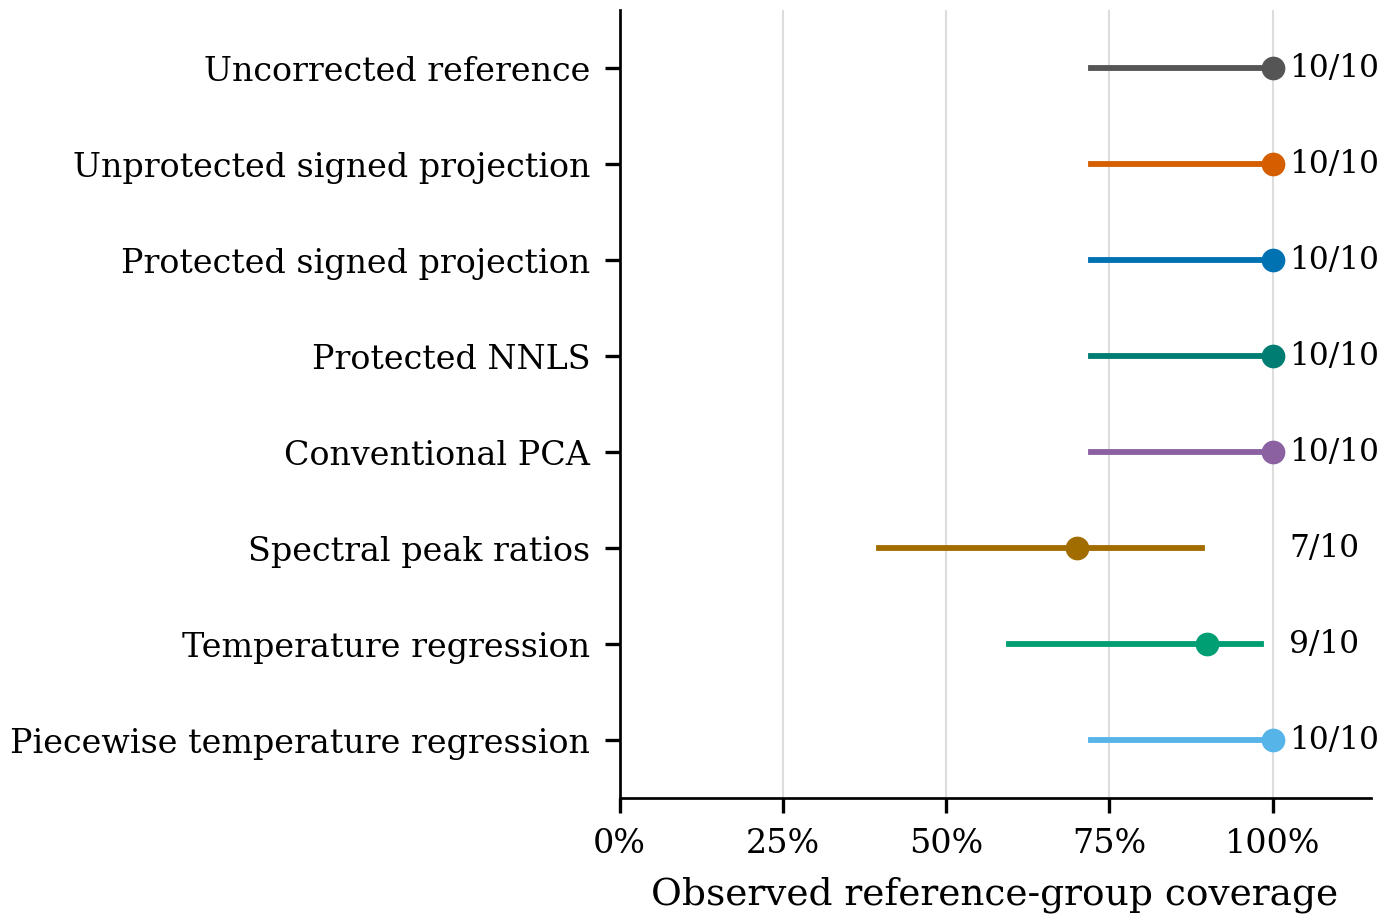

Fig. 1. Reference-group coverage for OpenLab-2024; points show observed proportions and bars show Wilson 95% intervals.

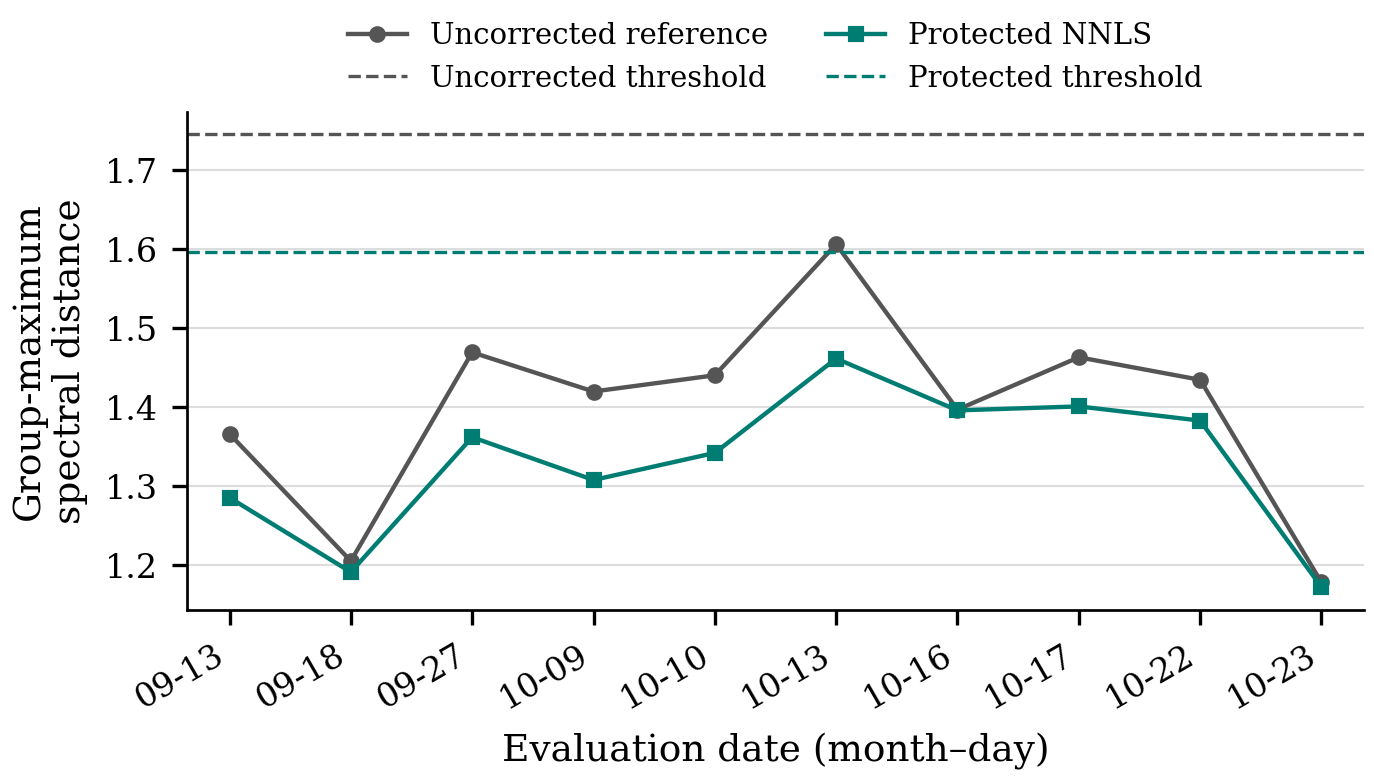

Fig. 2. Paired uncorrected and protected-NNLS group scores for OpenLab-2024.

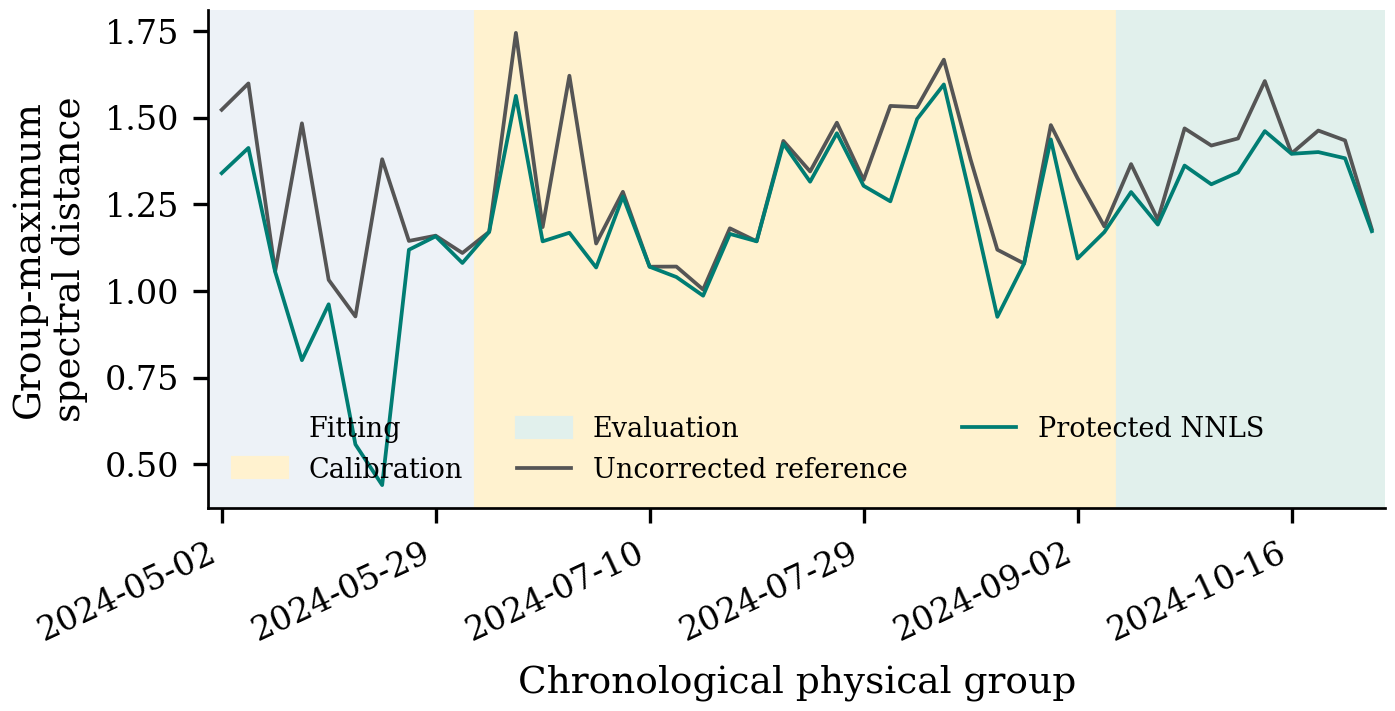

Fig. 3. Chronological fitting, calibration and evaluation groups for OpenLab-2024.

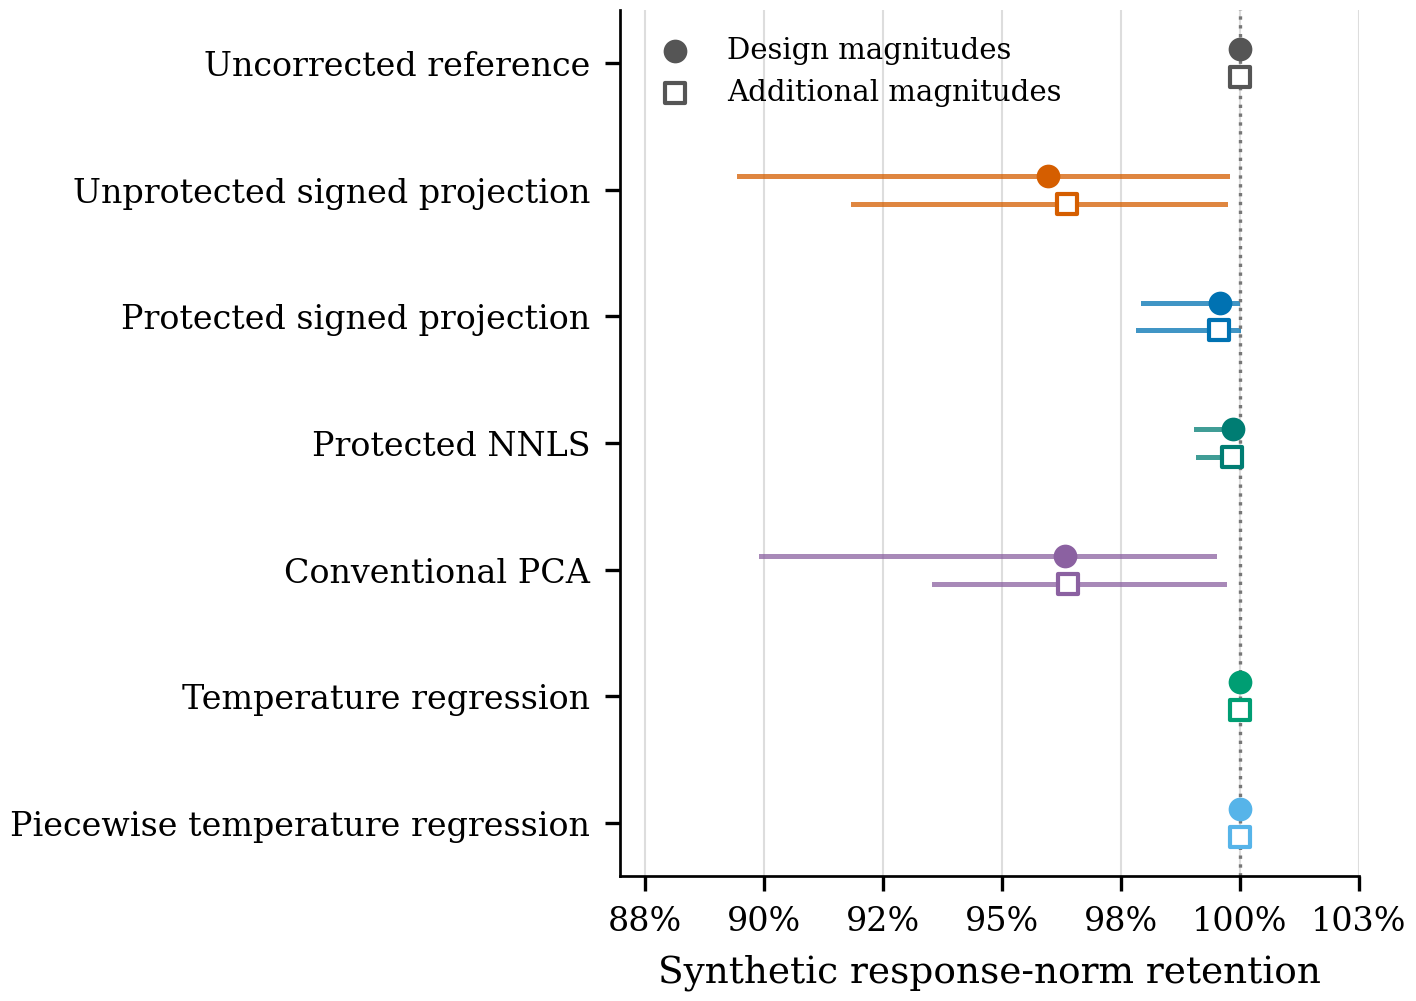

Fig. 4. Controlled spectral-shift retention for OpenLab-2024; markers show medians and bars show full ranges.

Table 3. Reference-state evaluation for OpenLab-2024.

| Method | Covered/reference groups | Coverage (%) | Wilson 95% bounds (%) | Alert groups |
| --- | --- | --- | --- | --- |
| Uncorrected reference | 10/10 | 100 | 72.2–100.0 | 0 |
| Unprotected signed projection | 10/10 | 100 | 72.2–100.0 | 0 |
| Protected signed projection | 10/10 | 100 | 72.2–100.0 | 0 |
| Protected NNLS | 10/10 | 100 | 72.2–100.0 | 0 |
| Conventional PCA | 10/10 | 100 | 72.2–100.0 | 0 |
| Spectral peak ratios | 7/10 | 70 | 39.7–89.2 | 3 |
| Temperature regression | 9/10 | 90 | 59.6–98.2 | 1 |
| Piecewise temperature regression | 10/10 | 100 | 72.2–100.0 | 0 |

Each method uses its own frozen calibration threshold. Calibration-group counts and exact thresholds remain in the source CSV. Wilson bounds are descriptive 95% intervals; independence and exchangeability are not established. Abstain denotes an unsupported finite nominal threshold, not perfect coverage. The frozen calibration includes 27 acquisitions on 5 dates during the documented non-destructive temporary-prop intervention (22 July–2 August 2024; data article section 4.6). Undamaged reference phase does not mean unchanged boundary conditions. These records and thresholds are retained.


Table 4. Paired evaluation relative to the uncorrected reference for OpenLab-2024.

| Method | Paired groups | Median score reduction (%) | Exploratory 95% bounds (%) |
| --- | --- | --- | --- |
| Unprotected signed projection | 10 | 16.8 | 9.29–21.34 |
| Protected signed projection | 10 | 15.8 | 7.66–19.41 |
| Protected NNLS | 10 | 5.07 | 1.15–7.30 |
| Conventional PCA | 10 | 17.5 | 9.95–21.63 |
| Temperature regression | 10 | -2.83 | -11.43–0.20 |
| Piecewise temperature regression | 10 | 0.877 | -5.75–3.20 |

The score-reduction bounds are exploratory paired percentile-bootstrap bounds conditional on the frozen models and thresholds; they exclude fitting and calibration uncertainty. Only the common spectral feature space is included. Score contraction alone does not establish improved monitoring.


Table 7. Reference-state evaluation for Z24 progressive-damage tests.

| Method | Covered/reference groups | Coverage (%) | Wilson 95% bounds (%) | Alert groups |
| --- | --- | --- | --- | --- |
| Uncorrected reference | Abstain | Not estimable | Not estimable | Not estimable |
| Unprotected signed projection | Abstain | Not estimable | Not estimable | Not estimable |
| Protected signed projection | Abstain | Not estimable | Not estimable | Not estimable |
| Protected NNLS | Abstain | Not estimable | Not estimable | Not estimable |
| Conventional PCA | Abstain | Not estimable | Not estimable | Not estimable |
| Spectral peak ratios | Abstain | Not estimable | Not estimable | Not estimable |

Each method uses its own frozen calibration threshold. Calibration-group counts and exact thresholds remain in the source CSV. Wilson bounds are descriptive 95% intervals; independence and exchangeability are not established. Abstain denotes an unsupported finite nominal threshold, not perfect coverage.


Table 8. Score contraction on the sole held-out Z24 reference scenario 08.

| Method | Paired groups | Median score reduction (%) | Exploratory 95% bounds (%) |
| --- | --- | --- | --- |
| Unprotected signed projection | 1 | 54.7 | Not estimated |
| Protected signed projection | 1 | 56.3 | Not estimated |
| Protected NNLS | 1 | 7.11 | Not estimated |
| Conventional PCA | 1 | 53.8 | Not estimated |

This comparison uses one paired reference group (scenario 08), not all 15 evaluation states. No bootstrap interval is estimated for this single group. Score contraction alone does not establish damage sensitivity or improved monitoring.


In [19]:
print('PUBLICATION PREVIEW:',RUN/'publication/index.html')
if CONFIG.get('show_publication_preview',True):
    try:
        from IPython.display import display,Markdown,Image
        display(Markdown('### Publication preview — current run'))
        figures=[item for item in publication_manifest.get('items',[]) if item['kind']=='Figure']
        for item in figures[:4]:
            png=next(name for name in item['files'] if name.endswith('.png'))
            display(Image(filename=str(RUN/'publication'/png),width=680))
            display(Markdown(item['caption']))
        for item in publication_manifest.get('items',[]):
            if item['kind']=='Table' and item['stem'].endswith(('reference_coverage','paired_score_reductions')):
                display(Markdown((RUN/'publication/tables'/(item['stem']+'.md')).read_text()))
    except ImportError:
        print('Open publication/index.html to inspect the figure and table preview.')


### 9. Reading the outputs and revising the paper

Start with `reviewer_request_status.csv` and `publication/index.html`. Report the actual group counts, thresholds and missing methods. Score reduction does not replace damage sensitivity. An infinite nominal threshold means abstention. Review the frequency's physical interpretation before using modal terminology.

Cite every retained figure and table in manuscript order and use the accompanying concise captions. The supplied previous run is recorded in `previous_run_audit.json`; its outcomes remain distinguishable from archived paper results and the freshly computed outputs of this full V5 execution.

Sources: [paper repository](https://github.com/AbdellahRiyahi/physics-protected-spectral-normalization), [KU Leuven Z24 benchmark](https://bwk.kuleuven.be/bwm/z24), [SciPy CPSD](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.csd.html), [SciPy NNLS](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.nnls.html), and [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html). Raw Z24 data are excluded from the exported package.
